# An Empirical Analysis of AI Terminology in Scientific News: analysis notebook




## 1 Data loading and cleaning

### 1.1 Load the five sources

The five institutional CSV files are combined into one `articles` table; publication dates in different formats are normalized to `YYYY-MM-DD`.


In [1]:
# pip install sentence-transformers

In [2]:

import json
import math
import os
import re
import textwrap
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import spearmanr

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

from sklearn.cluster import KMeans
from sklearn.decomposition import NMF, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize

try:
    import matplotlib.colors as mcolors
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    PLOTS_AVAILABLE = True
except ImportError:
    PLOTS_AVAILABLE = False
    print("matplotlib is not installed in this kernel; table outputs will still run, and plots will be skipped.")

try:
    from IPython.display import display
except ImportError:
    display = print

try:
    from sentence_transformers import SentenceTransformer
except ImportError:
    SentenceTransformer = None   # the embedding cells fall back or raise a clear error

DATA_DIR = Path.cwd() / "Data"

school_files = {
    "MIT": DATA_DIR / "MIT Articles.csv",
    "Stanford": DATA_DIR / "Stanford Articles.csv",
    "JHU": DATA_DIR / "JHU Articles.csv",
    "CMU": DATA_DIR / "CMU Articles.csv",
    "Cornell": DATA_DIR / "Cornell Articles.csv",
}

missing_files = [str(path) for path in school_files.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"Missing data files: {missing_files}")

article_frames = []
load_summary_rows = []

for institution, file_path in school_files.items():
    frame = pd.read_csv(file_path)
    frame.insert(0, "Institution", institution)
    frame.insert(1, "Source File", file_path.name)

    # Preserve the original date text, then normalize Published Date so later cells can parse all schools consistently.
    frame["Published Date Raw"] = frame["Published Date"]
    parsed_dates = pd.to_datetime(frame["Published Date Raw"], errors="coerce", utc=True, format="mixed")
    normalized_dates = parsed_dates.dt.tz_convert(None).dt.strftime("%Y-%m-%d")
    frame["Published Date"] = normalized_dates.where(parsed_dates.notna(), frame["Published Date Raw"])

    article_frames.append(frame)
    body_words = frame["Article Body"].fillna("").astype(str).str.split().str.len()
    load_summary_rows.append({
        "Institution": institution,
        "number": len(frame),
        "valid_dates": int(parsed_dates.notna().sum()),
        "start_date": parsed_dates.min().date() if parsed_dates.notna().any() else pd.NaT,
        "end_date": parsed_dates.max().date() if parsed_dates.notna().any() else pd.NaT,
        "valid_body": int(frame["Article Body"].notna().sum()),
        "median_body_words": int(body_words.median()),
        "mean_body_words": round(body_words.mean(), 1),
    })

articles = pd.concat(article_frames, ignore_index=True, sort=False)
load_summary = pd.DataFrame(load_summary_rows)

front_cols = [
    "Institution", "Source File", "Published Date", "Published Date Raw", "Author", "Source",
    "Article Header", "Sub_Headings", "Article Body", "Tags", "Topics", "Url"
]
ordered_cols = [col for col in front_cols if col in articles.columns] + [
    col for col in articles.columns if col not in front_cols
]
articles = articles[ordered_cols]

print(f"Loaded {len(school_files)} schools from: {DATA_DIR.name}/")
print(f"Combined data shape: {articles.shape[0]} rows x {articles.shape[1]} columns")
display(load_summary)
display(articles.head())

Loaded 5 schools from: Data/
Combined data shape: 2232 rows x 31 columns


,Institution,number,valid_dates,start_date,end_date,valid_body,median_body_words,mean_body_words
0,MIT,1498,1498,2003-11-05,2026-06-26,1498,962,892.5
1,Stanford,231,231,2016-06-20,2026-07-09,231,1005,1074.9
2,JHU,130,130,2014-03-10,2026-07-09,130,712,830.0
3,CMU,283,273,2021-10-12,2026-07-09,283,612,715.2
4,Cornell,90,90,2025-04-28,2026-07-09,90,632,588.2


,Institution,Source File,Published Date,Published Date Raw,Author,Source,Article Header,Sub_Headings,Article Body,Tags,...,Body Block Count,Body Character Count,Listing Author,Listing Type,Listing Keywords,Listing Feeds,Official CMU Domain,Scrape Status,Debug HTML,Debug Report
0,MIT,MIT Articles.csv,2026-06-26,"June 26, 2026",Benjamin Daniel,"School of Humanities, Arts, and Social Sciences",David Autor named head of the Department of Ec...,"A faculty member since 1999, Autor is a leadin...","['David Autor, the Daniel (1972) and Gail Rubi...",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,MIT,MIT Articles.csv,2026-06-26,"June 26, 2026",Alex Shipps,MIT CSAIL,LLMs help robots understand vague instructions...,To help robots do chores in places like homes...,['Imagine working at a warehouse or office som...,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,MIT,MIT Articles.csv,2026-06-25,"June 25, 2026",NaN,NaN,MIT in the media: Exploring how curiosity-driv...,“Scientific American” showcases the history an...,"['Over the past 80 years, America’s bold, sust...",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,MIT,MIT Articles.csv,2026-06-25,"June 25, 2026",Adam Zewe,MIT News,Improving the speed and energy-efficiency of A...,"A new system, known as Murakkab, optimizes the...",['Agentic workflows are artificial intelligenc...,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,MIT,MIT Articles.csv,2026-06-23,"June 23, 2026",Benjamin Daniel,"School of Humanities, Arts, and Social Sciences",Exploring the societal impacts of AI,"During the AI and Society Forum, leading MIT r...","['At the recent AI and Society Forum at MIT, e...",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.2 Cleaning

Conservative cleaning in three steps: CMU records whose visible date field contains the template string `$dateFormat` receive the parseable archive-listing date; extremely short extracted bodies (fewer than 50 words) are inspected manually; and the three flagged records are adjudicated one by one (one removed, one retained, one corrected from the original page). 


In [3]:
# CMU invalid-date repair only.
# Decision: repair CMU rows whose Published Date failed to parse (e.g. "$dateFormat")
# using the valid Listing Published Date. No rows are dropped in this cell.

articles_before_cmu_date_repair = articles.copy()

cmu_mask = articles["Institution"] == "CMU"

# A row needs repair if its normalized Published Date still cannot be parsed.
published_parsed = pd.to_datetime(articles["Published Date"], errors="coerce", format="mixed")
needs_repair = cmu_mask & published_parsed.isna()

print(f"CMU rows total: {int(cmu_mask.sum())}")
print(f"CMU rows with unparseable Published Date: {int(needs_repair.sum())}")

if needs_repair.any():
    # Show what the broken values look like before touching them.
    display(
        articles.loc[needs_repair, ["Institution", "Published Date", "Published Date Raw",
                                    "Listing Published Date", "Article Header"]]
    )

    # Parse the listing date as the repair source.
    listing_parsed = pd.to_datetime(
        articles.loc[needs_repair, "Listing Published Date"],
        errors="coerce", format="mixed",
    )

    repairable = needs_repair.copy()
    repairable.loc[needs_repair] = listing_parsed.notna().values

    # Apply the repair and record provenance.
    articles.loc[repairable, "Published Date"] = (
        pd.to_datetime(articles.loc[repairable, "Listing Published Date"],
                       errors="coerce", format="mixed")
        .dt.strftime("%Y-%m-%d")
    )
    if "Published Date Repaired From Listing" not in articles.columns:
        articles["Published Date Repaired From Listing"] = False
    articles.loc[repairable, "Published Date Repaired From Listing"] = True

    unrepairable = needs_repair & ~repairable
    print(f"Repaired using Listing Published Date: {int(repairable.sum())}")
    print(f"Still unparseable (listing date also invalid): {int(unrepairable.sum())}")

    display(
        articles.loc[repairable, ["Institution", "Published Date", "Published Date Raw",
                                  "Listing Published Date", "Article Header"]]
    )
else:
    print("No CMU date repair needed.")

# Verification: after repair, every CMU row should either have a parseable date
# or be explicitly known as unrepairable.
cmu_after = pd.to_datetime(articles.loc[cmu_mask, "Published Date"], errors="coerce", format="mixed")
print(f"CMU parseable dates after repair: {int(cmu_after.notna().sum())} / {int(cmu_mask.sum())}")

CMU rows total: 283
CMU rows with unparseable Published Date: 10


,Institution,Published Date,Published Date Raw,Listing Published Date,Article Header
1862,CMU,$dateFormat,$dateFormat,"June 25, 2026",CMU Team Rises to Amazon Nova AI Challenge
1872,CMU,$dateFormat,$dateFormat,"May 20, 2026",Electrical and Computer Engineering
1890,CMU,$dateFormat,$dateFormat,"March 17, 2026",AI4BIO Selects Inaugural Projects for Biomedic...
1908,CMU,$dateFormat,$dateFormat,"February 2, 2026",Kang Receives SIGSOFT Early Career Researcher ...
1913,CMU,$dateFormat,$dateFormat,"December 5, 2025",Pope Invites Waibel to Vatican To Advise on AI
1921,CMU,$dateFormat,$dateFormat,"October 29, 2025",Making AI Approachable
1952,CMU,$dateFormat,$dateFormat,"July 28, 2025",AI-SDM Managing Director Norm Gottron Embraces...
1985,CMU,$dateFormat,$dateFormat,"April 16, 2025",Diab Elected to CRA Board
1986,CMU,$dateFormat,$dateFormat,"April 15, 2025",Students From LTI Compete in the Amazon Nova A...
2006,CMU,$dateFormat,$dateFormat,"January 28, 2025",2024-2025 K&L Gates Presidential Fellowship Re...


Repaired using Listing Published Date: 10
Still unparseable (listing date also invalid): 0


,Institution,Published Date,Published Date Raw,Listing Published Date,Article Header
1862,CMU,2026-06-25,$dateFormat,"June 25, 2026",CMU Team Rises to Amazon Nova AI Challenge
1872,CMU,2026-05-20,$dateFormat,"May 20, 2026",Electrical and Computer Engineering
1890,CMU,2026-03-17,$dateFormat,"March 17, 2026",AI4BIO Selects Inaugural Projects for Biomedic...
1908,CMU,2026-02-02,$dateFormat,"February 2, 2026",Kang Receives SIGSOFT Early Career Researcher ...
1913,CMU,2025-12-05,$dateFormat,"December 5, 2025",Pope Invites Waibel to Vatican To Advise on AI
1921,CMU,2025-10-29,$dateFormat,"October 29, 2025",Making AI Approachable
1952,CMU,2025-07-28,$dateFormat,"July 28, 2025",AI-SDM Managing Director Norm Gottron Embraces...
1985,CMU,2025-04-16,$dateFormat,"April 16, 2025",Diab Elected to CRA Board
1986,CMU,2025-04-15,$dateFormat,"April 15, 2025",Students From LTI Compete in the Amazon Nova A...
2006,CMU,2025-01-28,$dateFormat,"January 28, 2025",2024-2025 K&L Gates Presidential Fellowship Re...


CMU parseable dates after repair: 283 / 283


In [4]:
# Extreme short-body diagnosis and cleaning
# Decision: drop Article Body_words < 50 because manual inspection shows these are not usable article bodies.
articles_before_body_length_cleaning = articles.copy()
articles_before_body_length_cleaning["Article Body_words_check"] = (
    articles_before_body_length_cleaning["Article Body"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

extreme_short_threshold = 50
very_short_threshold = 20
extreme_short_rows = articles_before_body_length_cleaning.loc[
    articles_before_body_length_cleaning["Article Body_words_check"] < extreme_short_threshold
].copy()
very_short_rows = articles_before_body_length_cleaning.loc[
    articles_before_body_length_cleaning["Article Body_words_check"] < very_short_threshold
].copy()

extreme_short_summary = pd.DataFrame({
    "category": [
        "Rows before extreme-short cleaning",
        "Article Body_words 50-149",
        "Article Body_words < 50",
        "Article Body_words < 20",
        "Rows removed: Article Body_words < 50",
    ],
    "rows": [
        len(articles_before_body_length_cleaning),
        int(((articles_before_body_length_cleaning["Article Body_words_check"] >= 50) & (articles_before_body_length_cleaning["Article Body_words_check"] < 150)).sum()),
        len(extreme_short_rows),
        len(very_short_rows),
        len(extreme_short_rows),
    ],
})
extreme_short_summary["pct_of_corpus_before"] = (extreme_short_summary["rows"] / len(articles_before_body_length_cleaning) * 100).round(2)
display(extreme_short_summary)

print("Article Body_words < 50 by institution:")
display(
    extreme_short_rows.groupby("Institution")
    .size()
    .rename("rows")
    .reset_index()
    .sort_values("rows", ascending=False)
)

review_cols = ["Institution", "Published Date", "Article Header", "Article Body_words_check", "Source", "Url", "Article Body"]
print("All rows with Article Body_words < 50 for manual review:")
display(
    extreme_short_rows[review_cols]
    .sort_values(["Article Body_words_check", "Institution", "Published Date"])
    .reset_index(drop=False)
)

print("Full body text for Article Body_words < 20:")
for idx, row in very_short_rows.sort_values(["Article Body_words_check", "Institution", "Published Date"]).iterrows():
    print("-" * 80)
    print(f"index={idx} | {row['Institution']} | {row['Published Date']} | words={row['Article Body_words_check']}")
    print(f"Header: {row['Article Header']}")
    print(f"Body: {repr(row['Article Body'])}")

print("Full body text for Article Body_words 20-49:")
for idx, row in extreme_short_rows.loc[
    extreme_short_rows["Article Body_words_check"].between(20, 49)
].sort_values(["Article Body_words_check", "Institution", "Published Date"]).iterrows():
    print("-" * 80)
    print(f"index={idx} | {row['Institution']} | {row['Published Date']} | words={row['Article Body_words_check']}")
    print(f"Header: {row['Article Header']}")
    print(f"Body: {repr(row['Article Body'])}")

articles = articles_before_body_length_cleaning.loc[
    articles_before_body_length_cleaning["Article Body_words_check"] >= extreme_short_threshold
].drop(columns=["Article Body_words_check"]).copy()

body_length_cleaning_comparison = pd.DataFrame({
    "stage": ["After CMU cleaning", "After removing Article Body_words < 50"],
    "rows": [len(articles_before_body_length_cleaning), len(articles)],
})
body_length_cleaning_comparison["rows_removed_from_previous_stage"] = body_length_cleaning_comparison["rows"].shift(1).fillna(body_length_cleaning_comparison["rows"]) - body_length_cleaning_comparison["rows"]
display(body_length_cleaning_comparison)

print("Decision: remove Article Body_words < 50 as invalid/near-empty body extraction cases. Keep normal 50-149 word brief articles in the corpus.")

,category,rows,pct_of_corpus_before
0,Rows before extreme-short cleaning,2232,100.00
1,Article Body_words 50-149,62,2.78
2,Article Body_words < 50,3,0.13
3,Article Body_words < 20,2,0.09
4,Rows removed: Article Body_words < 50,3,0.13


Article Body_words < 50 by institution:


,Institution,rows
0,Cornell,1
1,MIT,1
2,Stanford,1


All rows with Article Body_words < 50 for manual review:


,index,Institution,Published Date,Article Header,Article Body_words_check,Source,Url,Article Body
0,2200,Cornell,2025-12-17,2025 Year in Review,9,Cornell Chronicle,https://news.cornell.edu/stories/2025/12/2025-...,"Cornell Chronicle 120 Maple Ave. Ithaca, NY 14..."
1,1524,Stanford,2025-08-25,AI model generates realistic synthetic X-rays ...,14,Stanford School of Medicine,https://news.stanford.edu/stories/2025/08/open...,"At Match Day celebration, students get a first..."
2,1492,MIT,2004-12-23,Here comes Santa Claus,38,NaN,https://news.mit.edu/2004/robosanta,"[""A pint-sized Santa Claus, with help from a s..."


Full body text for Article Body_words < 20:
--------------------------------------------------------------------------------
index=2200 | Cornell | 2025-12-17 | words=9
Header: 2025 Year in Review
Body: 'Cornell Chronicle 120 Maple Ave. Ithaca, NY 14850 cunews@cornell.edu'
--------------------------------------------------------------------------------
index=1524 | Stanford | 2025-08-25 | words=14
Header: AI model generates realistic synthetic X-rays from medical descriptions
Body: 'At Match Day celebration, students get a first look at their next chapter\n\nVideo'
Full body text for Article Body_words 20-49:
--------------------------------------------------------------------------------
index=1492 | MIT | 2004-12-23 | words=38
Header: Here comes Santa Claus
Body: '["A pint-sized Santa Claus, with help from a student-designed robot, deposits gifts down a chimney. The robot was one of four competing in the final project for Professor Harry Asada\'s Introduction to Robotics class.  Phot

,stage,rows,rows_removed_from_previous_stage
0,After CMU cleaning,2232,0.0
1,After removing Article Body_words < 50,2229,3.0


Decision: remove Article Body_words < 50 as invalid/near-empty body extraction cases. Keep normal 50-149 word brief articles in the corpus.


In [5]:
# Manual adjudication of the 3 flagged short-body articles (Article Body_words < 50).
# Reviewed each against its original page:
#   index=2200 (Cornell): body is footer-only extraction failure           -> remove
#   index=1492 (MIT 2004): genuine captioned photo news, content complete  -> retain
#   index=1524 (Stanford): body was misattributed sidebar text             -> correct from original page

# --- 1. Correct index=1524 with the actual on-page text (video post introduction) ---
repaired_body_1524 = (
    "When tools like DALL·E and Stable Diffusion began creating images from text, "
    "researchers asked: Could the same approach generate clinically accurate chest X-rays?"
)
articles_before_body_length_cleaning.loc[1524, "Article Body"] = repaired_body_1524
articles_before_body_length_cleaning.loc[1524, "Article Body_words_check"] = len(
    repaired_body_1524.split()
)

# --- 2. Remove index=2200; index=1492 is retained by taking no action on it ---
manual_drop_indices = [2200]

articles = (
    articles_before_body_length_cleaning
    .drop(index=manual_drop_indices)
    .drop(columns=["Article Body_words_check"])
    .copy()
)

# --- 3. Report the adjudication result ---
short_body_adjudication = pd.DataFrame({
    "original_index": [2200, 1492, 1524],
    "Institution": ["Cornell", "MIT", "Stanford"],
    "decision": ["removed", "retained", "corrected"],
    "reason": [
        "footer-only extraction failure",
        "genuine captioned photo news",
        "body misattributed sidebar text; replaced with actual page text",
    ],
})
display(short_body_adjudication)
print(f"Rows after manual short-body adjudication: {len(articles)}")

,original_index,Institution,decision,reason
0,2200,Cornell,removed,footer-only extraction failure
1,1492,MIT,retained,genuine captioned photo news
2,1524,Stanford,corrected,body misattributed sidebar text; replaced with...


Rows after manual short-body adjudication: 2231


In [6]:
# Post-cleaning corpus 
school_order = ["MIT", "Stanford", "JHU", "CMU", "Cornell"]

institution_status = (
    articles.groupby("Institution")
    .agg(
        number=("Article Header", "size"),
        valid_dates=("Published Date", lambda s: pd.to_datetime(s, errors="coerce", format="mixed").notna().sum()),
        valid_body=("Article Body", lambda s: s.notna().sum()),
        median_body_words=("Article Body", lambda s: int(s.fillna("").astype(str).str.split().str.len().median())),
    )
    .reindex(school_order)
    .reset_index()
)
print(f"Cleaned corpus total: {len(articles)} articles")
display(institution_status)

Cleaned corpus total: 2231 articles


,Institution,number,valid_dates,valid_body,median_body_words
0,MIT,1498,1498,1498,962
1,Stanford,231,231,231,1005
2,JHU,130,130,130,712
3,CMU,283,283,283,612
4,Cornell,89,89,89,639


### 1.3 Working data frame and figure style


In [7]:
# Basic setup and schema overview for the combined five-school corpus

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 120)

df = articles.copy()
df["published_date"] = pd.to_datetime(df["Published Date"], errors="coerce")
df["year"] = df["published_date"].dt.year
df["chatgpt_period_descriptive"] = np.where(
    df["published_date"] >= pd.Timestamp("2023-01-01"),
    "post_2023",
    "pre_2023",
)
df.loc[df["published_date"].isna(), "chatgpt_period_descriptive"] = "missing_date"

print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
print(f"Date range: {df['published_date'].min().date()} -> {df['published_date'].max().date()}")
print(f"Valid Published Date values: {df['published_date'].notna().sum()} / {len(df)}")
print(f"Institutions: {', '.join(sorted(df['Institution'].dropna().unique()))}")

schema_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(dropna=True),
})
display(schema_summary)

institution_summary = (
    df.groupby("Institution")
      .agg(
          rows=("Institution", "size"),
          valid_dates=("published_date", "count"),
          start_date=("published_date", "min"),
          end_date=("published_date", "max"),
          valid_body=("Article Body", lambda x: x.notna().sum()),
          unique_urls=("Url", "nunique"),
      )
      .reset_index()
)
institution_summary["share_of_corpus_pct"] = (institution_summary["rows"] / len(df) * 100).round(1)
institution_summary["start_date"] = institution_summary["start_date"].dt.date
institution_summary["end_date"] = institution_summary["end_date"].dt.date
display(institution_summary.sort_values("rows", ascending=False))

Rows: 2231
Columns: 35
Date range: 2003-11-05 -> 2026-07-09
Valid Published Date values: 2231 / 2231
Institutions: CMU, Cornell, JHU, MIT, Stanford


,dtype,non_null,missing,missing_pct,unique
Institution,object,2231,0,0.00,5
Source File,object,2231,0,0.00,5
Published Date,object,2231,0,0.00,1411
Published Date Raw,object,2231,0,0.00,1740
Author,object,1945,286,12.82,481
Source,object,2138,93,4.17,154
Article Header,object,2231,0,0.00,2230
Sub_Headings,object,2042,189,8.47,2002
Article Body,object,2231,0,0.00,2231
Tags,object,219,2012,90.18,157


,Institution,rows,valid_dates,start_date,end_date,valid_body,unique_urls,share_of_corpus_pct
3,MIT,1498,1498,2003-11-05,2026-06-26,1498,1498,67.1
0,CMU,283,283,2021-10-12,2026-07-09,283,283,12.7
4,Stanford,231,231,2016-06-20,2026-07-09,231,231,10.4
2,JHU,130,130,2014-03-10,2026-07-09,130,130,5.8
1,Cornell,89,89,2025-04-28,2026-07-09,89,89,4.0


In [8]:
if not PLOTS_AVAILABLE:
    raise ImportError("matplotlib is required for the figures in this notebook.")

TEXTWIDTH_IN = 5.93          # target text width = 426.8 pt

FIGURE_RC = {
    "figure.dpi": 150,           # inline display only
    "savefig.dpi": 300,          # only affects the auto-rasterized colorbar strip inside the PDFs
    "font.size": 9,
    "figure.titlesize": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "lines.linewidth": 1.4,
    "lines.markersize": 4.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,          # embed TrueType outlines: text in the PDFs stays real, selectable text
    "ps.fonttype": 42,
}
plt.style.use("default")
plt.rcParams.update(FIGURE_RC)

FIG_DIR = Path(os.environ.get("FIG_DIR") or Path.cwd() / "figures")
SAVE_FIGURES = True   
print(f"Figures are written to: {FIG_DIR.name}/")

HEATMAP_TEXT_DARK = "#1F2933"
HEATMAP_TEXT_LIGHT = "#FFFFFF"

def wrap_text(text, width=68):
    """Wrap a title or label so that it fits the printed width (roughly 12 characters per inch at 9-10 pt)."""
    return "\n".join(textwrap.fill(line, width=width, break_long_words=False) for line in str(text).split("\n"))

def relative_luminance(color):
    """WCAG relative luminance (0-1) of an RGB(A) colour (the formula seaborn uses for annotations)."""
    rgb = np.asarray(mcolors.to_rgb(color), dtype=float)
    lin = np.where(rgb <= 0.03928, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    return float(lin @ np.array([0.2126, 0.7152, 0.0722]))

def heatmap_text_color(mappable, value, threshold=0.223):
    """Dark text on light cells, white text on dark cells, judged on the colour actually drawn.
    0.223 is the relative luminance at which white and the dark text reach the same WCAG contrast (3.9:1),
    which maximises the worst-case contrast; seaborn's 0.408 would leave mid-tone cells at only 2.3:1."""
    return HEATMAP_TEXT_DARK if relative_luminance(mappable.cmap(mappable.norm(value))) > threshold else HEATMAP_TEXT_LIGHT

def draw_heatmap_cells(ax, matrix, cmap="YlGnBu", value_fmt=".1f", fontsize=7.5):
    """Vector heatmap with imshow geometry: cell (i, j) is centred on (x=j, y=i), row 0 at the top.
    Returns the QuadMesh (a ScalarMappable) for plt.colorbar."""
    values = np.ma.masked_invalid(np.asarray(matrix.values, dtype=float))
    n_rows, n_cols = values.shape
    mesh = ax.pcolormesh(
        np.arange(n_cols + 1) - 0.5, np.arange(n_rows + 1) - 0.5, values,
        cmap=cmap, shading="flat",
        edgecolors="face", linewidth=0.4,   # face-coloured hairline hides anti-aliasing seams in PDF viewers
    )
    ax.set_xlim(-0.5, n_cols - 0.5)
    ax.set_ylim(n_rows - 0.5, -0.5)          # same extent and orientation as imshow(origin="upper")
    for i in range(n_rows):
        for j in range(n_cols):
            val = matrix.iloc[i, j]
            if pd.notna(val):
                ax.text(j, i, format(val, value_fmt), ha="center", va="center",
                        fontsize=fontsize, color=heatmap_text_color(mesh, float(val)))
    return mesh

def save_fig(fig, name):
    """Write FIG_DIR/<name>.pdf, tightly cropped, at the figure's physical size.
    Axis labels are passed as extra artists because bbox_inches="tight" otherwise ignores their width
    and clips labels that are wider than their axes."""
    if not SAVE_FIGURES:
        return None
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    path = FIG_DIR / f"{name}.pdf"

    labels = [lab for ax in fig.axes for lab in (ax.xaxis.label, ax.yaxis.label) if lab.get_text()]
    extra = list(fig.get_default_bbox_extra_artists()) + labels
    fig.savefig(path, format="pdf", bbox_inches="tight", pad_inches=0.04, bbox_extra_artists=extra)
    print(f"Saved {path.parent.name}/{path.name}")
    return path

COLORS = {
    "blue": "#2F5F98",
    "teal": "#2A9D8F",
    "orange": "#E6862E",
    "red": "#C44E52",
    "green": "#4C956C",
    "purple": "#7B5EA7",
    "gray": "#6C757D",
    "light_gray": "#E9ECEF",
}

def wrap_labels(labels, width=22):
    return ["\n".join(textwrap.wrap(str(label), width=width, break_long_words=False)) for label in labels]

def annotate_barh(ax, fmt="{:.1f}", pad=0.3):
    xmax = ax.get_xlim()[1]
    for patch in ax.patches:
        width = patch.get_width()
        if pd.notna(width):
            ax.text(
                width + xmax * 0.01 + pad,
                patch.get_y() + patch.get_height() / 2,
                fmt.format(width),
                va="center",
                ha="left",
                fontsize=7.5,
            )

def draw_heatmap(matrix, title, cbar_label, cmap="YlGnBu", value_fmt=".1f", figsize=(TEXTWIDTH_IN, 2.6), save_as=None):
    matrix = matrix.copy()
    fig, ax = plt.subplots(figsize=figsize)
    im = draw_heatmap_cells(ax, matrix, cmap=cmap, value_fmt=value_fmt, fontsize=7.5)
    if title:
        ax.set_title(wrap_text(title, 68), pad=8)
    ax.set_xticks(range(matrix.shape[1]))
    ax.set_xticklabels(wrap_labels(matrix.columns, 16), rotation=35, ha="right")
    ax.set_yticks(range(matrix.shape[0]))
    ax.set_yticklabels(matrix.index)
    cbar = plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    cbar.set_label(wrap_text(cbar_label, 22))
    plt.tight_layout()
    if save_as:
        save_fig(fig, save_as)
    plt.show()

def draw_topic_heatmap(matrix, title, cbar_label, cmap="YlGnBu", value_fmt=".1f", figsize=(TEXTWIDTH_IN, 3.6), save_as=None, xrotation=35):
    matrix = matrix.copy()
    fig, ax = plt.subplots(figsize=figsize)
    im = draw_heatmap_cells(ax, matrix, cmap=cmap, value_fmt=value_fmt, fontsize=7.5)
    if title:
        ax.set_title(wrap_text(title, 68), pad=8)
    ax.set_xticks(range(matrix.shape[1]))
    ax.set_xticklabels(wrap_labels(matrix.columns, 16), rotation=xrotation, ha="right" if xrotation else "center")
    ax.set_yticks(range(matrix.shape[0]))
    ax.set_yticklabels(wrap_labels(matrix.index, 26))
    cbar = plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    cbar.set_label(wrap_text(cbar_label, 22))
    plt.tight_layout()
    if save_as:
        save_fig(fig, save_as)
    plt.show()

Figures are written to: figures/


### 1.4 Descriptive coverage




,article_count
year,
2003,1
2004,5
2005,10
2006,16
2007,16
2008,12
2009,10
2010,8
2011,9


Institution,CMU,Cornell,JHU,MIT,Stanford
year,,,,,
2003,0,0,0,1,0
2004,0,0,0,5,0
2005,0,0,0,10,0
2006,0,0,0,16,0
2007,0,0,0,16,0
2008,0,0,0,12,0
2009,0,0,0,10,0
2010,0,0,0,8,0
2011,0,0,0,9,0


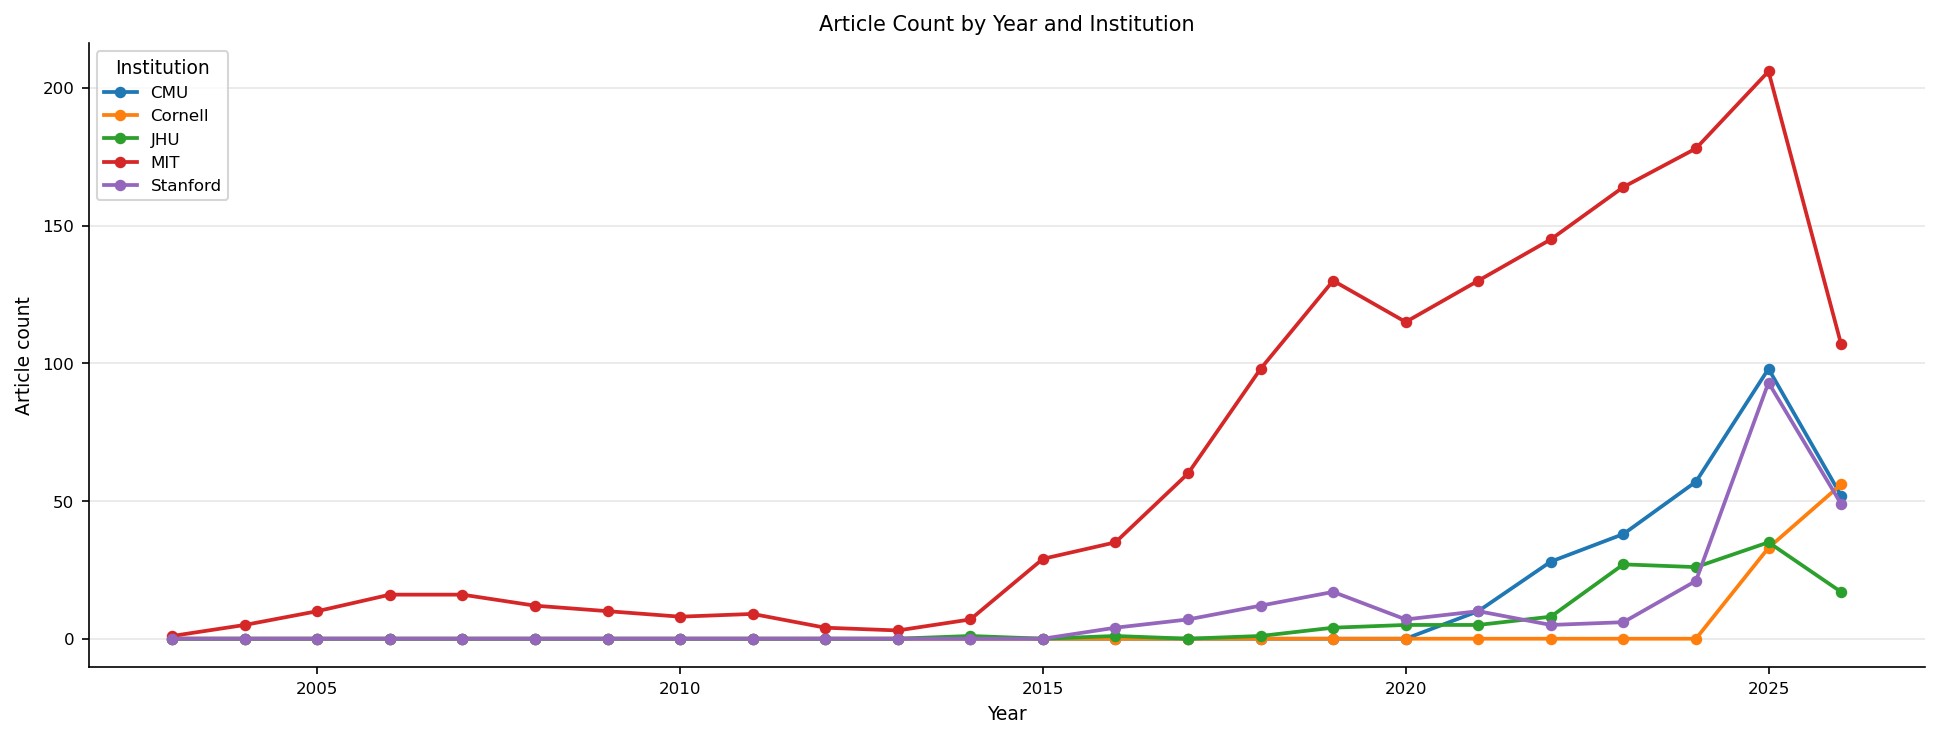

Institution-years with fewer than 10 articles should be interpreted cautiously:


,year,Institution,article_count
0,2003,MIT,1.0
1,2004,MIT,5.0
7,2010,MIT,8.0
8,2011,MIT,9.0
9,2012,MIT,4.0
10,2013,MIT,3.0
11,2014,JHU,1.0
12,2014,MIT,7.0
14,2016,JHU,1.0
16,2016,Stanford,4.0


In [9]:
# Number of articles by year and institution
valid_year_df = df.dropna(subset=["year"]).copy()
valid_year_df["year"] = valid_year_df["year"].astype(int)

year_counts = valid_year_df.groupby("year").size().rename("article_count")
display(year_counts.to_frame())

year_school_counts = (
    valid_year_df.pivot_table(index="year", columns="Institution", values="Article Header", aggfunc="count", fill_value=0)
    .astype(int)
    .sort_index()
)
display(year_school_counts)

if PLOTS_AVAILABLE:
    ax = year_school_counts.plot(figsize=(13, 5), marker="o", linewidth=1.8)
    ax.set_title("Article Count by Year and Institution")
    ax.set_xlabel("Year")
    ax.set_ylabel("Article count")
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

low_n_years = year_school_counts.where(year_school_counts > 0).stack().rename("article_count").reset_index()
low_n_years = low_n_years.loc[low_n_years["article_count"] < 10]
print("Institution-years with fewer than 10 articles should be interpreted cautiously:")
display(low_n_years.sort_values(["year", "Institution"]))

year,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Institution,,,,,,,,,,,,,,,,,,,,,,,,
CMU,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,10,28,38,57,98,52
Cornell,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,33,56
JHU,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,4,5,5,8,27,26,35,17
MIT,1,5,10,16,16,12,10,8,9,4,3,7,29,35,60,98,130,115,130,145,164,178,206,107
Stanford,0,0,0,0,0,0,0,0,0,0,0,0,0,4,7,12,17,7,10,5,6,21,93,49


Institution-years with n >= 10 are more reliable for institution-level yearly comparison:


year,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Institution,,,,,,,,,,,,,,,,,,,,,,,,
CMU,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,usable,usable,usable,usable,usable,usable
Cornell,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,usable,usable
JHU,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,usable,usable,usable,usable
MIT,low_n,low_n,usable,usable,usable,usable,usable,low_n,low_n,low_n,low_n,low_n,usable,usable,usable,usable,usable,usable,usable,usable,usable,usable,usable,usable
Stanford,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,low_n,usable,usable,low_n,usable,low_n,low_n,usable,usable,usable


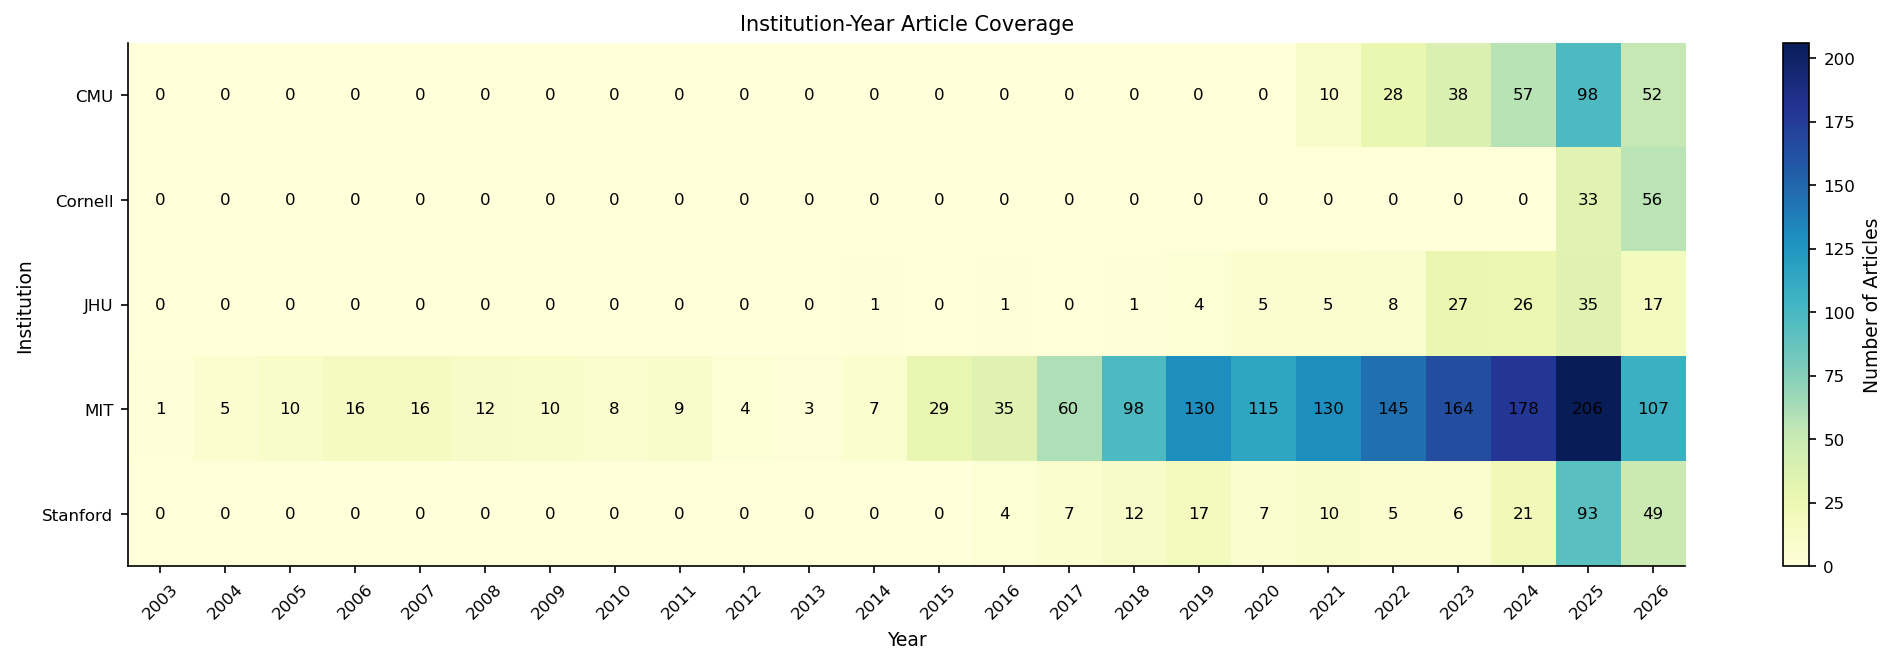

In [10]:
# Institution-year coverage check 
institution_year_counts = (
    df.dropna(subset=["year"])
      .assign(year=lambda x: x["year"].astype(int))
      .pivot_table(index="Institution", columns="year", values="Article Header", aggfunc="count", fill_value=0)
      .astype(int)
      .sort_index(axis=1)
)
display(institution_year_counts)

usable_institution_years = institution_year_counts >= 10
print("Institution-years with n >= 10 are more reliable for institution-level yearly comparison:")
display(usable_institution_years.replace({True: "usable", False: "low_n"}))

if PLOTS_AVAILABLE:
    plt.figure(figsize=(14, 4.5))
    plt.imshow(institution_year_counts, aspect="auto", cmap="YlGnBu")
    plt.colorbar(label="Number of Articles")
    plt.title("Institution-Year Article Coverage")
    plt.xlabel("Year")
    plt.ylabel("Institution")
    plt.xticks(ticks=range(len(institution_year_counts.columns)), labels=institution_year_counts.columns, rotation=45)
    plt.yticks(ticks=range(len(institution_year_counts.index)), labels=institution_year_counts.index)
    for y, institution in enumerate(institution_year_counts.index):
        for x, year in enumerate(institution_year_counts.columns):
            value = institution_year_counts.loc[institution, year]
            plt.text(x, y, str(value), ha="center", va="center", fontsize=8)
    plt.tight_layout()
    plt.show()

In [11]:
# Missing values, duplicates, and ID/url checks
missing_summary = df.isna().sum().rename("missing_count").to_frame()
missing_summary["missing_pct"] = (missing_summary["missing_count"] / len(df) * 100).round(2)
display(missing_summary.sort_values("missing_count", ascending=False))

key_cols = [col for col in ["Published Date", "Author", "Source", "Article Header", "Sub_Headings", "Article Body", "Tags", "Topics", "Url"] if col in df.columns]
missing_by_school = (
    df.groupby("Institution")[key_cols]
      .apply(lambda x: (x.isna().mean() * 100).round(1))
      .reset_index()
)
display(missing_by_school)

print(f"Duplicate full rows: {df.duplicated().sum()}")
print(f"Duplicate URLs: {df['Url'].duplicated().sum()}")
print(f"Duplicate URLs within the same institution: {df.duplicated(subset=['Institution', 'Url']).sum()}")
print(f"Duplicate article headers: {df['Article Header'].duplicated().sum()}")
print(f"Rows with unparsed dates: {df['published_date'].isna().sum()}")
print(f"Rows with missing/empty body: {(df['Article Body'].isna() | (df['Article Body'].fillna('').astype(str).str.strip() == '')).sum()}")

duplicate_url_rows = df[df["Url"].duplicated(keep=False)].sort_values(["Url", "Institution"])
display(duplicate_url_rows[["Institution", "Published Date", "Article Header", "Url"]].head(30))

unparsed_dates = df.loc[df["published_date"].isna(), ["Institution", "Published Date Raw", "Article Header", "Url"]]
display(unparsed_dates.head(30))

,missing_count,missing_pct
Listing Summary,2231,100.00
Topics,2230,99.96
Debug Report,2222,99.60
Debug HTML,2222,99.60
Error,2222,99.60
Tags,2012,90.18
Listing Type,1986,89.02
Listing Author,1956,87.67
Listing Feeds,1948,87.32
Listing Keywords,1948,87.32


,Institution,Published Date,Author,Source,Article Header,Sub_Headings,Article Body,Tags,Topics,Url
0,CMU,0.0,1.8,0.0,0.0,47.0,0.0,100.0,99.6,0.0
1,Cornell,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0
2,JHU,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0
3,MIT,0.0,11.5,6.2,0.0,3.7,0.0,100.0,100.0,0.0
4,Stanford,0.0,47.2,0.0,0.0,0.0,0.0,100.0,100.0,0.0


Duplicate full rows: 0
Duplicate URLs: 0
Duplicate URLs within the same institution: 0
Duplicate article headers: 1
Rows with unparsed dates: 0
Rows with missing/empty body: 0


,Institution,Published Date,Article Header,Url


,Institution,Published Date Raw,Article Header,Url


## 2 Measurement: text preparation, communicative-orientation cues, and AI terminology families

- The analysis text of an article is the headline, the sub-headings, and the body; word counts include tokens that begin with a letter and are the denominator of every rate per 1,000 words.
- Dictionary cues are matched case-insensitively with boundaries at non-alphanumeric characters; multi-word cues allow spaces, hyphens, slashes, apostrophes, and periods between words.
- Communicative orientations (`Data/Dictionary.json`, eight categories): strong phrases receive weight 3 and weak terms weight 1, giving the article score $S_{ik}=3n^{\mathrm{strong}}_{ik}+n^{\mathrm{weak}}_{ik}$ and the intensity $I_{ik}=1000\,S_{ik}/\mathrm{words}_i$. An orientation is *present* (prevalence) when an article contains at least one strong phrase or at least five weak terms. Internal variable names keep the prefix `frame_`; tables and figures label these outputs as communicative orientations.
- AI terminology families (`Data/AI terminology.json`, four families): prevalence is the presence of at least one cue, intensity the number of matches per 1,000 words; cues are unweighted.
- 2023 (calendar split: 2022 and earlier versus 2023 onward) is the descriptive pre/post period; the monthly models of Section 5 use December 2022.



In [12]:
if "df" not in globals():
    df = articles.copy()

analysis_df = df.copy()
analysis_df["article_id"] = analysis_df.index
analysis_df["published_date"] = pd.to_datetime(analysis_df.get("published_date", analysis_df["Published Date"]), errors="coerce")
analysis_df["year"] = analysis_df["published_date"].dt.year
analysis_df["analysis_period"] = np.select(
    [
        analysis_df["published_date"].isna(),
        analysis_df["published_date"] >= pd.Timestamp("2023-01-01"),
    ],
    ["missing_date", "post_2023"],
    default="pre_2023",
)

text_source_cols = [col for col in ["Article Header", "Sub_Headings", "Article Body"] if col in analysis_df.columns]

def clean_text_value(value):
    if pd.isna(value):
        return ""
    text = str(value)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

analysis_df["analysis_text"] = (
    analysis_df[text_source_cols]
    .fillna("")
    .astype(str)
    .agg(". ".join, axis=1)
    .map(clean_text_value)
)

analysis_df["analysis_text_lower"] = analysis_df["analysis_text"].str.lower()
analysis_df["analysis_word_count"] = analysis_df["analysis_text"].str.findall(r"\b[A-Za-z][A-Za-z0-9'\-]*\b").str.len()
analysis_df["analysis_word_count_nonzero"] = analysis_df["analysis_word_count"].clip(lower=1)

print(f"Analysis articles: {len(analysis_df):,}")
print(f"Text columns combined: {', '.join(text_source_cols)}")
print(f"Date range: {analysis_df['published_date'].min().date()} -> {analysis_df['published_date'].max().date()}")

display(
    analysis_df.groupby(["Institution", "analysis_period"])
    .agg(
        article_count=("article_id", "count"),
        median_words=("analysis_word_count", "median"),
        mean_words=("analysis_word_count", "mean"),
    )
    .round(1)
    .reset_index()
    .sort_values(["Institution", "analysis_period"])
)

def cue_key(cue):
    """Normalize a cue for de-duplication while preserving readable labels elsewhere."""
    return " ".join(re.findall(r"[a-z0-9]+", str(cue).lower()))

def compile_flexible_cue(cue):
    """Compile a cue so phrase separators can be spaces, hyphens, slashes, apostrophes, or periods."""
    tokens = re.findall(r"[a-z0-9]+", str(cue).lower())
    if not tokens:
        return None
    if len(tokens) == 1:
        pattern = rf"(?<![a-z0-9]){re.escape(tokens[0])}(?![a-z0-9])"
    else:
        joiner = r"(?:[\s\-/'\.]+)"
        pattern = rf"(?<![a-z0-9]){joiner.join(re.escape(token) for token in tokens)}(?![a-z0-9])"
    return re.compile(pattern, flags=re.IGNORECASE)

def dedupe_cues(cues):
    seen = set()
    deduped = []
    for cue in cues:
        key = cue_key(cue)
        if key and key not in seen:
            seen.add(key)
            deduped.append(str(cue).strip())
    return deduped

def count_matches(text, compiled_cues):
    counts = Counter()
    if not isinstance(text, str) or not text:
        return counts
    for cue, pattern in compiled_cues:
        n = len(pattern.findall(text))
        if n:
            counts[cue] = n
    return counts

def format_counts(counter, max_items=12):
    if not counter:
        return ""
    items = counter.most_common(max_items)
    suffix = "" if len(counter) <= max_items else f"; +{len(counter) - max_items} more"
    return "; ".join(f"{cue}:{count}" for cue, count in items) + suffix

Analysis articles: 2,231
Text columns combined: Article Header, Sub_Headings, Article Body
Date range: 2003-11-05 -> 2026-07-09


,Institution,analysis_period,article_count,median_words,mean_words
0,CMU,post_2023,245,644.0,759.4
1,CMU,pre_2023,38,489.0,499.9
2,Cornell,post_2023,89,671.0,626.1
3,JHU,post_2023,105,745.0,865.0
4,JHU,pre_2023,25,754.0,877.4
5,MIT,post_2023,655,1059.0,989.9
6,MIT,pre_2023,843,923.0,869.7
7,Stanford,post_2023,169,1049.0,1133.9
8,Stanford,pre_2023,62,970.0,1030.3


### 2.1 Communicative-orientation scoring



In [13]:
# Dictionary-based communicative-orientation scoring
PREVALENCE_STRONG_THRESHOLD = 0
PREVALENCE_WEAK_THRESHOLD = 5

with open(DATA_DIR / "Dictionary.json", "r", encoding="utf-8") as f:
    frame_dictionary = json.load(f)

# The current dictionary schema stores all orientations under the singular
# top-level key ``communicative_orientation``. Keep the two legacy keys as
# fallbacks so older copies of the data file remain reproducible.
frames = frame_dictionary.get(
    "communicative_orientation",
    frame_dictionary.get("communicative_orientations", frame_dictionary.get("frames")),
)
if not isinstance(frames, dict) or not frames:
    raise ValueError(
        "Dictionary.json must contain a non-empty object under "
        "'communicative_orientation'."
    )

invalid_frames = {
    frame_id: [field for field in ("strong_phrases", "weak_terms") if not isinstance(meta.get(field), list)]
    for frame_id, meta in frames.items()
    if not isinstance(meta, dict) or any(not isinstance(meta.get(field), list) for field in ("strong_phrases", "weak_terms"))
}
if invalid_frames:
    raise ValueError(f"Invalid communicative-orientation entries in Dictionary.json: {invalid_frames}")
compiled_frames = {}
frame_dictionary_summary_rows = []

for frame_id, meta in frames.items():
    strong_cues = dedupe_cues(meta.get("strong_phrases", []))
    weak_cues = dedupe_cues(meta.get("weak_terms", []))
    compiled_frames[frame_id] = {
        "label": meta.get("label", frame_id),
        "description": meta.get("description", ""),
        "core": bool(meta.get("core", False)),
        "strong": [(cue, compile_flexible_cue(cue)) for cue in strong_cues if compile_flexible_cue(cue) is not None],
        "weak": [(cue, compile_flexible_cue(cue)) for cue in weak_cues if compile_flexible_cue(cue) is not None],
    }
    frame_dictionary_summary_rows.append({
        "frame_id": frame_id,
        "frame_label": meta.get("label", frame_id),
        "core_frame": bool(meta.get("core", False)),
        "strong_phrase_count": len(strong_cues),
        "weak_term_count": len(weak_cues),
        "description": meta.get("description", ""),
    })

frame_dictionary_summary = pd.DataFrame(frame_dictionary_summary_rows)
display(frame_dictionary_summary)

frame_rows = []
for row in analysis_df.itertuples(index=False):
    text = getattr(row, "analysis_text_lower")
    word_count = int(getattr(row, "analysis_word_count_nonzero"))
    for frame_id, compiled in compiled_frames.items():
        strong_counts = count_matches(text, compiled["strong"])
        weak_counts = count_matches(text, compiled["weak"])
        strong_total = int(sum(strong_counts.values()))
        weak_total = int(sum(weak_counts.values()))
        weighted_score = strong_total * 3 + weak_total
        frame_present = (strong_total > PREVALENCE_STRONG_THRESHOLD) or (weak_total >= PREVALENCE_WEAK_THRESHOLD)
        frame_rows.append({
            "article_id": getattr(row, "article_id"),
            "Institution": getattr(row, "Institution"),
            "published_date": getattr(row, "published_date"),
            "year": getattr(row, "year"),
            "analysis_period": getattr(row, "analysis_period"),
            "Article Header": getattr(row, "_6") if hasattr(row, "_6") else getattr(row, "Article_Header", ""),
            "Url": getattr(row, "Url", ""),
            "analysis_word_count": word_count,
            "frame_id": frame_id,
            "frame_label": compiled["label"],
            "core_frame": compiled["core"],
            "strong_count": strong_total,
            "weak_count": weak_total,
            "weighted_score": weighted_score,
            "weighted_rate_per_1k": weighted_score / word_count * 1000,
            "frame_present": frame_present,
            "strong_matches": format_counts(strong_counts),
            "weak_matches": format_counts(weak_counts),
        })

frame_article_scores = pd.DataFrame(frame_rows)
print(
    "Selected prevalence rule: "
    f"strong_count > {PREVALENCE_STRONG_THRESHOLD} OR weak_count >= {PREVALENCE_WEAK_THRESHOLD}"
)

# Add wide article-level columns back to the main analysis dataframe for later summaries.
frame_score_wide = frame_article_scores.pivot_table(
    index="article_id",
    columns="frame_id",
    values="weighted_score",
    aggfunc="sum",
    fill_value=0,
).add_prefix("frame_score__")
frame_present_wide = frame_article_scores.pivot_table(
    index="article_id",
    columns="frame_id",
    values="frame_present",
    aggfunc="max",
    fill_value=False,
).add_prefix("frame_present__")
analysis_scored = analysis_df.merge(frame_score_wide, left_on="article_id", right_index=True, how="left")
analysis_scored = analysis_scored.merge(frame_present_wide, left_on="article_id", right_index=True, how="left")

coverage = (
    frame_article_scores.groupby("frame_label")
    .agg(
        frame_articles=("frame_present", "sum"),
        total_weighted_score=("weighted_score", "sum"),
        total_words=("analysis_word_count", "sum"),
    )
    .reset_index()
)
coverage["article_pct"] = (coverage["frame_articles"] / analysis_df["article_id"].nunique() * 100).round(1)
coverage["weighted_score_per_1k_words"] = (coverage["total_weighted_score"] / coverage["total_words"] * 1000).round(2)

display(coverage.sort_values("weighted_score_per_1k_words", ascending=False))

,frame_id,frame_label,core_frame,strong_phrase_count,weak_term_count,description
0,research_scientific_progress,Scientific progress,False,21,28,
1,application_automation_efficiency,Application,False,23,34,
2,human_augmentation_collaboration,Human–AI collab,False,26,21,
3,societal_benefit_public_good,Social benefit,False,25,27,
4,risk_responsibility_ethics,Risk & ethics,False,30,42,
5,institutional_positioning_capacity,Institutional positioning,False,24,29,
6,commercialization_innovation_ecosystem,Commercialization,False,20,33,
7,governance_policy_regulation,Policy & regulation,False,19,22,


Selected prevalence rule: strong_count > 0 OR weak_count >= 5


,frame_label,frame_articles,total_weighted_score,total_words,article_pct,weighted_score_per_1k_words
6,Scientific progress,1359,26060,2010542,60.9,12.96
3,Institutional positioning,1394,21231,2010542,62.5,10.56
7,Social benefit,906,14805,2010542,40.6,7.36
0,Application,1030,12613,2010542,46.2,6.27
5,Risk & ethics,624,9152,2010542,28.0,4.55
1,Commercialization,419,6772,2010542,18.8,3.37
2,Human–AI collab,459,6016,2010542,20.6,2.99
4,Policy & regulation,245,4110,2010542,11.0,2.04


In [14]:
# Preserve article-level continuous evidence for every communicative orientation.
# No strong/weak occurrence threshold is applied in these variables.
continuous_orientation_scores = frame_article_scores.copy()
continuous_orientation_scores["continuous_score"] = (
    3 * continuous_orientation_scores["strong_count"]
    + continuous_orientation_scores["weak_count"]
)
continuous_orientation_scores["continuous_intensity_per_1k"] = np.where(
    continuous_orientation_scores["analysis_word_count"] > 0,
    1000 * continuous_orientation_scores["continuous_score"] / continuous_orientation_scores["analysis_word_count"],
    np.nan,
)

assert np.allclose(
    continuous_orientation_scores["continuous_score"],
    continuous_orientation_scores["weighted_score"],
    equal_nan=True,
)
assert np.allclose(
    continuous_orientation_scores["continuous_intensity_per_1k"],
    continuous_orientation_scores["weighted_rate_per_1k"],
    equal_nan=True,
)

orientation_score_components = (
    continuous_orientation_scores.groupby(["frame_id", "frame_label"], as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        total_strong_matches=("strong_count", "sum"),
        total_weak_matches=("weak_count", "sum"),
        total_continuous_score=("continuous_score", "sum"),
        mean_score_per_article=("continuous_score", "mean"),
        median_score_per_article=("continuous_score", "median"),
        mean_intensity_per_1k=("continuous_intensity_per_1k", "mean"),
        median_intensity_per_1k=("continuous_intensity_per_1k", "median"),
    )
)
orientation_score_components["strong_weighted_share_pct"] = np.where(
    orientation_score_components["total_continuous_score"] > 0,
    100 * 3 * orientation_score_components["total_strong_matches"] / orientation_score_components["total_continuous_score"],
    np.nan,
)
print("Continuous-score components by orientation (no prevalence threshold applied):")
display(orientation_score_components.sort_values("mean_intensity_per_1k", ascending=False).round(3))

Continuous-score components by orientation (no prevalence threshold applied):


,frame_id,frame_label,articles,total_strong_matches,total_weak_matches,total_continuous_score,mean_score_per_article,median_score_per_article,mean_intensity_per_1k,median_intensity_per_1k,strong_weighted_share_pct
5,research_scientific_progress,Scientific progress,2231,499,24563,26060,11.681,6.0,12.383,7.968,5.744
4,institutional_positioning_capacity,Institutional positioning,2231,868,18627,21231,9.516,6.0,11.661,7.540,12.265
7,societal_benefit_public_good,Social benefit,2231,382,13659,14805,6.636,3.0,7.585,3.555,7.741
0,application_automation_efficiency,Application,2231,316,11665,12613,5.654,4.0,6.293,4.796,7.516
6,risk_responsibility_ethics,Risk & ethics,2231,330,8162,9152,4.102,2.0,4.668,2.137,10.817
1,commercialization_innovation_ecosystem,Commercialization,2231,101,6469,6772,3.035,1.0,3.378,0.939,4.474
3,human_augmentation_collaboration,Human–AI collab,2231,292,5140,6016,2.697,2.0,3.048,1.958,14.561
2,governance_policy_regulation,Policy & regulation,2231,244,3378,4110,1.842,0.0,1.904,0.000,17.810


### 2.2 AI terminology families



Loaded 4 AI terminology families from: Data/AI terminology.json


,term_family,term_count_in_dictionary
0,General AI,7
1,ML,9
2,DL,23
3,Generative AI,34


AI terminology family prevalence by institution (% of articles):


term_family,DL,General AI,Generative AI,ML
Institution,,,,
CMU,7.4,94.7,42.4,45.9
Cornell,2.2,92.1,42.7,13.5
JHU,20.8,94.6,32.3,40.0
MIT,30.8,82.3,22.5,51.6
Stanford,19.9,92.6,49.8,31.6


AI terminology family intensity by institution (term count per 1,000 words):


term_family,DL,General AI,Generative AI,ML
Institution,,,,
CMU,0.38,14.06,3.37,1.65
Cornell,0.09,16.15,5.03,0.39
JHU,0.65,10.71,3.64,1.18
MIT,1.59,5.71,2.05,1.95
Stanford,0.66,14.53,3.63,0.94


... (2 outputs left out)

Yearly AI terminology prevalence — full cleaned corpus:


term_family,DL,General AI,Generative AI,ML
year,,,,
2003,0.0,100.0,0.0,0.0
2004,0.0,0.0,0.0,0.0
2005,0.0,20.0,0.0,0.0
2006,0.0,31.2,0.0,0.0
2007,0.0,31.2,0.0,0.0
2008,0.0,33.3,0.0,0.0
2009,0.0,30.0,0.0,0.0
2010,0.0,37.5,0.0,0.0
2011,0.0,55.6,0.0,11.1


Yearly AI terminology intensity — full cleaned corpus:


term_family,DL,General AI,Generative AI,ML
year,,,,
2003,0.00,1.05,0.00,0.00
2004,0.00,0.00,0.00,0.00
2005,0.00,0.36,0.00,0.00
2006,0.00,0.96,0.00,0.00
2007,0.00,0.76,0.00,0.00
2008,0.00,0.91,0.00,0.00
2009,0.00,0.43,0.00,0.00
2010,0.00,0.43,0.00,0.00
2011,0.00,0.78,0.00,0.16


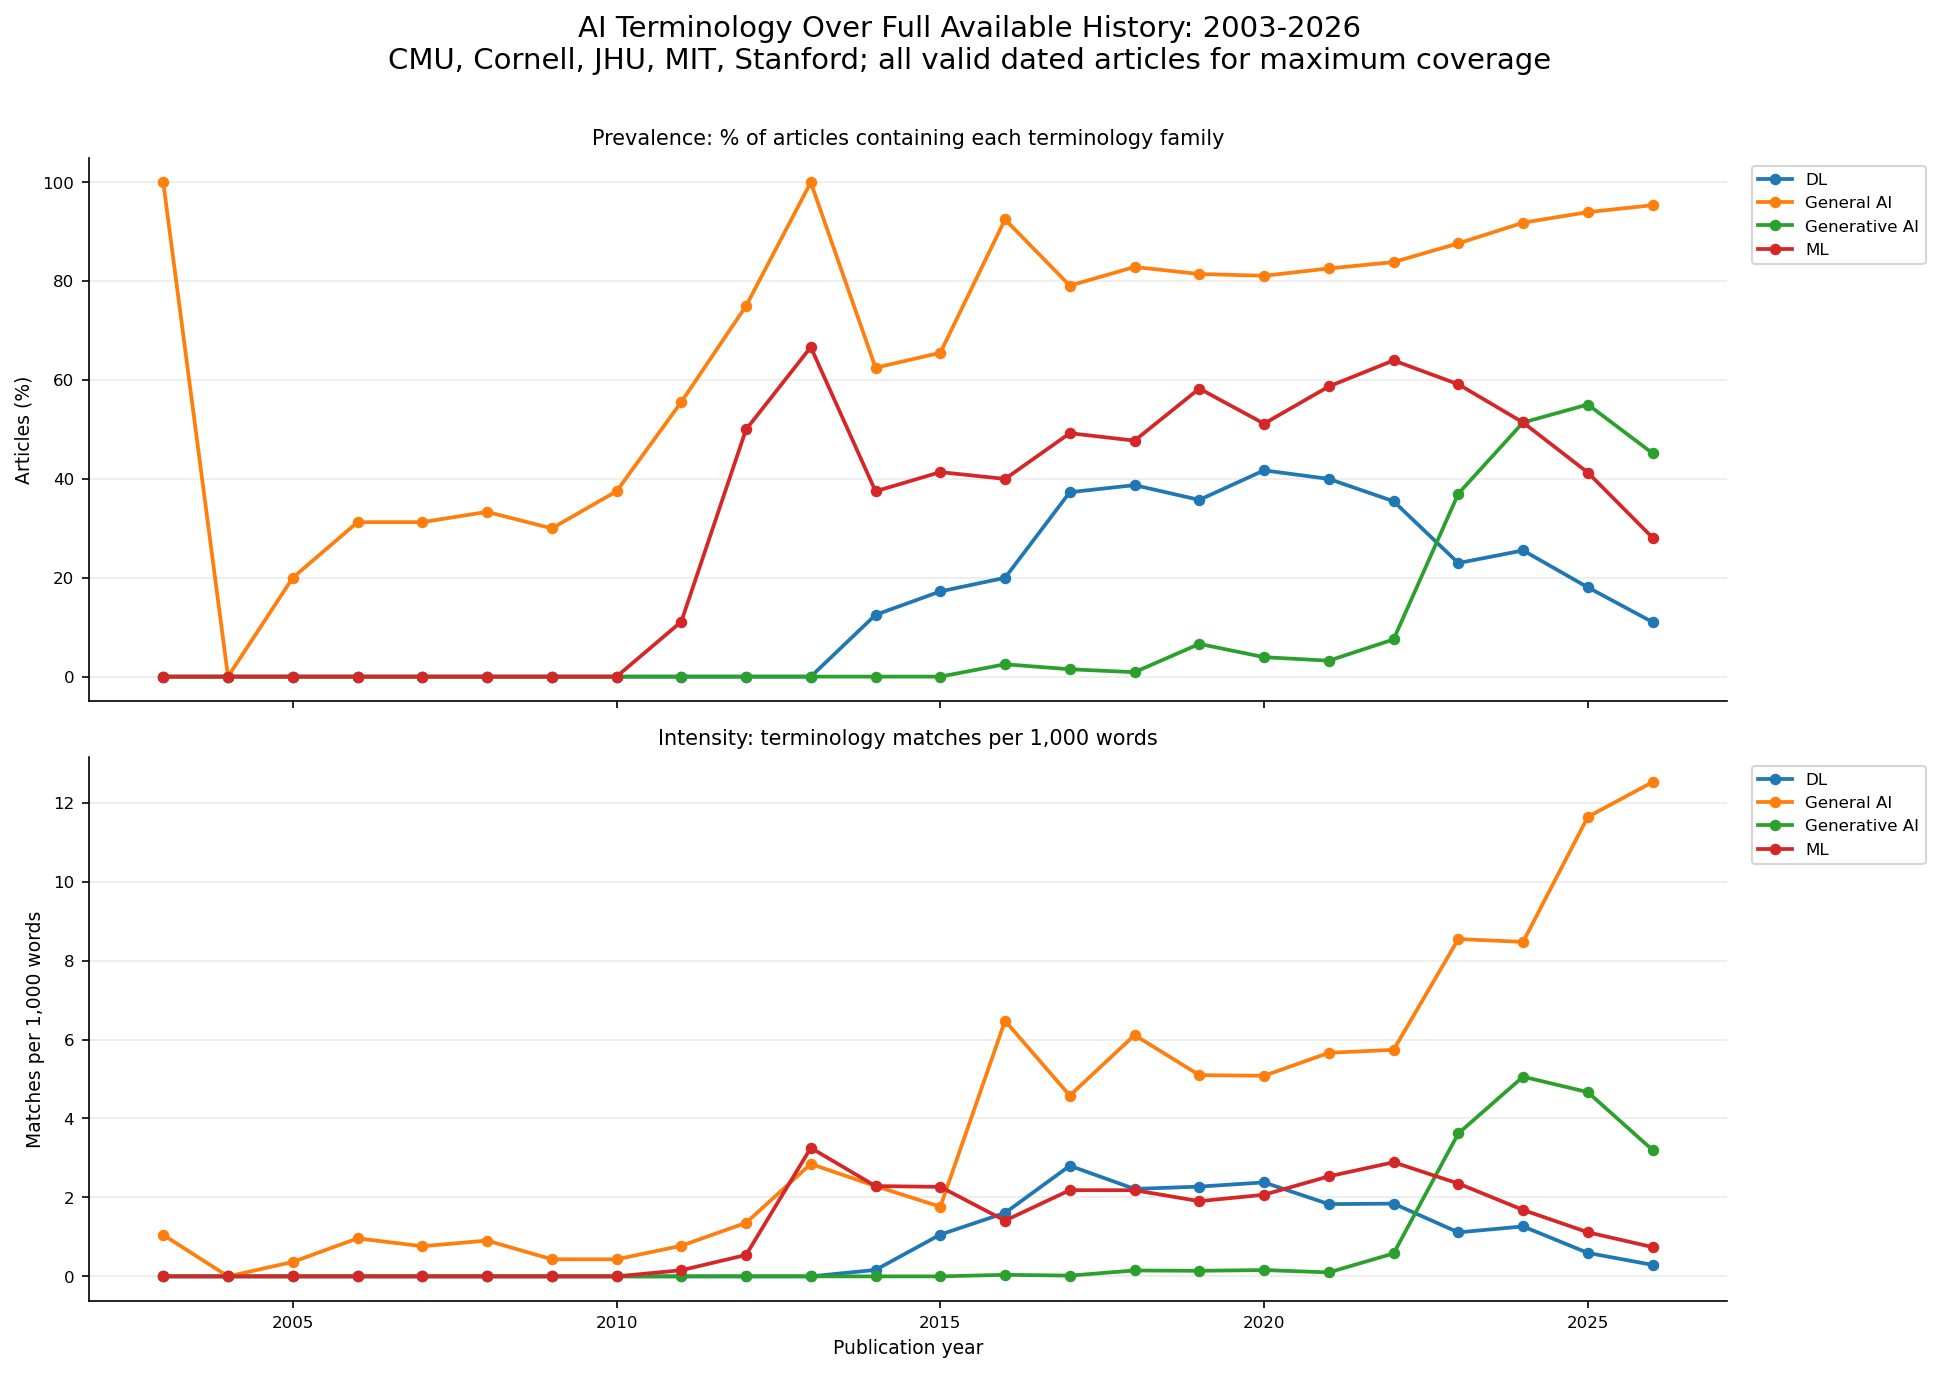

In [15]:
# AI terminology family analysis
ai_terminology_path = DATA_DIR / "AI terminology.json"
with open(ai_terminology_path, "r", encoding="utf-8") as f:
    ai_term_families = json.load(f)

if not isinstance(ai_term_families, dict) or not ai_term_families:
    raise ValueError("AI terminology.json must be a non-empty object mapping family names to term lists.")

invalid_term_families = {
    family: type(cues).__name__
    for family, cues in ai_term_families.items()
    if not isinstance(family, str) or not family.strip() or not isinstance(cues, list)
}
if invalid_term_families:
    raise ValueError(f"Invalid entries in AI terminology.json: {invalid_term_families}")

ai_term_families = {
    family.strip(): dedupe_cues(cues)
    for family, cues in ai_term_families.items()
}
if any(not cues for cues in ai_term_families.values()):
    empty_families = [family for family, cues in ai_term_families.items() if not cues]
    raise ValueError(f"AI terminology.json contains empty terminology families: {empty_families}")

print(f"Loaded {len(ai_term_families)} AI terminology families from: {ai_terminology_path.parent.name}/{ai_terminology_path.name}")
display(pd.DataFrame({
    "term_family": list(ai_term_families),
    "term_count_in_dictionary": [len(cues) for cues in ai_term_families.values()],
}))

compiled_term_families = {
    family: [(cue, compile_flexible_cue(cue)) for cue in dedupe_cues(cues) if compile_flexible_cue(cue) is not None]
    for family, cues in ai_term_families.items()
}

term_rows = []
for row in analysis_df.itertuples(index=False):
    text = getattr(row, "analysis_text_lower")
    word_count = int(getattr(row, "analysis_word_count_nonzero"))
    for family, compiled_cues in compiled_term_families.items():
        family_counts = count_matches(text, compiled_cues)
        total_count = int(sum(family_counts.values()))
        term_rows.append({
            "article_id": getattr(row, "article_id"),
            "Institution": getattr(row, "Institution"),
            "published_date": getattr(row, "published_date"),
            "year": getattr(row, "year"),
            "analysis_period": getattr(row, "analysis_period"),
            "term_family": family,
            "term_count": total_count,
            "term_present": total_count > 0,
            "term_rate_per_1k": total_count / word_count * 1000,
            "matched_terms": format_counts(family_counts),
            "analysis_word_count": word_count,
        })

term_article_scores = pd.DataFrame(term_rows)
term_summary_by_institution = (
    term_article_scores.groupby(["Institution", "term_family"], as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        term_articles=("term_present", "sum"),
        total_term_count=("term_count", "sum"),
        total_words=("analysis_word_count", "sum"),
        mean_article_rate_per_1k=("term_rate_per_1k", "mean"),
    )
)
term_summary_by_institution["term_article_pct"] = (term_summary_by_institution["term_articles"] / term_summary_by_institution["articles"] * 100).round(1)
term_summary_by_institution["term_count_per_1k_words"] = (term_summary_by_institution["total_term_count"] / term_summary_by_institution["total_words"] * 1000).round(2)

print("AI terminology family prevalence by institution (% of articles):")
display(
    term_summary_by_institution.pivot_table(index="Institution", columns="term_family", values="term_article_pct").round(1)
)
print("AI terminology family intensity by institution (term count per 1,000 words):")
display(
    term_summary_by_institution.pivot_table(index="Institution", columns="term_family", values="term_count_per_1k_words").round(2)
)

period_term_summary = (
    term_article_scores.loc[term_article_scores["analysis_period"].isin(["pre_2023", "post_2023"])]
    .groupby(["analysis_period", "term_family"], as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        term_articles=("term_present", "sum"),
        total_term_count=("term_count", "sum"),
        total_words=("analysis_word_count", "sum"),
    )
)
period_term_summary["term_article_pct"] = (period_term_summary["term_articles"] / period_term_summary["articles"] * 100).round(1)
period_term_summary["term_count_per_1k_words"] = (period_term_summary["total_term_count"] / period_term_summary["total_words"] * 1000).round(2)

term_period_delta = period_term_summary.pivot_table(index="term_family", columns="analysis_period", values="term_article_pct")
for col in ["pre_2023", "post_2023"]:
    if col not in term_period_delta.columns:
        term_period_delta[col] = np.nan
term_period_delta["delta_post_minus_pre_pct"] = (term_period_delta["post_2023"] - term_period_delta["pre_2023"]).round(1)
print("Pre/post-2023 AI terminology family prevalence delta:")
display(term_period_delta.sort_values("delta_post_minus_pre_pct", ascending=False))

# Full-history terminology trends, parallel to the communicative-orientation view.
year_term_summary = (
    term_article_scores.dropna(subset=["year"])
    .groupby(["year", "term_family"], as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        term_articles=("term_present", "sum"),
        total_term_count=("term_count", "sum"),
        total_words=("analysis_word_count", "sum"),
    )
)
year_term_summary["term_article_pct"] = 100 * year_term_summary["term_articles"] / year_term_summary["articles"]
year_term_summary["term_count_per_1k_words"] = 1000 * year_term_summary["total_term_count"] / year_term_summary["total_words"]
year_term_prevalence = year_term_summary.pivot_table(index="year", columns="term_family", values="term_article_pct")
year_term_intensity = year_term_summary.pivot_table(index="year", columns="term_family", values="term_count_per_1k_words")
print("Yearly AI terminology prevalence — full cleaned corpus:")
display(year_term_prevalence.round(1))
print("Yearly AI terminology intensity — full cleaned corpus:")
display(year_term_intensity.round(2))

if "PLOTS_AVAILABLE" in globals() and PLOTS_AVAILABLE:
    full_term_years = f"{int(year_term_prevalence.index.min())}-{int(year_term_prevalence.index.max())}"
    full_term_schools = ", ".join(sorted(term_article_scores["Institution"].dropna().unique()))
    fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
    year_term_prevalence.plot(ax=axes[0], marker="o", linewidth=1.8)
    axes[0].set_title("Prevalence: % of articles containing each terminology family")
    axes[0].set_ylabel("Articles (%)")
    year_term_intensity.plot(ax=axes[1], marker="o", linewidth=1.8)
    axes[1].set_title("Intensity: terminology matches per 1,000 words")
    axes[1].set_ylabel("Matches per 1,000 words")
    axes[1].set_xlabel("Publication year")
    for axis in axes:
        axis.grid(axis="y", alpha=.25)
        axis.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
    fig.suptitle(
        f"AI Terminology Over Full Available History: {full_term_years}\n"
        f"{full_term_schools}; all valid dated articles for maximum coverage",
        y=1.01, fontsize=14,
    )
    plt.tight_layout()
    plt.show()

## 3 Core analysis window

The main comparative analyses use the four-institution core window 2021-2025 (CMU, JHU, MIT, Stanford; 1,290 articles; 1,289 with at least 80 analysis words for the content-domain models). 

In [16]:
# Sample availability and core analysis-window setup
candidate_windows = [
    (2021, 2025, "core four-school window: 2021-2025"),
    (2021, 2026, "recent exploratory window: 2021-2026, includes partial 2026"),
    (2025, 2026, "latest five-school snapshot: 2025-2026, partial 2026"),
]

window_rows = []
for start, end, label in candidate_windows:
    subset = analysis_df.loc[analysis_df["year"].between(start, end)].copy()
    counts = subset.groupby("Institution")["article_id"].nunique()
    window_rows.append({
        "window": label,
        "start_year": start,
        "end_year": end,
        "total_articles": int(subset["article_id"].nunique()),
        "institutions_with_articles": int((counts > 0).sum()),
        "min_articles_per_institution": int(counts.min()) if not counts.empty else 0,
        "median_articles_per_institution": float(counts.median()) if not counts.empty else 0,
    })

window_availability = pd.DataFrame(window_rows)
print("Candidate analysis windows:")
display(window_availability)

CORE_START_YEAR = 2021
CORE_END_YEAR = 2025
CORE_INSTITUTIONS = ["CMU", "JHU", "MIT", "Stanford"]
CORE_MIN_ANALYSIS_WORDS = 80

core_analysis_df = analysis_df.loc[
    analysis_df["year"].between(CORE_START_YEAR, CORE_END_YEAR)
    & analysis_df["Institution"].isin(CORE_INSTITUTIONS)
].copy()
core_article_ids = core_analysis_df["article_id"].unique()
core_window_label = f"{CORE_START_YEAR}-{CORE_END_YEAR}, {'/'.join(CORE_INSTITUTIONS)}"

print(f"Core analysis window: {core_window_label}")
print(f"Core articles: {len(core_analysis_df):,}")
print("Core institution-year counts:")
core_institution_year_counts = (
    core_analysis_df.groupby(["Institution", "year"])
    .size()
    .rename("article_count")
    .reset_index()
    .pivot_table(index="Institution", columns="year", values="article_count", fill_value=0)
    .astype(int)
)
display(core_institution_year_counts)

print("Use the full corpus only for descriptive coverage and exploratory checks; use the core window for the main visualizations and models.")

Candidate analysis windows:


,window,start_year,end_year,total_articles,institutions_with_articles,min_articles_per_institution,median_articles_per_institution
0,core four-school window: 2021-2025,2021,2025,1323,5,33,135.0
1,"recent exploratory window: 2021-2026, includes partial 2026",2021,2026,1604,5,89,184.0
2,"latest five-school snapshot: 2025-2026, partial 2026",2025,2026,746,5,52,142.0


Core analysis window: 2021-2025, CMU/JHU/MIT/Stanford
Core articles: 1,290
Core institution-year counts:


year,2021,2022,2023,2024,2025
Institution,,,,,
CMU,10,28,38,57,98
JHU,5,8,27,26,35
MIT,130,145,164,178,206
Stanford,10,5,6,21,93


Use the full corpus only for descriptive coverage and exploratory checks; use the core window for the main visualizations and models.


Retained data table for the core analysis window:


,step,articles,retained_pct_of_full
0,Full cleaned corpus after initial data cleaning,2231,100.0
1,Articles with valid publication year,2231,100.0
2,Articles in core years 2021-2025,1323,59.3
3,"Core schools only: CMU, JHU, MIT, Stanford",1290,57.8
4,Core schools/years with >= 80 analysis words,1289,57.8


Core article counts by institution-year:


year,2021,2022,2023,2024,2025
Institution,,,,,
CMU,10,28,38,57,98
JHU,5,8,27,26,35
MIT,130,145,164,178,206
Stanford,10,5,6,21,93


Core median article length by institution-year:


year,2021,2022,2023,2024,2025
Institution,,,,,
CMU,595.0,440.0,550.0,631.0,698.0
JHU,551.0,774.0,877.0,658.0,729.0
MIT,995.0,1057.0,1066.0,1044.0,1072.0
Stanford,1030.0,1061.0,1012.0,1068.0,1034.0


Core school-level descriptive summary:


,Institution,articles,first_year,last_year,median_words,mean_words,article_share_pct
0,CMU,231,2021,2025,608.0,723.9,17.9
1,JHU,101,2021,2025,729.0,823.0,7.8
2,MIT,823,2021,2025,1052.0,982.8,63.8
3,Stanford,135,2021,2025,1049.0,1086.1,10.5


Saved figures/fig01_core_window_coverage.pdf


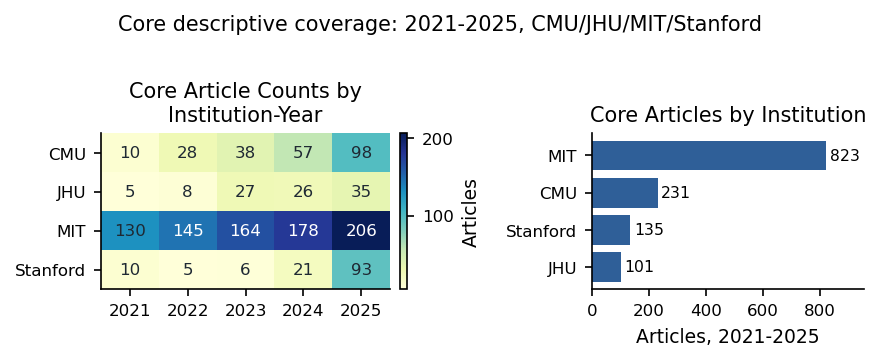

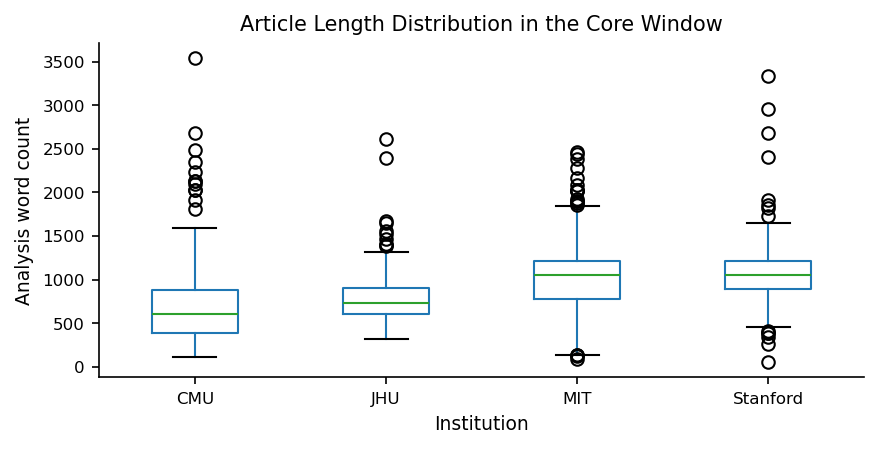

In [17]:
# Core-window descriptive table and coverage figure (fig01_core_window_coverage.pdf)
# This is the descriptive bridge between the full-corpus overview and the main analysis window.

retention_steps = []
full_n = analysis_df["article_id"].nunique()
retention_steps.append({
    "step": "Full cleaned corpus after initial data cleaning",
    "articles": full_n,
    "retained_pct_of_full": 100.0,
})

valid_year_df = analysis_df.loc[analysis_df["year"].notna()].copy()
retention_steps.append({
    "step": "Articles with valid publication year",
    "articles": valid_year_df["article_id"].nunique(),
    "retained_pct_of_full": valid_year_df["article_id"].nunique() / full_n * 100,
})

year_window_df = valid_year_df.loc[valid_year_df["year"].between(CORE_START_YEAR, CORE_END_YEAR)].copy()
retention_steps.append({
    "step": f"Articles in core years {CORE_START_YEAR}-{CORE_END_YEAR}",
    "articles": year_window_df["article_id"].nunique(),
    "retained_pct_of_full": year_window_df["article_id"].nunique() / full_n * 100,
})

school_window_df = year_window_df.loc[year_window_df["Institution"].isin(CORE_INSTITUTIONS)].copy()
retention_steps.append({
    "step": f"Core schools only: {', '.join(CORE_INSTITUTIONS)}",
    "articles": school_window_df["article_id"].nunique(),
    "retained_pct_of_full": school_window_df["article_id"].nunique() / full_n * 100,
})

model_ready_df = school_window_df.loc[school_window_df["analysis_word_count"] >= CORE_MIN_ANALYSIS_WORDS].copy()
retention_steps.append({
    "step": f"Core schools/years with >= {CORE_MIN_ANALYSIS_WORDS} analysis words",
    "articles": model_ready_df["article_id"].nunique(),
    "retained_pct_of_full": model_ready_df["article_id"].nunique() / full_n * 100,
})

core_retention_table = pd.DataFrame(retention_steps)
print("Retained data table for the core analysis window:")
display(core_retention_table.round({"retained_pct_of_full": 1}))

core_descriptive_by_school_year = (
    core_analysis_df.groupby(["Institution", "year"], as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        median_words=("analysis_word_count", "median"),
        mean_words=("analysis_word_count", "mean"),
    )
)
core_descriptive_by_school_year["year"] = core_descriptive_by_school_year["year"].astype(int)
core_count_matrix = core_descriptive_by_school_year.pivot_table(
    index="Institution", columns="year", values="articles", fill_value=0
).astype(int)
core_word_matrix = core_descriptive_by_school_year.pivot_table(
    index="Institution", columns="year", values="median_words", fill_value=np.nan
).round(0)

print("Core article counts by institution-year:")
display(core_count_matrix)
print("Core median article length by institution-year:")
display(core_word_matrix)

core_school_summary = (
    core_analysis_df.groupby("Institution", as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        first_year=("year", "min"),
        last_year=("year", "max"),
        median_words=("analysis_word_count", "median"),
        mean_words=("analysis_word_count", "mean"),
    )
)
core_school_summary["article_share_pct"] = core_school_summary["articles"] / core_school_summary["articles"].sum() * 100
print("Core school-level descriptive summary:")
display(core_school_summary.round({"mean_words": 1, "median_words": 1, "article_share_pct": 1}))

if "PLOTS_AVAILABLE" in globals() and PLOTS_AVAILABLE:
    fig, axes = plt.subplots(1, 2, figsize=(TEXTWIDTH_IN, 2.3), gridspec_kw={"width_ratios": [1.15, 1]})

    im = draw_heatmap_cells(axes[0], core_count_matrix, cmap="YlGnBu", value_fmt="d", fontsize=8)
    axes[0].set_title(wrap_text("Core Article Counts by Institution-Year", 26))
    axes[0].set_xticks(range(core_count_matrix.shape[1]))
    axes[0].set_xticklabels(core_count_matrix.columns.astype(int))
    axes[0].set_yticks(range(core_count_matrix.shape[0]))
    axes[0].set_yticklabels(core_count_matrix.index)
    cbar = plt.colorbar(im, ax=axes[0], fraction=0.045, pad=0.03)
    cbar.set_label("Articles")

    school_plot = core_school_summary.sort_values("articles", ascending=True)
    axes[1].barh(school_plot["Institution"], school_plot["articles"], color="#2F5F98")
    axes[1].set_title("Core Articles by Institution")
    axes[1].set_xlabel("Articles, 2021-2025")
    axes[1].set_xlim(0, school_plot["articles"].max() * 1.16)
    for patch in axes[1].patches:
        width = patch.get_width()
        axes[1].text(width + school_plot["articles"].max() * 0.015, patch.get_y() + patch.get_height() / 2,
                     f"{int(width)}", va="center", fontsize=7.5)

    fig.suptitle("Core descriptive coverage: 2021-2025, CMU/JHU/MIT/Stanford", y=1.02)
    plt.tight_layout()
    save_fig(fig, "fig01_core_window_coverage")
    plt.show()

    fig, ax = plt.subplots(figsize=(TEXTWIDTH_IN, 3.2))
    core_analysis_df.boxplot(column="analysis_word_count", by="Institution", ax=ax, grid=False)
    ax.set_title("Article Length Distribution in the Core Window")
    ax.set_xlabel("Institution")
    ax.set_ylabel("Analysis word count")
    fig.suptitle("")
    plt.tight_layout()
    plt.show()

In [18]:
# Core-window profiles and pre/post comparison: 2021-2025 four-school window
core_frame_scores = frame_article_scores.loc[frame_article_scores["article_id"].isin(core_article_ids)].copy()
core_term_scores = term_article_scores.loc[term_article_scores["article_id"].isin(core_article_ids)].copy()

core_frame_summary_by_institution = (
    core_frame_scores.groupby(["Institution", "frame_id", "frame_label"], as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        frame_articles=("frame_present", "sum"),
        total_weighted_score=("weighted_score", "sum"),
        total_words=("analysis_word_count", "sum"),
        mean_article_rate_per_1k=("weighted_rate_per_1k", "mean"),
    )
)
core_frame_summary_by_institution["frame_article_pct"] = (
    core_frame_summary_by_institution["frame_articles"] / core_frame_summary_by_institution["articles"] * 100
).round(1)
core_frame_summary_by_institution["weighted_score_per_1k_words"] = (
    core_frame_summary_by_institution["total_weighted_score"] / core_frame_summary_by_institution["total_words"] * 1000
).round(2)

core_term_summary_by_institution = (
    core_term_scores.groupby(["Institution", "term_family"], as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        term_articles=("term_present", "sum"),
        total_term_count=("term_count", "sum"),
        total_words=("analysis_word_count", "sum"),
        mean_article_rate_per_1k=("term_rate_per_1k", "mean"),
    )
)
core_term_summary_by_institution["term_article_pct"] = (
    core_term_summary_by_institution["term_articles"] / core_term_summary_by_institution["articles"] * 100
).round(1)
core_term_summary_by_institution["term_count_per_1k_words"] = (
    core_term_summary_by_institution["total_term_count"] / core_term_summary_by_institution["total_words"] * 1000
).round(2)

core_overall_frame_profile = (
    core_frame_scores.groupby(["frame_id", "frame_label"], as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        frame_articles=("frame_present", "sum"),
        total_weighted_score=("weighted_score", "sum"),
        total_words=("analysis_word_count", "sum"),
    )
)
core_overall_frame_profile["frame_article_pct"] = (
    core_overall_frame_profile["frame_articles"] / core_overall_frame_profile["articles"] * 100
).round(1)
core_overall_frame_profile["weighted_score_per_1k_words"] = (
    core_overall_frame_profile["total_weighted_score"] / core_overall_frame_profile["total_words"] * 1000
).round(2)

core_overall_term_profile = (
    core_term_scores.groupby("term_family", as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        term_articles=("term_present", "sum"),
        total_term_count=("term_count", "sum"),
        total_words=("analysis_word_count", "sum"),
    )
)
core_overall_term_profile["term_article_pct"] = (
    core_overall_term_profile["term_articles"] / core_overall_term_profile["articles"] * 100
).round(1)
core_overall_term_profile["term_count_per_1k_words"] = (
    core_overall_term_profile["total_term_count"] / core_overall_term_profile["total_words"] * 1000
).round(2)

core_period_frame_summary = (
    core_frame_scores.loc[core_frame_scores["analysis_period"].isin(["pre_2023", "post_2023"])]
    .groupby(["analysis_period", "frame_id", "frame_label"], as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        frame_articles=("frame_present", "sum"),
        total_weighted_score=("weighted_score", "sum"),
        total_words=("analysis_word_count", "sum"),
    )
)
core_period_frame_summary["frame_article_pct"] = (
    core_period_frame_summary["frame_articles"] / core_period_frame_summary["articles"] * 100
).round(1)
core_period_frame_summary["weighted_score_per_1k_words"] = (
    core_period_frame_summary["total_weighted_score"] / core_period_frame_summary["total_words"] * 1000
).round(2)

def pivot_core_period_metric(frame_or_term_summary, index_cols, metric, delta_name):
    wide = frame_or_term_summary.pivot_table(index=index_cols, columns="analysis_period", values=metric)
    for col in ["pre_2023", "post_2023"]:
        if col not in wide.columns:
            wide[col] = np.nan
    wide[delta_name] = (wide["post_2023"] - wide["pre_2023"]).round(2)
    return wide.reset_index().sort_values(delta_name, ascending=False)

core_period_prevalence_delta = pivot_core_period_metric(
    core_period_frame_summary, ["frame_id", "frame_label"], "frame_article_pct", "delta_post_minus_pre_frame_article_pct"
)
core_period_intensity_delta = pivot_core_period_metric(
    core_period_frame_summary, ["frame_id", "frame_label"], "weighted_score_per_1k_words", "delta_post_minus_pre_weighted_score_per_1k_words"
)

core_period_term_summary = (
    core_term_scores.loc[core_term_scores["analysis_period"].isin(["pre_2023", "post_2023"])]
    .groupby(["analysis_period", "term_family"], as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        term_articles=("term_present", "sum"),
        total_term_count=("term_count", "sum"),
        total_words=("analysis_word_count", "sum"),
    )
)
core_period_term_summary["term_article_pct"] = (
    core_period_term_summary["term_articles"] / core_period_term_summary["articles"] * 100
).round(1)
core_period_term_summary["term_count_per_1k_words"] = (
    core_period_term_summary["total_term_count"] / core_period_term_summary["total_words"] * 1000
).round(2)
core_term_period_delta = pivot_core_period_metric(
    core_period_term_summary, ["term_family"], "term_article_pct", "delta_post_minus_pre_pct"
)
core_term_period_intensity_delta = pivot_core_period_metric(
    core_period_term_summary, ["term_family"], "term_count_per_1k_words", "delta_post_minus_pre_intensity"
)

print("Core-window overall communicative-orientation profile:")
display(core_overall_frame_profile.sort_values("weighted_score_per_1k_words", ascending=False))
print("Core-window overall AI terminology profile:")
display(core_overall_term_profile.sort_values("term_count_per_1k_words", ascending=False))
print("Core-window pre/post-2023 communicative-orientation prevalence delta:")
display(core_period_prevalence_delta)
print("Core-window pre/post-2023 communicative-orientation intensity delta:")
display(core_period_intensity_delta)

Core-window overall communicative-orientation profile:


,frame_id,frame_label,articles,frame_articles,total_weighted_score,total_words,frame_article_pct,weighted_score_per_1k_words
5,research_scientific_progress,Scientific progress,1290,848,17578,1205817,65.7,14.58
4,institutional_positioning_capacity,Institutional positioning,1290,848,12102,1205817,65.7,10.04
7,societal_benefit_public_good,Social benefit,1290,578,9510,1205817,44.8,7.89
0,application_automation_efficiency,Application,1290,634,7702,1205817,49.1,6.39
6,risk_responsibility_ethics,Risk & ethics,1290,403,5935,1205817,31.2,4.92
1,commercialization_innovation_ecosystem,Commercialization,1290,245,3951,1205817,19.0,3.28
3,human_augmentation_collaboration,Human–AI collab,1290,303,3884,1205817,23.5,3.22
2,governance_policy_regulation,Policy & regulation,1290,159,2486,1205817,12.3,2.06


Core-window overall AI terminology profile:


,term_family,articles,term_articles,total_term_count,total_words,term_article_pct,term_count_per_1k_words
1,General AI,1290,1156,10564,1205817,89.6,8.76
2,Generative AI,1290,488,4136,1205817,37.8,3.43
3,ML,1290,679,2268,1205817,52.6,1.88
0,DL,1290,336,1392,1205817,26.0,1.15


Core-window pre/post-2023 communicative-orientation prevalence delta:


analysis_period,frame_id,frame_label,post_2023,pre_2023,delta_post_minus_pre_frame_article_pct
0,application_automation_efficiency,Application,51.3,43.1,8.2
6,risk_responsibility_ethics,Risk & ethics,32.9,26.7,6.2
3,human_augmentation_collaboration,Human–AI collab,24.8,19.9,4.9
7,societal_benefit_public_good,Social benefit,46.0,41.3,4.7
1,commercialization_innovation_ecosystem,Commercialization,20.1,15.8,4.3
2,governance_policy_regulation,Policy & regulation,13.4,9.4,4.0
4,institutional_positioning_capacity,Institutional positioning,65.9,65.4,0.5
5,research_scientific_progress,Scientific progress,65.1,67.4,-2.3


Core-window pre/post-2023 communicative-orientation intensity delta:


analysis_period,frame_id,frame_label,post_2023,pre_2023,delta_post_minus_pre_weighted_score_per_1k_words
6,risk_responsibility_ethics,Risk & ethics,5.14,4.27,0.87
1,commercialization_innovation_ecosystem,Commercialization,3.45,2.76,0.69
0,application_automation_efficiency,Application,6.55,5.91,0.64
2,governance_policy_regulation,Policy & regulation,2.19,1.70,0.49
7,societal_benefit_public_good,Social benefit,7.98,7.62,0.36
3,human_augmentation_collaboration,Human–AI collab,3.24,3.15,0.09
4,institutional_positioning_capacity,Institutional positioning,10.00,10.13,-0.13
5,research_scientific_progress,Scientific progress,14.34,15.28,-0.94


## 4 Descriptive terminology and orientation profiles


In [19]:
# Compact result tables
overall_frame_profile = (
    frame_article_scores.groupby(["frame_id", "frame_label"], as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        frame_articles=("frame_present", "sum"),
        total_weighted_score=("weighted_score", "sum"),
        total_words=("analysis_word_count", "sum"),
    )
)
overall_frame_profile["frame_article_pct"] = (overall_frame_profile["frame_articles"] / overall_frame_profile["articles"] * 100).round(1)
overall_frame_profile["weighted_score_per_1k_words"] = (overall_frame_profile["total_weighted_score"] / overall_frame_profile["total_words"] * 1000).round(2)

overall_term_profile = (
    term_article_scores.groupby("term_family", as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        term_articles=("term_present", "sum"),
        total_term_count=("term_count", "sum"),
        total_words=("analysis_word_count", "sum"),
    )
)
overall_term_profile["term_article_pct"] = (overall_term_profile["term_articles"] / overall_term_profile["articles"] * 100).round(1)
overall_term_profile["term_count_per_1k_words"] = (overall_term_profile["total_term_count"] / overall_term_profile["total_words"] * 1000).round(2)

print("Overall scientific-communication orientation profile, sorted by normalized intensity:")
display(overall_frame_profile.sort_values("weighted_score_per_1k_words", ascending=False))

print("Overall AI terminology profile, sorted by normalized intensity:")
display(overall_term_profile.sort_values("term_count_per_1k_words", ascending=False))

Overall scientific-communication orientation profile, sorted by normalized intensity:


,frame_id,frame_label,articles,frame_articles,total_weighted_score,total_words,frame_article_pct,weighted_score_per_1k_words
5,research_scientific_progress,Scientific progress,2231,1359,26060,2010542,60.9,12.96
4,institutional_positioning_capacity,Institutional positioning,2231,1394,21231,2010542,62.5,10.56
7,societal_benefit_public_good,Social benefit,2231,906,14805,2010542,40.6,7.36
0,application_automation_efficiency,Application,2231,1030,12613,2010542,46.2,6.27
6,risk_responsibility_ethics,Risk & ethics,2231,624,9152,2010542,28.0,4.55
1,commercialization_innovation_ecosystem,Commercialization,2231,419,6772,2010542,18.8,3.37
3,human_augmentation_collaboration,Human–AI collab,2231,459,6016,2010542,20.6,2.99
2,governance_policy_regulation,Policy & regulation,2231,245,4110,2010542,11.0,2.04


Overall AI terminology profile, sorted by normalized intensity:


,term_family,articles,term_articles,total_term_count,total_words,term_article_pct,term_count_per_1k_words
1,General AI,2231,1920,16595,2010542,86.1,8.25
2,Generative AI,2231,652,5144,2010542,29.2,2.56
3,ML,2231,1040,3433,2010542,46.6,1.71
0,DL,2231,558,2522,2010542,25.0,1.25


Saved figures/fig03_overall_prevalence_intensity.pdf


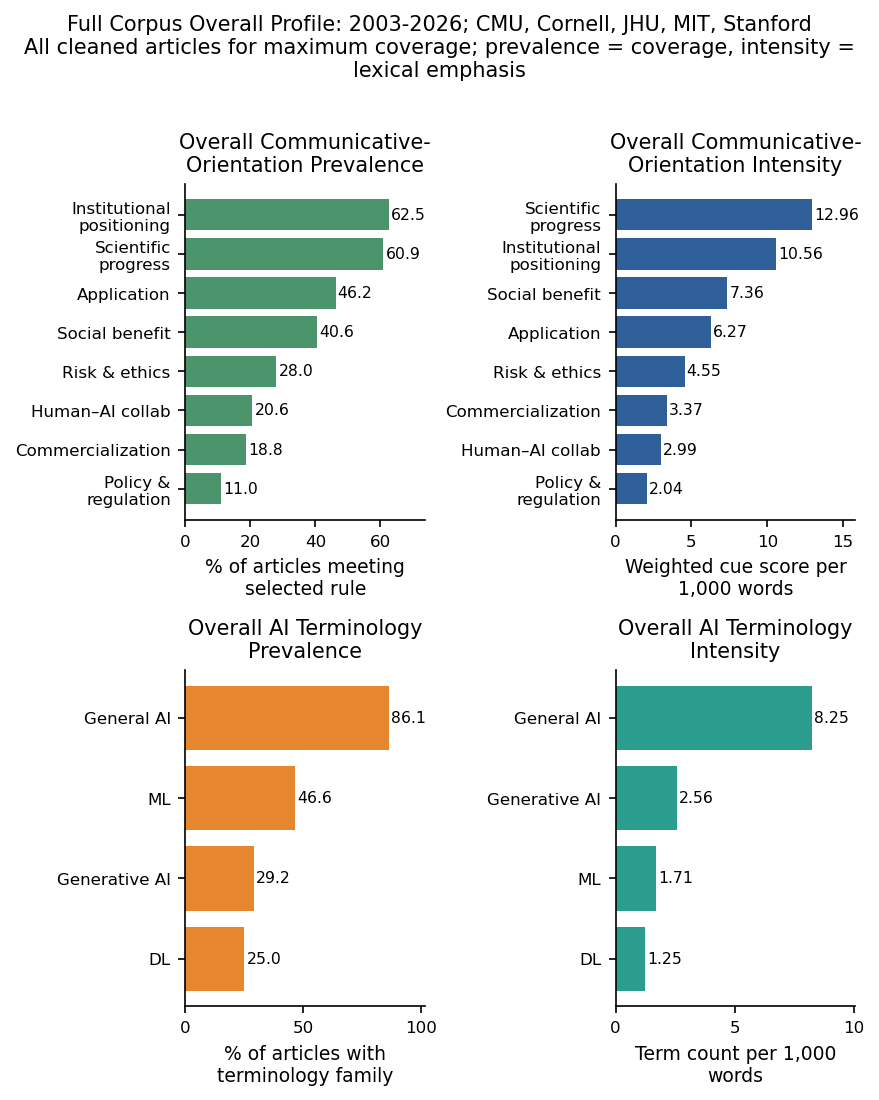

In [20]:
# Figure fig03_overall_prevalence_intensity.pdf: overall communicative-orientation and terminology prevalence vs intensity
fig, axes = plt.subplots(2, 2, figsize=(TEXTWIDTH_IN, 7.2))

frame_prev_plot = overall_frame_profile.sort_values("frame_article_pct", ascending=True).copy()
axes[0, 0].barh(wrap_labels(frame_prev_plot["frame_label"], 18), frame_prev_plot["frame_article_pct"], color=COLORS["green"])
axes[0, 0].set_title(wrap_text("Overall Communicative-Orientation Prevalence", 30))
axes[0, 0].set_xlabel(wrap_text("% of articles meeting selected rule", 24))
axes[0, 0].set_ylabel("")
annotate_barh(axes[0, 0], fmt="{:.1f}", pad=0)
axes[0, 0].set_xlim(0, min(105, frame_prev_plot["frame_article_pct"].max() * 1.18))

frame_int_plot = overall_frame_profile.sort_values("weighted_score_per_1k_words", ascending=True).copy()
axes[0, 1].barh(wrap_labels(frame_int_plot["frame_label"], 18), frame_int_plot["weighted_score_per_1k_words"], color=COLORS["blue"])
axes[0, 1].set_title(wrap_text("Overall Communicative-Orientation Intensity", 30))
axes[0, 1].set_xlabel(wrap_text("Weighted cue score per 1,000 words", 24))
axes[0, 1].set_ylabel("")
annotate_barh(axes[0, 1], fmt="{:.2f}", pad=0)
axes[0, 1].set_xlim(0, frame_int_plot["weighted_score_per_1k_words"].max() * 1.22)

term_prev_plot = overall_term_profile.sort_values("term_article_pct", ascending=True).copy()
axes[1, 0].barh(wrap_labels(term_prev_plot["term_family"], 18), term_prev_plot["term_article_pct"], color=COLORS["orange"])
axes[1, 0].set_title(wrap_text("Overall AI Terminology Prevalence", 30))
axes[1, 0].set_xlabel(wrap_text("% of articles with terminology family", 24))
axes[1, 0].set_ylabel("")
annotate_barh(axes[1, 0], fmt="{:.1f}", pad=0)
axes[1, 0].set_xlim(0, min(105, term_prev_plot["term_article_pct"].max() * 1.18))

term_int_plot = overall_term_profile.sort_values("term_count_per_1k_words", ascending=True).copy()
axes[1, 1].barh(wrap_labels(term_int_plot["term_family"], 18), term_int_plot["term_count_per_1k_words"], color=COLORS["teal"])
axes[1, 1].set_title(wrap_text("Overall AI Terminology Intensity", 30))
axes[1, 1].set_xlabel(wrap_text("Term count per 1,000 words", 24))
axes[1, 1].set_ylabel("")
annotate_barh(axes[1, 1], fmt="{:.2f}", pad=0)
axes[1, 1].set_xlim(0, term_int_plot["term_count_per_1k_words"].max() * 1.22)

fig.suptitle(
    wrap_text(
        f"Full Corpus Overall Profile: {int(analysis_df['year'].min())}-{int(analysis_df['year'].max())}; "
        f"{', '.join(sorted(analysis_df['Institution'].dropna().unique()))}\n"
        "All cleaned articles for maximum coverage; prevalence = coverage, intensity = lexical emphasis",
        78,
    ),
    y=1.01,
)
plt.tight_layout()
save_fig(fig, "fig03_overall_prevalence_intensity")
plt.show()

### 4.1 Profiles by institution

Orientation prevalence and intensity by institution (`fig04_orientation_prevalence_by_school.pdf`, `fig05_orientation_intensity_by_school.pdf`) and terminology-family prevalence and intensity by institution (`fig06_terminology_prevalence_by_school.pdf`, `fig07_terminology_intensity_by_school.pdf`).


In [21]:
# Scientific Communication: communicative-orientation prevalence and intensity by institution
frame_summary_by_institution = (
    frame_article_scores.groupby(["Institution", "frame_id", "frame_label"], as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        frame_articles=("frame_present", "sum"),
        total_weighted_score=("weighted_score", "sum"),
        total_words=("analysis_word_count", "sum"),
        mean_article_rate_per_1k=("weighted_rate_per_1k", "mean"),
    )
)
frame_summary_by_institution["frame_article_pct"] = (
    frame_summary_by_institution["frame_articles"] / frame_summary_by_institution["articles"] * 100
).round(1)
frame_summary_by_institution["weighted_score_per_1k_words"] = (
    frame_summary_by_institution["total_weighted_score"] / frame_summary_by_institution["total_words"] * 1000
).round(2)

frame_prevalence_pivot = frame_summary_by_institution.pivot_table(
    index="Institution",
    columns="frame_label",
    values="frame_article_pct",
).round(1)
frame_intensity_pivot = frame_summary_by_institution.pivot_table(
    index="Institution",
    columns="frame_label",
    values="weighted_score_per_1k_words",
).round(2)

print("Communicative-orientation prevalence by institution (% of articles in each institution):")
display(frame_prevalence_pivot)
print("Communicative-orientation intensity by institution (weighted dictionary score per 1,000 words):")
display(frame_intensity_pivot)

Communicative-orientation prevalence by institution (% of articles in each institution):


frame_label,Application,Commercialization,Human–AI collab,Institutional positioning,Policy & regulation,Risk & ethics,Scientific progress,Social benefit
Institution,,,,,,,,
CMU,38.2,20.1,18.0,70.0,12.4,32.9,40.6,40.6
Cornell,39.3,23.6,15.7,76.4,12.4,31.5,37.1,38.2
JHU,46.2,21.5,26.2,63.8,11.5,35.4,61.5,55.4
MIT,46.7,16.4,19.0,59.6,8.0,24.0,65.3,37.2
Stanford,55.0,29.4,32.9,65.8,27.7,42.4,66.2,55.0


Communicative-orientation intensity by institution (weighted dictionary score per 1,000 words):


frame_label,Application,Commercialization,Human–AI collab,Institutional positioning,Policy & regulation,Risk & ethics,Scientific progress,Social benefit
Institution,,,,,,,,
CMU,6.87,4.89,3.55,13.47,2.39,7.58,7.52,8.95
Cornell,6.93,6.32,3.19,17.01,3.37,5.53,7.99,8.79
JHU,5.52,3.46,3.73,10.54,1.87,5.44,9.65,10.08
MIT,6.15,2.96,2.73,10.32,1.37,3.71,14.89,6.43
Stanford,6.65,3.68,3.60,8.11,5.18,6.06,9.47,9.64


Saved figures/fig04_orientation_prevalence_by_school.pdf


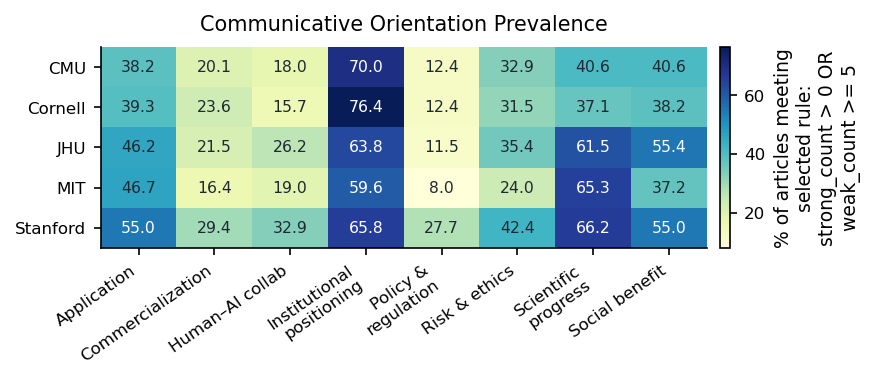

Saved figures/fig05_orientation_intensity_by_school.pdf


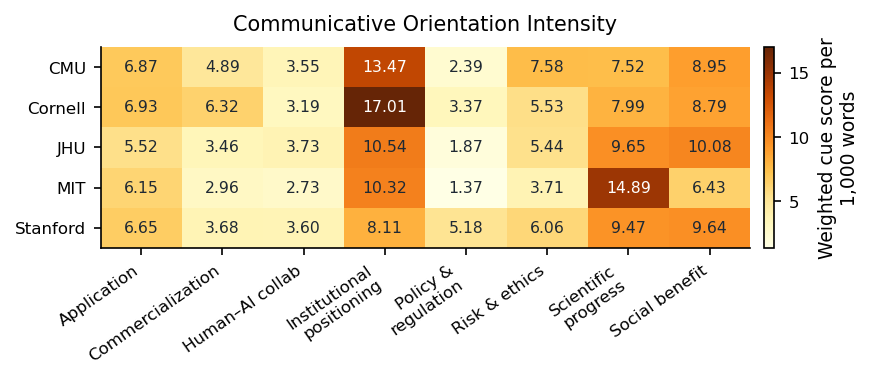

Saved figures/fig06_terminology_prevalence_by_school.pdf


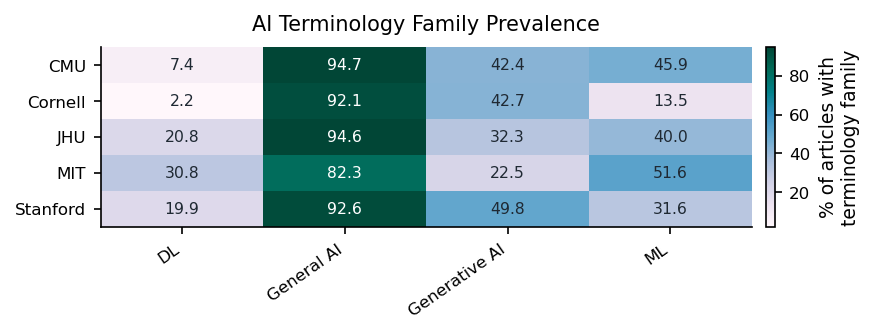

Saved figures/fig07_terminology_intensity_by_school.pdf


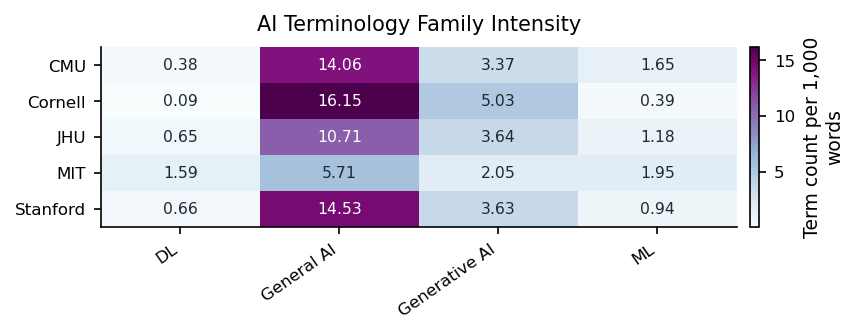

In [22]:
# Figures fig04, fig05, fig06_terminology and fig07_terminology: institution-level prevalence and intensity for orientations and terminology
frame_prevalence_matrix = frame_summary_by_institution.pivot_table(
    index="Institution",
    columns="frame_label",
    values="frame_article_pct",
).round(1)
frame_intensity_matrix = frame_summary_by_institution.pivot_table(
    index="Institution",
    columns="frame_label",
    values="weighted_score_per_1k_words",
).round(2)
term_prevalence_matrix = term_summary_by_institution.pivot_table(
    index="Institution",
    columns="term_family",
    values="term_article_pct",
).round(1)
term_intensity_matrix = term_summary_by_institution.pivot_table(
    index="Institution",
    columns="term_family",
    values="term_count_per_1k_words",
).round(2)

draw_heatmap(
    frame_prevalence_matrix,
    f"Communicative Orientation Prevalence",
    f"% of articles meeting selected rule: strong_count > {PREVALENCE_STRONG_THRESHOLD} OR weak_count >= {PREVALENCE_WEAK_THRESHOLD}",
    cmap="YlGnBu",
    figsize=(TEXTWIDTH_IN, 2.6),
    save_as="fig04_orientation_prevalence_by_school",
)

draw_heatmap(
    frame_intensity_matrix,
    f"Communicative Orientation Intensity ",
    "Weighted cue score per 1,000 words",
    cmap="YlOrBr",
    value_fmt=".2f",
    figsize=(TEXTWIDTH_IN, 2.6),
    save_as="fig05_orientation_intensity_by_school",
)

draw_heatmap(
    term_prevalence_matrix,
    f"AI Terminology Family Prevalence",
    "% of articles with terminology family",
    cmap="PuBuGn",
    figsize=(TEXTWIDTH_IN, 2.3),
    save_as="fig06_terminology_prevalence_by_school",
)

draw_heatmap(
    term_intensity_matrix,
    f"AI Terminology Family Intensity ",
    "Term count per 1,000 words",
    cmap="BuPu",
    value_fmt=".2f",
    figsize=(TEXTWIDTH_IN, 2.3),
    save_as="fig07_terminology_intensity_by_school",
)

### 4.2 Dominant orientation and close-reading examples

Each article is assigned its single highest-scoring orientation (a face-validity aid); the highest-scoring articles per orientation are listed for close reading.


In [23]:
# Dominant communicative-orientation profile and close-reading validation samples
frame_rank = frame_article_scores.copy()
frame_rank["dominant_score"] = frame_rank["weighted_score"]
positive_rank = frame_rank.loc[frame_rank["dominant_score"] > 0].copy()

if not positive_rank.empty:
    idx = positive_rank.groupby("article_id")["dominant_score"].idxmax()
    dominant_frame_by_article = positive_rank.loc[idx, ["article_id", "frame_id", "frame_label", "dominant_score", "weighted_rate_per_1k"]]
    dominant_frame_by_article = dominant_frame_by_article.rename(columns={
        "frame_id": "dominant_frame_id",
        "frame_label": "dominant_frame_label",
        "dominant_score": "dominant_frame_score",
        "weighted_rate_per_1k": "dominant_frame_rate_per_1k",
    })
    analysis_scored = analysis_df.merge(dominant_frame_by_article, on="article_id", how="left")
    analysis_scored["dominant_frame_label"] = analysis_scored["dominant_frame_label"].fillna("No dictionary orientation")
else:
    analysis_scored = analysis_df.copy()
    analysis_scored["dominant_frame_label"] = "No dictionary orientation"

print("Dominant dictionary-based communicative orientation by institution (% of articles):")
dominant_profile = (
    analysis_scored.groupby(["Institution", "dominant_frame_label"])
    .size()
    .rename("article_count")
    .reset_index()
)
dominant_profile["institution_total"] = dominant_profile.groupby("Institution")["article_count"].transform("sum")
dominant_profile["article_pct"] = (dominant_profile["article_count"] / dominant_profile["institution_total"] * 100).round(1)
display(
    dominant_profile.pivot_table(index="Institution", columns="dominant_frame_label", values="article_pct", fill_value=0).round(1)
)

def parse_first_cue(match_string):
    if not isinstance(match_string, str) or not match_string.strip():
        return ""
    first = match_string.split(";")[0]
    return first.split(":")[0].strip()

def first_snippet(text, cue, window=140):
    if not isinstance(text, str) or not cue:
        return ""
    pattern = compile_flexible_cue(cue)
    if pattern is None:
        return ""
    match = pattern.search(text)
    if not match:
        return ""
    start = max(match.start() - window // 2, 0)
    end = min(match.end() + window // 2, len(text))
    snippet = text[start:end]
    snippet = re.sub(r"\s+", " ", snippet).strip()
    prefix = "..." if start > 0 else ""
    suffix = "..." if end < len(text) else ""
    return prefix + snippet + suffix

validation_rows = []
for frame_id, compiled in compiled_frames.items():
    candidates = (
        frame_article_scores.loc[(frame_article_scores["frame_id"] == frame_id) & (frame_article_scores["frame_present"])]
        .sort_values(["strong_count", "weighted_rate_per_1k", "weighted_score"], ascending=False)
        .head(3)
    )
    for _, item in candidates.iterrows():
        article = analysis_df.loc[analysis_df["article_id"] == item["article_id"]].iloc[0]
        cue = parse_first_cue(item["strong_matches"]) or parse_first_cue(item["weak_matches"])
        validation_rows.append({
            "communicative_orientation": compiled["label"],
            "Institution": article["Institution"],
            "Published Date": article.get("Published Date", ""),
            "Article Header": article.get("Article Header", ""),
            "strong_matches": item["strong_matches"],
            "weak_matches": item["weak_matches"],
            "snippet_for_close_reading": first_snippet(article["analysis_text"], cue),
            "Url": article.get("Url", ""),
        })

validation_examples = pd.DataFrame(validation_rows)
print("High-scoring examples for manual validation of dictionary coding:")
display(validation_examples)

Dominant dictionary-based communicative orientation by institution (% of articles):


dominant_frame_label,Application,Commercialization,Human–AI collab,Institutional positioning,No dictionary orientation,Policy & regulation,Risk & ethics,Scientific progress,Social benefit
Institution,,,,,,,,,
CMU,10.6,4.9,3.9,32.9,0.0,1.1,14.5,17.7,14.5
Cornell,7.9,11.2,1.1,42.7,0.0,2.2,6.7,14.6,13.5
JHU,7.7,5.4,0.0,21.5,0.0,2.3,6.2,33.1,23.8
MIT,7.7,4.5,1.7,25.6,0.1,1.0,3.2,45.5,10.7
Stanford,10.8,3.9,2.2,17.3,0.0,6.9,8.7,26.8,23.4


High-scoring examples for manual validation of dictionary coding:


,communicative_orientation,Institution,Published Date,Article Header,strong_matches,weak_matches,snippet_for_close_reading,Url
0,Scientific progress,MIT,2023-05-17,A better way to study ocean currents,new model:6; new technique:1,model:23; method:8; technique:3; performance:2; prediction:2; models:2,"...will spread after a spill, or measure energy transfer in the ocean. A new model that incorporates machine learnin...",https://news.mit.edu/2023/new-machine-learning-model-ocean-currents-0517
1,Scientific progress,MIT,2022-12-22,Cognitive scientists develop new model explaining difficulty in language comprehension,new model:6,model:22; models:9; experiments:4; advances:2; prediction:2; techniques:1,Cognitive scientists develop new model explaining difficulty in language comprehension. Built on recent adva...,https://news.mit.edu/2022/cognitive-scientists-develop-new-model-explaining-difficulty-language-comprehension-1222
2,Scientific progress,MIT,2025-08-19,A new model predicts how molecules will dissolve in different solvents,new model:4; state of the art:1,model:20; models:12; discovery:4; performance:3; dataset:2; datasets:2; prediction:2; experiments:1; methods:1; accu...,A new model predicts how molecules will dissolve in different solvents. Solubilit...,https://news.mit.edu/2025/new-model-predicts-how-molecules-will-dissolve-in-different-solvents-0819
3,Application,Cornell,2026-04-06,Decoding great teaching and more: New app analyzes conversational data at scale,at scale:3; speed up:1,scale:3; tool:3; faster:1; scalable:1; cost-effective:1; tools:1,...ecoding great teaching and more: New app analyzes conversational data at scale. The National Tutoring Observatory...,https://news.cornell.edu/stories/2026/04/decoding-great-teaching-and-more-new-app-analyzes-conversational-data-scale
4,Application,MIT,2023-02-10,Helping companies deploy AI models more responsibly,at scale:3; speed up:1,deploy:4; scale:4; tools:4; deployment:3; applications:1; deployed:1; scaling:1,"...ies introduce, monitor, and manage machine-learning models safely and at scale.. ['Companies today are incorporat...",https://news.mit.edu/2023/verta-helping-companies-deploy-ai-models-0210
5,Application,MIT,2024-06-11,New computer vision method helps speed up screening of electronic materials,speed up:4,applied:3; automated:3; faster:3; tools:2; application:1; tool:1; autonomous:1,New computer vision method helps speed up screening of electronic materials. The technique characterizes a mate...,https://news.mit.edu/2024/new-computer-vision-method-helps-speed-screening-electronic-materials-0611
6,Human–AI collab,MIT,2024-12-09,Citation tool offers a new approach to trustworthy AI-generated content,ai assistant:3; ai assistants:3,help:5,...ead author on a new paper about ContextCite. “Let’s say that I ask an AI assistant how many parameters GPT-4o has...,https://news.mit.edu/2024/citation-tool-contextcite-new-approach-trustworthy-ai-generated-content-1209
7,Human–AI collab,CMU,2025-07-30,Carnegie Mellon Joins NSF Effort to Build Trustworthy AI Assistants,ai assistants:5,assistance:1,Carnegie Mellon Joins NSF Effort to Build Trustworthy AI Assistants. . Researchers from Carnegie Mellon University's...,https://www.cs.cmu.edu/news/2025/aria-ai-institute
8,Human–AI collab,Stanford,2024-12-19,AI may help researchers with medical chart review,help doctors:4; help researchers:1,doctors:9; help:5; clinician:2,...charts for mentions of hazardous interactions between drugs or could help doctors identify patients who will resp...,https://news.stanford.edu/stories/2024/12/ai-pediatric-adhd
9,Social benefit,CMU,2023-09-19,CDC Selects Delphi Research Group at CMU as Center of Innovation in Outbreak Analytics and Disease Modeling,public health:19,health:24; community:3; care:3; communities:1; access:1; educational:1; patient:1; impact:1,...odeling. Center Will Receive $17.5 Million To Improve Data Use During Public Health Emergencies. Outbreak analyti...,https://www.cs.cmu.edu/n

### 4.3 Threshold sensitivity


In [24]:
# Sensitivity analysis for weak-term thresholds with strong_count fixed at > 0
weak_term_thresholds = [2, 3, 5]
strong_threshold_baseline = PREVALENCE_STRONG_THRESHOLD
weak_threshold_rows = []

for weak_threshold in weak_term_thresholds:
    threshold_scores = frame_article_scores[[
        "article_id", "Institution", "frame_id", "frame_label",
        "strong_count", "weak_count", "analysis_word_count",
    ]].copy()
    threshold_scores["orientation_present"] = (
        (threshold_scores["strong_count"] > strong_threshold_baseline)
        | (threshold_scores["weak_count"] >= weak_threshold)
    )

    threshold_summary = (
        threshold_scores.groupby(["Institution", "frame_id", "frame_label"], as_index=False)
        .agg(
            articles=("article_id", "nunique"),
            orientation_articles=("orientation_present", "sum"),
        )
    )
    threshold_summary["weak_threshold"] = weak_threshold
    threshold_summary["orientation_article_pct"] = (
        threshold_summary["orientation_articles"] / threshold_summary["articles"] * 100
    ).round(1)
    weak_threshold_rows.append(threshold_summary)

weak_threshold_summary = pd.concat(weak_threshold_rows, ignore_index=True)

for weak_threshold in weak_term_thresholds:
    threshold_matrix = (
        weak_threshold_summary.loc[
            weak_threshold_summary["weak_threshold"] == weak_threshold
        ]
        .pivot_table(
            index="Institution",
            columns="frame_label",
            values="orientation_article_pct",
        )
        .round(1)
    )
    print(
        f"Communicative-orientation prevalence by institution: strong_count > {strong_threshold_baseline} OR weak_count >= {weak_threshold}"
    )
    display(threshold_matrix)

overall_rows = []
for weak_threshold in weak_term_thresholds:
    temp = frame_article_scores[[
        "article_id", "frame_id", "frame_label", "strong_count", "weak_count"
    ]].copy()
    temp["orientation_present"] = (
        (temp["strong_count"] > strong_threshold_baseline) | (temp["weak_count"] >= weak_threshold)
    )
    summary = (
        temp.groupby(["frame_id", "frame_label"], as_index=False)
        .agg(
            articles=("article_id", "nunique"),
            orientation_articles=("orientation_present", "sum"),
        )
    )
    summary["weak_threshold"] = weak_threshold
    summary["orientation_article_pct"] = (
        summary["orientation_articles"] / summary["articles"] * 100
    ).round(1)
    overall_rows.append(summary)

weak_threshold_sensitivity = pd.concat(overall_rows, ignore_index=True)
weak_threshold_pivot = weak_threshold_sensitivity.pivot_table(
    index="frame_label",
    columns="weak_threshold",
    values="orientation_article_pct",
).rename(columns=lambda x: f"weak_threshold_{x}").round(1)

weak_threshold_pivot["drop_2_to_5_pp"] = (
    weak_threshold_pivot["weak_threshold_5"]
    - weak_threshold_pivot["weak_threshold_2"]
).round(1)

print("Overall communicative-orientation prevalence sensitivity (% of articles):")
display(weak_threshold_pivot.sort_values("drop_2_to_5_pp"))

Communicative-orientation prevalence by institution: strong_count > 0 OR weak_count >= 2


frame_label,Application,Commercialization,Human–AI collab,Institutional positioning,Policy & regulation,Risk & ethics,Scientific progress,Social benefit
Institution,,,,,,,,
CMU,69.3,45.6,50.9,95.4,24.0,57.2,75.3,68.2
Cornell,62.9,48.3,42.7,96.6,27.0,59.6,60.7,65.2
JHU,75.4,36.9,60.0,91.5,21.5,71.5,86.2,79.2
MIT,73.8,34.0,48.7,88.3,17.4,49.4,81.5,60.1
Stanford,86.1,55.4,68.0,91.3,43.7,73.6,89.2,77.1


Communicative-orientation prevalence by institution: strong_count > 0 OR weak_count >= 3


frame_label,Application,Commercialization,Human–AI collab,Institutional positioning,Policy & regulation,Risk & ethics,Scientific progress,Social benefit
Institution,,,,,,,,
CMU,59.0,30.4,33.9,87.3,15.5,45.2,61.1,55.1
Cornell,56.2,39.3,28.1,91.0,19.1,43.8,50.6,55.1
JHU,65.4,26.2,40.0,83.1,16.9,56.2,77.7,70.8
MIT,62.5,25.1,34.2,78.2,11.7,37.0,75.9,49.2
Stanford,76.2,42.4,49.4,81.0,36.4,57.6,81.0,68.4


Communicative-orientation prevalence by institution: strong_count > 0 OR weak_count >= 5


frame_label,Application,Commercialization,Human–AI collab,Institutional positioning,Policy & regulation,Risk & ethics,Scientific progress,Social benefit
Institution,,,,,,,,
CMU,38.2,20.1,18.0,70.0,12.4,32.9,40.6,40.6
Cornell,39.3,23.6,15.7,76.4,12.4,31.5,37.1,38.2
JHU,46.2,21.5,26.2,63.8,11.5,35.4,61.5,55.4
MIT,46.7,16.4,19.0,59.6,8.0,24.0,65.3,37.2
Stanford,55.0,29.4,32.9,65.8,27.7,42.4,66.2,55.0


Overall communicative-orientation prevalence sensitivity (% of articles):


weak_threshold,weak_threshold_2,weak_threshold_3,weak_threshold_5,drop_2_to_5_pp
frame_label,,,,
Human–AI collab,51.4,35.9,20.6,-30.8
Application,74.2,63.4,46.2,-28.0
Institutional positioning,90.0,80.4,62.5,-27.5
Risk & ethics,54.6,41.6,28.0,-26.6
Social benefit,64.2,53.4,40.6,-23.6
Scientific progress,81.0,73.6,60.9,-20.1
Commercialization,38.5,28.2,18.8,-19.7
Policy & regulation,21.6,15.3,11.0,-10.6


In [25]:
# Sensitivity analysis for strong-term thresholds with weak_count fixed at >= 5
strong_term_thresholds = [0, 1, 2, 3]
fixed_weak_threshold = PREVALENCE_WEAK_THRESHOLD
strong_threshold_rows = []

for strong_threshold in strong_term_thresholds:
    threshold_scores = frame_article_scores[[
        "article_id", "Institution", "frame_id", "frame_label",
        "strong_count", "weak_count", "analysis_word_count",
    ]].copy()
    threshold_scores["orientation_present"] = (
        (threshold_scores["strong_count"] > strong_threshold)
        | (threshold_scores["weak_count"] >= fixed_weak_threshold)
    )

    threshold_summary = (
        threshold_scores.groupby(["Institution", "frame_id", "frame_label"], as_index=False)
        .agg(
            articles=("article_id", "nunique"),
            orientation_articles=("orientation_present", "sum"),
        )
    )
    threshold_summary["strong_threshold"] = strong_threshold
    threshold_summary["orientation_article_pct"] = (
        threshold_summary["orientation_articles"] / threshold_summary["articles"] * 100
    ).round(1)
    strong_threshold_rows.append(threshold_summary)

strong_threshold_summary = pd.concat(strong_threshold_rows, ignore_index=True)

for strong_threshold in strong_term_thresholds:
    threshold_matrix = (
        strong_threshold_summary.loc[
            strong_threshold_summary["strong_threshold"] == strong_threshold
        ]
        .pivot_table(
            index="Institution",
            columns="frame_label",
            values="orientation_article_pct",
        )
        .round(1)
    )
    print(
        f"Communicative-orientation prevalence by institution: strong_count > {strong_threshold} OR weak_count >= {fixed_weak_threshold}"
    )
    display(threshold_matrix)

overall_rows = []
for strong_threshold in strong_term_thresholds:
    temp = frame_article_scores[[
        "article_id", "frame_id", "frame_label", "strong_count", "weak_count"
    ]].copy()
    temp["orientation_present"] = (
        (temp["strong_count"] > strong_threshold) | (temp["weak_count"] >= fixed_weak_threshold)
    )
    summary = (
        temp.groupby(["frame_id", "frame_label"], as_index=False)
        .agg(
            articles=("article_id", "nunique"),
            orientation_articles=("orientation_present", "sum"),
        )
    )
    summary["strong_threshold"] = strong_threshold
    summary["orientation_article_pct"] = (
        summary["orientation_articles"] / summary["articles"] * 100
    ).round(1)
    overall_rows.append(summary)

strong_threshold_sensitivity = pd.concat(overall_rows, ignore_index=True)
strong_threshold_pivot = strong_threshold_sensitivity.pivot_table(
    index="frame_label",
    columns="strong_threshold",
    values="orientation_article_pct",
).rename(columns=lambda x: f"strong_threshold_{x}").round(1)

strong_threshold_pivot["drop_0_to_3_pp"] = (
    strong_threshold_pivot["strong_threshold_3"]
    - strong_threshold_pivot["strong_threshold_0"]
).round(1)

print("Overall communicative-orientation prevalence sensitivity (% of articles):")
display(strong_threshold_pivot.sort_values("drop_0_to_3_pp"))

Communicative-orientation prevalence by institution: strong_count > 0 OR weak_count >= 5


frame_label,Application,Commercialization,Human–AI collab,Institutional positioning,Policy & regulation,Risk & ethics,Scientific progress,Social benefit
Institution,,,,,,,,
CMU,38.2,20.1,18.0,70.0,12.4,32.9,40.6,40.6
Cornell,39.3,23.6,15.7,76.4,12.4,31.5,37.1,38.2
JHU,46.2,21.5,26.2,63.8,11.5,35.4,61.5,55.4
MIT,46.7,16.4,19.0,59.6,8.0,24.0,65.3,37.2
Stanford,55.0,29.4,32.9,65.8,27.7,42.4,66.2,55.0


Communicative-orientation prevalence by institution: strong_count > 1 OR weak_count >= 5


frame_label,Application,Commercialization,Human–AI collab,Institutional positioning,Policy & regulation,Risk & ethics,Scientific progress,Social benefit
Institution,,,,,,,,
CMU,36.0,20.1,14.8,68.2,8.1,28.3,38.2,37.1
Cornell,34.8,23.6,10.1,67.4,12.4,28.1,36.0,36.0
JHU,44.6,20.8,20.8,63.1,10.8,31.5,60.0,54.6
MIT,44.1,15.8,14.6,57.9,6.0,22.3,63.7,35.7
Stanford,52.4,29.4,29.9,64.5,25.1,40.3,65.4,54.1


Communicative-orientation prevalence by institution: strong_count > 2 OR weak_count >= 5


frame_label,Application,Commercialization,Human–AI collab,Institutional positioning,Policy & regulation,Risk & ethics,Scientific progress,Social benefit
Institution,,,,,,,,
CMU,36.0,20.1,14.1,68.2,6.7,27.6,38.2,36.7
Cornell,33.7,23.6,7.9,62.9,11.2,25.8,36.0,34.8
JHU,44.6,20.8,20.8,63.1,10.8,31.5,60.0,53.1
MIT,43.9,15.8,13.7,57.6,5.9,22.2,63.5,35.6
Stanford,51.9,29.4,27.7,64.5,25.1,40.3,64.9,53.2


Communicative-orientation prevalence by institution: strong_count > 3 OR weak_count >= 5


frame_label,Application,Commercialization,Human–AI collab,Institutional positioning,Policy & regulation,Risk & ethics,Scientific progress,Social benefit
Institution,,,,,,,,
CMU,36.0,20.1,13.8,68.2,6.4,27.6,38.2,36.4
Cornell,33.7,23.6,6.7,61.8,11.2,25.8,36.0,33.7
JHU,43.8,20.8,20.8,63.1,10.8,31.5,60.0,52.3
MIT,43.9,15.8,13.5,57.6,5.8,22.1,63.5,35.6
Stanford,51.9,29.4,27.3,64.5,25.1,40.3,64.9,52.8


Overall communicative-orientation prevalence sensitivity (% of articles):


strong_threshold,strong_threshold_0,strong_threshold_1,strong_threshold_2,strong_threshold_3,drop_0_to_3_pp
frame_label,,,,,
Human–AI collab,20.6,16.4,15.4,15.1,-5.5
Application,46.2,43.6,43.3,43.3,-2.9
Policy & regulation,11.0,8.8,8.5,8.4,-2.6
Risk & ethics,28.0,25.7,25.4,25.4,-2.6
Institutional positioning,62.5,60.6,60.2,60.2,-2.3
Social benefit,40.6,38.9,38.6,38.4,-2.2
Scientific progress,60.9,59.3,59.1,59.1,-1.8
Commercialization,18.8,18.3,18.3,18.3,-0.5


## 5 Change over time and around the ChatGPT release


### 5.1 Descriptive comparison before and after the release

Full-corpus pre/post-2023 differences in prevalence and pooled intensity for orientations and terminology families.


In [26]:
# Pre/post-2023 communicative-orientation comparison
period_frame = frame_article_scores.loc[frame_article_scores["analysis_period"].isin(["pre_2023", "post_2023"])].copy()
period_frame_summary = (
    period_frame.groupby(["analysis_period", "frame_id", "frame_label"], as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        frame_articles=("frame_present", "sum"),
        total_weighted_score=("weighted_score", "sum"),
        total_words=("analysis_word_count", "sum"),
    )
)
period_frame_summary["frame_article_pct"] = (period_frame_summary["frame_articles"] / period_frame_summary["articles"] * 100).round(1)
period_frame_summary["weighted_score_per_1k_words"] = (period_frame_summary["total_weighted_score"] / period_frame_summary["total_words"] * 1000).round(2)

def pivot_period_metric(metric):
    wide = period_frame_summary.pivot_table(index=["frame_id", "frame_label"], columns="analysis_period", values=metric)
    for col in ["pre_2023", "post_2023"]:
        if col not in wide.columns:
            wide[col] = np.nan
    wide[f"delta_post_minus_pre_{metric}"] = (wide["post_2023"] - wide["pre_2023"]).round(2)
    return wide.reset_index().sort_values(f"delta_post_minus_pre_{metric}", ascending=False)

period_prevalence_delta = pivot_period_metric("frame_article_pct")
period_intensity_delta = pivot_period_metric("weighted_score_per_1k_words")

print("Pre/post-2023 communicative-orientation prevalence delta (% of articles):")
display(period_prevalence_delta)
print("Pre/post-2023 communicative-orientation intensity delta (weighted score per 1,000 words):")
display(period_intensity_delta)

institution_period_frame = (
    period_frame.groupby(["Institution", "analysis_period", "frame_id", "frame_label"], as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        frame_articles=("frame_present", "sum"),
        total_weighted_score=("weighted_score", "sum"),
        total_words=("analysis_word_count", "sum"),
    )
)
institution_period_frame["frame_article_pct"] = (institution_period_frame["frame_articles"] / institution_period_frame["articles"] * 100).round(1)
institution_period_frame["weighted_score_per_1k_words"] = (institution_period_frame["total_weighted_score"] / institution_period_frame["total_words"] * 1000).round(2)

key_frames = [
    "research_scientific_progress",
    "application_automation_efficiency",
    "risk_responsibility_ethics",
    "governance_policy_regulation",
]
print("Institution-level pre/post-2023 comparison for selected communicative orientations:")
display(
    institution_period_frame.loc[institution_period_frame["frame_id"].isin(key_frames)]
    .pivot_table(
        index=["Institution", "frame_label"],
        columns="analysis_period",
        values="frame_article_pct",
    )
    .round(1)
)

Pre/post-2023 communicative-orientation prevalence delta (% of articles):


analysis_period,frame_id,frame_label,post_2023,pre_2023,delta_post_minus_pre_frame_article_pct
7,societal_benefit_public_good,Social benefit,46.4,33.1,13.3
6,risk_responsibility_ethics,Risk & ethics,32.8,21.7,11.1
0,application_automation_efficiency,Application,50.9,40.0,10.9
4,institutional_positioning_capacity,Institutional positioning,66.9,56.7,10.2
1,commercialization_innovation_ecosystem,Commercialization,22.1,14.5,7.6
2,governance_policy_regulation,Policy & regulation,13.9,7.2,6.7
3,human_augmentation_collaboration,Human–AI collab,23.3,17.0,6.3
5,research_scientific_progress,Scientific progress,61.9,59.6,2.3


Pre/post-2023 communicative-orientation intensity delta (weighted score per 1,000 words):


analysis_period,frame_id,frame_label,post_2023,pre_2023,delta_post_minus_pre_weighted_score_per_1k_words
7,societal_benefit_public_good,Social benefit,8.01,6.47,1.54
6,risk_responsibility_ethics,Risk & ethics,5.13,3.75,1.38
0,application_automation_efficiency,Application,6.74,5.61,1.13
2,governance_policy_regulation,Policy & regulation,2.47,1.45,1.02
5,research_scientific_progress,Scientific progress,13.39,12.37,1.02
1,commercialization_innovation_ecosystem,Commercialization,3.78,2.79,0.99
3,human_augmentation_collaboration,Human–AI collab,3.16,2.76,0.40
4,institutional_positioning_capacity,Institutional positioning,10.64,10.44,0.20


Institution-level pre/post-2023 comparison for selected communicative orientations:


analysis_period                  post_2023  pre_2023
Institution frame_label                             
CMU         Application               41.6      15.8
            Policy & regulation       13.5       5.3
            Risk & ethics             33.9      26.3
            Scientific progress       44.1      18.4
Cornell     Application               39.3       NaN
            Policy & regulation       12.4       NaN
            Risk & ethics             31.5       NaN
            Scientific progress       37.1       NaN
JHU         Application               44.8      52.0
            Policy & regulation       13.3       4.0
            Risk & ethics             37.1      28.0
            Scientific progress       58.1      76.0
MIT         Application               55.0      40.3
            Policy & regulation        9.8       6.6
            Risk & ethics             27.3      21.4
            Scientific progress       72.2      59.9
Stanford    Application               58.6      45.2
            Policy & regulation       31.4      17.7
            Risk & ethics             50.3      21.0
            Scientific progress       63.3      74.2

Saved figures/fig09_prepost_changes.pdf


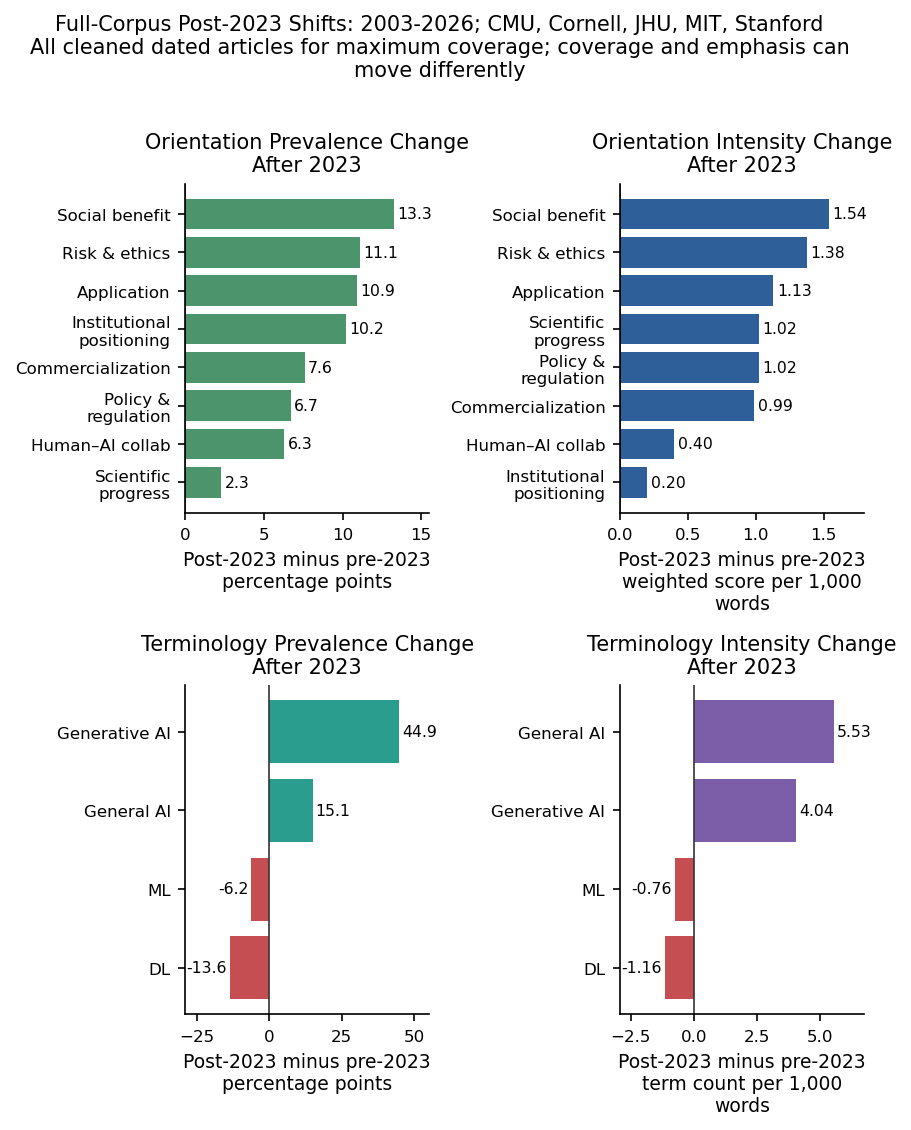

In [27]:
# Figure fig09_prepost_changes.pdf: pre/post-2023 changes in communicative orientations and terminology families, prevalence and intensity
frame_prev_delta_col = "delta_post_minus_pre_frame_article_pct"
frame_int_delta_col = "delta_post_minus_pre_weighted_score_per_1k_words"
term_prev_delta_col = "delta_post_minus_pre_pct"

frame_prev_delta_plot = period_prevalence_delta.sort_values(frame_prev_delta_col, ascending=True).copy()
frame_int_delta_plot = period_intensity_delta.sort_values(frame_int_delta_col, ascending=True).copy()
term_prev_delta_plot = term_period_delta.reset_index().sort_values(term_prev_delta_col, ascending=True).copy()

term_core_period_intensity_delta = period_term_summary.pivot_table(
    index="term_family",
    columns="analysis_period",
    values="term_count_per_1k_words",
)
for col in ["pre_2023", "post_2023"]:
    if col not in term_core_period_intensity_delta.columns:
        term_core_period_intensity_delta[col] = np.nan
term_core_period_intensity_delta["delta_post_minus_pre_intensity"] = (
    term_core_period_intensity_delta["post_2023"] - term_core_period_intensity_delta["pre_2023"]
).round(2)
term_int_delta_plot = term_core_period_intensity_delta.reset_index().sort_values("delta_post_minus_pre_intensity", ascending=True)

fig, axes = plt.subplots(2, 2, figsize=(TEXTWIDTH_IN, 7.4))

def plot_delta_barh(ax, data, label_col, value_col, title, xlabel, positive_color, negative_color=COLORS["red"], fmt="{:.1f}"):
    values = data[value_col]
    colors = [negative_color if x < 0 else positive_color for x in values]
    ax.barh(wrap_labels(data[label_col], 18), values, color=colors)
    ax.axvline(0, color="#333333", linewidth=0.8)
    ax.set_title(wrap_text(title, 30))
    ax.set_xlabel(wrap_text(xlabel, 24))
    ax.set_ylabel("")
    xmin, xmax = ax.get_xlim()
    offset = (xmax - xmin) * 0.015
    for patch in ax.patches:
        width = patch.get_width()
        x = width + (offset if width >= 0 else -offset)
        ha = "left" if width >= 0 else "right"
        ax.text(x, patch.get_y() + patch.get_height() / 2, fmt.format(width), va="center", ha=ha, fontsize=7.5)
    
    ax.figure.canvas.draw()
    inv = ax.transData.inverted()
    extents = [t.get_window_extent() for t in ax.texts]
    label_x = [inv.transform((bb.x0, bb.y0))[0] for bb in extents] + [inv.transform((bb.x1, bb.y1))[0] for bb in extents]
    lo, hi = min(label_x + [xmin]), max(label_x + [xmax])
    
    ax.set_xlim(lo - (hi - lo) * 0.08 if lo < xmin else xmin, hi + (hi - lo) * 0.03 if hi > xmax else xmax)

plot_delta_barh(
    axes[0, 0],
    frame_prev_delta_plot,
    "frame_label",
    frame_prev_delta_col,
    "Orientation Prevalence Change After 2023",
    "Post-2023 minus pre-2023 percentage points",
    COLORS["green"],
    fmt="{:.1f}",
)
plot_delta_barh(
    axes[0, 1],
    frame_int_delta_plot,
    "frame_label",
    frame_int_delta_col,
    "Orientation Intensity Change After 2023",
    "Post-2023 minus pre-2023 weighted score per 1,000 words",
    COLORS["blue"],
    fmt="{:.2f}",
)
plot_delta_barh(
    axes[1, 0],
    term_prev_delta_plot,
    "term_family",
    term_prev_delta_col,
    "Terminology Prevalence Change After 2023",
    "Post-2023 minus pre-2023 percentage points",
    COLORS["teal"],
    fmt="{:.1f}",
)
plot_delta_barh(
    axes[1, 1],
    term_int_delta_plot,
    "term_family",
    "delta_post_minus_pre_intensity",
    "Terminology Intensity Change After 2023",
    "Post-2023 minus pre-2023 term count per 1,000 words",
    COLORS["purple"],
    fmt="{:.2f}",
)

fig.suptitle(
    wrap_text(
        f"Full-Corpus Post-2023 Shifts: {int(analysis_df['year'].min())}-{int(analysis_df['year'].max())}; "
        f"{', '.join(sorted(analysis_df['Institution'].dropna().unique()))}\n"
        "All cleaned dated articles for maximum coverage; coverage and emphasis can move differently",
        78,
    ),
    y=1.01,
)
plt.tight_layout()
save_fig(fig, "fig09_prepost_changes")
plt.show()

### 5.2 Segmented regression anchored at the release

Article-level segmented OLS models with a break in December 2022, institution fixed effects, log article length, and HC3 standard errors, fitted to the full dated corpus and to the core window; FDR-adjusted q-values across all tested coefficients. 

In [28]:
# Article-level segmented regressions: monthly time, post-ChatGPT level, and slope change

BREAK_DATE = pd.Timestamp("2022-12-01")

def prepare_segmented_corpus(source_df):
    """Prepare a dated article corpus for segmented models without discarding schools or years."""
    prepared = source_df.dropna(subset=["published_date", "analysis_word_count"]).copy()
    prepared = prepared.loc[prepared["analysis_word_count"] > 0].copy()
    prepared["month_start"] = prepared["published_date"].dt.to_period("M").dt.to_timestamp()
    origin = prepared["month_start"].min()
    prepared["month_index"] = (
        (prepared["month_start"].dt.year - origin.year) * 12
        + prepared["month_start"].dt.month - origin.month
    ).astype(float)
    prepared["post_chatgpt"] = (prepared["published_date"] >= BREAK_DATE).astype(int)
    break_month_index = (BREAK_DATE.year - origin.year) * 12 + BREAK_DATE.month - origin.month
    prepared["months_after_chatgpt"] = np.maximum(0, prepared["month_index"] - break_month_index)
    prepared["log_words"] = np.log1p(prepared["analysis_word_count"])
    return prepared

# Keep the prior balanced recent window as a robustness specification, while
# making the full cleaned corpus (all schools and all valid dates) the primary analysis.
segmented_core_df = prepare_segmented_corpus(core_analysis_df)
segmented_full_df = prepare_segmented_corpus(analysis_df)

frame_intensity_wide = frame_article_scores.pivot_table(
    index="article_id", columns="frame_label", values="weighted_rate_per_1k", aggfunc="sum", fill_value=0
)
term_intensity_wide = term_article_scores.pivot_table(
    index="article_id", columns="term_family", values="term_rate_per_1k", aggfunc="sum", fill_value=0
)
segmented_core_df = segmented_core_df.merge(frame_intensity_wide, left_on="article_id", right_index=True, how="left")
segmented_core_df = segmented_core_df.merge(term_intensity_wide, left_on="article_id", right_index=True, how="left", suffixes=("", "__term"))
segmented_full_df = segmented_full_df.merge(frame_intensity_wide, left_on="article_id", right_index=True, how="left")
segmented_full_df = segmented_full_df.merge(term_intensity_wide, left_on="article_id", right_index=True, how="left", suffixes=("", "__term"))


segment_outcomes = []
for label in frame_article_scores["frame_label"].drop_duplicates().tolist():
    if label in segmented_full_df.columns:
        segment_outcomes.append((label, "communicative orientation intensity"))
for label in term_article_scores["term_family"].drop_duplicates().tolist():
    if label in segmented_full_df.columns:
        segment_outcomes.append((label, "AI terminology intensity"))

full_year_range = f"{int(segmented_full_df['year'].min())}-{int(segmented_full_df['year'].max())}"
full_school_label = "/".join(sorted(segmented_full_df["Institution"].dropna().unique()))
segmented_corpus_variants = {
    f"Full corpus: {full_year_range}; {full_school_label} (maximum temporal and school coverage)": segmented_full_df,
    f"Core robustness: {CORE_START_YEAR}-{CORE_END_YEAR}; {'/'.join(CORE_INSTITUTIONS)} (more balanced recent coverage)": segmented_core_df,
}

segmented_results_rows = []
segmented_models = {}  
segmented_models_by_corpus = {}
formula_template = "Q('{outcome}') ~ month_index + post_chatgpt + months_after_chatgpt + C(Institution) + log_words"
for corpus_label, corpus_df in segmented_corpus_variants.items():
    for outcome, measure_type in segment_outcomes:
        model_data = corpus_df[[outcome, "month_index", "post_chatgpt", "months_after_chatgpt", "Institution", "log_words"]].dropna()
        if len(model_data) < 50 or model_data[outcome].nunique() < 2:
            continue
        try:
            fitted = smf.ols(formula_template.format(outcome=outcome.replace("'", "\'")), data=model_data).fit(cov_type="HC3")
            segmented_models_by_corpus[(corpus_label, measure_type, outcome)] = fitted
            if corpus_label.startswith("Full corpus"):
                segmented_models[(measure_type, outcome)] = fitted
            for term, meaning in [
                ("month_index", "Pre-break monthly trend"),
                ("post_chatgpt", "Immediate level difference at breakpoint"),
                ("months_after_chatgpt", "Post-break monthly slope change"),
            ]:
                ci = fitted.conf_int().loc[term]
                segmented_results_rows.append({
                    "corpus": corpus_label,
                    "measure_type": measure_type,
                    "outcome": outcome,
                    "parameter": term,
                    "interpretation": meaning,
                    "n_articles": int(fitted.nobs),
                    "coefficient": fitted.params[term],
                    "ci_low": ci.iloc[0],
                    "ci_high": ci.iloc[1],
                    "p_value": fitted.pvalues[term],
                    "r_squared": fitted.rsquared,
                })
        except Exception as exc:
            print(f"Segmented model failed for {corpus_label} | {outcome}: {exc}")

segmented_trend_results = pd.DataFrame(segmented_results_rows)
if not segmented_trend_results.empty:
    segmented_trend_results["q_value"] = multipletests(segmented_trend_results["p_value"], method="fdr_bh")[1]
    display(segmented_trend_results.sort_values(["corpus", "measure_type", "outcome", "parameter"]).round({
        "coefficient": 3, "ci_low": 3, "ci_high": 3, "p_value": 4, "q_value": 4, "r_squared": 3
    }))

# Downstream month-by-month scan and fitted-trend visualizations use the full
# corpus as the primary specification; the core-window coefficients remain above.
segmented_df = segmented_full_df
print("Segmented-regression corpus variants:")
for corpus_label, corpus_df in segmented_corpus_variants.items():
    print(f"- {corpus_label}: {len(corpus_df):,} articles")
print(f"Breakpoint: {BREAK_DATE.date()}; outcomes: {len(frame_article_scores['frame_label'].unique())} communicative orientations + {len(term_article_scores['term_family'].unique())} AI terminology families.")
print("Coefficient interpretation: month_index is the pre-break trend; post_chatgpt is the discontinuity; months_after_chatgpt is the change in slope after the breakpoint.")

,corpus,measure_type,outcome,parameter,interpretation,n_articles,coefficient,ci_low,ci_high,p_value,r_squared,q_value
66,Core robustness: 2021-2025; CMU/JHU/MIT/Stanford (more balanced recent coverage),AI terminology intensity,DL,month_index,Pre-break monthly trend,1290,-0.013,-0.073,0.046,0.6601,0.031,0.8195
68,Core robustness: 2021-2025; CMU/JHU/MIT/Stanford (more balanced recent coverage),AI terminology intensity,DL,months_after_chatgpt,Post-break monthly slope change,1290,0.000,-0.063,0.063,0.9908,0.031,0.9994
67,Core robustness: 2021-2025; CMU/JHU/MIT/Stanford (more balanced recent coverage),AI terminology intensity,DL,post_chatgpt,Immediate level difference at breakpoint,1290,-0.290,-1.147,0.566,0.5063,0.031,0.7594
60,Core robustness: 2021-2025; CMU/JHU/MIT/Stanford (more balanced recent coverage),AI terminology intensity,General AI,month_index,Pre-break monthly trend,1290,-0.009,-0.158,0.139,0.9009,0.153,0.9682
62,Core robustness: 2021-2025; CMU/JHU/MIT/Stanford (more balanced recent coverage),AI terminology intensity,General AI,months_after_chatgpt,Post-break monthly slope change,1290,0.074,-0.086,0.235,0.3633,0.153,0.5972
...,...,...,...,...,...,...,...,...,...,...,...,...
2,Full corpus: 2003-2026; CMU/Cornell/JHU/MIT/Stanford (maximum temporal and school coverage),communicative orientation intensity,Scientific progress,months_after_chatgpt,Post-break monthly slope change,2231,-0.154,-0.220,-0.088,0.0000,0.092,0.0000
1,Full corpus: 2003-2026; CMU/Cornell/JHU/MIT/Stanford (maximum temporal and school coverage),communicative orientation intensity,Scientific progress,post_chatgpt,Immediate level difference at breakpoint,2231,3.363,1.216,5.510,0.0021,0.092,0.0096
9,Full corpus: 2003-2026; CMU/Cornell/JHU/MIT/Stanford (maximum temporal and school coverage),communicative orientation intensity,Social benefit,month_index,Pre-break monthly trend,2231,0.038,0.028,0.048,0.0000,0.038,0.0000
11,Full corpus: 2003-2026; CMU/Cornell/JHU/MIT/Stanford (maximum temporal and school coverage),communicative orientation intensity,Social benefit,months_after_chatgpt,Post-break monthly slope change,2231,-0.049,-0.098,0.001,0.0538,0.038,0.1382


Segmented-regression corpus variants:
- Full corpus: 2003-2026; CMU/Cornell/JHU/MIT/Stanford (maximum temporal and school coverage): 2,231 articles
- Core robustness: 2021-2025; CMU/JHU/MIT/Stanford (more balanced recent coverage): 1,290 articles
Breakpoint: 2022-12-01; outcomes: 8 communicative orientations + 4 AI terminology families.
Coefficient interpretation: month_index is the pre-break trend; post_chatgpt is the discontinuity; months_after_chatgpt is the change in slope after the breakpoint.


In [29]:
# Level (post_chatgpt) and slope (months_after_chatgpt) changes at the breakpoint, for both corpora,
# sorted by q-value with an FDR flag. 
if segmented_trend_results.empty:
    print("No segmented-regression results were estimated.")
else:
    segmented_key_results = segmented_trend_results.loc[
        segmented_trend_results["parameter"].isin(["post_chatgpt", "months_after_chatgpt"])
    ].copy()
    segmented_key_results["evidence_after_fdr"] = np.where(
        segmented_key_results["q_value"] < 0.05, "q < .05", "not robust after FDR"
    )
    display(segmented_key_results.sort_values(["q_value", "measure_type", "outcome", "parameter"]).round({
        "coefficient": 3, "ci_low": 3, "ci_high": 3, "p_value": 4, "q_value": 4, "r_squared": 3
    }))

,corpus,measure_type,outcome,parameter,interpretation,n_articles,coefficient,ci_low,ci_high,p_value,r_squared,q_value,evidence_after_fdr
34,Full corpus: 2003-2026; CMU/Cornell/JHU/MIT/Stanford (maximum temporal and school coverage),AI terminology intensity,Generative AI,post_chatgpt,Immediate level difference at breakpoint,2231,4.941,3.874,6.007,0.0000,0.117,0.0000,q < .05
70,Core robustness: 2021-2025; CMU/JHU/MIT/Stanford (more balanced recent coverage),AI terminology intensity,Generative AI,post_chatgpt,Immediate level difference at breakpoint,1290,4.188,2.916,5.460,0.0000,0.076,0.0000,q < .05
29,Full corpus: 2003-2026; CMU/Cornell/JHU/MIT/Stanford (maximum temporal and school coverage),AI terminology intensity,ML,months_after_chatgpt,Post-break monthly slope change,2231,-0.055,-0.072,-0.038,0.0000,0.055,0.0000,q < .05
2,Full corpus: 2003-2026; CMU/Cornell/JHU/MIT/Stanford (maximum temporal and school coverage),communicative orientation intensity,Scientific progress,months_after_chatgpt,Post-break monthly slope change,2231,-0.154,-0.220,-0.088,0.0000,0.092,0.0000,q < .05
32,Full corpus: 2003-2026; CMU/Cornell/JHU/MIT/Stanford (maximum temporal and school coverage),AI terminology intensity,DL,months_after_chatgpt,Post-break monthly slope change,2231,-0.030,-0.043,-0.017,0.0000,0.049,0.0000,q < .05
41,Core robustness: 2021-2025; CMU/JHU/MIT/Stanford (more balanced recent coverage),communicative orientation intensity,Application,months_after_chatgpt,Post-break monthly slope change,1290,0.210,0.103,0.318,0.0001,0.027,0.0007,q < .05
31,Full corpus: 2003-2026; CMU/Cornell/JHU/MIT/Stanford (maximum temporal and school coverage),AI terminology intensity,DL,post_chatgpt,Immediate level difference at breakpoint,2231,-0.995,-1.515,-0.474,0.0002,0.049,0.0009,q < .05
38,Core robustness: 2021-2025; CMU/JHU/MIT/Stanford (more balanced recent coverage),communicative orientation intensity,Scientific progress,months_after_chatgpt,Post-break monthly slope change,1290,-0.391,-0.628,-0.153,0.0013,0.079,0.0061,q < .05
1,Full corpus: 2003-2026; CMU/Cornell/JHU/MIT/Stanford (maximum temporal and school coverage),communicative orientation intensity,Scientific progress,post_chatgpt,Immediate level difference at breakpoint,2231,3.363,1.216,5.510,0.0021,0.092,0.0096,q < .05
65,Core robustness: 2021-2025; CMU/JHU/MIT/Stanford (more balanced recent coverage),AI terminology intensity,ML,months_after_chatgpt,Post-break monthly slope change,1290,-0.081,-0.148,-0.015,0.0166,0.044,0.0545,not robust after FDR


### 5.3 Breakpoint scan

The segmented model is refitted at every candidate break month of the full corpus (two-year buffer at each edge) and compared by AIC; the scan reports the data-preferred month and the AIC penalty of forcing the break to December 2022. The yearly scan is repeated for all schools and for MIT only as a composition check. 


,measure_type,outcome,best_break,months_from_chatgpt_break,aic_at_best,aic_at_chatgpt_break,delta_aic_chatgpt_minus_best
0,AI terminology intensity,Generative AI,2023-02-01,2,14200.1,14201.0,0.84
1,AI terminology intensity,ML,2023-06-01,6,11444.4,11446.7,2.32
2,AI terminology intensity,DL,2019-03-01,-45,11568.8,11593.7,24.85
3,AI terminology intensity,General AI,2019-03-01,-45,16142.1,16145.1,2.98
4,communicative orientation intensity,Application,2022-01-01,-11,14328.2,14336.0,7.81
5,communicative orientation intensity,Scientific progress,2021-12-01,-12,17427.4,17437.8,10.39
6,communicative orientation intensity,Policy & regulation,2021-07-01,-17,14500.1,14501.9,1.83
7,communicative orientation intensity,Commercialization,2024-06-01,18,14623.5,14628.6,5.12
8,communicative orientation intensity,Institutional positioning,2018-10-01,-50,17403.9,17418.3,14.42
9,communicative orientation intensity,Risk & ethics,2018-10-01,-50,15468.7,15470.7,2.07


Interpretation: months_from_chatgpt_break = 0 means the data-chosen breakpoint coincides with ChatGPT's release.
delta_aic_chatgpt_minus_best <= 2 is conventionally 'essentially equivalent fit'; large values mean the best break is clearly elsewhere.


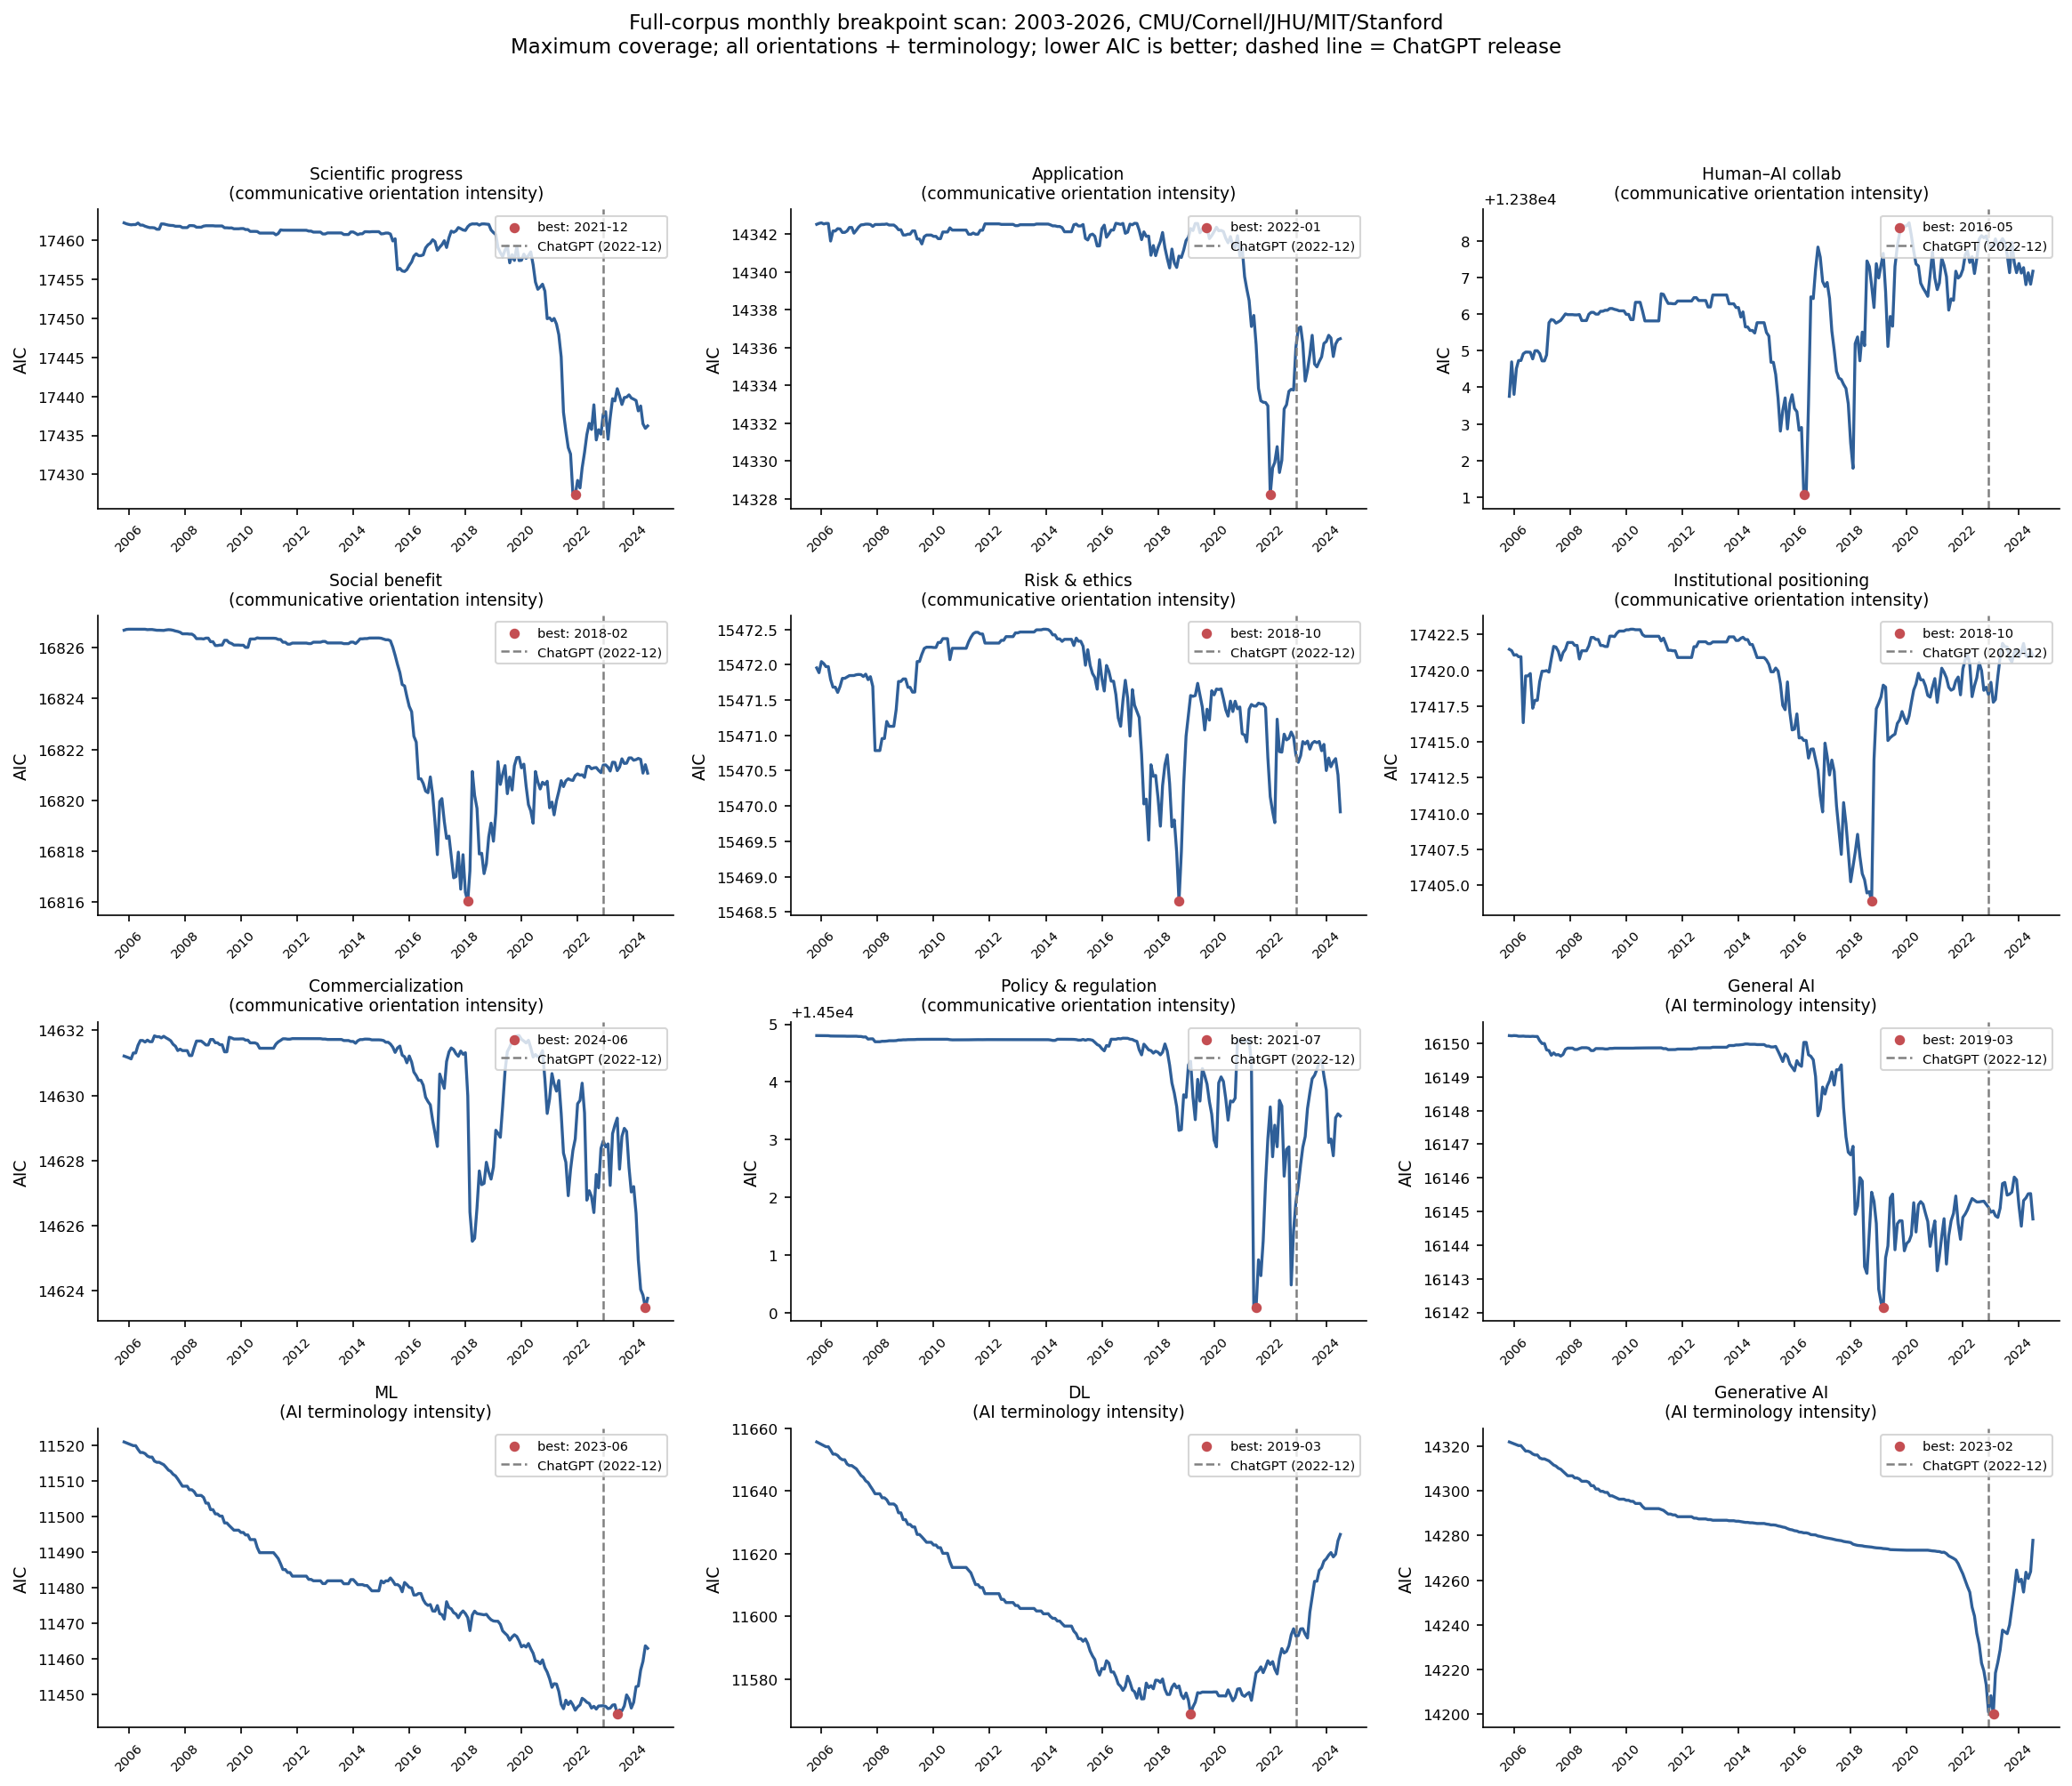

In [30]:
# Breakpoint scan: refit the segmented model at every candidate break month and compare AIC.
# Reuses segmented_df and segment_outcomes from the fixed-breakpoint cell above.


segmented_origin = segmented_df["month_start"].min()
scan_start = segmented_origin + pd.DateOffset(years=2)
scan_end = segmented_df["month_start"].max() - pd.DateOffset(years=2)
candidate_breaks = pd.date_range(scan_start, scan_end, freq="MS")

CHATGPT_BREAK = pd.Timestamp("2022-12-01")

scan_formula_template = (
    "Q('{outcome}') ~ month_index + post_break + months_after_break + C(Institution) + log_words"
)

breakpoint_scan_rows = []
for outcome, measure_type in segment_outcomes:
    base_cols = [outcome, "month_index", "published_date", "Institution", "log_words"]
    model_data_base = segmented_df[base_cols].dropna()
    if len(model_data_base) < 50 or model_data_base[outcome].nunique() < 2:
        continue
    for tau in candidate_breaks:
        model_data = model_data_base.copy()
        tau_month_index = (tau.year - segmented_origin.year) * 12 + tau.month - segmented_origin.month
        model_data["post_break"] = (model_data["published_date"] >= tau).astype(int)
        model_data["months_after_break"] = np.maximum(0, model_data["month_index"] - tau_month_index)
        try:
            fitted = smf.ols(
                scan_formula_template.format(outcome=outcome.replace("'", "\\'")),
                data=model_data,
            ).fit()
            breakpoint_scan_rows.append({
                "measure_type": measure_type,
                "outcome": outcome,
                "candidate_break": tau,
                "aic": fitted.aic,
                "n_articles": int(fitted.nobs),
            })
        except Exception as exc:
            print(f"Scan failed for {outcome} @ {tau.date()}: {exc}")

breakpoint_scan = pd.DataFrame(breakpoint_scan_rows)

# Best break per outcome = AIC minimum; also record the AIC gap to the ChatGPT break.
best_break_rows = []
for (measure_type, outcome), grp in breakpoint_scan.groupby(["measure_type", "outcome"]):
    grp = grp.sort_values("candidate_break").reset_index(drop=True)
    best_row = grp.loc[grp["aic"].idxmin()]
    chatgpt_row = grp.loc[grp["candidate_break"] == CHATGPT_BREAK]
    aic_at_chatgpt = float(chatgpt_row["aic"].iloc[0]) if not chatgpt_row.empty else np.nan
    months_from_chatgpt = (
        (best_row["candidate_break"].year - CHATGPT_BREAK.year) * 12
        + (best_row["candidate_break"].month - CHATGPT_BREAK.month)
    )
    best_break_rows.append({
        "measure_type": measure_type,
        "outcome": outcome,
        "best_break": best_row["candidate_break"].date(),
        "months_from_chatgpt_break": months_from_chatgpt,
        "aic_at_best": round(float(best_row["aic"]), 1),
        "aic_at_chatgpt_break": round(aic_at_chatgpt, 1),
        "delta_aic_chatgpt_minus_best": round(aic_at_chatgpt - float(best_row["aic"]), 2),
    })

breakpoint_scan_summary = (
    pd.DataFrame(best_break_rows)
    .sort_values(["measure_type", "months_from_chatgpt_break"], key=lambda s: s.abs() if s.name == "months_from_chatgpt_break" else s)
    .reset_index(drop=True)
)
display(breakpoint_scan_summary)
print("Interpretation: months_from_chatgpt_break = 0 means the data-chosen breakpoint coincides with ChatGPT's release.")
print("delta_aic_chatgpt_minus_best <= 2 is conventionally 'essentially equivalent fit'; large values mean the best break is clearly elsewhere.")

# --- AIC curves: one panel per outcome, vertical line at the ChatGPT release ---
outcomes_to_plot = breakpoint_scan[["measure_type", "outcome"]].drop_duplicates().values.tolist()
n_panels = len(outcomes_to_plot)
n_cols = 3
n_rows = int(np.ceil(n_panels / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.2 * n_cols, 3.4 * n_rows), squeeze=False)

for ax_idx, (measure_type, outcome) in enumerate(outcomes_to_plot):
    ax = axes[ax_idx // n_cols][ax_idx % n_cols]
    grp = breakpoint_scan.loc[
        (breakpoint_scan["measure_type"] == measure_type) & (breakpoint_scan["outcome"] == outcome)
    ].sort_values("candidate_break")
    ax.plot(grp["candidate_break"], grp["aic"], lw=1.6, color="#2F5F98")
    best = grp.loc[grp["aic"].idxmin()]
    ax.scatter([best["candidate_break"]], [best["aic"]], color="#C44E52", zorder=5,
               label=f"best: {best['candidate_break'].strftime('%Y-%m')}")
    ax.axvline(CHATGPT_BREAK, color="gray", ls="--", lw=1.2, label="ChatGPT (2022-12)")
    ax.set_title(f"{outcome}\n({measure_type})", fontsize=9)
    ax.set_ylabel("AIC")
    ax.legend(fontsize=7, loc="upper right")
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)

for ax_idx in range(n_panels, n_rows * n_cols):
    axes[ax_idx // n_cols][ax_idx % n_cols].axis("off")

fig.suptitle(f"Full-corpus monthly breakpoint scan: {full_year_range}, {full_school_label}\n"
             "Maximum coverage; all orientations + terminology; lower AIC is better; dashed line = ChatGPT release",
             fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

In [31]:
# Run both scan variants and collect results side by side
full_scan_all_rows = []

for scan_label, scan_institutions in [
    ("All schools — primary full corpus", None),
    ("MIT only — constant-composition sensitivity", ["MIT"]),
]:
    full_scan_df = analysis_df.dropna(subset=["published_date", "analysis_word_count"]).copy()
    full_scan_df = full_scan_df.loc[full_scan_df["analysis_word_count"] > 0]
    if scan_institutions is not None:
        full_scan_df = full_scan_df.loc[full_scan_df["Institution"].isin(scan_institutions)].copy()

    full_start_year = int(full_scan_df["published_date"].dt.year.min())
    full_end_year = int(full_scan_df["published_date"].dt.year.max())
    full_scan_df["month_index"] = (
        (full_scan_df["published_date"].dt.year - full_start_year) * 12
        + full_scan_df["published_date"].dt.month - 1
    ).astype(float)
    full_scan_df["log_words"] = np.log1p(full_scan_df["analysis_word_count"])
    full_scan_df = full_scan_df.merge(frame_intensity_wide, left_on="article_id", right_index=True, how="left")
    full_scan_df = full_scan_df.merge(term_intensity_wide, left_on="article_id", right_index=True,
                                      how="left", suffixes=("", "__term"))

    yearly_breaks = [pd.Timestamp(f"{y}-01-01")
                     for y in range(full_start_year + 3, full_end_year - 3 + 1)]
    multi_school = full_scan_df["Institution"].nunique() > 1
    inst_term = " + C(Institution)" if multi_school else ""
    tmpl = "Q('{outcome}') ~ month_index + post_break + months_after_break" + inst_term + " + log_words"

    for outcome, measure_type in segment_outcomes:
        if outcome not in full_scan_df.columns:
            continue
        base = full_scan_df[[outcome, "month_index", "published_date", "Institution", "log_words"]].dropna()
        if len(base) < 100 or base[outcome].nunique() < 2:
            continue
        for tau in yearly_breaks:
            md = base.copy()
            tau_idx = (tau.year - full_start_year) * 12 + tau.month - 1
            md["post_break"] = (md["published_date"] >= tau).astype(int)
            md["months_after_break"] = np.maximum(0, md["month_index"] - tau_idx)
            try:
                fitted = smf.ols(tmpl.format(outcome=outcome.replace("'", "\\'")), data=md).fit()
                full_scan_all_rows.append({
                    "scan_variant": scan_label, "measure_type": measure_type, "outcome": outcome,
                    "candidate_break_year": tau.year, "aic": fitted.aic, "n_articles": int(fitted.nobs),
                })
            except Exception as exc:
                print(f"[{scan_label}] Failed {outcome} @ {tau.year}: {exc}")

full_breakpoint_scan_both = pd.DataFrame(full_scan_all_rows)

# Best break per outcome per variant, pivoted for direct comparison
full_best_both = (
    full_breakpoint_scan_both
    .loc[full_breakpoint_scan_both.groupby(["scan_variant", "measure_type", "outcome"])["aic"].idxmin()]
    .pivot_table(index=["measure_type", "outcome"], columns="scan_variant",
                 values="candidate_break_year", aggfunc="first")
    .reset_index()
)
display(full_best_both)
print("Columns show the data-chosen break year under each corpus variant; "
      "agreement between the two columns indicates the break is not an artifact of corpus composition.")

scan_variant,measure_type,outcome,All schools — primary full corpus,MIT only — constant-composition sensitivity
0,AI terminology intensity,DL,2021,2021
1,AI terminology intensity,General AI,2019,2019
2,AI terminology intensity,Generative AI,2023,2023
3,AI terminology intensity,ML,2022,2022
4,communicative orientation intensity,Application,2022,2022
5,communicative orientation intensity,Commercialization,2019,2017
6,communicative orientation intensity,Human–AI collab,2018,2018
7,communicative orientation intensity,Institutional positioning,2018,2018
8,communicative orientation intensity,Policy & regulation,2023,2020
9,communicative orientation intensity,Risk & ethics,2018,2018


Columns show the data-chosen break year under each corpus variant; agreement between the two columns indicates the break is not an artifact of corpus composition.


Saved figures/fig11_breakpoint_timeline.pdf


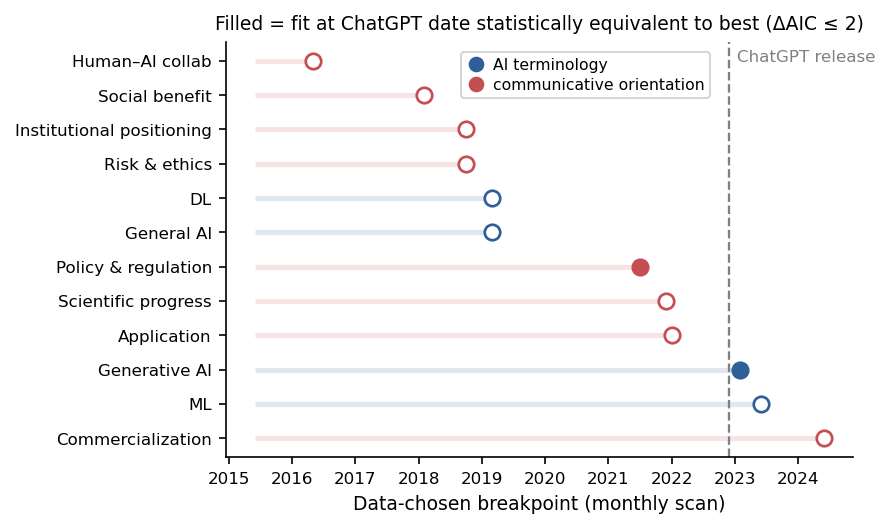

In [32]:
# Figure fig11_breakpoint_timeline.pdf: data-chosen break per outcome vs the ChatGPT release

summary = breakpoint_scan_summary.copy()
summary["best_break"] = pd.to_datetime(summary["best_break"])
summary["equivalent"] = summary["delta_aic_chatgpt_minus_best"] <= 2
# Sort by break date; earliest at the top 
summary = summary.sort_values("best_break").reset_index(drop=True)

colors = {
    "AI terminology intensity": "#2F5F98",
    "communicative orientation intensity": "#C44E52",
}

fig, ax = plt.subplots(figsize=(TEXTWIDTH_IN, 3.6))

for i, row in summary.iterrows():
    c = colors[row["measure_type"]]
    ax.scatter(row["best_break"], i, s=55,
               facecolor=c if row["equivalent"] else "white",
               edgecolor=c, linewidth=1.3, zorder=5)
    ax.hlines(i, pd.Timestamp("2015-06-01"), row["best_break"],
              color=c, alpha=0.15, lw=2.5)

ax.invert_yaxis()  # earliest break at the top

# ChatGPT reference line
ax.axvline(pd.Timestamp("2022-11-30"), color="gray", ls="--", lw=1.1)
ax.text(pd.Timestamp("2023-01-15"), -0.1, "ChatGPT release",
        color="gray", fontsize=8, ha="left", va="center")

ax.set_yticks(range(len(summary)))
ax.set_yticklabels(summary["outcome"])
ax.set_xlabel("Data-chosen breakpoint (monthly scan)")
ax.set_title("Filled = fit at ChatGPT date statistically equivalent to best (\u0394AIC \u2264 2)", fontsize=9)

ax.legend(
    handles=[
        Line2D([0], [0], marker="o", color="w", markerfacecolor=v,
               markeredgecolor=v, markersize=6.5, label=k.replace(" intensity", ""))
        for k, v in colors.items()
    ],
    loc="upper right",
    bbox_to_anchor=(0.785, 0.995),   # sits right of the 2016-2019 break points and left of the ChatGPT line
    fontsize=7.5, handlelength=1.2, handletextpad=0.5, borderpad=0.35, labelspacing=0.3,
)

fig.tight_layout()
save_fig(fig, "fig11_breakpoint_timeline")
plt.show()

### 5.4 Cue-level lexical change

Article prevalence of every terminology cue and orientation cue before and after 2022 (percentage-point difference and log2 odds ratio with a 0.5 continuity correction; ranked cues must appear in at least five articles in the period toward which they move); `fig10_cue_level_shifts.pdf`.


In [33]:
# Cue-level change after 2023: which concrete terms became more/less common?

cue_entries = []
seen_cue_source = set()

for family, compiled_cues in compiled_term_families.items():
    for cue, pattern in compiled_cues:
        key = (cue_key(cue), "term_family", family)
        if key not in seen_cue_source:
            seen_cue_source.add(key)
            cue_entries.append({"cue": cue, "source_type": "term_family", "source_label": family, "pattern": pattern})

for frame_id, compiled in compiled_frames.items():
    for cue_type in ["strong", "weak"]:
        for cue, pattern in compiled[cue_type]:
            key = (cue_key(cue), cue_type, frame_id)
            if key not in seen_cue_source:
                seen_cue_source.add(key)
                cue_entries.append({"cue": cue, "source_type": f"orientation_{cue_type}", "source_label": compiled["label"], "pattern": pattern})

period_base = analysis_df.loc[
    analysis_df["analysis_period"].isin(["pre_2023", "post_2023"]),
    ["article_id", "analysis_period", "analysis_text_lower"],
].copy()
period_base["analysis_text_lower"] = period_base["analysis_text_lower"].fillna("").astype(str)
period_article_totals = period_base.groupby("analysis_period")["article_id"].nunique().to_dict()

cue_rows = []
texts = period_base["analysis_text_lower"]
for entry in cue_entries:
    counts = texts.str.count(entry["pattern"])
    matched = period_base.loc[counts > 0, ["article_id", "analysis_period"]].copy()
    if matched.empty:
        continue
    matched["cue"] = entry["cue"]
    matched["source_type"] = entry["source_type"]
    matched["source_label"] = entry["source_label"]
    matched["count"] = counts.loc[matched.index].astype(int).values
    cue_rows.append(matched)

cue_article_counts = pd.concat(cue_rows, ignore_index=True) if cue_rows else pd.DataFrame()
if not cue_article_counts.empty:
    cue_period = (
        cue_article_counts.groupby(["cue", "source_type", "source_label", "analysis_period"], as_index=False)
        .agg(
            cue_articles=("article_id", "nunique"),
            cue_count=("count", "sum"),
        )
    )
    cue_period["period_total_articles"] = cue_period["analysis_period"].map(period_article_totals)
    cue_period["cue_article_pct"] = cue_period["cue_articles"] / cue_period["period_total_articles"] * 100

    cue_shift = cue_period.pivot_table(
        index=["cue", "source_type", "source_label"],
        columns="analysis_period",
        values=["cue_articles", "cue_article_pct", "cue_count"],
        fill_value=0,
    )
    cue_shift.columns = ["__".join(col).strip("_") for col in cue_shift.columns.to_flat_index()]
    cue_shift = cue_shift.reset_index()

    for metric in ["cue_articles", "cue_article_pct", "cue_count"]:
        for period in ["pre_2023", "post_2023"]:
            col = f"{metric}__{period}"
            if col not in cue_shift.columns:
                cue_shift[col] = 0

    cue_shift["delta_post_minus_pre_pct"] = cue_shift["cue_article_pct__post_2023"] - cue_shift["cue_article_pct__pre_2023"]
    pre_total = period_article_totals.get("pre_2023", 0)
    post_total = period_article_totals.get("post_2023", 0)
    cue_shift["log2_odds_ratio_post_vs_pre"] = cue_shift.apply(
        lambda r: math.log2(
            ((r["cue_articles__post_2023"] + 0.5) / max(post_total - r["cue_articles__post_2023"] + 0.5, 0.5)) /
            ((r["cue_articles__pre_2023"] + 0.5) / max(pre_total - r["cue_articles__pre_2023"] + 0.5, 0.5))
        ) if pre_total and post_total else np.nan,
        axis=1,
    )

    print("Concrete cues most increased after 2023 (minimum 5 post-2023 articles):")
    display(
        cue_shift.loc[cue_shift["cue_articles__post_2023"] >= 5]
        .sort_values(["delta_post_minus_pre_pct", "log2_odds_ratio_post_vs_pre"], ascending=False)
        [[
            "cue", "source_type", "source_label",
            "cue_articles__pre_2023", "cue_article_pct__pre_2023",
            "cue_articles__post_2023", "cue_article_pct__post_2023",
            "delta_post_minus_pre_pct", "log2_odds_ratio_post_vs_pre",
        ]]
        .round(2)
        .head(25)
    )

    print("Concrete cues most decreased after 2023 (minimum 5 pre-2023 articles):")
    display(
        cue_shift.loc[cue_shift["cue_articles__pre_2023"] >= 5]
        .sort_values(["delta_post_minus_pre_pct", "log2_odds_ratio_post_vs_pre"], ascending=True)
        [[
            "cue", "source_type", "source_label",
            "cue_articles__pre_2023", "cue_article_pct__pre_2023",
            "cue_articles__post_2023", "cue_article_pct__post_2023",
            "delta_post_minus_pre_pct", "log2_odds_ratio_post_vs_pre",
        ]]
        .round(2)
        .head(25)
    )
else:
    print("No cue-level matches found for pre/post-2023 comparison.")

Concrete cues most increased after 2023 (minimum 5 post-2023 articles):


,cue,source_type,source_label,cue_articles__pre_2023,cue_article_pct__pre_2023,cue_articles__post_2023,cue_article_pct__post_2023,delta_post_minus_pre_pct,log2_odds_ratio_post_vs_pre
2,AI,term_family,General AI,455.0,47.00,1088.0,86.14,39.14,2.81
286,language models,term_family,Generative AI,12.0,1.24,282.0,22.33,21.09,4.46
216,generative AI,term_family,Generative AI,0.0,0.00,246.0,19.48,19.48,8.87
288,large language models,term_family,Generative AI,2.0,0.21,246.0,19.48,19.27,6.55
317,models,orientation_weak,Scientific progress,349.0,36.05,698.0,55.27,19.21,1.13
442,tools,orientation_weak,Application,245.0,25.31,553.0,43.78,18.47,1.20
405,school,orientation_weak,Institutional positioning,282.0,29.13,600.0,47.51,18.37,1.14
4,ChatGPT,term_family,Generative AI,1.0,0.10,172.0,13.62,13.52,6.67
19,LLMs,term_family,Generative AI,1.0,0.10,157.0,12.43,12.33,6.52
18,LLM,term_family,Generative AI,1.0,0.10,139.0,11.01,10.90,6.32


Concrete cues most decreased after 2023 (minimum 5 pre-2023 articles):


,cue,source_type,source_label,cue_articles__pre_2023,cue_article_pct__pre_2023,cue_articles__post_2023,cue_article_pct__post_2023,delta_post_minus_pre_pct,log2_odds_ratio_post_vs_pre
283,laboratory,orientation_weak,Institutional positioning,431.0,44.52,370.0,29.30,-15.23,-0.95
63,algorithms,orientation_weak,Scientific progress,330.0,34.09,272.0,21.54,-12.55,-0.91
320,neural network,term_family,DL,166.0,17.15,99.0,7.84,-9.31,-1.28
321,neural networks,term_family,DL,155.0,16.01,92.0,7.28,-8.73,-1.28
163,deep learning,term_family,DL,169.0,17.46,113.0,8.95,-8.51,-1.10
61,algorithm,orientation_weak,Scientific progress,231.0,23.86,201.0,15.91,-7.95,-0.73
305,machine learning,term_family,ML,468.0,48.35,526.0,41.65,-6.70,-0.39
370,recognition,orientation_weak,Scientific progress,156.0,16.12,119.0,9.42,-6.69,-0.88
98,autonomous,orientation_weak,Application,169.0,17.46,152.0,12.03,-5.42,-0.63
126,classification,orientation_weak,Scientific progress,67.0,6.92,38.0,3.01,-3.91,-1.25


Saved figures/fig10_cue_level_shifts.pdf


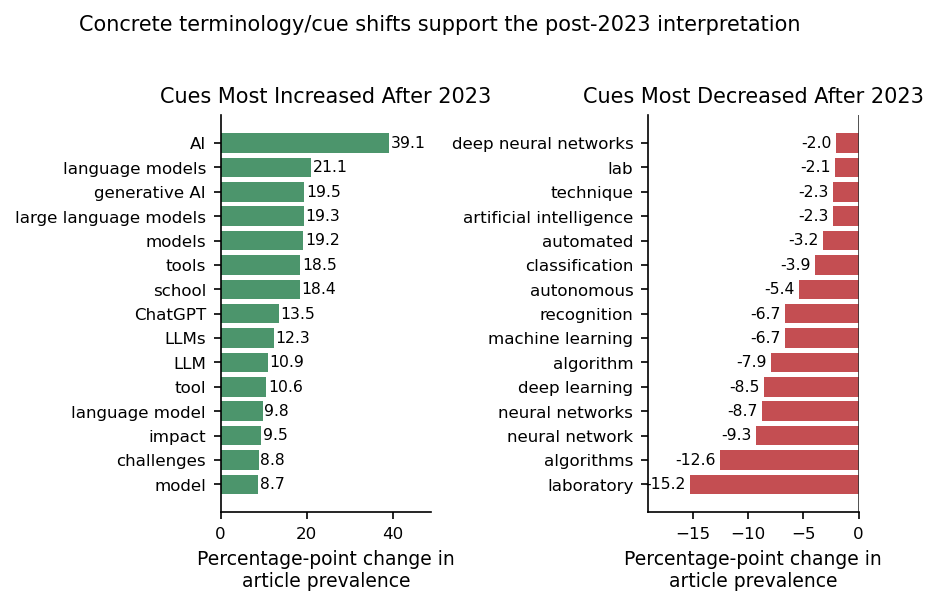

In [34]:
# Figure fig10_cue_level_shifts.pdf: concrete cue shifts after 2023
if "cue_shift" in globals() and not cue_shift.empty:
    increase_plot = (
        cue_shift.loc[cue_shift["cue_articles__post_2023"] >= 5]
        .sort_values(["delta_post_minus_pre_pct", "log2_odds_ratio_post_vs_pre"], ascending=False)
        .head(15)
        .sort_values("delta_post_minus_pre_pct", ascending=True)
        .copy()
    )
    decrease_plot = (
        cue_shift.loc[cue_shift["cue_articles__pre_2023"] >= 5]
        .sort_values(["delta_post_minus_pre_pct", "log2_odds_ratio_post_vs_pre"], ascending=True)
        .head(15)
        .sort_values("delta_post_minus_pre_pct", ascending=True)
        .copy()
    )

    fig, axes = plt.subplots(1, 2, figsize=(TEXTWIDTH_IN, 3.9))
    axes[0].barh(increase_plot["cue"], increase_plot["delta_post_minus_pre_pct"], color=COLORS["green"])
    axes[0].set_title("Cues Most Increased After 2023")
    axes[0].set_xlabel(wrap_text("Percentage-point change in article prevalence", 26))
    axes[0].set_ylabel("")
    annotate_barh(axes[0], fmt="{:.1f}", pad=0)
    axes[0].set_xlim(0, increase_plot["delta_post_minus_pre_pct"].max() * 1.25)

    axes[1].barh(decrease_plot["cue"], decrease_plot["delta_post_minus_pre_pct"], color=COLORS["red"])
    axes[1].axvline(0, color="#333333", linewidth=0.8)
    axes[1].set_title("Cues Most Decreased After 2023")
    axes[1].set_xlabel(wrap_text("Percentage-point change in article prevalence", 26))
    axes[1].set_ylabel("")
    xmin = decrease_plot["delta_post_minus_pre_pct"].min() * 1.25
    axes[1].set_xlim(xmin, 0)
    for patch in axes[1].patches:
        width = patch.get_width()
        axes[1].text(width - abs(xmin) * 0.02, patch.get_y() + patch.get_height() / 2, f"{width:.1f}", va="center", ha="right", fontsize=7.5)

    fig.suptitle("Concrete terminology/cue shifts support the post-2023 interpretation", y=1.02)
    plt.tight_layout()
    save_fig(fig, "fig10_cue_level_shifts")
    plt.show()
else:
    print("cue_shift is not available. Run the cue-level change cell before this visualization.")

## 6 Association between terminology and communicative orientation

Full-corpus article-level associations: binary co-occurrence (Fisher exact tests, lift, phi), the high-intensity variant (above-median per-1,000-word rates), the masking check for orientation phrases that embed a terminology cue, logistic models for orientation presence and linear models for orientation intensity adjusted for all families, institution, period, and article length, and Spearman correlations between intensities. 

In [35]:
# Build article-level variables for terminology-orientation association
association_base = analysis_df[[
    "article_id", "Institution", "analysis_period", "year", "analysis_word_count_nonzero"
]].copy()
association_base["log_words"] = np.log1p(association_base["analysis_word_count_nonzero"])

term_presence_wide = term_article_scores.pivot_table(
    index="article_id",
    columns="term_family",
    values="term_present",
    aggfunc="max",
    fill_value=False,
).astype(bool)
term_count_wide = term_article_scores.pivot_table(
    index="article_id",
    columns="term_family",
    values="term_count",
    aggfunc="sum",
    fill_value=0,
)
term_rate_wide = term_article_scores.pivot_table(
    index="article_id",
    columns="term_family",
    values="term_rate_per_1k",
    aggfunc="sum",
    fill_value=0,
)

frame_presence_wide = frame_article_scores.pivot_table(
    index="article_id",
    columns="frame_label",
    values="frame_present",
    aggfunc="max",
    fill_value=False,
).astype(bool)
frame_intensity_wide = frame_article_scores.pivot_table(
    index="article_id",
    columns="frame_label",
    values="weighted_rate_per_1k",
    aggfunc="sum",
    fill_value=0,
)

term_presence_cols = {col: f"term_present__{i}" for i, col in enumerate(term_presence_wide.columns)}
term_rate_cols = {col: f"term_rate__{i}" for i, col in enumerate(term_rate_wide.columns)}
frame_presence_cols = {col: f"orientation_present__{i}" for i, col in enumerate(frame_presence_wide.columns)}
frame_intensity_cols = {col: f"orientation_intensity__{i}" for i, col in enumerate(frame_intensity_wide.columns)}

association_model_df = association_base.merge(
    term_presence_wide.rename(columns=term_presence_cols).astype(int),
    left_on="article_id",
    right_index=True,
    how="left",
).merge(
    term_rate_wide.rename(columns=term_rate_cols),
    left_on="article_id",
    right_index=True,
    how="left",
).merge(
    frame_presence_wide.rename(columns=frame_presence_cols).astype(int),
    left_on="article_id",
    right_index=True,
    how="left",
).merge(
    frame_intensity_wide.rename(columns=frame_intensity_cols),
    left_on="article_id",
    right_index=True,
    how="left",
).fillna(0)

term_label_lookup = {v: k for k, v in term_presence_cols.items()}
term_rate_lookup = {term_rate_cols[k]: k for k in term_rate_cols}
orientation_label_lookup = {v: k for k, v in frame_presence_cols.items()}
orientation_intensity_lookup = {frame_intensity_cols[k]: k for k in frame_intensity_cols}

print(f"Association dataset: {association_model_df['article_id'].nunique():,} articles")
print(f"Terminology families: {len(term_presence_cols)}; communicative orientations: {len(frame_presence_cols)}")
print("Presence rule for orientation outcomes:", f"strong_count > {PREVALENCE_STRONG_THRESHOLD} OR weak_count >= {PREVALENCE_WEAK_THRESHOLD}")

display(
    pd.DataFrame({
        "term_family": list(term_presence_cols.keys()),
        "article_pct": [term_presence_wide[col].mean() * 100 for col in term_presence_cols],
    }).round(1).sort_values("article_pct", ascending=False)
)

display(
    pd.DataFrame({
        "orientation": list(frame_presence_cols.keys()),
        "article_pct": [frame_presence_wide[col].mean() * 100 for col in frame_presence_cols],
    }).round(1).sort_values("article_pct", ascending=False)
)

Association dataset: 2,231 articles
Terminology families: 4; communicative orientations: 8
Presence rule for orientation outcomes: strong_count > 0 OR weak_count >= 5


,term_family,article_pct
1,General AI,86.1
3,ML,46.6
2,Generative AI,29.2
0,DL,25.0


,orientation,article_pct
3,Institutional positioning,62.5
6,Scientific progress,60.9
0,Application,46.2
7,Social benefit,40.6
5,Risk & ethics,28.0
2,Human–AI collab,20.6
1,Commercialization,18.8
4,Policy & regulation,11.0


Strongest binary terminology-orientation co-occurrences, sorted by FDR-adjusted Fisher p-value and lift:


,term_family,orientation,n_term_and_orientation,orientation_pct_with_term,orientation_pct_without_term,difference_pp,lift,phi,fisher_odds_ratio,fisher_p,chi2_p,fisher_q,chi2_q
30,ML,Scientific progress,824,79.2,44.9,34.3,1.30,0.35,4.68,0.0000,1.178267e-61,0.0000,0.0000
6,DL,Scientific progress,491,88.0,51.9,36.1,1.44,0.32,6.80,0.0000,9.066274e-52,0.0000,0.0000
24,ML,Application,580,55.8,37.8,18.0,1.21,0.18,2.08,0.0000,1.881768e-17,0.0000,0.0000
22,Generative AI,Scientific progress,484,74.2,55.4,18.8,1.22,0.18,2.32,0.0000,1.183978e-16,0.0000,0.0000
21,Generative AI,Risk & ethics,255,39.1,23.4,15.7,1.40,0.16,2.11,0.0000,4.936066e-14,0.0000,0.0000
15,General AI,Social benefit,828,43.1,25.1,18.0,1.06,0.13,2.27,0.0000,1.842340e-09,0.0000,0.0000
16,Generative AI,Application,365,56.0,42.1,13.9,1.21,0.13,1.75,0.0000,2.301247e-09,0.0000,0.0000
13,General AI,Risk & ethics,578,30.1,14.8,15.3,1.08,0.12,2.48,0.0000,2.385494e-08,0.0000,0.0000
11,General AI,Institutional positioning,1247,64.9,47.3,17.7,1.04,0.13,2.07,0.0000,2.309409e-09,0.0000,0.0000
0,DL,Application,317,56.8,42.6,14.2,1.23,0.12,1.77,0.0000,5.770287e-09,0.0000,0.0000


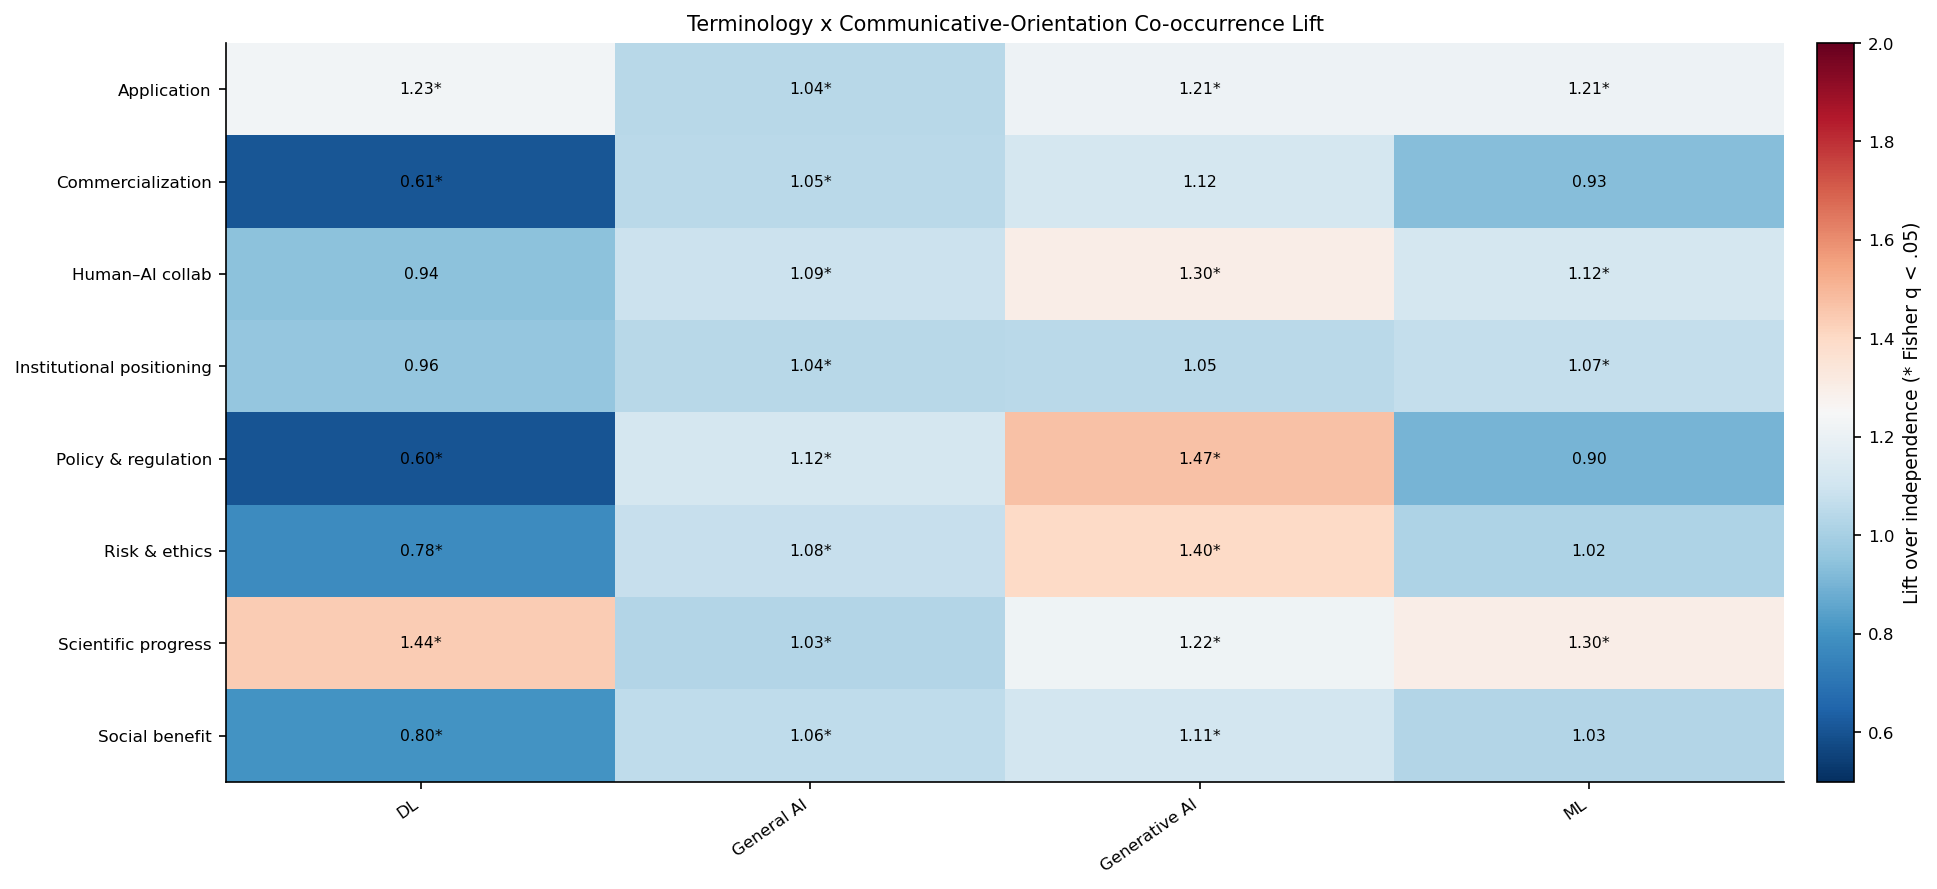

In [36]:
# Scheme 1: binary co-occurrence with Fisher exact tests and lift
cooccurrence_rows = []
for term_label, term_col in term_presence_cols.items():
    term_present = association_model_df[term_col].astype(bool)
    for orientation_label, orientation_col in frame_presence_cols.items():
        orientation_present = association_model_df[orientation_col].astype(bool)
        n11 = int((term_present & orientation_present).sum())
        n10 = int((term_present & ~orientation_present).sum())
        n01 = int((~term_present & orientation_present).sum())
        n00 = int((~term_present & ~orientation_present).sum())
        table = np.array([[n11, n10], [n01, n00]])
        term_prev = (n11 + n10) / table.sum()
        orientation_prev = (n11 + n01) / table.sum()
        joint_prev = n11 / table.sum()
        lift = joint_prev / (term_prev * orientation_prev) if term_prev > 0 and orientation_prev > 0 else np.nan
        pct_with_term = n11 / (n11 + n10) * 100 if (n11 + n10) else np.nan
        pct_without_term = n01 / (n01 + n00) * 100 if (n01 + n00) else np.nan
        fisher_or, fisher_p = stats.fisher_exact(table, alternative="two-sided")
        chi2, chi2_p, _, _ = stats.chi2_contingency(table, correction=False)
        phi = ((n11 * n00) - (n10 * n01)) / np.sqrt((n11 + n10) * (n01 + n00) * (n11 + n01) * (n10 + n00))
        cooccurrence_rows.append({
            "term_family": term_label,
            "orientation": orientation_label,
            "n_term_and_orientation": n11,
            "orientation_pct_with_term": pct_with_term,
            "orientation_pct_without_term": pct_without_term,
            "difference_pp": pct_with_term - pct_without_term,
            "lift": lift,
            "phi": phi,
            "fisher_odds_ratio": fisher_or,
            "fisher_p": fisher_p,
            "chi2_p": chi2_p,
        })

cooccurrence_results = pd.DataFrame(cooccurrence_rows)
cooccurrence_results["fisher_q"] = multipletests(cooccurrence_results["fisher_p"], method="fdr_bh")[1]
cooccurrence_results["chi2_q"] = multipletests(cooccurrence_results["chi2_p"], method="fdr_bh")[1]

print("Strongest binary terminology-orientation co-occurrences, sorted by FDR-adjusted Fisher p-value and lift:")
display(
    cooccurrence_results.sort_values(["fisher_q", "lift"], ascending=[True, False])
    .head(20)
    .round({"orientation_pct_with_term": 1, "orientation_pct_without_term": 1, "difference_pp": 1, "lift": 2, "phi": 2, "fisher_odds_ratio": 2, "fisher_p": 4, "fisher_q": 4, "chi2_q": 4})
)

cooccurrence_lift_matrix = cooccurrence_results.pivot_table(
    index="orientation",
    columns="term_family",
    values="lift",
).round(2)
cooccurrence_q_matrix = cooccurrence_results.pivot_table(
    index="orientation",
    columns="term_family",
    values="fisher_q",
)

if "PLOTS_AVAILABLE" in globals() and PLOTS_AVAILABLE:
    fig, ax = plt.subplots(figsize=(13, 6))
    values = cooccurrence_lift_matrix.values.astype(float)
    im = ax.imshow(values, aspect="auto", cmap="RdBu_r", vmin=0.5, vmax=max(2.0, np.nanpercentile(values, 95)))
    ax.set_title("Terminology x Communicative-Orientation Co-occurrence Lift")
    ax.set_xticks(range(cooccurrence_lift_matrix.shape[1]))
    ax.set_xticklabels(wrap_labels(cooccurrence_lift_matrix.columns, 18), rotation=35, ha="right")
    ax.set_yticks(range(cooccurrence_lift_matrix.shape[0]))
    ax.set_yticklabels(wrap_labels(cooccurrence_lift_matrix.index, 28))
    for i in range(cooccurrence_lift_matrix.shape[0]):
        for j in range(cooccurrence_lift_matrix.shape[1]):
            value = cooccurrence_lift_matrix.iloc[i, j]
            q_value = cooccurrence_q_matrix.iloc[i, j]
            marker = "*" if pd.notna(q_value) and q_value < 0.05 else ""
            ax.text(j, i, f"{value:.2f}{marker}", ha="center", va="center", fontsize=7.5)
    cbar = plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    cbar.set_label("Lift over independence (* Fisher q < .05)")
    plt.tight_layout()
    plt.show()

In [37]:
# Scheme 1b: high-intensity co-occurrence (word-based lift)
# Dichotomize per-1k rates at each variable's median among nonzero articles,


def high_intensity_flag(series):
    nonzero = series[series > 0]
    if nonzero.empty:
        return pd.Series(False, index=series.index)
    return series > nonzero.median()

intensity_cooccurrence_rows = []
for term_rate_col, term_label in term_rate_lookup.items():
    term_high = high_intensity_flag(association_model_df[term_rate_col].astype(float))
    for orientation_intensity_col, orientation_label in orientation_intensity_lookup.items():
        orient_high = high_intensity_flag(association_model_df[orientation_intensity_col].astype(float))
        n11 = int((term_high & orient_high).sum())
        n10 = int((term_high & ~orient_high).sum())
        n01 = int((~term_high & orient_high).sum())
        n00 = int((~term_high & ~orient_high).sum())
        table = np.array([[n11, n10], [n01, n00]])
        total = table.sum()
        term_prev = (n11 + n10) / total
        orient_prev = (n11 + n01) / total
        lift = (n11 / total) / (term_prev * orient_prev) if term_prev > 0 and orient_prev > 0 else np.nan
        fisher_or, fisher_p = stats.fisher_exact(table, alternative="two-sided")
        intensity_cooccurrence_rows.append({
            "term_family": term_label,
            "orientation": orientation_label,
            "n_high_high": n11,
            "lift_high_intensity": lift,
            "fisher_odds_ratio": fisher_or,
            "fisher_p": fisher_p,
        })

intensity_cooccurrence_results = pd.DataFrame(intensity_cooccurrence_rows)
intensity_cooccurrence_results["fisher_q"] = multipletests(intensity_cooccurrence_results["fisher_p"], method="fdr_bh")[1]

print("High-intensity co-occurrence: articles with above-median term density vs above-median orientation cue density")
display(
    intensity_cooccurrence_results.sort_values(["fisher_q", "lift_high_intensity"], ascending=[True, False])
    .head(20)
    .round({"lift_high_intensity": 2, "fisher_odds_ratio": 2, "fisher_p": 4, "fisher_q": 4})
)

High-intensity co-occurrence: articles with above-median term density vs above-median orientation cue density


,term_family,orientation,n_high_high,lift_high_intensity,fisher_odds_ratio,fisher_p,fisher_q
30,ML,Scientific progress,358,1.53,3.63,0.0000,0.0000
6,DL,Scientific progress,220,1.75,5.53,0.0000,0.0000
13,General AI,Risk & ethics,471,1.35,2.63,0.0000,0.0000
11,General AI,Institutional positioning,568,1.22,2.11,0.0000,0.0000
15,General AI,Social benefit,469,1.26,2.11,0.0000,0.0000
1,DL,Commercialization,26,0.33,0.23,0.0000,0.0000
22,Generative AI,Scientific progress,211,1.44,2.56,0.0000,0.0000
12,General AI,Policy & regulation,240,1.40,2.37,0.0000,0.0000
9,General AI,Commercialization,349,1.30,2.05,0.0000,0.0000
7,DL,Social benefit,53,0.49,0.33,0.0000,0.0000


In [38]:
# Scheme 1c: lexical-embedding robustness check.
# Several orientation strong phrases embed a terminology cue as a word inside the
# phrase (e.g. "responsible ai" contains the General AI cue "ai"), so the same
# token span is counted by both dictionaries even though the two dictionaries
# share no identical entries. This check recounts terminology matches on text in
# which the spans of all embedding orientation phrases are masked, then
# recomputes the Scheme 1 lift table. If embedding drove an association, its
# lift should move; if not, the association survives de-embedding.

# 1. Identify orientation cues that embed a terminology cue.
embedding_rows = []
for frame_id, compiled in compiled_frames.items():
    for tier in ("strong", "weak"):
        for cue, _pattern in compiled[tier]:
            for family, family_cues in compiled_term_families.items():
                for term_cue, term_pattern in family_cues:
                    if cue_key(term_cue) == cue_key(cue):
                        continue
                    if term_pattern.search(cue.lower()):
                        embedding_rows.append({
                            "orientation": compiled["label"], "tier": tier,
                            "orientation_cue": cue, "term_family": family,
                            "embedded_term": term_cue,
                        })
embedding_cues_df = pd.DataFrame(embedding_rows)
print("Orientation cues embedding a terminology cue (orientation x tier x family):")
display(embedding_cues_df.groupby(["orientation", "tier", "term_family"]).size().rename("n_cues").reset_index())
print(f"Distinct embedding orientation cues: {embedding_cues_df['orientation_cue'].nunique()}")
compiled_embedding_cues = [
    (cue, compile_flexible_cue(cue))
    for cue in embedding_cues_df["orientation_cue"].drop_duplicates()
]

# 2. Mask embedding-phrase spans, then recount terminology matches.
def mask_embedding_spans(text):
    spans = [m.span() for _cue, pattern in compiled_embedding_cues for m in pattern.finditer(text)]
    if not spans:
        return text
    chars = list(text)
    for start, end in spans:
        for i in range(start, end):
            chars[i] = "§"  # placeholder breaks any word match inside the span
    return "".join(chars)

deembedded_rows = []
for row in analysis_df.itertuples(index=False):
    masked_text = mask_embedding_spans(getattr(row, "analysis_text_lower"))
    for family, compiled_cues in compiled_term_families.items():
        total = int(sum(count_matches(masked_text, compiled_cues).values()))
        deembedded_rows.append({
            "article_id": getattr(row, "article_id"),
            "term_family": family,
            "term_count_deembedded": total,
        })
term_deembedded = pd.DataFrame(deembedded_rows)
deembedded_counts = term_deembedded.pivot_table(
    index="article_id", columns="term_family", values="term_count_deembedded",
    aggfunc="sum", fill_value=0)
term_deembedded_presence = deembedded_counts > 0

original_counts = term_article_scores.pivot_table(
    index="article_id", columns="term_family", values="term_count",
    aggfunc="sum", fill_value=0)
removal_summary = pd.DataFrame({
    "total_matches": original_counts.sum(),
    "matches_removed": original_counts.sum() - deembedded_counts.sum(),
})
removal_summary["removed_pct"] = (removal_summary["matches_removed"] / removal_summary["total_matches"] * 100).round(2)
print("Terminology matches removed by masking embedding phrases:")
display(removal_summary)
print("Articles losing family presence entirely after de-embedding:")
display((term_presence_wide & ~term_deembedded_presence.reindex(term_presence_wide.index).fillna(False)).sum())

# 3. Recompute the Scheme 1 lift table on the de-embedded presence indicators.
def scheme1_lift(term_presence, orientation_presence):
    rows = []
    for family in term_presence.columns:
        term_flag = term_presence[family].astype(bool)
        for orientation in orientation_presence.columns:
            orient_flag = orientation_presence[orientation].astype(bool)
            n11 = int((term_flag & orient_flag).sum()); n10 = int((term_flag & ~orient_flag).sum())
            n01 = int((~term_flag & orient_flag).sum()); n00 = int((~term_flag & ~orient_flag).sum())
            total = n11 + n10 + n01 + n00
            term_prev, orient_prev = (n11 + n10) / total, (n11 + n01) / total
            lift = (n11 / total) / (term_prev * orient_prev) if term_prev and orient_prev else np.nan
            _odds, p_value = stats.fisher_exact([[n11, n10], [n01, n00]])
            rows.append({"term_family": family, "orientation": orientation,
                         "lift": lift, "fisher_p": p_value})
    out = pd.DataFrame(rows)
    out["fisher_q"] = multipletests(out["fisher_p"], method="fdr_bh")[1]
    return out

lift_original = scheme1_lift(term_presence_wide, frame_presence_wide).rename(
    columns={"lift": "lift_original", "fisher_q": "q_original"})
lift_deembedded = scheme1_lift(
    term_deembedded_presence.reindex(term_presence_wide.index).fillna(False),
    frame_presence_wide).rename(columns={"lift": "lift_deembedded", "fisher_q": "q_deembedded"})
lift_robustness = lift_original[["term_family", "orientation", "lift_original", "q_original"]].merge(
    lift_deembedded[["term_family", "orientation", "lift_deembedded", "q_deembedded"]],
    on=["term_family", "orientation"])
lift_robustness["lift_delta"] = lift_robustness["lift_deembedded"] - lift_robustness["lift_original"]
lift_robustness["significance_flips"] = (
    (lift_robustness["q_original"] < 0.05) != (lift_robustness["q_deembedded"] < 0.05))

print("Scheme 1 lift, original vs de-embedded terminology presence (sorted by |change|):")
display(lift_robustness.round(3).sort_values("lift_delta", key=lambda s: s.abs(), ascending=False))
print(f"Max |lift change| across all 32 cells: {lift_robustness['lift_delta'].abs().max():.3f}")
print(f"Cells whose FDR significance flips: {int(lift_robustness['significance_flips'].sum())}")

Orientation cues embedding a terminology cue (orientation x tier x family):


,orientation,tier,term_family,n_cues
0,Application,strong,General AI,1
1,Commercialization,strong,General AI,1
2,Human–AI collab,strong,General AI,5
3,Institutional positioning,strong,General AI,6
4,Policy & regulation,strong,General AI,6
5,Risk & ethics,strong,General AI,7
6,Scientific progress,strong,DL,1
7,Scientific progress,strong,General AI,3
8,Scientific progress,strong,ML,2
9,Social benefit,strong,General AI,2


Distinct embedding orientation cues: 34
Terminology matches removed by masking embedding phrases:


,total_matches,matches_removed,removed_pct
term_family,,,
DL,2522,1,0.04
General AI,16595,442,2.66
Generative AI,5144,6,0.12
ML,3433,2,0.06


Articles losing family presence entirely after de-embedding:


term_family
DL               1
General AI       4
Generative AI    2
ML               0
dtype: int64

Scheme 1 lift, original vs de-embedded terminology presence (sorted by |change|):


,term_family,orientation,lift_original,q_original,lift_deembedded,q_deembedded,lift_delta,significance_flips
17,Generative AI,Commercialization,1.119,0.104,1.106,0.161,-0.013,False
21,Generative AI,Risk & ethics,1.398,0.000,1.392,0.000,-0.007,False
20,Generative AI,Policy & regulation,1.466,0.000,1.471,0.000,0.005,False
23,Generative AI,Social benefit,1.107,0.011,1.102,0.016,-0.004,False
18,Generative AI,Human–AI collab,1.305,0.000,1.309,0.000,0.004,False
13,General AI,Risk & ethics,1.076,0.000,1.073,0.000,-0.003,False
9,General AI,Commercialization,1.051,0.005,1.053,0.003,0.002,False
19,Generative AI,Institutional positioning,1.051,0.062,1.049,0.077,-0.002,False
0,DL,Application,1.231,0.000,1.229,0.000,-0.002,False
2,DL,Human–AI collab,0.941,0.446,0.942,0.483,0.002,False


Max |lift change| across all 32 cells: 0.013
Cells whose FDR significance flips: 0


Controlled model comparison: do terminology-family predictors improve fit beyond institution, period, and article length?


,orientation,n_articles,control_aic,full_aic,delta_aic_full_minus_control,lr_stat,lr_df,lr_p,lr_q
0,Application,2231,2671.8,2649.7,-22.1,30.09,4,0.0000,0.0000
1,Commercialization,2231,2006.2,1961.4,-44.8,52.78,4,0.0000,0.0000
2,Human–AI collab,2231,2077.2,2062.5,-14.7,22.68,4,0.0001,0.0001
3,Institutional positioning,2231,2685.0,2658.9,-26.1,34.11,4,0.0000,0.0000
4,Policy & regulation,2231,1404.3,1376.6,-27.7,35.70,4,0.0000,0.0000
5,Risk & ethics,2231,2429.8,2395.7,-34.1,42.11,4,0.0000,0.0000
6,Scientific progress,2231,2507.9,2166.7,-341.2,349.20,4,0.0000,0.0000
7,Social benefit,2231,2823.7,2771.6,-52.1,60.09,4,0.0000,0.0000


Controlled terminology coefficients with FDR correction:


,orientation,term_family,coef_log_odds,odds_ratio,ci_low,ci_high,p_value,q_value
27,Scientific progress,ML,1.29,3.63,2.92,4.51,0.0000,0.0000
24,Scientific progress,DL,1.62,5.04,3.69,6.89,0.0000,0.0000
26,Scientific progress,Generative AI,0.95,2.59,1.96,3.42,0.0000,0.0000
28,Social benefit,DL,-0.69,0.50,0.40,0.63,0.0000,0.0000
4,Commercialization,DL,-0.88,0.42,0.31,0.57,0.0000,0.0000
20,Risk & ethics,DL,-0.62,0.54,0.42,0.69,0.0000,0.0000
3,Application,ML,0.45,1.56,1.29,1.90,0.0000,0.0000
29,Social benefit,General AI,0.62,1.86,1.37,2.51,0.0001,0.0003
16,Policy & regulation,DL,-0.78,0.46,0.31,0.69,0.0001,0.0005
12,Institutional positioning,DL,-0.41,0.66,0.53,0.83,0.0002,0.0007


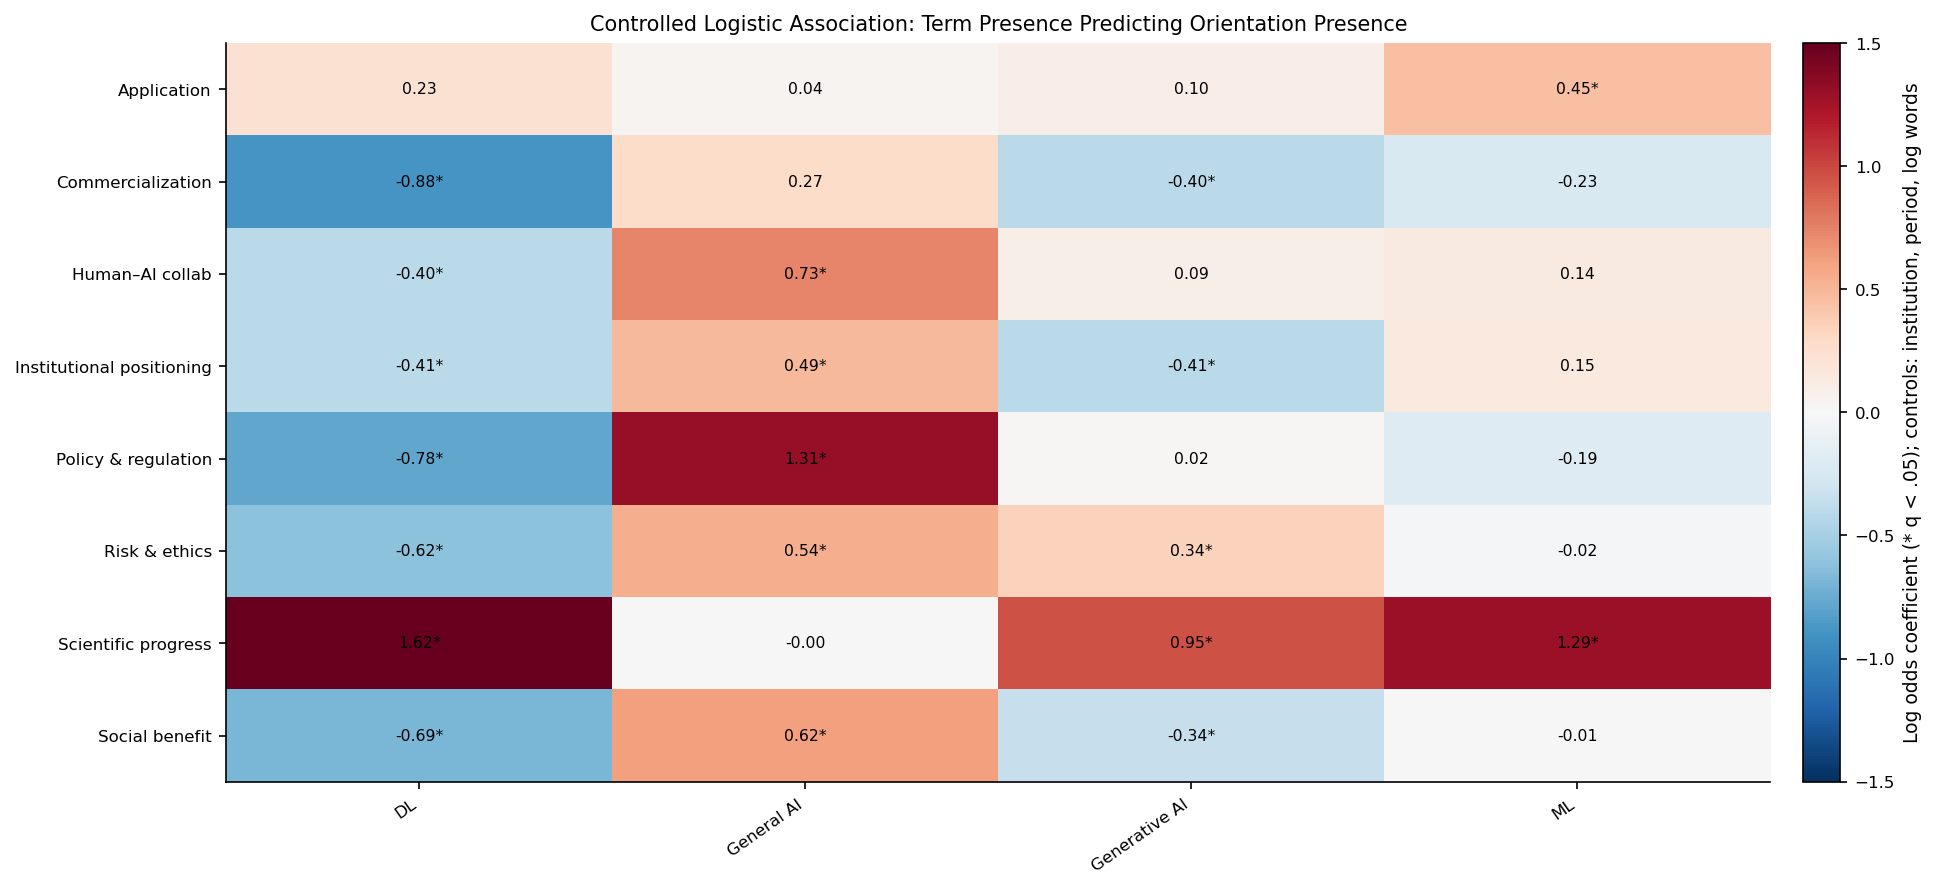

In [39]:
# Scheme 2: controlled logistic GLM for article-level orientation presence

logistic_rows = []
model_comparison_rows = []
control_terms = "log_words + C(Institution) + C(analysis_period)"
term_predictors = list(term_presence_cols.values())

for orientation_label, outcome_col in frame_presence_cols.items():
    model_data = association_model_df[[outcome_col, "log_words", "Institution", "analysis_period"] + term_predictors].copy()
    if model_data[outcome_col].nunique() < 2:
        continue
    full_formula = f"{outcome_col} ~ {' + '.join(term_predictors)} + {control_terms}"
    control_formula = f"{outcome_col} ~ {control_terms}"
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            full_model = smf.glm(full_formula, data=model_data, family=sm.families.Binomial()).fit(cov_type="HC3")
            control_model = smf.glm(control_formula, data=model_data, family=sm.families.Binomial()).fit(cov_type="HC3")
        lr_stat = max(0, 2 * (full_model.llf - control_model.llf))
        lr_df = int(full_model.df_model - control_model.df_model)
        lr_p = stats.chi2.sf(lr_stat, lr_df) if lr_df > 0 else np.nan
        model_comparison_rows.append({
            "orientation": orientation_label,
            "n_articles": int(full_model.nobs),
            "control_aic": control_model.aic,
            "full_aic": full_model.aic,
            "delta_aic_full_minus_control": full_model.aic - control_model.aic,
            "lr_stat": lr_stat,
            "lr_df": lr_df,
            "lr_p": lr_p,
        })
        for term_col in term_predictors:
            coef = full_model.params.get(term_col, np.nan)
            se = full_model.bse.get(term_col, np.nan)
            p_value = full_model.pvalues.get(term_col, np.nan)
            logistic_rows.append({
                "orientation": orientation_label,
                "term_family": term_label_lookup[term_col],
                "coef_log_odds": coef,
                "odds_ratio": np.exp(coef) if pd.notna(coef) else np.nan,
                "ci_low": np.exp(coef - 1.96 * se) if pd.notna(coef) and pd.notna(se) else np.nan,
                "ci_high": np.exp(coef + 1.96 * se) if pd.notna(coef) and pd.notna(se) else np.nan,
                "p_value": p_value,
            })
    except Exception as exc:
        model_comparison_rows.append({
            "orientation": orientation_label,
            "n_articles": int(model_data.shape[0]),
            "control_aic": np.nan,
            "full_aic": np.nan,
            "delta_aic_full_minus_control": np.nan,
            "lr_stat": np.nan,
            "lr_df": np.nan,
            "lr_p": np.nan,
            "model_note": str(exc)[:120],
        })

controlled_logistic_results = pd.DataFrame(logistic_rows)
if not controlled_logistic_results.empty:
    controlled_logistic_results["q_value"] = multipletests(controlled_logistic_results["p_value"].fillna(1), method="fdr_bh")[1]

logistic_model_comparison = pd.DataFrame(model_comparison_rows)
if not logistic_model_comparison.empty and logistic_model_comparison["lr_p"].notna().any():
    logistic_model_comparison["lr_q"] = multipletests(logistic_model_comparison["lr_p"].fillna(1), method="fdr_bh")[1]

print("Controlled model comparison: do terminology-family predictors improve fit beyond institution, period, and article length?")
display(logistic_model_comparison.round({"control_aic": 1, "full_aic": 1, "delta_aic_full_minus_control": 1, "lr_stat": 2, "lr_p": 4, "lr_q": 4}))

print("Controlled terminology coefficients with FDR correction:")
display(
    controlled_logistic_results.sort_values(["q_value", "odds_ratio"], ascending=[True, False])
    .head(24)
    .round({"coef_log_odds": 2, "odds_ratio": 2, "ci_low": 2, "ci_high": 2, "p_value": 4, "q_value": 4})
)

controlled_or_matrix = controlled_logistic_results.pivot_table(
    index="orientation",
    columns="term_family",
    values="coef_log_odds",
).round(2)
controlled_q_matrix = controlled_logistic_results.pivot_table(
    index="orientation",
    columns="term_family",
    values="q_value",
)

if "PLOTS_AVAILABLE" in globals() and PLOTS_AVAILABLE and not controlled_or_matrix.empty:
    fig, ax = plt.subplots(figsize=(13, 6))
    values = controlled_or_matrix.values.astype(float)
    vmax = max(1.5, np.nanpercentile(np.abs(values), 95))
    im = ax.imshow(values, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title("Controlled Logistic Association: Term Presence Predicting Orientation Presence")
    ax.set_xticks(range(controlled_or_matrix.shape[1]))
    ax.set_xticklabels(wrap_labels(controlled_or_matrix.columns, 18), rotation=35, ha="right")
    ax.set_yticks(range(controlled_or_matrix.shape[0]))
    ax.set_yticklabels(wrap_labels(controlled_or_matrix.index, 28))
    for i in range(controlled_or_matrix.shape[0]):
        for j in range(controlled_or_matrix.shape[1]):
            value = controlled_or_matrix.iloc[i, j]
            q_value = controlled_q_matrix.iloc[i, j]
            marker = "*" if pd.notna(q_value) and q_value < 0.05 else ""
            ax.text(j, i, f"{value:.2f}{marker}", ha="center", va="center", fontsize=7.5)
    cbar = plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    cbar.set_label("Log odds coefficient (* q < .05); controls: institution, period, log words")
    plt.tight_layout()
    plt.show()

Controlled intensity models: do terminology rates add explanatory power beyond institution, period, and length?


,orientation,n_articles,adj_r2_controls_only,adj_r2_full,delta_adj_r2,full_aic,control_aic
0,Application,2231,0.040,0.066,0.026,5621.0,5679.3
1,Commercialization,2231,0.035,0.094,0.060,6066.7,6205.0
2,Human–AI collab,2231,0.021,0.033,0.011,5351.7,5373.2
3,Institutional positioning,2231,0.053,0.131,0.077,5394.7,5580.8
4,Policy & regulation,2231,0.074,0.126,0.051,5198.0,5321.5
5,Risk & ethics,2231,0.070,0.111,0.040,6042.1,6136.7
6,Scientific progress,2231,0.085,0.305,0.220,5827.1,6437.5
7,Social benefit,2231,0.049,0.120,0.070,6609.8,6777.3


Controlled intensity coefficients (log1p-log1p scale) with FDR correction:


,orientation,term_family,coef,ci_low,ci_high,p_value,q_value
27,Scientific progress,ML,0.413,0.367,0.459,0.0000,0.0000
24,Scientific progress,DL,0.363,0.315,0.411,0.0000,0.0000
26,Scientific progress,Generative AI,0.290,0.249,0.331,0.0000,0.0000
13,Institutional positioning,General AI,0.197,0.158,0.235,0.0000,0.0000
28,Social benefit,DL,-0.279,-0.335,-0.223,0.0000,0.0000
4,Commercialization,DL,-0.213,-0.258,-0.169,0.0000,0.0000
29,Social benefit,General AI,0.223,0.175,0.271,0.0000,0.0000
12,Institutional positioning,DL,-0.189,-0.232,-0.147,0.0000,0.0000
21,Risk & ethics,General AI,0.186,0.143,0.229,0.0000,0.0000
17,Policy & regulation,General AI,0.173,0.133,0.212,0.0000,0.0000


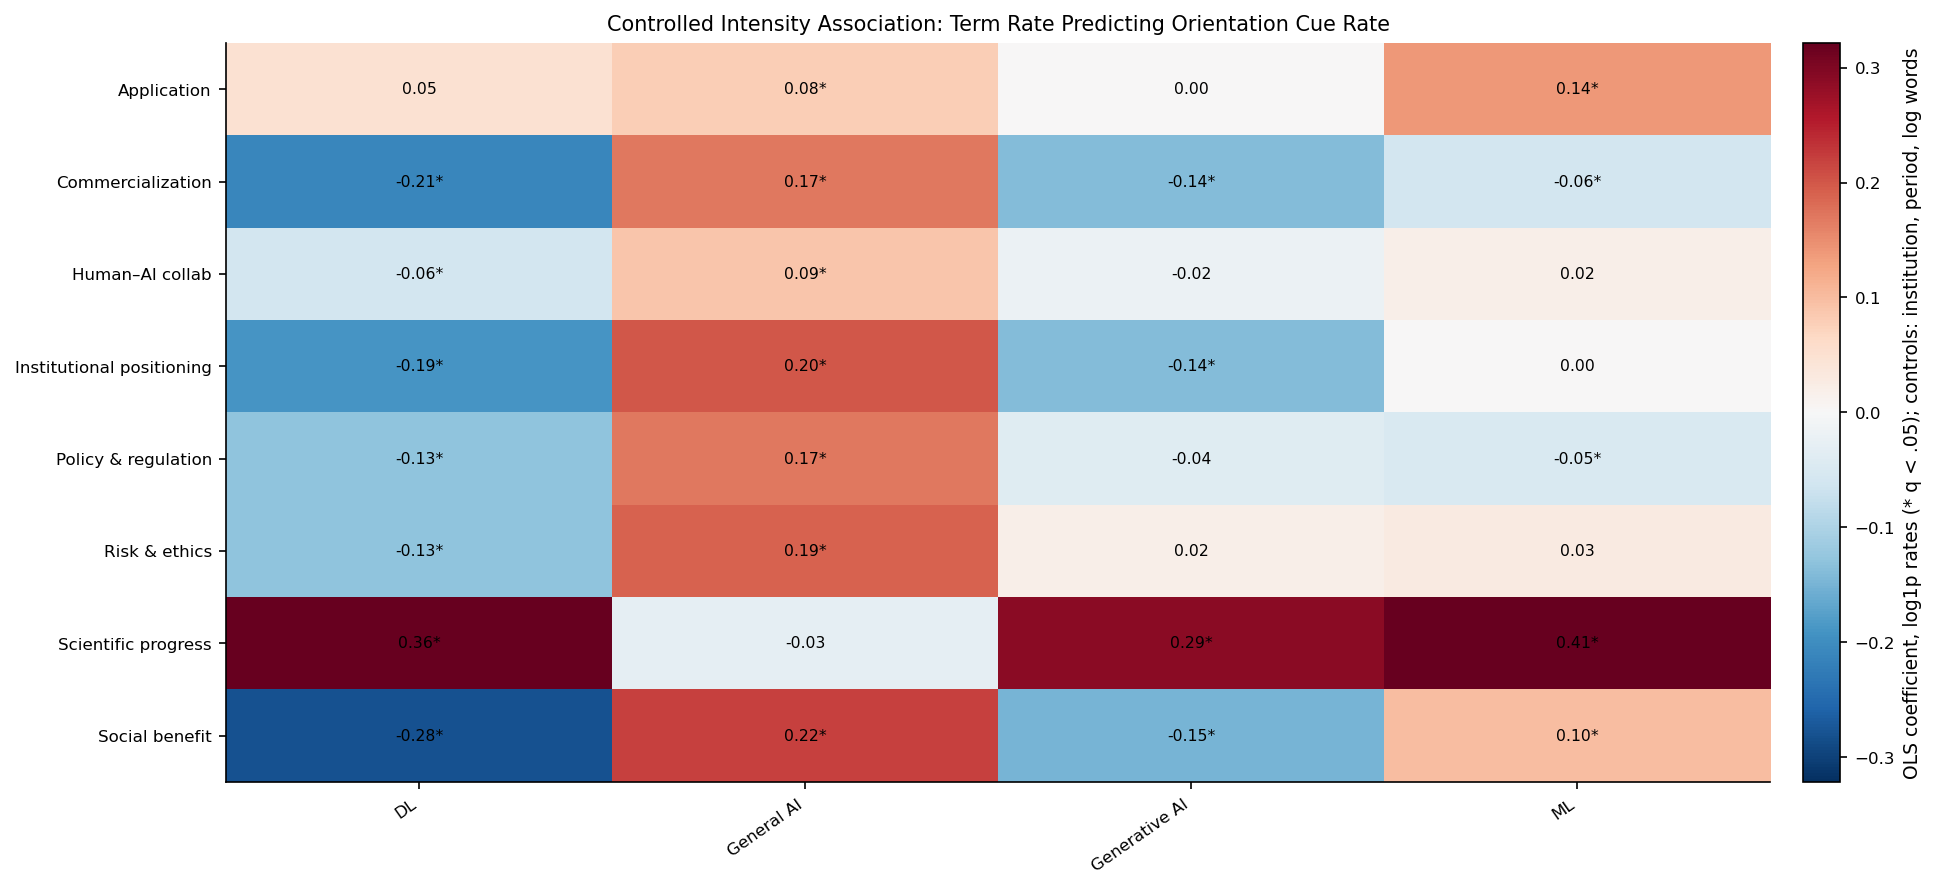

In [40]:
# Scheme 2b: controlled linear model for article-level orientation INTENSITY
# Outcome: log1p(orientation weighted cue rate per 1k words); predictors: log1p(term rate per 1k words).
# Controls mirror Scheme 2: institution, analysis period, log article length.

intensity_model_rows = []
intensity_comparison_rows = []
control_terms = "log_words + C(Institution) + C(analysis_period)"
rate_predictor_cols = list(term_rate_cols.values())

intensity_data_all = association_model_df.copy()
# log1p tames the heavy right skew and the many zeros in per-1k rates.
for col in rate_predictor_cols:
    intensity_data_all[f"log_{col}"] = np.log1p(intensity_data_all[col].astype(float))
log_rate_predictors = [f"log_{col}" for col in rate_predictor_cols]

for orientation_intensity_col, orientation_label in orientation_intensity_lookup.items():
    outcome = f"log_{orientation_intensity_col}"
    intensity_data_all[outcome] = np.log1p(intensity_data_all[orientation_intensity_col].astype(float))
    model_data = intensity_data_all[[outcome, "log_words", "Institution", "analysis_period"] + log_rate_predictors].copy()
    if model_data[outcome].nunique() < 2:
        continue
    full_formula = f"{outcome} ~ {' + '.join(log_rate_predictors)} + {control_terms}"
    control_formula = f"{outcome} ~ {control_terms}"
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        full_model = smf.ols(full_formula, data=model_data).fit(cov_type="HC3")
        control_model = smf.ols(control_formula, data=model_data).fit(cov_type="HC3")
    intensity_comparison_rows.append({
        "orientation": orientation_label,
        "n_articles": int(full_model.nobs),
        "adj_r2_controls_only": control_model.rsquared_adj,
        "adj_r2_full": full_model.rsquared_adj,
        "delta_adj_r2": full_model.rsquared_adj - control_model.rsquared_adj,
        "full_aic": full_model.aic,
        "control_aic": control_model.aic,
    })
    for log_col, rate_col in zip(log_rate_predictors, rate_predictor_cols):
        coef = full_model.params.get(log_col, np.nan)
        se = full_model.bse.get(log_col, np.nan)
        intensity_model_rows.append({
            "orientation": orientation_label,
            "term_family": term_rate_lookup[rate_col],
            "coef": coef,
            "ci_low": coef - 1.96 * se,
            "ci_high": coef + 1.96 * se,
            "p_value": full_model.pvalues.get(log_col, np.nan),
        })

controlled_intensity_results = pd.DataFrame(intensity_model_rows)
controlled_intensity_results["q_value"] = multipletests(controlled_intensity_results["p_value"].fillna(1), method="fdr_bh")[1]
controlled_intensity_comparison = pd.DataFrame(intensity_comparison_rows)

print("Controlled intensity models: do terminology rates add explanatory power beyond institution, period, and length?")
display(controlled_intensity_comparison.round({"adj_r2_controls_only": 3, "adj_r2_full": 3, "delta_adj_r2": 3, "full_aic": 1, "control_aic": 1}))

print("Controlled intensity coefficients (log1p-log1p scale) with FDR correction:")
display(
    controlled_intensity_results.sort_values(["q_value", "coef"], ascending=[True, False])
    .head(24)
    .round({"coef": 3, "ci_low": 3, "ci_high": 3, "p_value": 4, "q_value": 4})
)

controlled_intensity_matrix = controlled_intensity_results.pivot_table(index="orientation", columns="term_family", values="coef").round(2)
controlled_intensity_q = controlled_intensity_results.pivot_table(index="orientation", columns="term_family", values="q_value")

if "PLOTS_AVAILABLE" in globals() and PLOTS_AVAILABLE and not controlled_intensity_matrix.empty:
    fig, ax = plt.subplots(figsize=(13, 6))
    values = controlled_intensity_matrix.values.astype(float)
    vmax = max(0.3, np.nanpercentile(np.abs(values), 95))
    im = ax.imshow(values, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title("Controlled Intensity Association: Term Rate Predicting Orientation Cue Rate")
    ax.set_xticks(range(controlled_intensity_matrix.shape[1]))
    ax.set_xticklabels(wrap_labels(controlled_intensity_matrix.columns, 18), rotation=35, ha="right")
    ax.set_yticks(range(controlled_intensity_matrix.shape[0]))
    ax.set_yticklabels(wrap_labels(controlled_intensity_matrix.index, 28))
    for i in range(controlled_intensity_matrix.shape[0]):
        for j in range(controlled_intensity_matrix.shape[1]):
            value = controlled_intensity_matrix.iloc[i, j]
            q_value = controlled_intensity_q.iloc[i, j]
            marker = "*" if pd.notna(q_value) and q_value < 0.05 else ""
            ax.text(j, i, f"{value:.2f}{marker}", ha="center", va="center", fontsize=7.5)
    cbar = plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    cbar.set_label("OLS coefficient, log1p rates (* q < .05); controls: institution, period, log words")
    plt.tight_layout()
    plt.show()

Intensity association: term rate per 1,000 words vs orientation weighted cue rate per 1,000 words


,term_family,orientation,spearman_rho,p_value,q_value
30,ML,Scientific progress,0.37,0.0000,0.0000
6,DL,Scientific progress,0.35,0.0000,0.0000
13,General AI,Risk & ethics,0.24,0.0000,0.0000
15,General AI,Social benefit,0.24,0.0000,0.0000
11,General AI,Institutional positioning,0.23,0.0000,0.0000
22,Generative AI,Scientific progress,0.22,0.0000,0.0000
12,General AI,Policy & regulation,0.21,0.0000,0.0000
3,DL,Institutional positioning,-0.19,0.0000,0.0000
9,General AI,Commercialization,0.18,0.0000,0.0000
7,DL,Social benefit,-0.17,0.0000,0.0000


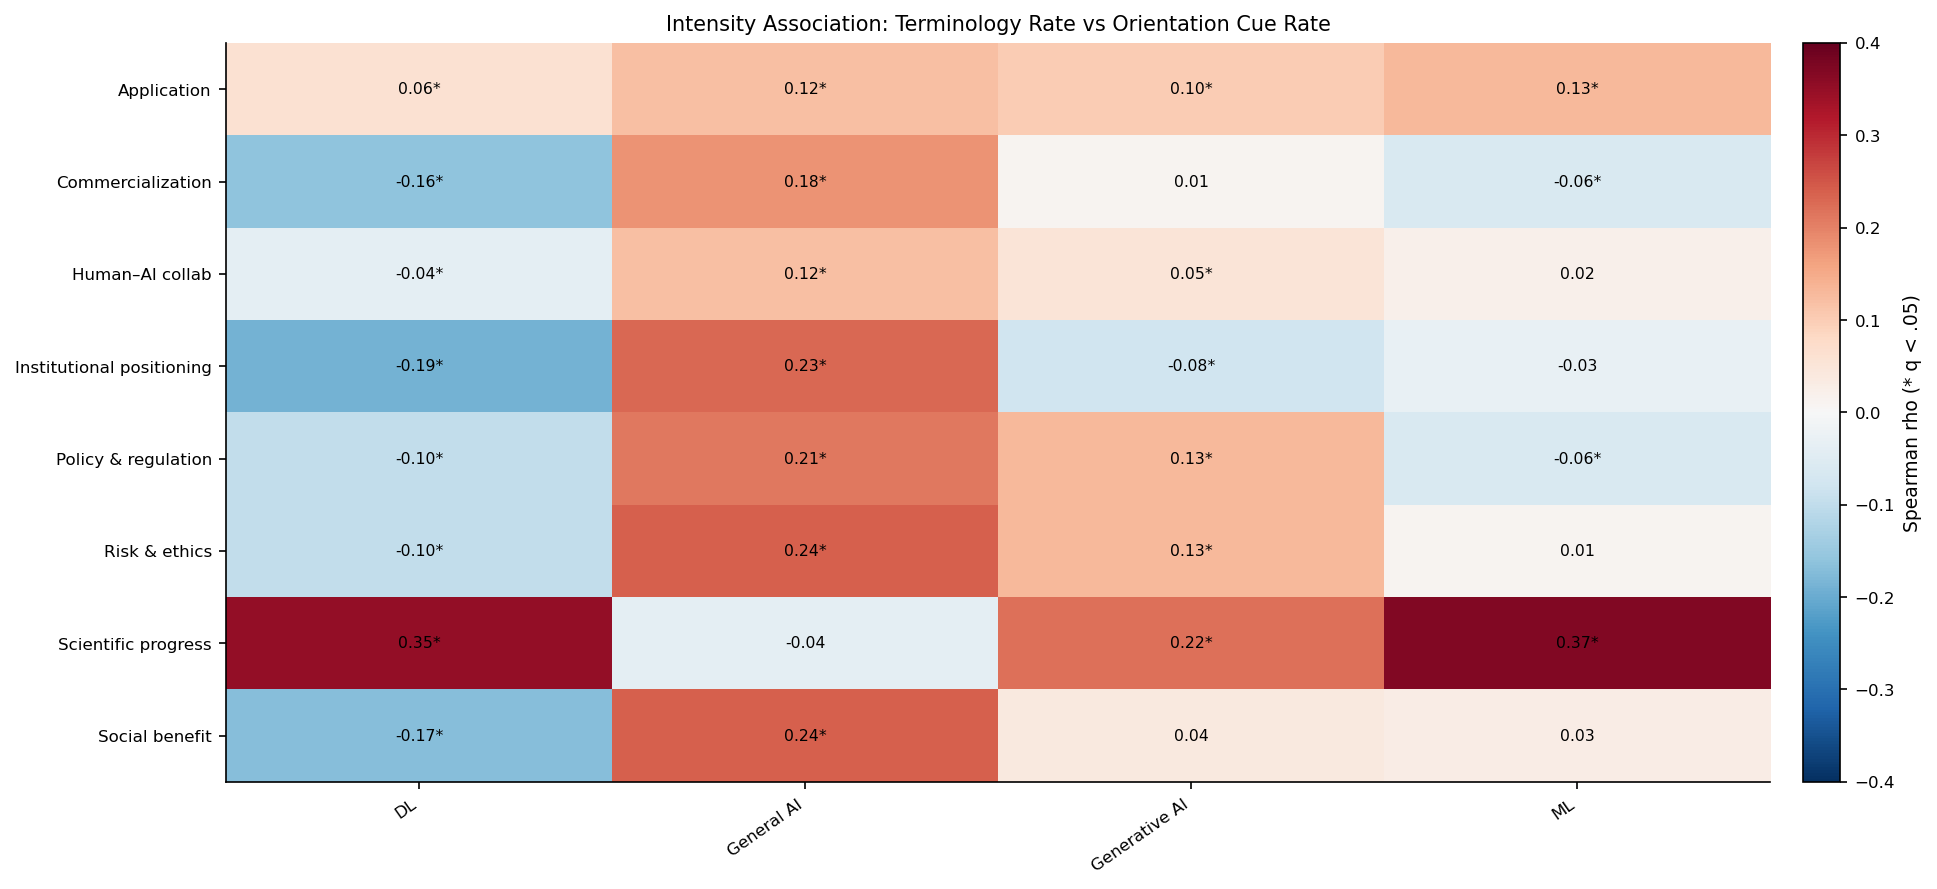

In [41]:
# Scheme 3: continuous intensity association using Spearman correlation
intensity_rows = []
for term_label, term_rate_col in term_rate_cols.items():
    term_values = association_model_df[term_rate_col].astype(float)
    for orientation_label, orientation_intensity_col in frame_intensity_cols.items():
        orientation_values = association_model_df[orientation_intensity_col].astype(float)
        if term_values.nunique() < 2 or orientation_values.nunique() < 2:
            rho, p_value = np.nan, np.nan
        else:
            rho, p_value = stats.spearmanr(term_values, orientation_values, nan_policy="omit")
        intensity_rows.append({
            "term_family": term_label,
            "orientation": orientation_label,
            "spearman_rho": rho,
            "p_value": p_value,
        })

intensity_association_results = pd.DataFrame(intensity_rows)
intensity_association_results["q_value"] = multipletests(intensity_association_results["p_value"].fillna(1), method="fdr_bh")[1]

print("Intensity association: term rate per 1,000 words vs orientation weighted cue rate per 1,000 words")
display(
    intensity_association_results.sort_values(["q_value", "spearman_rho"], ascending=[True, False])
    .head(20)
    .round({"spearman_rho": 2, "p_value": 4, "q_value": 4})
)

rho_matrix = intensity_association_results.pivot_table(
    index="orientation",
    columns="term_family",
    values="spearman_rho",
).round(2)
rho_q_matrix = intensity_association_results.pivot_table(
    index="orientation",
    columns="term_family",
    values="q_value",
)

if "PLOTS_AVAILABLE" in globals() and PLOTS_AVAILABLE:
    fig, ax = plt.subplots(figsize=(13, 6))
    im = ax.imshow(rho_matrix.values.astype(float), aspect="auto", cmap="RdBu_r", vmin=-0.4, vmax=0.4)
    ax.set_title("Intensity Association: Terminology Rate vs Orientation Cue Rate")
    ax.set_xticks(range(rho_matrix.shape[1]))
    ax.set_xticklabels(wrap_labels(rho_matrix.columns, 18), rotation=35, ha="right")
    ax.set_yticks(range(rho_matrix.shape[0]))
    ax.set_yticklabels(wrap_labels(rho_matrix.index, 28))
    for i in range(rho_matrix.shape[0]):
        for j in range(rho_matrix.shape[1]):
            value = rho_matrix.iloc[i, j]
            q_value = rho_q_matrix.iloc[i, j]
            marker = "*" if pd.notna(q_value) and q_value < 0.05 else ""
            ax.text(j, i, f"{value:.2f}{marker}", ha="center", va="center", fontsize=7.5)
    cbar = plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    cbar.set_label("Spearman rho (* q < .05)")
    plt.tight_layout()
    plt.show()

In [42]:
# Compare schemes 
scheme_compare = cooccurrence_results.merge(
    controlled_logistic_results[["term_family", "orientation", "odds_ratio", "q_value"]].rename(
        columns={"odds_ratio": "controlled_odds_ratio", "q_value": "controlled_q"}
    ),
    on=["term_family", "orientation"],
    how="left",
).merge(
    intensity_association_results[["term_family", "orientation", "spearman_rho", "q_value"]].rename(
        columns={"q_value": "intensity_q"}
    ),
    on=["term_family", "orientation"],
    how="left",
)

scheme_compare["binary_sig"] = scheme_compare["fisher_q"] < 0.05
scheme_compare["controlled_sig"] = scheme_compare["controlled_q"] < 0.05
scheme_compare["intensity_sig"] = scheme_compare["intensity_q"] < 0.05
scheme_compare["agreement_count"] = scheme_compare[["binary_sig", "controlled_sig", "intensity_sig"]].sum(axis=1)

print("Associations supported by at least two schemes:")
display(
    scheme_compare.loc[scheme_compare["agreement_count"] >= 2, [
        "term_family", "orientation", "agreement_count", "lift", "difference_pp",
        "controlled_odds_ratio", "spearman_rho", "fisher_q", "controlled_q", "intensity_q",
    ]]
    .sort_values(["agreement_count", "controlled_odds_ratio", "lift"], ascending=[False, False, False])
    .round({"lift": 2, "difference_pp": 1, "controlled_odds_ratio": 2, "spearman_rho": 2, "fisher_q": 4, "controlled_q": 4, "intensity_q": 4})
    .head(20)
)

print("Cases where binary co-occurrence is significant but the controlled logistic coefficient is not:")
display(
    scheme_compare.loc[
        scheme_compare["binary_sig"] & ~scheme_compare["controlled_sig"],
        ["term_family", "orientation", "lift", "difference_pp", "controlled_odds_ratio", "fisher_q", "controlled_q"],
    ]
    .sort_values(["fisher_q", "lift"], ascending=[True, False])
    .round({"lift": 2, "difference_pp": 1, "controlled_odds_ratio": 2, "fisher_q": 4, "controlled_q": 4})
    .head(15)
)

supported = scheme_compare.loc[scheme_compare["agreement_count"] >= 2].sort_values(
    ["agreement_count", "controlled_odds_ratio", "lift"], ascending=[False, False, False]
)
if supported.empty:
    print("Interpretation: no terminology-orientation pair is supported by at least two schemes after FDR correction. Treat any single-scheme signals as exploratory.")
else:
    top = supported.iloc[0]
    print(
        "Interpretation: the most consistent association is "
        f"{top['term_family']} with {top['orientation']} "
        f"(lift={top['lift']:.2f}, controlled OR={top['controlled_odds_ratio']:.2f}, "
        f"rho={top['spearman_rho']:.2f}). This is an association in article language, not causal evidence."
    )

print(
    "Model comparison note: binary co-occurrence is easiest to interpret but can reflect institution, period, or article-length composition. "
    "Controlled logistic models are more conservative for article-level prevalence. Spearman intensity checks whether denser terminology also travels with denser orientation cue language."
)

Associations supported by at least two schemes:


,term_family,orientation,agreement_count,lift,difference_pp,controlled_odds_ratio,spearman_rho,fisher_q,controlled_q,intensity_q
6,DL,Scientific progress,3,1.44,36.1,5.04,0.35,0.0000,0.0000,0.0000
12,General AI,Policy & regulation,3,1.12,9.8,3.72,0.21,0.0000,0.0015,0.0000
30,ML,Scientific progress,3,1.30,34.3,3.63,0.37,0.0000,0.0000,0.0000
22,Generative AI,Scientific progress,3,1.22,18.8,2.59,0.22,0.0000,0.0000,0.0000
10,General AI,Human–AI collab,3,1.09,13.1,2.08,0.12,0.0000,0.0015,0.0000
15,General AI,Social benefit,3,1.06,18.0,1.86,0.24,0.0000,0.0003,0.0000
13,General AI,Risk & ethics,3,1.08,15.3,1.72,0.24,0.0000,0.0062,0.0000
11,General AI,Institutional positioning,3,1.04,17.7,1.63,0.23,0.0000,0.0016,0.0000
24,ML,Application,3,1.21,18.0,1.56,0.13,0.0000,0.0000,0.0000
21,Generative AI,Risk & ethics,3,1.40,15.7,1.41,0.13,0.0000,0.0083,0.0000


Cases where binary co-occurrence is significant but the controlled logistic coefficient is not:


,term_family,orientation,lift,difference_pp,controlled_odds_ratio,fisher_q,controlled_q
16,Generative AI,Application,1.21,13.9,1.11,0.0000,0.4861
0,DL,Application,1.23,14.2,1.26,0.0000,0.0757
14,General AI,Scientific progress,1.03,14.7,1.00,0.0000,0.9781
20,Generative AI,Policy & regulation,1.47,7.2,1.02,0.0000,0.9492
18,Generative AI,Human–AI collab,1.30,8.9,1.09,0.0000,0.6255
27,ML,Institutional positioning,1.07,8.5,1.16,0.0001,0.1857
8,General AI,Application,1.04,12.5,1.04,0.0001,0.8785
9,General AI,Commercialization,1.05,6.9,1.30,0.0054,0.2248
26,ML,Human–AI collab,1.12,4.7,1.15,0.0089,0.2922


Interpretation: the most consistent association is DL with Scientific progress (lift=1.44, controlled OR=5.04, rho=0.35). This is an association in article language, not causal evidence.
Model comparison note: binary co-occurrence is easiest to interpret but can reflect institution, period, or article-length composition. Controlled logistic models are more conservative for article-level prevalence. Spearman intensity checks whether denser terminology also travels with denser orientation cue language.


## 7 Content domains 

### 7.1 TF-IDF/NMF topic modelling

Core-window articles with at least 80 words are represented by TF-IDF vectors of one- to three-word terms; NMF solutions with 8 to 15 topics are compared by reconstruction error, topic diversity, silhouette, and minimum topic size, and the largest solution with at least 1.8% of articles in every topic and diversity of at least 0.70 is selected. 


In [43]:
# Topic modeling setup: choose a recent multi-school analysis window

# Data choice:
# - Use the same 2021-2025 CMU/JHU/MIT/Stanford core window as the main analysis.
# - Exclude 2026 because it is partial-year data.
# - Keep a minimum text length so topic/embedding models have enough context.
topic_start_year = CORE_START_YEAR
topic_end_year = CORE_END_YEAR
min_topic_words = CORE_MIN_ANALYSIS_WORDS

topic_df = core_analysis_df.loc[
    core_analysis_df["analysis_word_count"] >= min_topic_words
].copy()

topic_df["topic_text"] = (
    topic_df[[col for col in ["Article Header", "Sub_Headings", "Article Body"] if col in topic_df.columns]]
    .fillna("")
    .astype(str)
    .agg(". ".join, axis=1)
    .map(clean_text_value)
)

topic_school_year_counts = (
    topic_df.groupby(["Institution", "year"])
    .size()
    .rename("article_count")
    .reset_index()
    .pivot_table(index="Institution", columns="year", values="article_count", fill_value=0)
    .astype(int)
)

topic_school_counts = topic_df["Institution"].value_counts().rename_axis("Institution").reset_index(name="articles")

print(f"Topic-modeling corpus: {len(topic_df):,} articles, core window {topic_start_year}-{topic_end_year}, schools: {', '.join(CORE_INSTITUTIONS)}, minimum {min_topic_words} words")
print("School-year availability for the selected topic window:")
display(topic_school_year_counts)
print("School totals in the selected topic window:")
display(topic_school_counts)

if len(topic_df) < 100:
    raise ValueError("Topic-modeling corpus is too small for stable multi-topic exploration. Broaden the time window.")

Topic-modeling corpus: 1,289 articles, core window 2021-2025, schools: CMU, JHU, MIT, Stanford, minimum 80 words
School-year availability for the selected topic window:


year,2021,2022,2023,2024,2025
Institution,,,,,
CMU,10,28,38,57,98
JHU,5,8,27,26,35
MIT,130,145,164,178,206
Stanford,10,5,6,21,92


School totals in the selected topic window:


,Institution,articles
0,MIT,823
1,CMU,231
2,Stanford,134
3,JHU,101


In [44]:
# Topic preprocessing: fine-grained TF-IDF features for NMF

# Because this corpus is already AI-related, use unigrams/bigrams/trigrams and a lower min_df to preserve narrower subtopics.

institution_stopwords = {
    "university", "universities", "school", "schools", "college", "colleges", "campus", "students",
    "professor", "professors", "faculty", "researcher", "researchers", "team", "teams", "study", "studies",
    "new", "said", "says", "news", "article", "press", "release", "according", "work", "working",
    "mit", "cmu", "carnegie", "mellon", "cornell", "stanford", "jhu", "johns", "hopkins",
    "research", "science", "scientists", "lab", "labs", "department", "institute", "center", "centre",
}

# NOT remove AI/dictionary cue words here, because they may be part of real topical content.
# The later topic-orientation/terminology comparison is interpreted descriptively, not as an independent causal test.
custom_stopwords = sorted(set(ENGLISH_STOP_WORDS) | institution_stopwords)

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words=custom_stopwords,
    ngram_range=(1, 3),
    min_df=3,
    max_df=0.55,
    max_features=4500,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z][a-zA-Z0-9\-]+\b",
)

topic_tfidf = vectorizer.fit_transform(topic_df["topic_text"])
topic_terms = np.array(vectorizer.get_feature_names_out())

print(f"TF-IDF matrix shape: {topic_tfidf.shape[0]:,} articles x {topic_tfidf.shape[1]:,} terms/ngrams")
print("Fine-grained settings: ngram_range=(1, 3), min_df=3, max_df=0.55, max_features=4500")
print("Example retained features:", ", ".join(topic_terms[:30]))

TF-IDF matrix shape: 1,289 articles x 4,500 terms/ngrams
Fine-grained settings: ngram_range=(1, 3), min_df=3, max_df=0.55, max_features=4500
Example retained features: aaai, abdul, abdul latif, abdul latif jameel, abilities, ability, able, abstract, abstractions, academia, academia industry, academic, academics, academy, accelerate, accelerated, accelerating, acceleration, accelerator, accelerators, accenture, accepted, access, accessibility, accessible, accommodate, accomplish, accomplished, account, accountability


In [45]:
# Select a fine-grained topic count by comparing reconstruction error, topic diversity, silhouette, and minimum topic size

# Here we intentionally allow more topics than a broad corpus model would, because the corpus is already AI-focused.

def top_words_for_model(model, terms, top_n=12):
    return [[terms[i] for i in topic.argsort()[:-top_n - 1:-1]] for topic in model.components_]

candidate_topic_counts = [8, 9, 10, 11, 12, 13, 14, 15]
model_selection_rows = []
model_cache = {}

for k in candidate_topic_counts:
    nmf_model = NMF(
        n_components=k,
        init="nndsvda",
        random_state=42,
        max_iter=800,
        solver="cd",
        beta_loss="frobenius",
    )
    article_topic = nmf_model.fit_transform(topic_tfidf)
    top_words = top_words_for_model(nmf_model, topic_terms, top_n=12)
    unique_top_words = len(set(word for words in top_words for word in words))
    diversity = unique_top_words / (k * 12)
    dominant_topics = article_topic.argmax(axis=1)
    if k > 1 and len(set(dominant_topics)) > 1:
        article_topic_norm = normalize(article_topic, norm="l1")
        sample_size = min(1200, article_topic_norm.shape[0])
        rng = np.random.default_rng(42)
        sample_idx = rng.choice(article_topic_norm.shape[0], size=sample_size, replace=False)
        silhouette = silhouette_score(article_topic_norm[sample_idx], dominant_topics[sample_idx], metric="euclidean")
    else:
        silhouette = np.nan
    model_selection_rows.append({
        "n_topics": k,
        "reconstruction_error": nmf_model.reconstruction_err_,
        "topic_diversity_top12": diversity,
        "silhouette_on_topic_weights": silhouette,
        "smallest_topic_articles": pd.Series(dominant_topics).value_counts().min(),
    })
    model_cache[k] = (nmf_model, article_topic, top_words)

model_selection = pd.DataFrame(model_selection_rows)
print("Topic-count diagnostics:")
display(model_selection.round({"reconstruction_error": 2, "topic_diversity_top12": 2, "silhouette_on_topic_weights": 3}))

# Conservative choice: enough granularity without very small topics.
min_topic_articles = max(18, int(len(topic_df) * 0.018))
valid_models = model_selection.loc[
    (model_selection["smallest_topic_articles"] >= min_topic_articles)
    & (model_selection["topic_diversity_top12"] >= 0.70)
].copy()
if valid_models.empty:
    selected_n_topics = int(model_selection.sort_values(["topic_diversity_top12", "silhouette_on_topic_weights"], ascending=[False, False]).iloc[0]["n_topics"])
else:
    # Fine-grained choice: pick the largest valid k, using diagnostics to prevent tiny fragmented topics.
    selected_n_topics = int(valid_models.sort_values("n_topics", ascending=False).iloc[0]["n_topics"])

selected_topic_model, selected_article_topic, selected_top_words = model_cache[selected_n_topics]
print(f"Minimum dominant-topic size required: {min_topic_articles} articles")
print(f"Selected fine-grained topic count for the main analysis: {selected_n_topics}")

Topic-count diagnostics:


,n_topics,reconstruction_error,topic_diversity_top12,silhouette_on_topic_weights,smallest_topic_articles
0,8,33.79,0.91,0.453,26
1,9,33.69,0.93,0.421,26
2,10,33.58,0.92,0.398,26
3,11,33.49,0.93,0.395,25
4,12,33.40,0.94,0.379,25
5,13,33.32,0.93,0.375,25
6,14,33.23,0.93,0.371,24
7,15,33.16,0.92,0.366,24


Minimum dominant-topic size required: 23 articles
Selected fine-grained topic count for the main analysis: 15


In [46]:
# Fit selected NMF model outputs into article-level topic variables
# **dominant_topic = highest NMF topic weight for each article**.


topic_weight_cols = [f"topic_{i+1}_weight" for i in range(selected_n_topics)]
topic_weights = pd.DataFrame(selected_article_topic, columns=topic_weight_cols, index=topic_df.index)
topic_weights_norm = topic_weights.div(topic_weights.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)

topic_df = pd.concat([topic_df.reset_index(drop=True), topic_weights_norm.reset_index(drop=True)], axis=1)
topic_df["dominant_topic_id"] = topic_weights_norm.values.argmax(axis=1) + 1
topic_df["dominant_topic_weight"] = topic_weights_norm.max(axis=1).values

topic_label_rows = []
for topic_number, words in enumerate(selected_top_words, start=1):
    label = " / ".join(words[:4])
    topic_label_rows.append({
        "dominant_topic_id": topic_number,
        "topic_label": f"T{topic_number}: {label}",
        "top_terms": ", ".join(words[:12]),
    })
topic_labels = pd.DataFrame(topic_label_rows)
topic_label_map = topic_labels.set_index("dominant_topic_id")["topic_label"].to_dict()
topic_df["topic_label"] = topic_df["dominant_topic_id"].map(topic_label_map)

print("Selected topic labels and top terms:")
display(topic_labels)

print("Largest topics by dominant-topic assignment:")
topic_size = (
    topic_df.groupby(["dominant_topic_id", "topic_label"], as_index=False)
    .agg(
        articles=("article_id", "nunique"),
        mean_dominant_topic_weight=("dominant_topic_weight", "mean"),
        median_words=("analysis_word_count", "median"),
    )
)
topic_size["article_pct"] = (topic_size["articles"] / len(topic_df) * 100).round(1)
display(topic_size.sort_values("articles", ascending=False).round({"mean_dominant_topic_weight": 2}))

Selected topic labels and top terms:


,dominant_topic_id,topic_label,top_terms
0,1,T1: language / models / llms / language models,"language, models, llms, language models, llm, large language, text, large language models, large, model, reasoning, ..."
1,2,T2: people / education / technology / social,"people, education, technology, social, tools, policy, think, teachers, human, companies, media, users"
2,3,T3: health / care / patients / medical,"health, care, patients, medical, patient, health care, clinical, doctors, medicine, clinicians, hospital, physicians"
3,4,T4: model / models / machine-learning / technique,"model, models, machine-learning, technique, dataset, training, predictions, method, prediction, methods, accuracy, u..."
4,5,T5: robot / robots / robotics / robotic,"robot, robots, robotics, robotic, objects, task, tasks, soft, arm, environment, control, csail"
5,6,T6: opens window / window / opens / pittsburgh,"opens window, window, opens, pittsburgh, innovation, jahanian, robotics, president, summit, media inquiries, pichai,..."
6,7,T7: protein / proteins / drug / molecules,"protein, proteins, drug, molecules, structures, molecular, drugs, model, dna, amino, sequences, discovery"
7,8,T8: images / image / generative / objects,"images, image, generative, objects, vision, visual, models, diffusion, computer vision, object, scene, csail"
8,9,T9: computing / program / schwarzman / fellows,"computing, program, schwarzman, fellows, schwarzman computing, machine learning, award, machine, amazon, serc, dean,..."
9,10,T10: brain / neural / network / networks,"brain, neural, network, networks, neurons, neural network, neural networks, deep, chip, human brain, neuroscience, l..."


Largest topics by dominant-topic assignment:


,dominant_topic_id,topic_label,articles,mean_dominant_topic_weight,median_words,article_pct
1,2,T2: people / education / technology / social,254,0.53,959.0,19.7
8,9,T9: computing / program / schwarzman / fellows,150,0.55,589.0,11.6
12,13,T13: autonomous / vehicles / safety / vehicle,106,0.53,993.5,8.2
2,3,T3: health / care / patients / medical,105,0.53,925.0,8.1
3,4,T4: model / models / machine-learning / technique,93,0.48,1094.0,7.2
10,11,T11: materials / material / properties / design,81,0.55,1049.0,6.3
7,8,T8: images / image / generative / objects,80,0.51,956.5,6.2
9,10,T10: brain / neural / network / networks,80,0.53,995.0,6.2
4,5,T5: robot / robots / robotics / robotic,76,0.61,699.5,5.9
0,1,T1: language / models / llms / language models,65,0.48,1076.0,5.0


Topic prevalence within each school (% of selected-window articles):


topic_label,T10: brain / neural / network / networks,T11: materials / material / properties / design,T12: energy / power / climate / data centers,T13: autonomous / vehicles / safety / vehicle,T14: cancer / cells / cell / patients,T15: music / music technology / audio / musical,T1: language / models / llms / language models,T2: people / education / technology / social,T3: health / care / patients / medical,T4: model / models / machine-learning / technique,T5: robot / robots / robotics / robotic,T6: opens window / window / opens / pittsburgh,T7: protein / proteins / drug / molecules,T8: images / image / generative / objects,T9: computing / program / schwarzman / fellows
Institution,,,,,,,,,,,,,,,
CMU,1.3,0.4,1.7,9.5,2.6,3.0,4.3,25.1,3.5,1.7,7.4,10.4,0.4,3.0,25.5
JHU,5.9,5.9,1.0,5.0,5.9,1.0,8.9,23.8,23.8,1.0,5.0,0.0,1.0,5.0,6.9
MIT,7.9,8.5,5.3,8.9,2.7,2.2,4.3,14.5,6.9,10.2,6.3,0.0,5.2,7.2,10.0
Stanford,4.5,3.0,6.0,4.5,4.5,1.5,8.2,39.6,11.9,3.0,1.5,0.0,3.7,6.7,1.5


Topic prevalence by year (% of selected-window articles):


topic_label,T10: brain / neural / network / networks,T11: materials / material / properties / design,T12: energy / power / climate / data centers,T13: autonomous / vehicles / safety / vehicle,T14: cancer / cells / cell / patients,T15: music / music technology / audio / musical,T1: language / models / llms / language models,T2: people / education / technology / social,T3: health / care / patients / medical,T4: model / models / machine-learning / technique,T5: robot / robots / robotics / robotic,T6: opens window / window / opens / pittsburgh,T7: protein / proteins / drug / molecules,T8: images / image / generative / objects,T9: computing / program / schwarzman / fellows
year,,,,,,,,,,,,,,,
2021,9.7,8.4,3.9,12.9,2.6,0.6,3.2,17.4,8.4,3.9,7.1,0.0,5.8,7.1,9.0
2022,11.3,6.5,5.4,8.6,2.2,2.2,1.1,14.5,11.8,11.8,5.4,0.0,2.7,3.8,12.9
2023,6.0,6.0,3.4,6.8,1.3,0.9,4.3,19.6,6.8,8.9,6.4,0.0,4.3,9.8,15.7
2024,4.6,7.8,3.2,7.1,3.9,3.2,7.4,19.5,7.8,6.7,6.7,2.5,2.5,6.4,10.6
2025,3.9,4.6,5.6,7.9,4.2,2.8,6.3,23.0,7.4,5.8,4.9,3.9,4.4,4.9,10.4


Saved figures/fig06_topic_overview.pdf


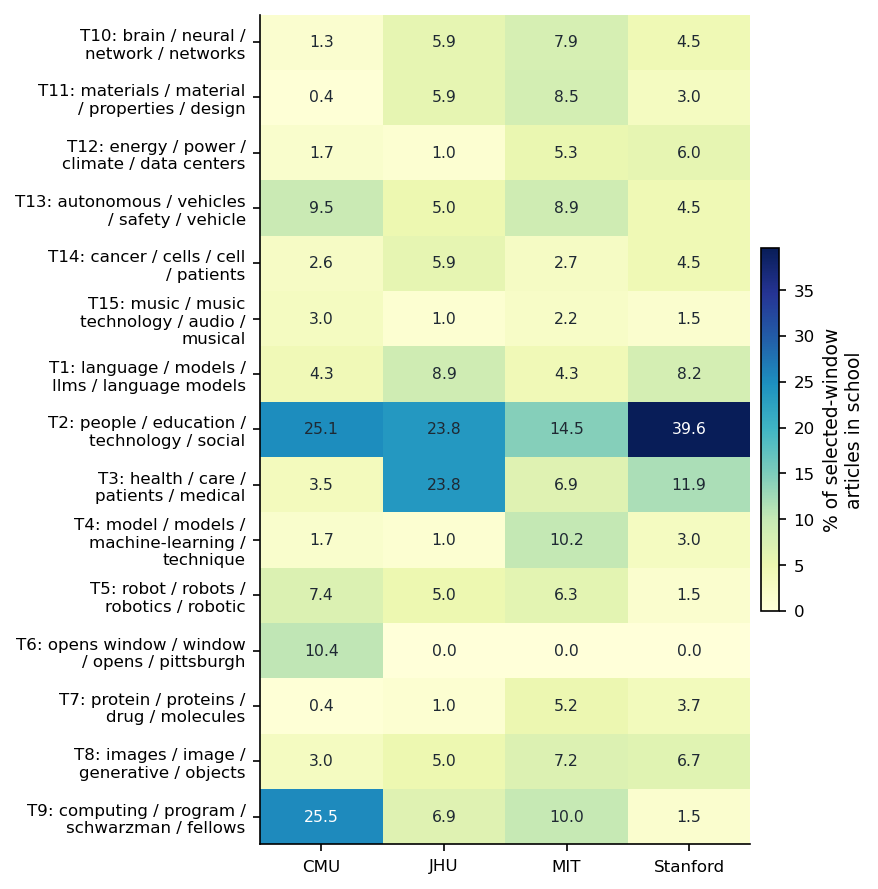

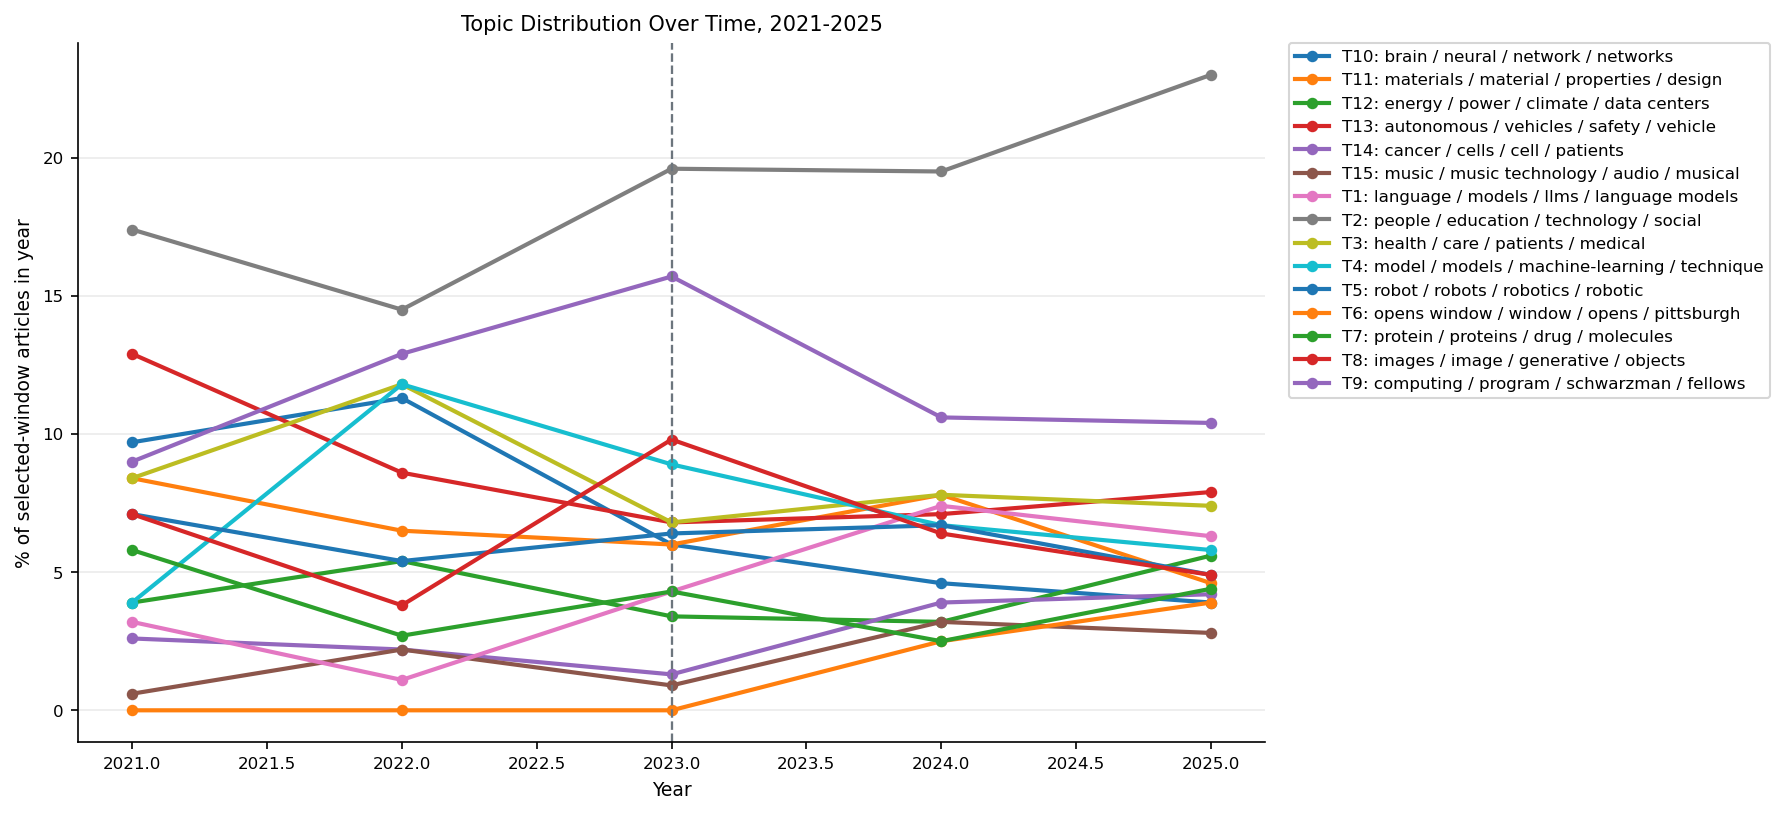

In [47]:
# Topic distribution across schools and time (fig06_topic_overview.pdf)
school_topic = (
    topic_df.groupby(["Institution", "topic_label"], as_index=False)
    .agg(articles=("article_id", "nunique"))
)
school_topic["school_total"] = school_topic.groupby("Institution")["articles"].transform("sum")
school_topic["topic_pct_within_school"] = school_topic["articles"] / school_topic["school_total"] * 100
school_topic_matrix = school_topic.pivot_table(
    index="Institution",
    columns="topic_label",
    values="topic_pct_within_school",
    fill_value=0,
).round(1)

year_topic = (
    topic_df.groupby(["year", "topic_label"], as_index=False)
    .agg(articles=("article_id", "nunique"))
)
year_topic["year_total"] = year_topic.groupby("year")["articles"].transform("sum")
year_topic["topic_pct_within_year"] = year_topic["articles"] / year_topic["year_total"] * 100
year_topic_matrix = year_topic.pivot_table(
    index="year",
    columns="topic_label",
    values="topic_pct_within_year",
    fill_value=0,
).round(1)

print("Topic prevalence within each school (% of selected-window articles):")
display(school_topic_matrix)
print("Topic prevalence by year (% of selected-window articles):")
display(year_topic_matrix)

if "PLOTS_AVAILABLE" in globals() and PLOTS_AVAILABLE:
    # Transposed (topics as rows, schools as columns) so the 15 topic labels fit the printed page width.
    draw_topic_heatmap(
        school_topic_matrix.T,
        None,  
        "% of selected-window articles in school",
        cmap="YlGnBu",
        figsize=(TEXTWIDTH_IN, 6.0),
        save_as="fig06_topic_overview",
        xrotation=0,
    )

    fig, ax = plt.subplots(figsize=(12, 5.5))
    for col in year_topic_matrix.columns:
        ax.plot(year_topic_matrix.index, year_topic_matrix[col], marker="o", linewidth=2, label=col)
    ax.set_title("Topic Distribution Over Time, 2021-2025")
    ax.set_xlabel("Year")
    ax.set_ylabel("% of selected-window articles in year")
    ax.axvline(2023, color=COLORS["gray"], linestyle="--", linewidth=1.1)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
    plt.tight_layout()
    plt.show()

In [48]:
# Representative articles for qualitative topic checking
representative_examples = []
for topic_id, group in topic_df.groupby("dominant_topic_id"):
    top_examples = group.sort_values("dominant_topic_weight", ascending=False).head(3)
    for _, item in top_examples.iterrows():
        representative_examples.append({
            "topic_label": item["topic_label"],
            "dominant_topic_weight": item["dominant_topic_weight"],
            "Institution": item["Institution"],
            "year": int(item["year"]),
            "Article Header": item.get("Article Header", ""),
            "Url": item.get("Url", ""),
        })

representative_topic_articles = pd.DataFrame(representative_examples)
print("Representative high-weight articles for qualitative topic checking:")
display(representative_topic_articles.round({"dominant_topic_weight": 2}))

Representative high-weight articles for qualitative topic checking:


,topic_label,dominant_topic_weight,Institution,year,Article Header,Url
0,T1: language / models / llms / language models,0.89,MIT,2023,3 Questions: Jacob Andreas on large language models,https://news.mit.edu/2023/3-questions-jacob-andreas-large-language-models-0511
1,T1: language / models / llms / language models,0.81,MIT,2023,Large language models are biased. Can logic help save them?,https://news.mit.edu/2023/large-language-models-are-biased-can-logic-help-save-them-0303
2,T1: language / models / llms / language models,0.80,CMU,2025,CMU Study Shows Large Language Models Have Distinctive Styles,https://www.cs.cmu.edu/news/2025/llm-distinctive-styles
3,T2: people / education / technology / social,0.98,Stanford,2024,Teaching and tinkering: New Stanford project helps educators understand and use AI in their classrooms,https://news.stanford.edu/stories/2024/10/teaching-and-tinkering-new-stanford-project-helps-educators-understand-and...
4,T2: people / education / technology / social,0.96,MIT,2025,Helping K-12 schools navigate the complex world of AI,https://news.mit.edu/2025/helping-k-12-schools-navigate-complex-world-of-ai-1103
5,T2: people / education / technology / social,0.95,MIT,2024,First AI + Education Summit is an international push for “AI fluency”,https://news.mit.edu/2024/first-ai-education-summit-0827
6,T3: health / care / patients / medical,0.87,MIT,2024,Equipping doctors with AI co-pilots,https://news.mit.edu/2024/ambience-equips-doctors-with-ai-co-pilots-1016
7,T3: health / care / patients / medical,0.86,MIT,2024,"AI in health should be regulated, but don’t forget about the algorithms, researchers say",https://news.mit.edu/2024/ai-health-should-be-regulated-dont-forget-about-algorithms-1212
8,T3: health / care / patients / medical,0.85,Stanford,2025,A roadmap for safer and more effective AI in health care,https://news.stanford.edu/stories/2025/10/jama-report-michelle-mello-health-care-ai-oversight
9,T4: model / models / machine-learning / technique,1.00,MIT,2023,Efficient technique improves machine-learning models’ reliability,https://news.mit.edu/2023/improving-machine-learning-models-reliability-0213


### 7.2 Explanatory models for communicative orientation

The fine-grained topics are collapsed into eight broad content domains (domains below 2.5% of the corpus are merged into a residual category). For every orientation, nested logistic models predict presence: Model A (institution, period, log words), Model B (adds domain), Model C (adds domain-by-period interactions), compared by delta AIC, McFadden's pseudo-R2, and FDR-adjusted likelihood-ratio tests. Descriptive domain differences use Wilson intervals, chi-square tests, and Cramer's V; adjusted predicted probabilities from Model B are `fig07_orientation_by_domain.pdf`.


In [49]:
# Build modeling dataset: pooled article-level four-school window, 2021-2025

model_start_year = 2021
model_end_year = 2025
preferred_model_schools = ["CMU", "JHU", "MIT", "Stanford"]
min_model_words = min_topic_words

if "topic_df" not in globals() or "topic_labels" not in globals():
    raise NameError("Run the topic-modeling section before the communicative-orientation models.")

# Collapse fine-grained NMF topics into broader domains to avoid sparse 15-topic model cells.
def assign_broad_topic_domain(topic_label, top_terms):
    text = f"{topic_label} {top_terms}".lower()
    if any(key in text for key in ["language", "llm", "gpt", "chatgpt", "text", "foundation"]):
        return "LLMs / language models"
    if any(key in text for key in ["health", "medical", "patient", "clinical", "medicine", "cancer", "cell", "tumor", "protein", "drug", "molecule", "biology"]):
        return "Health / medicine / biology"
    if any(key in text for key in ["robot", "robotics", "autonomous", "drone"]):
        return "Robotics / autonomy"
    if any(key in text for key in ["material", "chemical", "energy", "climate", "grid", "power"]):
        return "Physical sciences / energy"
    if any(key in text for key in ["education", "teachers", "law", "policy", "people", "social", "tools", "users"]):
        return "Education / society / policy"
    if any(key in text for key in ["music", "audio", "arts", "art"]):
        return "Arts / media"
    if any(key in text for key in ["fellows", "award", "schwarzman", "serc", "pittsburgh", "opens window", "innovation"]):
        return "Institutional programs / awards"
    if any(key in text for key in ["model", "training", "machine-learning", "dataset", "image", "images", "neural", "brain", "network"]):
        return "ML methods / data / perception"
    return "Other AI domains"

broad_topic_lookup = topic_labels.copy()
broad_topic_lookup["broad_topic_domain"] = broad_topic_lookup.apply(
    lambda row: assign_broad_topic_domain(row["topic_label"], row["top_terms"]), axis=1
)

topic_domain_df = topic_df.merge(
    broad_topic_lookup[["dominant_topic_id", "broad_topic_domain"]],
    on="dominant_topic_id",
    how="left",
)

model_article_base = topic_domain_df.loc[
    topic_domain_df["year"].between(model_start_year, model_end_year)
    & topic_domain_df["Institution"].isin(preferred_model_schools)
    & (topic_domain_df["analysis_word_count"] >= min_model_words)
].copy()
model_article_base["post_2023"] = (model_article_base["year"] >= 2023).astype(int)
model_article_base["log_words"] = np.log1p(model_article_base["analysis_word_count_nonzero"])

# Collapse very small broad domains into Other to stabilize logistic estimates.
domain_counts_initial = model_article_base["broad_topic_domain"].value_counts()
min_domain_articles = max(25, int(len(model_article_base) * 0.025))
rare_domains = domain_counts_initial.loc[domain_counts_initial < min_domain_articles].index.tolist()
model_article_base["broad_topic_model"] = model_article_base["broad_topic_domain"].where(
    ~model_article_base["broad_topic_domain"].isin(rare_domains),
    "Other / low-count domains",
)

orientation_present_wide = frame_article_scores.pivot_table(
    index="article_id",
    columns="frame_label",
    values="frame_present",
    aggfunc="max",
    fill_value=False,
).astype(int)
orientation_intensity_wide = frame_article_scores.pivot_table(
    index="article_id",
    columns="frame_label",
    values="weighted_rate_per_1k",
    aggfunc="sum",
    fill_value=0,
)

available_orientations = orientation_present_wide.columns.tolist()

model_orientations = available_orientations

orientation_model_cols = {label: f"orientation_present__{i}" for i, label in enumerate(model_orientations)}
orientation_intensity_cols = {label: f"orientation_intensity__{i}" for i, label in enumerate(model_orientations)}

model_df = model_article_base[[
    "article_id", "Institution", "year", "post_2023", "broad_topic_model", "log_words", "analysis_word_count"
]].merge(
    orientation_present_wide[model_orientations].rename(columns=orientation_model_cols),
    left_on="article_id",
    right_index=True,
    how="left",
).merge(
    orientation_intensity_wide[model_orientations].rename(columns=orientation_intensity_cols),
    left_on="article_id",
    right_index=True,
    how="left",
).fillna(0)

orientation_label_lookup = {v: k for k, v in orientation_model_cols.items()}

print(f"Modeling corpus: {len(model_df):,} articles, {model_start_year}-{model_end_year}, schools: {', '.join(preferred_model_schools)}")
print(f"Minimum article length for topic/model inclusion: {min_model_words} words")
print(f"Rare broad topic domains collapsed when n < {min_domain_articles}: {rare_domains if rare_domains else 'none'}")

print("Institution-year counts in the modeling corpus:")
display(
    model_df.groupby(["Institution", "year"]).size().rename("article_count").reset_index()
    .pivot_table(index="Institution", columns="year", values="article_count", fill_value=0)
    .astype(int)
)

print("Fine topics collapsed into broad domains:")
display(broad_topic_lookup[["topic_label", "top_terms", "broad_topic_domain"]])

print("Broad topic/domain counts used in the models:")
display(model_df["broad_topic_model"].value_counts().rename_axis("broad_topic_domain").reset_index(name="articles"))

print("Modeled communicative orientations and article-level prevalence:")
orientation_prev_summary = []
for col, label in orientation_label_lookup.items():
    orientation_prev_summary.append({"orientation": label, "article_pct": model_df[col].mean() * 100, "articles": int(model_df[col].sum())})
display(pd.DataFrame(orientation_prev_summary).sort_values("article_pct", ascending=False).round({"article_pct": 1}))

Modeling corpus: 1,289 articles, 2021-2025, schools: CMU, JHU, MIT, Stanford
Minimum article length for topic/model inclusion: 80 words
Rare broad topic domains collapsed when n < 32: ['Arts / media']
Institution-year counts in the modeling corpus:


year,2021,2022,2023,2024,2025
Institution,,,,,
CMU,10,28,38,57,98
JHU,5,8,27,26,35
MIT,130,145,164,178,206
Stanford,10,5,6,21,92


Fine topics collapsed into broad domains:


,topic_label,top_terms,broad_topic_domain
0,T1: language / models / llms / language models,"language, models, llms, language models, llm, large language, text, large language models, large, model, reasoning, ...",LLMs / language models
1,T2: people / education / technology / social,"people, education, technology, social, tools, policy, think, teachers, human, companies, media, users",Education / society / policy
2,T3: health / care / patients / medical,"health, care, patients, medical, patient, health care, clinical, doctors, medicine, clinicians, hospital, physicians",Health / medicine / biology
3,T4: model / models / machine-learning / technique,"model, models, machine-learning, technique, dataset, training, predictions, method, prediction, methods, accuracy, u...",ML methods / data / perception
4,T5: robot / robots / robotics / robotic,"robot, robots, robotics, robotic, objects, task, tasks, soft, arm, environment, control, csail",Robotics / autonomy
5,T6: opens window / window / opens / pittsburgh,"opens window, window, opens, pittsburgh, innovation, jahanian, robotics, president, summit, media inquiries, pichai,...",Robotics / autonomy
6,T7: protein / proteins / drug / molecules,"protein, proteins, drug, molecules, structures, molecular, drugs, model, dna, amino, sequences, discovery",Health / medicine / biology
7,T8: images / image / generative / objects,"images, image, generative, objects, vision, visual, models, diffusion, computer vision, object, scene, csail",ML methods / data / perception
8,T9: computing / program / schwarzman / fellows,"computing, program, schwarzman, fellows, schwarzman computing, machine learning, award, machine, amazon, serc, dean,...",Institutional programs / awards
9,T10: brain / neural / network / networks,"brain, neural, network, networks, neurons, neural network, neural networks, deep, chip, human brain, neuroscience, l...",ML methods / data / perception


Broad topic/domain counts used in the models:


,broad_topic_domain,articles
0,Education / society / policy,254
1,ML methods / data / perception,253
2,Robotics / autonomy,206
3,Health / medicine / biology,195
4,Institutional programs / awards,150
5,Physical sciences / energy,138
6,LLMs / language models,65
7,Other / low-count domains,28


Modeled communicative orientations and article-level prevalence:


,orientation,article_pct,articles
3,Institutional positioning,65.8,848
6,Scientific progress,65.8,848
0,Application,49.2,634
7,Social benefit,44.8,578
5,Risk & ethics,31.3,403
2,Human–AI collab,23.5,303
1,Commercialization,19.0,245
4,Policy & regulation,12.3,159


Descriptive communicative-orientation prevalence by broad AI topic/domain:


orientation,Application,Commercialization,Human–AI collab,Institutional positioning,Policy & regulation,Risk & ethics,Scientific progress,Social benefit
broad_topic_domain,,,,,,,,
Education / society / policy,45.3,31.9,26.0,69.7,24.8,46.5,33.1,62.2
Health / medicine / biology,49.7,12.8,42.1,65.6,12.3,31.8,75.9,70.3
Institutional programs / awards,32.7,26.7,8.7,90.7,10.0,30.7,49.3,54.0
LLMs / language models,55.4,6.2,21.5,52.3,4.6,36.9,95.4,21.5
ML methods / data / perception,46.6,5.9,24.5,56.5,6.3,26.1,91.7,24.9
Other / low-count domains,17.9,10.7,21.4,64.3,0.0,14.3,39.3,25.0
Physical sciences / energy,72.5,29.7,17.4,65.9,13.0,18.1,76.8,40.6
Robotics / autonomy,55.3,17.5,17.5,58.7,9.7,28.2,63.6,30.1


Chi-square tests for topic/domain differences in each orientation:


,orientation,chi2,df,p_value,min_expected_cell,cramers_v,q_value
0,Application,63.65,7,0.0,13.8,0.22,0.0
1,Commercialization,84.87,7,0.0,5.3,0.26,0.0
2,Human–AI collab,63.92,7,0.0,6.6,0.22,0.0
3,Institutional positioning,62.44,7,0.0,9.6,0.22,0.0
4,Policy & regulation,54.62,7,0.0,3.5,0.21,0.0
5,Risk & ethics,47.24,7,0.0,8.8,0.19,0.0
6,Scientific progress,265.09,7,0.0,9.6,0.45,0.0
7,Social benefit,165.49,7,0.0,12.6,0.36,0.0


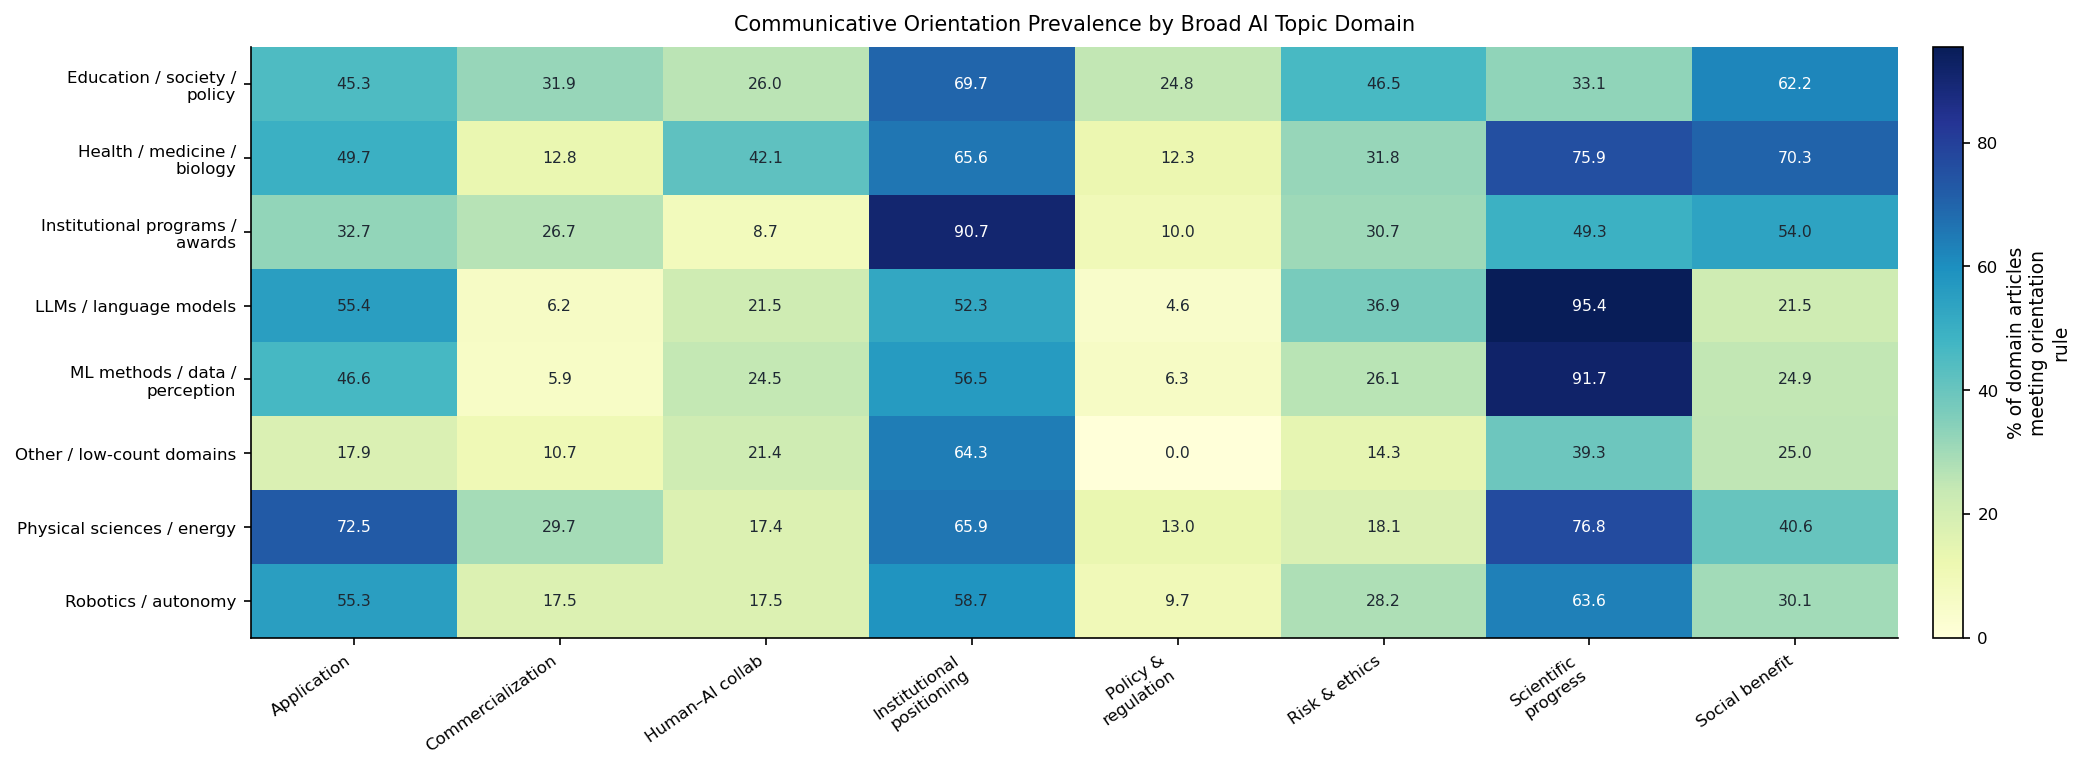

In [50]:
# Descriptive orientation differences by broad topic/domain
# prevalence = share of articles in a domain meeting the selected orientation presence rule.
# Wilson confidence intervals are shown for descriptive uncertainty.

def wilson_ci(successes, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return center - half, center + half

descriptive_rows = []
for domain, group in model_df.groupby("broad_topic_model"):
    n = len(group)
    for col, label in orientation_label_lookup.items():
        successes = int(group[col].sum())
        lo, hi = wilson_ci(successes, n)
        descriptive_rows.append({
            "broad_topic_domain": domain,
            "orientation": label,
            "articles": n,
            "orientation_articles": successes,
            "orientation_pct": successes / n * 100,
            "ci_low_pct": lo * 100,
            "ci_high_pct": hi * 100,
        })

orientation_by_broad_topic = pd.DataFrame(descriptive_rows)
orientation_topic_pct_matrix = orientation_by_broad_topic.pivot_table(
    index="broad_topic_domain",
    columns="orientation",
    values="orientation_pct",
).round(1)

print("Descriptive communicative-orientation prevalence by broad AI topic/domain:")
display(orientation_topic_pct_matrix)

# Chi-square tests: Does orientation prevalence vary across broad topic domains?
chi_rows = []
for col, label in orientation_label_lookup.items():
    table = pd.crosstab(model_df["broad_topic_model"], model_df[col])
    if table.shape[1] == 2 and table.shape[0] > 1:
        chi2, p_value, dof, expected = stats.chi2_contingency(table)
        n = table.values.sum()
        cramers_v = np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1)))
        min_expected = expected.min()
    else:
        chi2, p_value, dof, cramers_v, min_expected = np.nan, np.nan, np.nan, np.nan, np.nan
    chi_rows.append({
        "orientation": label,
        "chi2": chi2,
        "df": dof,
        "p_value": p_value,
        "min_expected_cell": min_expected,
        "cramers_v": cramers_v,
    })

topic_orientation_chi_tests = pd.DataFrame(chi_rows)
topic_orientation_chi_tests["q_value"] = multipletests(topic_orientation_chi_tests["p_value"].fillna(1), method="fdr_bh")[1]
print("Chi-square tests for topic/domain differences in each orientation:")
display(topic_orientation_chi_tests.round({"chi2": 2, "p_value": 4, "q_value": 4, "cramers_v": 2, "min_expected_cell": 1}))

if "PLOTS_AVAILABLE" in globals() and PLOTS_AVAILABLE:
    draw_topic_heatmap(
        orientation_topic_pct_matrix,
        "Communicative Orientation Prevalence by Broad AI Topic Domain",
        "% of domain articles meeting orientation rule",
        cmap="YlGnBu",
        figsize=(14, 5.2),
    )

In [51]:
# Pooled article-level logistic models with communicative orientation as outcome
# logistic regression models the log-odds that an article contains a given orientation.
# Model A: institution + period + article length.
# Model B: Model A + broad topic/domain.
# Model C: Model B + topic/domain x post-2023 interaction, fitted only as exploratory.

model_comparison_rows = []
model_topic_coef_rows = []
fitted_orientation_models = {}

base_formula_terms = "C(Institution) + C(post_2023) + log_words"
topic_formula_terms = "C(broad_topic_model)"
interaction_formula_terms = "C(broad_topic_model) * C(post_2023)"

for outcome_col, orientation_label in orientation_label_lookup.items():
    data = model_df[[outcome_col, "Institution", "post_2023", "log_words", "broad_topic_model"]].copy()
    if data[outcome_col].nunique() < 2:
        continue

    formulas = {
        "A_controls": f"{outcome_col} ~ {base_formula_terms}",
        "B_add_topic": f"{outcome_col} ~ {base_formula_terms} + {topic_formula_terms}",
        "C_topic_x_period": f"{outcome_col} ~ C(Institution) + log_words + {interaction_formula_terms}",
    }
    fitted = {}
    for model_name, formula in formulas.items():
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                fitted[model_name] = smf.glm(formula, data=data, family=sm.families.Binomial()).fit(cov_type="HC3")
        except Exception as exc:
            fitted[model_name] = exc

    if not isinstance(fitted.get("A_controls"), Exception) and not isinstance(fitted.get("B_add_topic"), Exception):
        model_a = fitted["A_controls"]
        model_b = fitted["B_add_topic"]
        lr_stat = max(0, 2 * (model_b.llf - model_a.llf))
        lr_df = int(model_b.df_model - model_a.df_model)
        lr_p = stats.chi2.sf(lr_stat, lr_df) if lr_df > 0 else np.nan
        fitted_orientation_models[orientation_label] = model_b
        null_model = smf.glm(f"{outcome_col} ~ 1", data=data, family=sm.families.Binomial()).fit()
        model_comparison_rows.append({
            "orientation": orientation_label,
            "comparison": "B_add_topic vs A_controls",
            "n_articles": int(model_b.nobs),
            "aic_controls": model_a.aic,
            "aic_add_topic": model_b.aic,
            "delta_aic_add_topic_minus_controls": model_b.aic - model_a.aic,
            "lr_stat": lr_stat,
            "lr_df": lr_df,
            "lr_p": lr_p,
            "mcfadden_pseudo_r2_controls": 1 - (model_a.llf / null_model.llf),
            "mcfadden_pseudo_r2_add_topic": 1 - (model_b.llf / null_model.llf),
        })
        for param_name, coef in model_b.params.items():
            if param_name.startswith("C(broad_topic_model)"):
                se = model_b.bse[param_name]
                p_value = model_b.pvalues[param_name]
                domain = re.sub(r"^C\(broad_topic_model\)\[T\.|\]$", "", param_name)
                model_topic_coef_rows.append({
                    "orientation": orientation_label,
                    "broad_topic_domain_vs_reference": domain,
                    "coef_log_odds": coef,
                    "odds_ratio": np.exp(coef),
                    "ci_low": np.exp(coef - 1.96 * se),
                    "ci_high": np.exp(coef + 1.96 * se),
                    "p_value": p_value,
                })

    if not isinstance(fitted.get("B_add_topic"), Exception) and not isinstance(fitted.get("C_topic_x_period"), Exception):
        model_b = fitted["B_add_topic"]
        model_c = fitted["C_topic_x_period"]
        lr_stat = max(0, 2 * (model_c.llf - model_b.llf))
        lr_df = int(model_c.df_model - model_b.df_model)
        lr_p = stats.chi2.sf(lr_stat, lr_df) if lr_df > 0 else np.nan
        model_comparison_rows.append({
            "orientation": orientation_label,
            "comparison": "C_topic_x_period vs B_add_topic",
            "n_articles": int(model_c.nobs),
            "aic_controls": np.nan,
            "aic_add_topic": np.nan,
            "delta_aic_add_topic_minus_controls": model_c.aic - model_b.aic,
            "lr_stat": lr_stat,
            "lr_df": lr_df,
            "lr_p": lr_p,
            "mcfadden_pseudo_r2_controls": np.nan,
            "mcfadden_pseudo_r2_add_topic": np.nan,
        })

orientation_model_comparison = pd.DataFrame(model_comparison_rows)
if not orientation_model_comparison.empty:
    orientation_model_comparison["q_value"] = multipletests(orientation_model_comparison["lr_p"].fillna(1), method="fdr_bh")[1]

orientation_topic_model_coefficients = pd.DataFrame(model_topic_coef_rows)
if not orientation_topic_model_coefficients.empty:
    orientation_topic_model_coefficients["q_value"] = multipletests(orientation_topic_model_coefficients["p_value"].fillna(1), method="fdr_bh")[1]

print("Model comparison: does broad topic/domain improve orientation models beyond institution, period, and article length?")
display(orientation_model_comparison.round({
    "aic_controls": 1,
    "aic_add_topic": 1,
    "delta_aic_add_topic_minus_controls": 1,
    "lr_stat": 2,
    "lr_p": 4,
    "q_value": 4,
    "mcfadden_pseudo_r2_controls": 3,
    "mcfadden_pseudo_r2_add_topic": 3,
}))

print("Topic/domain coefficients from Model B, shown as odds ratios relative to the model reference domain:")
display(
    orientation_topic_model_coefficients.sort_values(["q_value", "odds_ratio"], ascending=[True, False])
    .round({"coef_log_odds": 2, "odds_ratio": 2, "ci_low": 2, "ci_high": 2, "p_value": 4, "q_value": 4})
    .head(30)
)

Model comparison: does broad topic/domain improve orientation models beyond institution, period, and article length?


,orientation,comparison,n_articles,aic_controls,aic_add_topic,delta_aic_add_topic_minus_controls,lr_stat,lr_df,lr_p,mcfadden_pseudo_r2_controls,mcfadden_pseudo_r2_add_topic,q_value
0,Application,B_add_topic vs A_controls,1289,1604.4,1571.9,-32.5,46.51,7,0.0000,0.109,0.135,0.0000
1,Application,C_topic_x_period vs B_add_topic,1289,NaN,NaN,6.1,7.92,7,0.3393,NaN,NaN,0.4935
2,Commercialization,B_add_topic vs A_controls,1289,1188.7,1094.6,-94.1,108.07,7,0.0000,0.061,0.148,0.0000
3,Commercialization,C_topic_x_period vs B_add_topic,1289,NaN,NaN,5.7,8.35,7,0.3031,NaN,NaN,0.4849
4,Human–AI collab,B_add_topic vs A_controls,1289,1314.1,1282.1,-32.0,45.98,7,0.0000,0.074,0.107,0.0000
5,Human–AI collab,C_topic_x_period vs B_add_topic,1289,NaN,NaN,7.2,6.78,7,0.4521,NaN,NaN,0.5564
6,Institutional positioning,B_add_topic vs A_controls,1289,1532.7,1421.7,-111.0,125.02,7,0.0000,0.082,0.157,0.0000
7,Institutional positioning,C_topic_x_period vs B_add_topic,1289,NaN,NaN,7.7,6.28,7,0.5078,NaN,NaN,0.5803
8,Policy & regulation,B_add_topic vs A_controls,1289,889.0,859.2,-29.7,43.73,7,0.0000,0.089,0.135,0.0000
9,Policy & regulation,C_topic_x_period vs B_add_topic,1289,NaN,NaN,8.1,5.87,7,0.5550,NaN,NaN,0.5920


Topic/domain coefficients from Model B, shown as odds ratios relative to the model reference domain:


,orientation,broad_topic_domain_vs_reference,coef_log_odds,odds_ratio,ci_low,ci_high,p_value,q_value
32,Policy & regulation,Other / low-count domains,-22.15,0.00,0.00,0.00,0.0000,0.0000
45,Scientific progress,ML methods / data / perception,3.41,30.19,16.79,54.25,0.0000,0.0000
42,Scientific progress,Health / medicine / biology,2.00,7.39,4.67,11.71,0.0000,0.0000
52,Social benefit,ML methods / data / perception,-1.72,0.18,0.12,0.27,0.0000,0.0000
48,Scientific progress,Robotics / autonomy,1.79,6.02,3.82,9.50,0.0000,0.0000
44,Scientific progress,LLMs / language models,4.22,67.98,20.06,230.41,0.0000,0.0000
22,Institutional positioning,Institutional programs / awards,2.26,9.56,4.97,18.40,0.0000,0.0000
47,Scientific progress,Physical sciences / energy,1.83,6.22,3.67,10.56,0.0000,0.0000
10,Commercialization,ML methods / data / perception,-2.05,0.13,0.07,0.24,0.0000,0.0000
51,Social benefit,LLMs / language models,-2.07,0.13,0.07,0.24,0.0000,0.0000


Adjusted predicted probability of each communicative orientation by broad topic/domain:


orientation,Application,Commercialization,Human–AI collab,Institutional positioning,Policy & regulation,Risk & ethics,Scientific progress,Social benefit
broad_topic_domain,,,,,,,,
Education / society / policy,44.8,30.2,23.9,69.6,21.6,44.0,33.2,61.0
Health / medicine / biology,47.4,12.0,39.8,63.2,11.9,30.4,71.8,67.0
Institutional programs / awards,44.7,37.9,12.9,93.8,15.7,39.8,65.0,64.4
LLMs / language models,49.4,5.1,18.3,47.9,3.8,32.5,93.9,18.6
ML methods / data / perception,43.6,5.9,24.3,54.1,6.7,26.3,88.6,24.3
Other / low-count domains,20.1,12.5,23.7,69.7,0.0,15.6,45.4,28.0
Physical sciences / energy,66.6,26.7,16.1,61.5,12.5,17.3,69.0,37.6
Robotics / autonomy,58.7,18.7,18.2,60.1,10.0,28.7,68.4,32.0


Largest adjusted predicted probabilities, useful for interpretation:


,orientation,broad_topic_domain,adjusted_predicted_pct,orientation_pct,adjusted_minus_descriptive_pp
51,Scientific progress,LLMs / language models,93.9,95.4,-1.4
26,Institutional positioning,Institutional programs / awards,93.8,90.7,3.2
52,Scientific progress,ML methods / data / perception,88.6,91.7,-3.1
49,Scientific progress,Health / medicine / biology,71.8,75.9,-4.1
29,Institutional positioning,Other / low-count domains,69.7,64.3,5.5
24,Institutional positioning,Education / society / policy,69.6,69.7,-0.1
54,Scientific progress,Physical sciences / energy,69.0,76.8,-7.8
55,Scientific progress,Robotics / autonomy,68.4,63.6,4.8
57,Social benefit,Health / medicine / biology,67.0,70.3,-3.3
6,Application,Physical sciences / energy,66.6,72.5,-5.8


Saved figures/fig07_orientation_by_domain.pdf


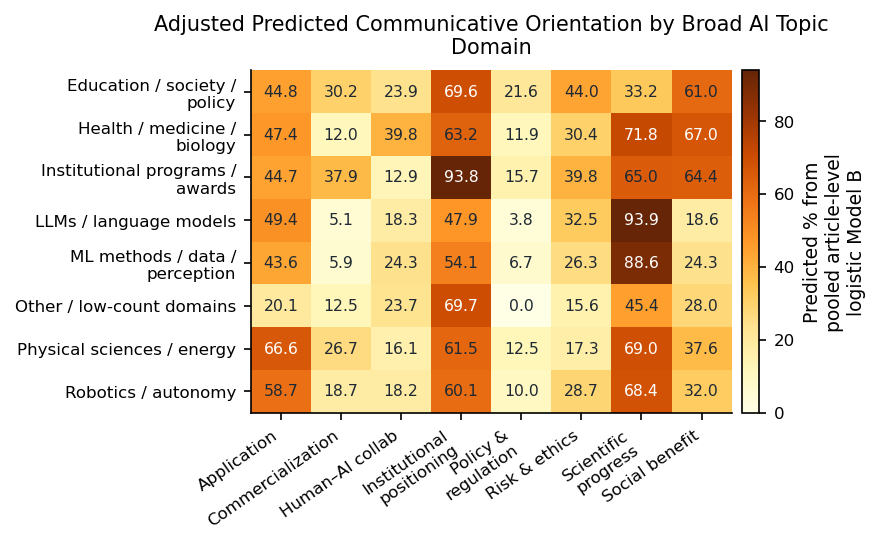

In [52]:
# Adjusted predicted probabilities by broad topic/domain (fig07_orientation_by_domain.pdf)
# for each domain, set every article's domain to that value, predict from Model B,
# and average predictions over the observed institution, period, and article-length distribution.

predicted_rows = []
model_domains = sorted(model_df["broad_topic_model"].dropna().unique())
for orientation_label, model in fitted_orientation_models.items():
    for domain in model_domains:
        temp = model_df.copy()
        temp["broad_topic_model"] = domain
        pred = model.predict(temp)
        predicted_rows.append({
            "orientation": orientation_label,
            "broad_topic_domain": domain,
            "adjusted_predicted_pct": float(np.mean(pred) * 100),
        })

orientation_adjusted_predictions = pd.DataFrame(predicted_rows)
adjusted_prediction_matrix = orientation_adjusted_predictions.pivot_table(
    index="broad_topic_domain",
    columns="orientation",
    values="adjusted_predicted_pct",
).round(1)

print("Adjusted predicted probability of each communicative orientation by broad topic/domain:")
display(adjusted_prediction_matrix)

# Pair the adjusted probabilities with descriptive prevalence to keep interpretation grounded.
comparison_for_interpretation = orientation_adjusted_predictions.merge(
    orientation_by_broad_topic[["broad_topic_domain", "orientation", "orientation_pct"]],
    on=["broad_topic_domain", "orientation"],
    how="left",
)
comparison_for_interpretation["adjusted_minus_descriptive_pp"] = (
    comparison_for_interpretation["adjusted_predicted_pct"] - comparison_for_interpretation["orientation_pct"]
)

print("Largest adjusted predicted probabilities, useful for interpretation:")
display(
    comparison_for_interpretation.sort_values("adjusted_predicted_pct", ascending=False)
    .head(20)
    .round({"adjusted_predicted_pct": 1, "orientation_pct": 1, "adjusted_minus_descriptive_pp": 1})
)

if "PLOTS_AVAILABLE" in globals() and PLOTS_AVAILABLE:
    draw_topic_heatmap(
        adjusted_prediction_matrix,
        "Adjusted Predicted Communicative Orientation by Broad AI Topic Domain",
        "Predicted % from pooled article-level logistic Model B",
        cmap="YlOrBr",
        figsize=(TEXTWIDTH_IN, 3.7),
        save_as="fig07_orientation_by_domain",
    )

### 7.3 Transformer semantic-domain check

The same articles are encoded with `all-MiniLM-L6-v2` sentence embeddings and clustered with k-means (k = 5 to 10, 20 initializations, fixed seed); the selected solution is the largest k whose smallest cluster has at least 3% of the articles and whose cosine silhouette is within 0.015 of the best. Clusters are labelled from top TF-IDF terms and representative articles, compared with the NMF domains (adjusted Rand index, normalized mutual information), and orientation differences are recomputed with chi-square tests and Cramer's V.


In [53]:
# Build transformer embeddings for the same pooled modeling corpus
# a sentence-transformer maps each article into a dense semantic vector.


semantic_df = model_article_base.copy()
semantic_text_cols = [col for col in ["Article Header", "Sub_Headings", "Article Body"] if col in semantic_df.columns]
semantic_df["semantic_text"] = (
    semantic_df[semantic_text_cols]
    .fillna("")
    .astype(str)
    .agg(". ".join, axis=1)
    .map(clean_text_value)
)
# Keep enough text for context while avoiding extremely long embedding calls.
semantic_texts = semantic_df["semantic_text"].str.slice(0, 5000).tolist()

semantic_embedding_method = None
semantic_embedding_note = None
try:
    semantic_model_name = "sentence-transformers/all-MiniLM-L6-v2"
    semantic_model = SentenceTransformer(semantic_model_name)
    semantic_embeddings = semantic_model.encode(
        semantic_texts,
        batch_size=32,
        show_progress_bar=False,
        normalize_embeddings=True,
    )
    semantic_embedding_method = f"Transformer embeddings: {semantic_model_name}"
    semantic_embedding_note = "Transformer embeddings loaded successfully."
except Exception as exc:
    # Fallback 
    semantic_vectorizer = TfidfVectorizer(
        lowercase=True,
        stop_words=custom_stopwords,
        ngram_range=(1, 3),
        min_df=3,
        max_df=0.55,
        max_features=4500,
        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z][a-zA-Z0-9\-]+\b",
    )
    semantic_tfidf_fallback = semantic_vectorizer.fit_transform(semantic_texts)
    svd = TruncatedSVD(n_components=min(100, semantic_tfidf_fallback.shape[1] - 1), random_state=42)
    semantic_embeddings = normalize(svd.fit_transform(semantic_tfidf_fallback), norm="l2")
    semantic_embedding_method = "Fallback dense semantic representation: TF-IDF + TruncatedSVD/LSA"
    semantic_embedding_note = f"Transformer embeddings unavailable; fallback used. Error: {type(exc).__name__}: {str(exc)[:160]}"

print(semantic_embedding_note)
print(f"Semantic embedding method: {semantic_embedding_method}")
print(f"Semantic embedding matrix shape: {semantic_embeddings.shape[0]:,} articles x {semantic_embeddings.shape[1]:,} dimensions")
print(f"Corpus: {model_start_year}-{model_end_year}, schools: {', '.join(preferred_model_schools)}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Transformer embeddings loaded successfully.
Semantic embedding method: Transformer embeddings: sentence-transformers/all-MiniLM-L6-v2
Semantic embedding matrix shape: 1,289 articles x 384 dimensions
Corpus: 2021-2025, schools: CMU, JHU, MIT, Stanford


In [54]:
# Select semantic cluster count and assign semantic domains
# Important calculation: KMeans groups articles whose embedding vectors are close in semantic space.
# Silhouette is used as a diagnostic; minimum cluster size prevents tiny unstable domains.

semantic_candidate_counts = [5, 6, 7, 8, 9, 10]
semantic_selection_rows = []
semantic_cluster_cache = {}
semantic_min_cluster_size = max(25, int(len(semantic_df) * 0.03))

for k in semantic_candidate_counts:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(semantic_embeddings)
    counts = pd.Series(labels).value_counts()
    if len(counts) > 1:
        sil = silhouette_score(semantic_embeddings, labels, metric="cosine")
    else:
        sil = np.nan
    semantic_selection_rows.append({
        "n_semantic_domains": k,
        "silhouette_cosine": sil,
        "smallest_domain_articles": int(counts.min()),
        "largest_domain_articles": int(counts.max()),
    })
    semantic_cluster_cache[k] = (km, labels)

semantic_cluster_selection = pd.DataFrame(semantic_selection_rows)
print("Semantic-domain cluster-count diagnostics:")
display(semantic_cluster_selection.round({"silhouette_cosine": 3}))

valid_semantic = semantic_cluster_selection.loc[
    semantic_cluster_selection["smallest_domain_articles"] >= semantic_min_cluster_size
].copy()
if valid_semantic.empty:
    selected_semantic_k = int(semantic_cluster_selection.sort_values("silhouette_cosine", ascending=False).iloc[0]["n_semantic_domains"])
else:
    
    best_silhouette = valid_semantic["silhouette_cosine"].max()
    selected_semantic_k = int(
        valid_semantic.loc[valid_semantic["silhouette_cosine"] >= best_silhouette - 0.015]
        .sort_values("n_semantic_domains", ascending=False)
        .iloc[0]["n_semantic_domains"]
    )

semantic_kmeans, semantic_labels_zero = semantic_cluster_cache[selected_semantic_k]
semantic_df["semantic_domain_id"] = semantic_labels_zero + 1
print(f"Minimum semantic-domain size required: {semantic_min_cluster_size}")
print(f"Selected semantic-domain count: {selected_semantic_k}")

Semantic-domain cluster-count diagnostics:


,n_semantic_domains,silhouette_cosine,smallest_domain_articles,largest_domain_articles
0,5,0.063,176,323
1,6,0.066,152,308
2,7,0.068,101,292
3,8,0.070,99,272
4,9,0.074,97,269
5,10,0.071,90,242


Minimum semantic-domain size required: 38
Selected semantic-domain count: 10


In [55]:
# Label semantic domains using top TF-IDF terms and representative articles


semantic_label_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words=custom_stopwords,
    ngram_range=(1, 3),
    min_df=3,
    max_df=0.65,
    max_features=4500,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z][a-zA-Z0-9\-]+\b",
)
semantic_label_tfidf = semantic_label_vectorizer.fit_transform(semantic_df["semantic_text"])
semantic_label_terms = np.array(semantic_label_vectorizer.get_feature_names_out())

semantic_label_rows = []
representative_semantic_rows = []
for domain_id in sorted(semantic_df["semantic_domain_id"].unique()):
    mask = semantic_df["semantic_domain_id"].values == domain_id
    mean_tfidf = np.asarray(semantic_label_tfidf[mask].mean(axis=0)).ravel()
    top_idx = mean_tfidf.argsort()[:-13:-1]
    top_terms = [semantic_label_terms[i] for i in top_idx]
    label = f"S{domain_id}: " + " / ".join(top_terms[:4])
    semantic_label_rows.append({
        "semantic_domain_id": domain_id,
        "semantic_domain_label": label,
        "articles": int(mask.sum()),
        "top_terms_for_labeling": ", ".join(top_terms),
    })

    cluster_center = semantic_kmeans.cluster_centers_[domain_id - 1].reshape(1, -1)
    sims = cosine_similarity(semantic_embeddings[mask], cluster_center).ravel()
    domain_articles = semantic_df.loc[mask].copy()
    domain_articles["centroid_similarity"] = sims
    for _, item in domain_articles.sort_values("centroid_similarity", ascending=False).head(3).iterrows():
        representative_semantic_rows.append({
            "semantic_domain_label": label,
            "centroid_similarity": item["centroid_similarity"],
            "Institution": item["Institution"],
            "year": int(item["year"]),
            "Article Header": item.get("Article Header", ""),
            "Url": item.get("Url", ""),
        })

semantic_domain_labels = pd.DataFrame(semantic_label_rows)
semantic_domain_label_map = semantic_domain_labels.set_index("semantic_domain_id")["semantic_domain_label"].to_dict()
semantic_df["semantic_domain_label"] = semantic_df["semantic_domain_id"].map(semantic_domain_label_map)
representative_semantic_articles = pd.DataFrame(representative_semantic_rows)

print("Semantic-domain labels and top terms for interpretation:")
display(semantic_domain_labels)
print("Representative articles nearest each semantic-domain centroid:")
display(representative_semantic_articles.round({"centroid_similarity": 3}))

Semantic-domain labels and top terms for interpretation:


,semantic_domain_id,semantic_domain_label,articles,top_terms_for_labeling
0,1,S1: model / models / learning / neural,118,"model, models, learning, neural, network, machine-learning, machine, machine learning, method, systems, algorithms, ..."
1,2,S2: language / models / model / llms,112,"language, models, model, llms, llm, language models, people, text, large language, chatgpt, chatbot, reasoning"
2,3,S3: robot / robots / robotics / robotic,122,"robot, robots, robotics, robotic, objects, autonomous, systems, control, tasks, task, environments, human"
3,4,S4: images / image / model / models,113,"images, image, model, models, brain, vision, visual, objects, video, scene, computer vision, object"
4,5,S5: energy / materials / material / chip,106,"energy, materials, material, chip, power, nuclear, solar, light, computing, data centers, model, engineering"
5,6,S6: learning / technology / systems / generative,242,"learning, technology, systems, generative, education, models, human, people, technologies, tools, policy, social"
6,7,S7: computing / engineering / program / learning,170,"computing, engineering, program, learning, technology, fellows, innovation, technologies, year, industry, schwarzman..."
7,8,S8: protein / proteins / cancer / drug,91,"protein, proteins, cancer, drug, model, molecules, cells, cell, biology, molecular, drugs, dna"
8,9,S9: people / music / technology / social,90,"people, music, technology, social, time, program, education, learning, think, design, make, world"
9,10,S10: health / care / patients / medical,125,"health, care, patients, medical, patient, health care, clinical, doctors, model, medicine, models, cancer"


Representative articles nearest each semantic-domain centroid:


,semantic_domain_label,centroid_similarity,Institution,year,Article Header,Url
0,S1: model / models / learning / neural,0.781,MIT,2022,Does this artificial intelligence think like a human?,https://news.mit.edu/2022/does-this-artificial-intelligence-think-human-0406
1,S1: model / models / learning / neural,0.771,MIT,2022,Explained: How to tell if artificial intelligence is working the way we want it to,https://news.mit.edu/2022/explained-how-tell-if-artificial-intelligence-working-way-we-want-0722
2,S1: model / models / learning / neural,0.766,MIT,2023,Efficient technique improves machine-learning models’ reliability,https://news.mit.edu/2023/improving-machine-learning-models-reliability-0213
3,S2: language / models / model / llms,0.817,MIT,2024,Large language models use a surprisingly simple mechanism to retrieve some stored knowledge,https://news.mit.edu/2024/large-language-models-use-surprisingly-simple-mechanism-retrieve-stored-knowledge-0325
4,S2: language / models / model / llms,0.806,MIT,2024,Enabling AI to explain its predictions in plain language,https://news.mit.edu/2024/enabling-ai-explain-predictions-plain-language-1209
5,S2: language / models / model / llms,0.784,MIT,2024,Reasoning and reliability in AI,https://news.mit.edu/2024/reasoning-and-reliability-in-ai-0118
6,S3: robot / robots / robotics / robotic,0.810,MIT,2022,An easier way to teach robots new skills,https://news.mit.edu/2022/teach-pick-robots-new-task-0425
7,S3: robot / robots / robotics / robotic,0.793,MIT,2024,Precision home robots learn with real-to-sim-to-real,https://news.mit.edu/2024/precision-home-robotics-real-sim-real-0731
8,S3: robot / robots / robotics / robotic,0.788,MIT,2022,Robots dress humans without the full picture,https://news.mit.edu/2022/robots-dress-humans-without-full-picture-0405
9,S4: images / image / model / models,0.812,MIT,2021,Machines that see the world more like humans do,https://news.mit.edu/2021/probablistic-programming-machine-vision-1208


Comparison between semantic embedding domains and prior NMF broad topic domains:
Adjusted Rand Index: 0.266; Normalized Mutual Information: 0.384
Interpretation: high values mean the two methods group articles similarly; moderate/low values mean they reveal different content structure.


broad_topic_model,Education / society / policy,Health / medicine / biology,Institutional programs / awards,LLMs / language models,ML methods / data / perception,Other / low-count domains,Physical sciences / energy,Robotics / autonomy
semantic_domain_label,,,,,,,,
S10: health / care / patients / medical,3.2,77.6,1.6,0.0,14.4,0.0,0.0,3.2
S1: model / models / learning / neural,6.8,0.0,2.5,1.7,66.9,0.0,5.1,16.9
S2: language / models / model / llms,22.3,5.4,0.0,49.1,18.8,0.9,0.0,3.6
S3: robot / robots / robotics / robotic,1.6,0.0,0.8,0.0,2.5,0.8,6.6,87.7
S4: images / image / model / models,6.2,1.8,0.0,0.9,73.5,3.5,3.5,10.6
S5: energy / materials / material / chip,2.8,0.0,1.9,0.0,14.2,1.9,75.5,3.8
S6: learning / technology / systems / generative,48.8,2.5,21.9,2.5,8.7,2.5,2.1,11.2
S7: computing / engineering / program / learning,22.4,3.5,46.5,0.0,2.4,2.4,10.6,12.4
S8: protein / proteins / cancer / drug,2.2,76.9,3.3,0.0,6.6,0.0,11.0,0.0


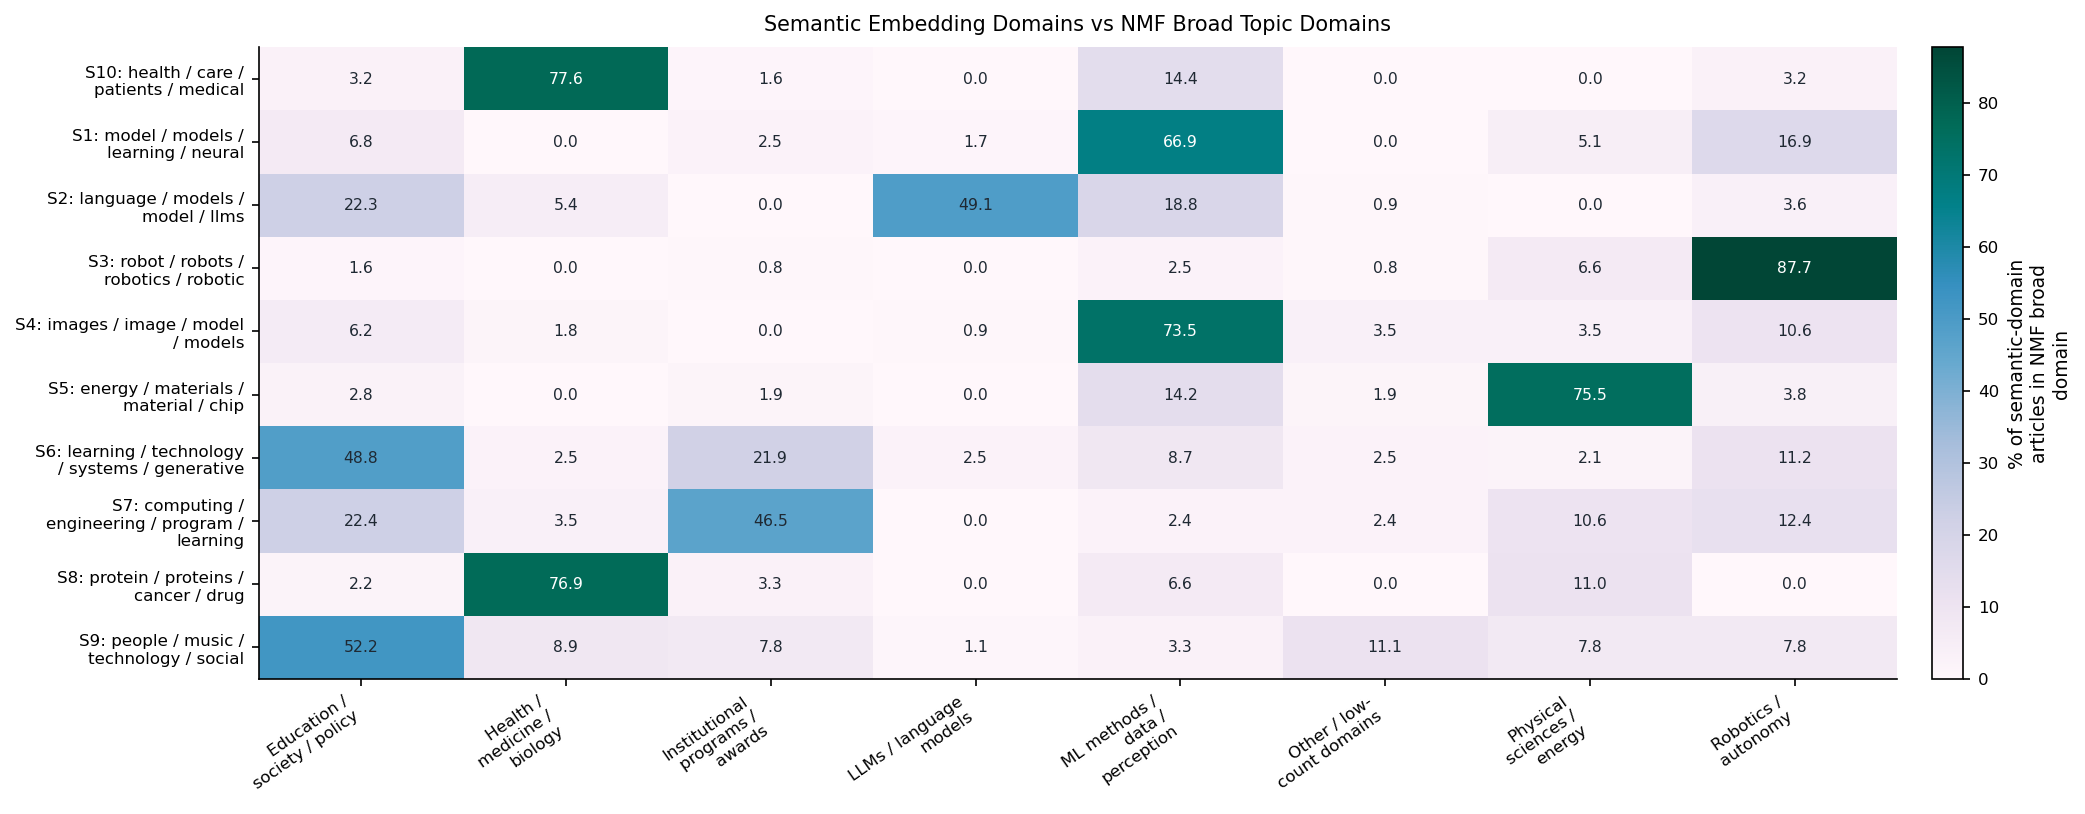

In [56]:
# Compare transformer semantic domains with prior NMF broad topic domains
semantic_compare_df = semantic_df[["article_id", "semantic_domain_label"]].merge(
    model_df[["article_id", "broad_topic_model"]],
    on="article_id",
    how="left",
)
semantic_vs_topic_counts = pd.crosstab(
    semantic_compare_df["semantic_domain_label"],
    semantic_compare_df["broad_topic_model"],
)
semantic_vs_topic_row_pct = semantic_vs_topic_counts.div(semantic_vs_topic_counts.sum(axis=1), axis=0) * 100

ari = adjusted_rand_score(semantic_compare_df["broad_topic_model"], semantic_compare_df["semantic_domain_label"])
nmi = normalized_mutual_info_score(semantic_compare_df["broad_topic_model"], semantic_compare_df["semantic_domain_label"])

print("Comparison between semantic embedding domains and prior NMF broad topic domains:")
print(f"Adjusted Rand Index: {ari:.3f}; Normalized Mutual Information: {nmi:.3f}")
print("Interpretation: high values mean the two methods group articles similarly; moderate/low values mean they reveal different content structure.")
display(semantic_vs_topic_row_pct.round(1))

if "PLOTS_AVAILABLE" in globals() and PLOTS_AVAILABLE:
    draw_topic_heatmap(
        semantic_vs_topic_row_pct.round(1),
        "Semantic Embedding Domains vs NMF Broad Topic Domains",
        "% of semantic-domain articles in NMF broad domain",
        cmap="PuBuGn",
        figsize=(14, 5.5),
    )

Communicative-orientation prevalence by transformer semantic domain:


orientation,Application,Commercialization,Human–AI collab,Institutional positioning,Policy & regulation,Risk & ethics,Scientific progress,Social benefit
semantic_domain_label,,,,,,,,
S10: health / care / patients / medical,47.2,14.4,52.0,63.2,17.6,43.2,72.8,88.0
S1: model / models / learning / neural,61.0,5.9,26.3,55.1,9.3,37.3,94.1,34.7
S2: language / models / model / llms,49.1,8.9,27.7,51.8,9.8,37.5,83.0,25.0
S3: robot / robots / robotics / robotic,50.0,8.2,17.2,50.0,2.5,18.0,59.0,13.1
S4: images / image / model / models,31.9,5.3,22.1,46.9,1.8,12.4,78.8,10.6
S5: energy / materials / material / chip,74.5,22.6,13.2,63.2,5.7,20.8,82.1,30.2
S6: learning / technology / systems / generative,50.8,31.4,21.5,78.1,28.1,51.2,46.3,59.1
S7: computing / engineering / program / learning,35.9,35.9,13.5,91.2,13.5,30.6,45.9,67.1
S8: protein / proteins / cancer / drug,58.2,12.1,28.6,67.0,3.3,6.6,89.0,33.0


Chi-square tests for semantic-domain differences in each communicative orientation:


,orientation,chi2,df,p_value,min_expected_cell,cramers_v,q_value
0,Application,66.75,9,0.0,44.3,0.23,0.0
1,Commercialization,106.33,9,0.0,17.1,0.29,0.0
2,Human–AI collab,80.69,9,0.0,21.2,0.25,0.0
3,Institutional positioning,112.94,9,0.0,30.8,0.30,0.0
4,Policy & regulation,94.72,9,0.0,11.1,0.27,0.0
5,Risk & ethics,118.53,9,0.0,28.1,0.30,0.0
6,Scientific progress,206.91,9,0.0,30.8,0.40,0.0
7,Social benefit,294.25,9,0.0,40.4,0.48,0.0


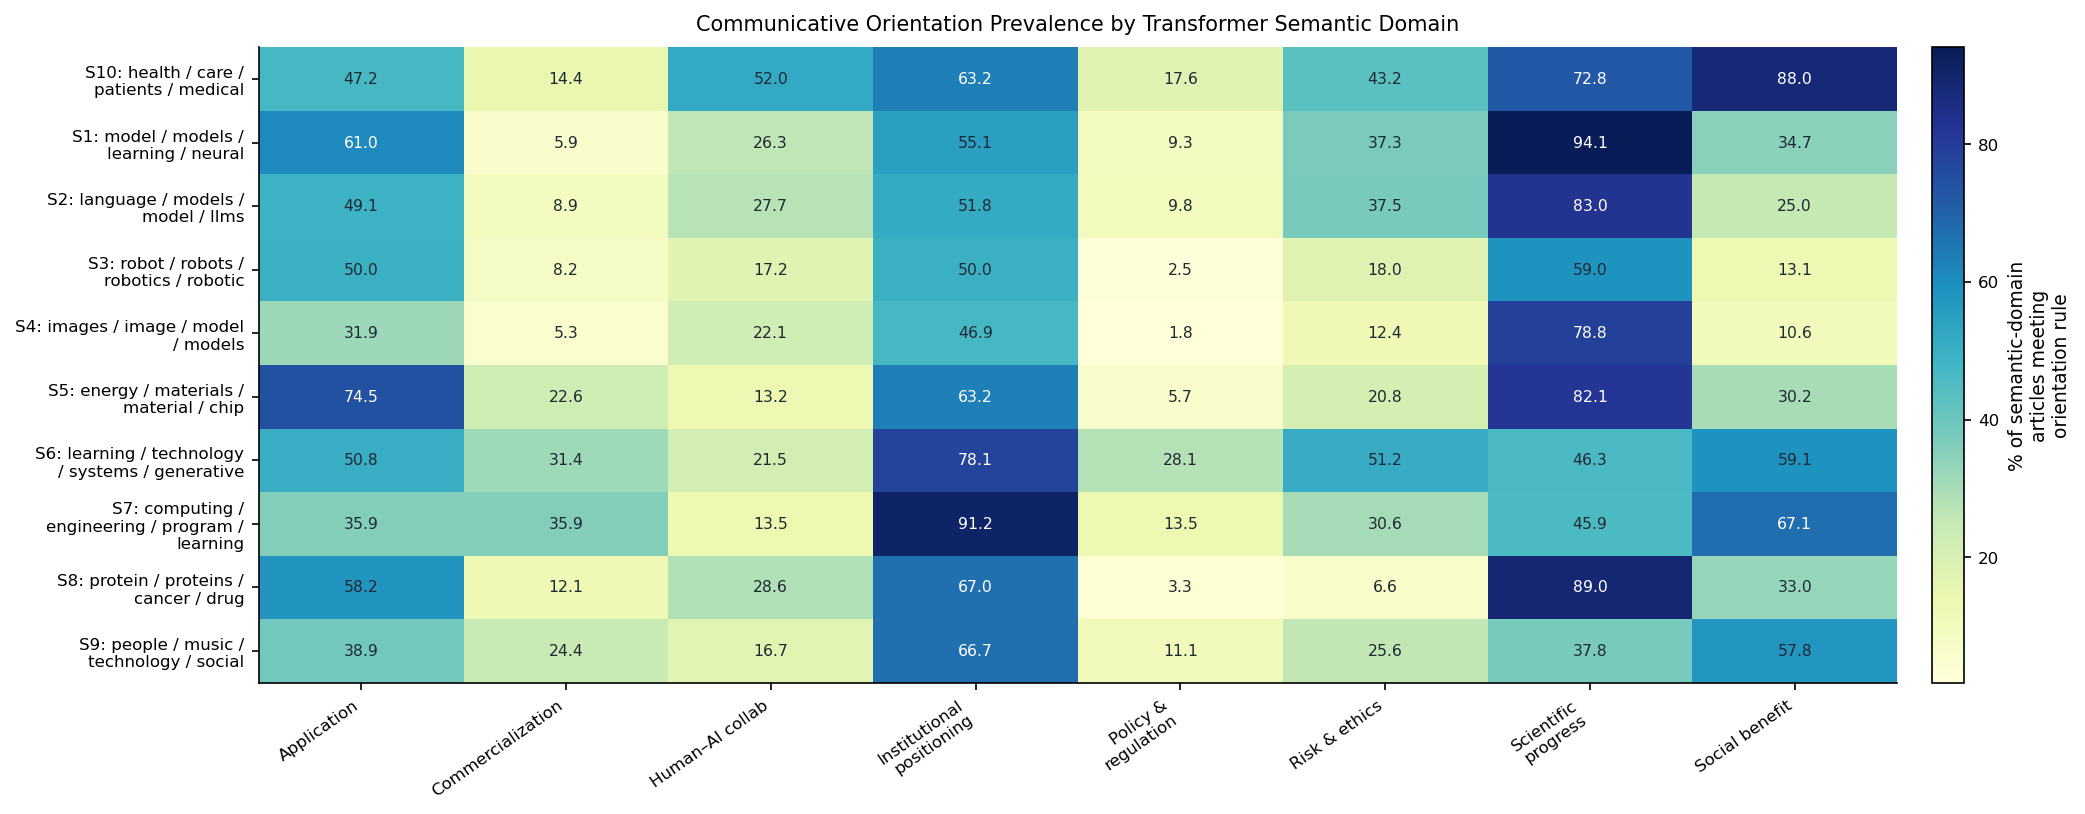

In [57]:
# Communicative orientation patterns within semantic embedding domains
semantic_orientation_df = model_df.merge(
    semantic_df[["article_id", "semantic_domain_label"]],
    on="article_id",
    how="left",
)

semantic_orientation_rows = []
for domain, group in semantic_orientation_df.groupby("semantic_domain_label"):
    n = len(group)
    for col, label in orientation_label_lookup.items():
        successes = int(group[col].sum())
        lo, hi = wilson_ci(successes, n)
        semantic_orientation_rows.append({
            "semantic_domain_label": domain,
            "orientation": label,
            "articles": n,
            "orientation_articles": successes,
            "orientation_pct": successes / n * 100,
            "ci_low_pct": lo * 100,
            "ci_high_pct": hi * 100,
        })

semantic_orientation_by_domain = pd.DataFrame(semantic_orientation_rows)
semantic_orientation_matrix = semantic_orientation_by_domain.pivot_table(
    index="semantic_domain_label",
    columns="orientation",
    values="orientation_pct",
).round(1)

print("Communicative-orientation prevalence by transformer semantic domain:")
display(semantic_orientation_matrix)

semantic_chi_rows = []
for col, label in orientation_label_lookup.items():
    table = pd.crosstab(semantic_orientation_df["semantic_domain_label"], semantic_orientation_df[col])
    if table.shape[1] == 2 and table.shape[0] > 1:
        chi2, p_value, dof, expected = stats.chi2_contingency(table)
        n = table.values.sum()
        cramers_v = np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1)))
        min_expected = expected.min()
    else:
        chi2, p_value, dof, cramers_v, min_expected = np.nan, np.nan, np.nan, np.nan, np.nan
    semantic_chi_rows.append({
        "orientation": label,
        "chi2": chi2,
        "df": dof,
        "p_value": p_value,
        "min_expected_cell": min_expected,
        "cramers_v": cramers_v,
    })

semantic_orientation_chi_tests = pd.DataFrame(semantic_chi_rows)
semantic_orientation_chi_tests["q_value"] = multipletests(semantic_orientation_chi_tests["p_value"].fillna(1), method="fdr_bh")[1]
print("Chi-square tests for semantic-domain differences in each communicative orientation:")
display(semantic_orientation_chi_tests.round({"chi2": 2, "p_value": 4, "q_value": 4, "cramers_v": 2, "min_expected_cell": 1}))

if "PLOTS_AVAILABLE" in globals() and PLOTS_AVAILABLE:
    draw_topic_heatmap(
        semantic_orientation_matrix,
        "Communicative Orientation Prevalence by Transformer Semantic Domain",
        "% of semantic-domain articles meeting orientation rule",
        cmap="YlGnBu",
        figsize=(14, 5.5),
    )

## 8 Robustness and uncertainty

### 8.1 Ceiling diagnostics, intensity, and relative emphasis share

Institution-level prevalence in the core modelling corpus (orientations with mean cross-school prevalence of at least 80% or minimum school prevalence of at least 70% are flagged), followed by the two threshold-free alternatives: article-level intensity and relative emphasis share (an orientation's share of total orientation intensity in the article).


Institution-level prevalence by orientation, modeling window:


orientation,Application,Commercialization,Human–AI collab,Institutional positioning,Policy & regulation,Risk & ethics,Scientific progress,Social benefit
Institution,,,,,,,,
CMU,36.4,17.3,18.2,71.4,13.0,33.8,41.1,40.7
JHU,44.6,22.8,28.7,64.4,10.9,36.6,61.4,57.4
MIT,52.5,17.9,22.4,64.9,10.0,27.8,72.9,42.3
Stanford,54.5,26.1,35.8,62.7,26.9,44.0,67.9,58.2


Ceiling-effect diagnostics:


,orientation,mean_school_prevalence_pct,min_school_prevalence_pct,max_school_prevalence_pct,sd_across_schools_pct,range_across_schools_pp,headroom_to_100_pct,ceiling_flag
3,Institutional positioning,65.8,62.7,71.4,3.8,8.7,34.2,Enough binary variation for prevalence comparison
6,Scientific progress,60.8,41.1,72.9,14.0,31.8,39.2,Enough binary variation for prevalence comparison
7,Social benefit,49.7,40.7,58.2,9.5,17.5,50.3,Enough binary variation for prevalence comparison
0,Application,47.0,36.4,54.5,8.3,18.1,53.0,Enough binary variation for prevalence comparison
5,Risk & ethics,35.6,27.8,44.0,6.7,16.2,64.4,Enough binary variation for prevalence comparison
2,Human–AI collab,26.3,18.2,35.8,7.7,17.6,73.7,Enough binary variation for prevalence comparison
1,Commercialization,21.0,17.3,26.1,4.2,8.8,79.0,Enough binary variation for prevalence comparison
4,Policy & regulation,15.2,10.0,26.9,7.9,16.9,84.8,Enough binary variation for prevalence comparison


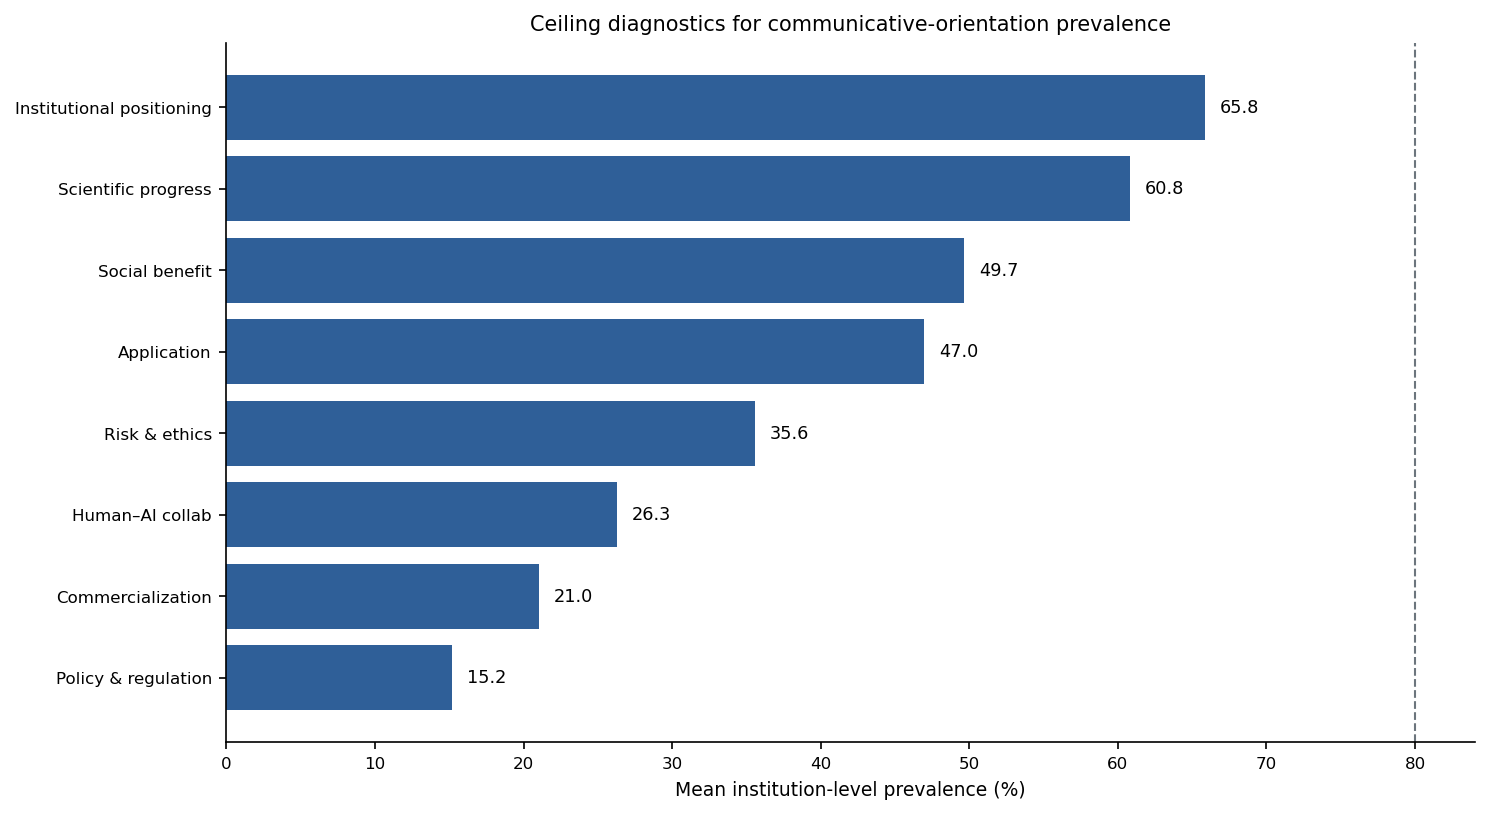

In [58]:
# Ceiling-effect diagnostics for communicative-orientation prevalence
# Important calculation: binary prevalence has less analytical leverage when almost all articles meet the presence rule.
# We flag orientations with high mean prevalence or very small variation across schools.

ceiling_df = model_df.copy()
ceiling_orientation_cols = orientation_label_lookup.copy()

inst_prev_rows = []
for institution, group in ceiling_df.groupby("Institution"):
    for col, label in ceiling_orientation_cols.items():
        inst_prev_rows.append({
            "Institution": institution,
            "orientation": label,
            "articles": len(group),
            "prevalence_pct": group[col].mean() * 100,
        })
institution_orientation_prevalence = pd.DataFrame(inst_prev_rows)

ceiling_diagnostics = (
    institution_orientation_prevalence.groupby("orientation", as_index=False)
    .agg(
        mean_school_prevalence_pct=("prevalence_pct", "mean"),
        min_school_prevalence_pct=("prevalence_pct", "min"),
        max_school_prevalence_pct=("prevalence_pct", "max"),
        sd_across_schools_pct=("prevalence_pct", "std"),
    )
)
ceiling_diagnostics["range_across_schools_pp"] = (
    ceiling_diagnostics["max_school_prevalence_pct"] - ceiling_diagnostics["min_school_prevalence_pct"]
)
ceiling_diagnostics["headroom_to_100_pct"] = 100 - ceiling_diagnostics["mean_school_prevalence_pct"]
ceiling_diagnostics["ceiling_flag"] = np.where(
    (ceiling_diagnostics["mean_school_prevalence_pct"] >= 80)
    | (ceiling_diagnostics["min_school_prevalence_pct"] >= 70),
    "High-prevalence: use intensity/share/time change",
    "Enough binary variation for prevalence comparison",
)

print("Institution-level prevalence by orientation, modeling window:")
display(
    institution_orientation_prevalence.pivot_table(
        index="Institution", columns="orientation", values="prevalence_pct"
    ).round(1)
)
print("Ceiling-effect diagnostics:")
display(ceiling_diagnostics.sort_values("mean_school_prevalence_pct", ascending=False).round(1))

if "PLOTS_AVAILABLE" in globals() and PLOTS_AVAILABLE:
    diag_plot = ceiling_diagnostics.sort_values("mean_school_prevalence_pct", ascending=True)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    colors = ["#C44E52" if "High-prevalence" in flag else "#2F5F98" for flag in diag_plot["ceiling_flag"]]
    ax.barh(diag_plot["orientation"], diag_plot["mean_school_prevalence_pct"], color=colors)
    ax.axvline(80, color="#6C757D", linestyle="--", linewidth=1)
    ax.set_xlabel("Mean institution-level prevalence (%)")
    ax.set_title("Ceiling diagnostics for communicative-orientation prevalence")
    for patch in ax.patches:
        width = patch.get_width()
        ax.text(width + 1, patch.get_y() + patch.get_height()/2, f"{width:.1f}", va="center", fontsize=8.5)
    plt.tight_layout()
    plt.show()

In [59]:
# Alternative outcomes: intensity and relative emphasis share
# Important calculation: intensity = weighted cue score per 1,000 words.
# Important calculation: relative emphasis share = one orientation's intensity / total orientation intensity in the same article.
# Relative share helps when prevalence is saturated because it asks which orientation is more emphasized, not just present.

orientation_intensity_lookup_model = {orientation_intensity_cols[label]: label for label in orientation_intensity_cols}
intensity_cols = list(orientation_intensity_lookup_model.keys())

ceiling_df["total_orientation_intensity"] = ceiling_df[intensity_cols].sum(axis=1)
for col in intensity_cols:
    share_col = col.replace("orientation_intensity__", "orientation_share__")
    ceiling_df[share_col] = np.where(
        ceiling_df["total_orientation_intensity"] > 0,
        ceiling_df[col] / ceiling_df["total_orientation_intensity"],
        np.nan,
    )

alt_rows = []
for institution, group in ceiling_df.groupby("Institution"):
    for int_col, label in orientation_intensity_lookup_model.items():
        share_col = int_col.replace("orientation_intensity__", "orientation_share__")
        alt_rows.append({
            "Institution": institution,
            "orientation": label,
            "mean_intensity_per_1k": group[int_col].mean(),
            "median_intensity_per_1k": group[int_col].median(),
            "mean_relative_share_pct": group[share_col].mean(skipna=True) * 100,
        })
orientation_intensity_share_by_institution = pd.DataFrame(alt_rows)

intensity_matrix = orientation_intensity_share_by_institution.pivot_table(
    index="Institution", columns="orientation", values="mean_intensity_per_1k"
).round(2)
share_matrix = orientation_intensity_share_by_institution.pivot_table(
    index="Institution", columns="orientation", values="mean_relative_share_pct"
).round(1)

print("Mean communicative-orientation intensity by institution, 2021-2025:")
display(intensity_matrix)
print("Mean relative emphasis share by institution, 2021-2025:")
display(share_matrix)

Mean communicative-orientation intensity by institution, 2021-2025:


orientation,Application,Commercialization,Human–AI collab,Institutional positioning,Policy & regulation,Risk & ethics,Scientific progress,Social benefit
Institution,,,,,,,,
CMU,6.90,3.84,3.44,14.71,2.00,9.09,8.70,9.53
JHU,6.09,3.83,4.20,10.89,1.78,5.88,10.88,11.65
MIT,6.48,2.98,2.95,10.81,1.51,3.94,16.59,7.27
Stanford,6.83,3.51,4.23,8.23,4.81,5.95,10.27,10.58


Mean relative emphasis share by institution, 2021-2025:


orientation,Application,Commercialization,Human–AI collab,Institutional positioning,Policy & regulation,Risk & ethics,Scientific progress,Social benefit
Institution,,,,,,,,
CMU,12.4,7.1,7.1,26.8,3.0,12.7,16.0,14.9
JHU,12.0,6.0,7.5,19.6,2.8,10.7,22.5,18.9
MIT,13.4,5.3,6.0,20.2,2.3,7.1,33.1,12.5
Stanford,13.2,6.5,8.3,15.6,6.5,10.1,21.8,18.0


### 8.2 Yearly metrics, pre/post differences, and bootstrap intervals

Article-level yearly prevalence, mean intensity, and mean relative share in the core modelling corpus (the annual trends, `fig08_orientation_trends_2021_2025.pdf`), the article-level pre/post-2023 differences, and 1,000 within-period bootstrap resamples with 95% percentile intervals for the differences in intensity and relative share.


In [60]:
# Time-line and pre/post-2023 changes for prevalence, intensity, and relative emphasis
# Important calculation: pre/post delta = post_2023 mean - pre_2023 mean.
# For high-prevalence orientations, intensity/share deltas are often more meaningful than prevalence deltas.

time_rows = []
for year, group in ceiling_df.groupby("year"):
    for present_col, label in ceiling_orientation_cols.items():
        int_col = [k for k, v in orientation_intensity_lookup_model.items() if v == label][0]
        share_col = int_col.replace("orientation_intensity__", "orientation_share__")
        time_rows.append({
            "year": int(year),
            "orientation": label,
            "articles": len(group),
            "prevalence_pct": group[present_col].mean() * 100,
            "mean_intensity_per_1k": group[int_col].mean(),
            "mean_relative_share_pct": group[share_col].mean(skipna=True) * 100,
        })
yearly_orientation_metrics = pd.DataFrame(time_rows)

period_rows = []
for period_value, group in ceiling_df.groupby("post_2023"):
    period_label = "post_2023" if period_value == 1 else "pre_2023"
    for present_col, label in ceiling_orientation_cols.items():
        int_col = [k for k, v in orientation_intensity_lookup_model.items() if v == label][0]
        share_col = int_col.replace("orientation_intensity__", "orientation_share__")
        period_rows.append({
            "period": period_label,
            "orientation": label,
            "articles": len(group),
            "prevalence_pct": group[present_col].mean() * 100,
            "mean_intensity_per_1k": group[int_col].mean(),
            "mean_relative_share_pct": group[share_col].mean(skipna=True) * 100,
        })
period_orientation_metrics = pd.DataFrame(period_rows)

period_delta = period_orientation_metrics.pivot_table(
    index="orientation", columns="period", values=["prevalence_pct", "mean_intensity_per_1k", "mean_relative_share_pct"]
)
for metric in ["prevalence_pct", "mean_intensity_per_1k", "mean_relative_share_pct"]:
    period_delta[(metric, "delta_post_minus_pre")] = period_delta[(metric, "post_2023")] - period_delta[(metric, "pre_2023")]
period_delta = period_delta.sort_values(("mean_relative_share_pct", "delta_post_minus_pre"), ascending=False)

print("Yearly orientation metrics, 2021-2025:")
display(yearly_orientation_metrics.round({"prevalence_pct": 1, "mean_intensity_per_1k": 2, "mean_relative_share_pct": 1}))
print("Pre/post-2023 deltas across prevalence, intensity, and relative share:")
display(period_delta.round(2))

Yearly orientation metrics, 2021-2025:


,year,orientation,articles,prevalence_pct,mean_intensity_per_1k,mean_relative_share_pct
0,2021,Application,155,47.7,7.14,15.2
1,2021,Commercialization,155,17.4,2.93,5.6
2,2021,Human–AI collab,155,18.1,3.02,6.4
3,2021,Institutional positioning,155,63.2,11.40,23.4
4,2021,Policy & regulation,155,10.3,2.20,2.8
5,2021,Risk & ethics,155,21.9,4.00,7.2
6,2021,Scientific progress,155,67.1,11.90,25.7
7,2021,Social benefit,155,42.6,8.65,13.8
8,2022,Application,186,39.2,5.17,10.4
9,2022,Commercialization,186,14.5,3.10,5.5


Pre/post-2023 deltas across prevalence, intensity, and relative share:


mean_intensity_per_1k           \
period                                post_2023 pre_2023   
orientation                                                
Risk & ethics                              5.47     4.54   
Application                                6.74     6.06   
Policy & regulation                        1.99     1.90   
Social benefit                             8.51     7.97   
Commercialization                          3.34     3.02   
Human–AI collab                            3.34     3.09   
Scientific progress                       14.08    14.04   
Institutional positioning                 11.08    11.71   

                          mean_relative_share_pct          prevalence_pct  \
period                                  post_2023 pre_2023      post_2023   
orientation                                                                 
Risk & ethics                                8.93     8.05          32.91   
Application                                 13.33    12.56          51.37   
Policy & regulation                          3.10     2.38          13.40   
Social benefit                              14.22    13.51          46.10   
Commercialization                            5.92     5.54          20.15   
Human–AI collab                              6.63     6.32          24.79   
Scientific progress                         27.62    29.07          65.19   
Institutional positioning                   20.24    22.58          65.93   

                                                        mean_intensity_per_1k  \
period                    pre_2023 delta_post_minus_pre  delta_post_minus_pre   
orientation                                                                     
Risk & ethics                26.69                 6.23                  0.93   
Application                  43.11                 8.26                  0.68   
Policy & regulation           9.38                 4.01                  0.09   
Social benefit               41.35                 4.75                  0.54   
Commercialization            15.84                 4.31                  0.32   
Human–AI collab              19.94                 4.85                  0.25   
Scientific progress          67.45                -2.26                  0.04   
Institutional positioning    65.40                 0.53                 -0.62   

                          mean_relative_share_pct  
period                       delta_post_minus_pre  
orientation                                        
Risk & ethics                                0.88  
Application                                  0.76  
Policy & regulation                          0.72  
Social benefit                               0.72  
Commercialization                            0.38  
Human–AI collab                              0.32  
Scientific progress                         -1.44  
Institutional positioning                   -2.34

Saved figures/fig08_orientation_trends_2021_2025.pdf


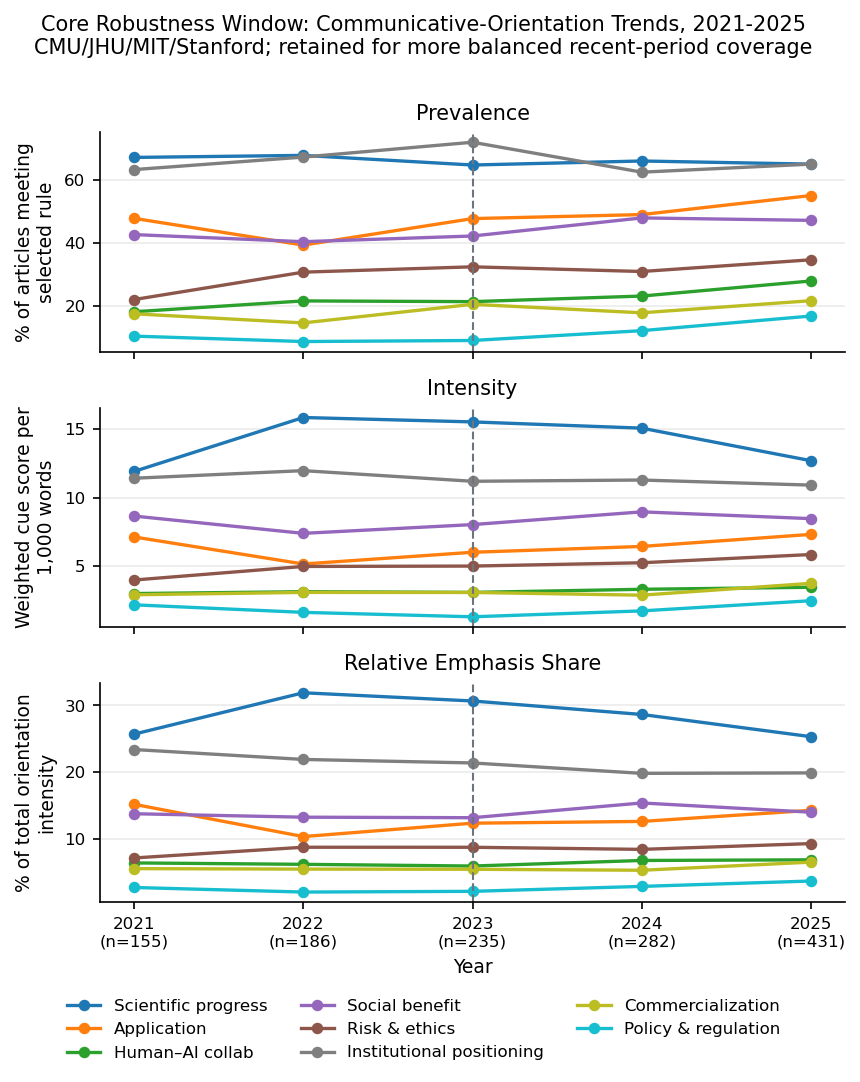

In [61]:
# Figure fig08_orientation_trends_2021_2025.pdf: recent four-school orientation trends, 2021-2025
# The old 2015-2026 pooled trend is less informative because early years are dominated by uneven school coverage.
# This figure uses the more defensible four-school modeling window and shows prevalence, intensity, and relative emphasis together.
if "yearly_orientation_metrics" not in globals():
    raise NameError("Run the first cell of Section 8.2 before this figure; yearly_orientation_metrics is required.")

figure3_orientations = frame_article_scores["frame_label"].drop_duplicates().tolist()
figure3_data = yearly_orientation_metrics.loc[
    yearly_orientation_metrics["orientation"].isin(figure3_orientations)
].copy()
article_counts_by_year = (
    figure3_data[["year", "articles"]]
    .drop_duplicates()
    .sort_values("year")
)

# Three panels stacked vertically so that each panel spans the full printed text width.
fig, axes = plt.subplots(3, 1, figsize=(TEXTWIDTH_IN, 7.0), sharex=True)
trend_colors = plt.cm.tab10(np.linspace(0, 1, len(figure3_orientations)))
metrics = [
    ("prevalence_pct", "Prevalence", "% of articles meeting selected rule"),
    ("mean_intensity_per_1k", "Intensity", "Weighted cue score per 1,000 words"),
    ("mean_relative_share_pct", "Relative Emphasis Share", "% of total orientation intensity"),
]

for ax, (metric, title, ylabel) in zip(axes, metrics):
    for color, orientation in zip(trend_colors, figure3_orientations):
        group = figure3_data.loc[figure3_data["orientation"] == orientation].sort_values("year")
        if not group.empty:
            ax.plot(group["year"], group[metric], marker="o", linewidth=1.6, label=orientation, color=color)
    ax.axvline(2023, color=COLORS["gray"], linestyle="--", linewidth=1.0)
    ax.set_title(title)
    ax.set_ylabel(wrap_text(ylabel, 24))
    ax.grid(axis="y", alpha=0.25)

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(article_counts_by_year["year"].astype(int).tolist())
# yearly article counts are identical across the three panels, so show them once beneath the year labels
axes[-1].set_xticklabels([f"{int(y)}\n(n={int(n)})" for y, n in zip(article_counts_by_year["year"], article_counts_by_year["articles"])])
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.005), frameon=False)
fig.suptitle(
    "Core Robustness Window: Communicative-Orientation Trends, 2021-2025\n"
    "CMU/JHU/MIT/Stanford; retained for more balanced recent-period coverage",
    y=1.005,
)
plt.tight_layout(rect=[0, 0.07, 1, 1])
save_fig(fig, "fig08_orientation_trends_2021_2025")
plt.show()

Bootstrap intervals for pre/post changes in non-binary orientation metrics:


,orientation,metric,observed_delta_post_minus_pre,ci_low,ci_high,direction_stable
0,Application,intensity_per_1k,0.676,-0.041,1.373,False
1,Application,relative_share,0.008,-0.008,0.021,False
2,Commercialization,intensity_per_1k,0.318,-0.459,0.987,False
3,Commercialization,relative_share,0.004,-0.008,0.016,False
4,Human–AI collab,intensity_per_1k,0.248,-0.232,0.718,False
5,Human–AI collab,relative_share,0.003,-0.005,0.012,False
6,Institutional positioning,intensity_per_1k,-0.622,-2.101,0.761,False
7,Institutional positioning,relative_share,-0.023,-0.044,-0.004,True
8,Policy & regulation,intensity_per_1k,0.087,-0.970,0.932,False
9,Policy & regulation,relative_share,0.007,-0.002,0.015,False


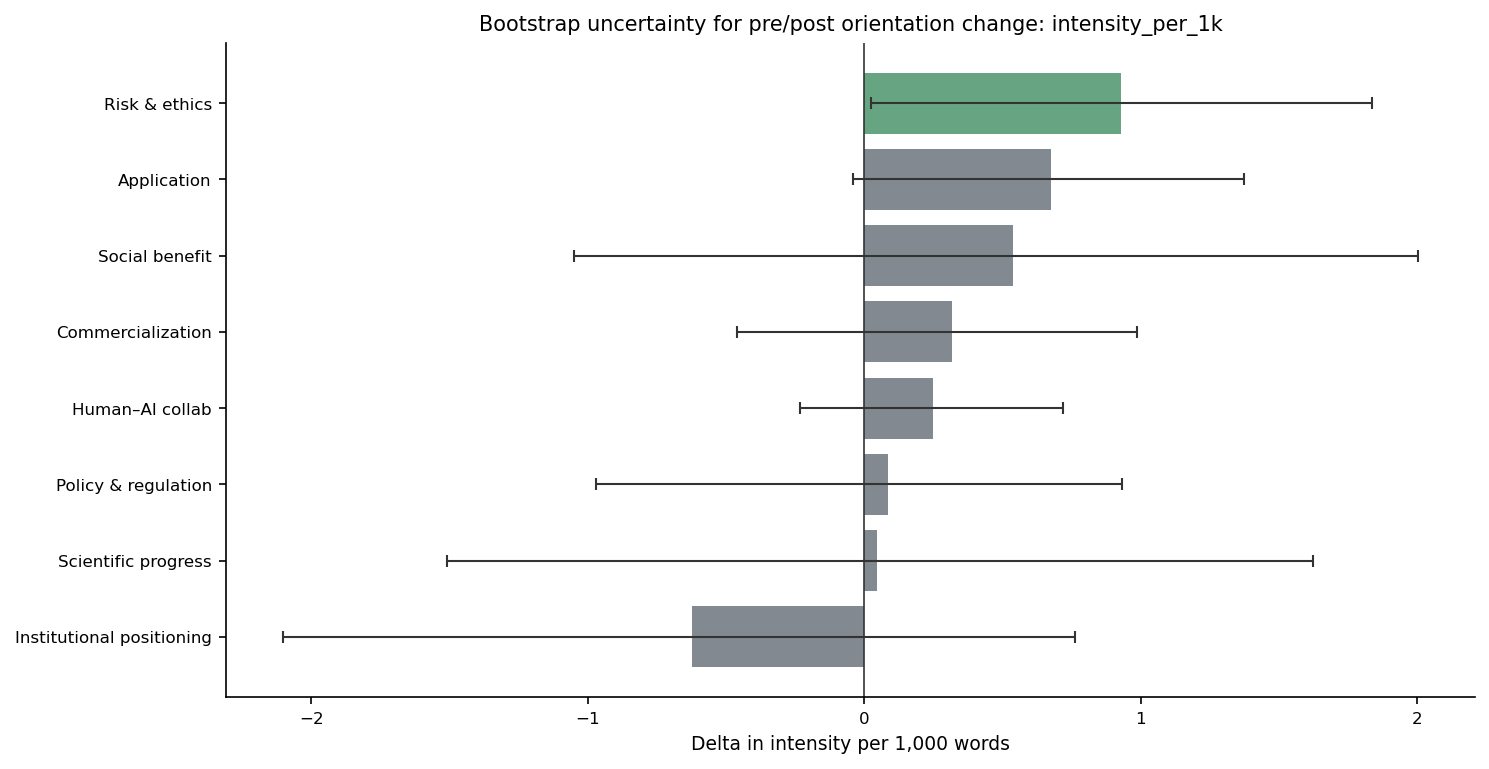

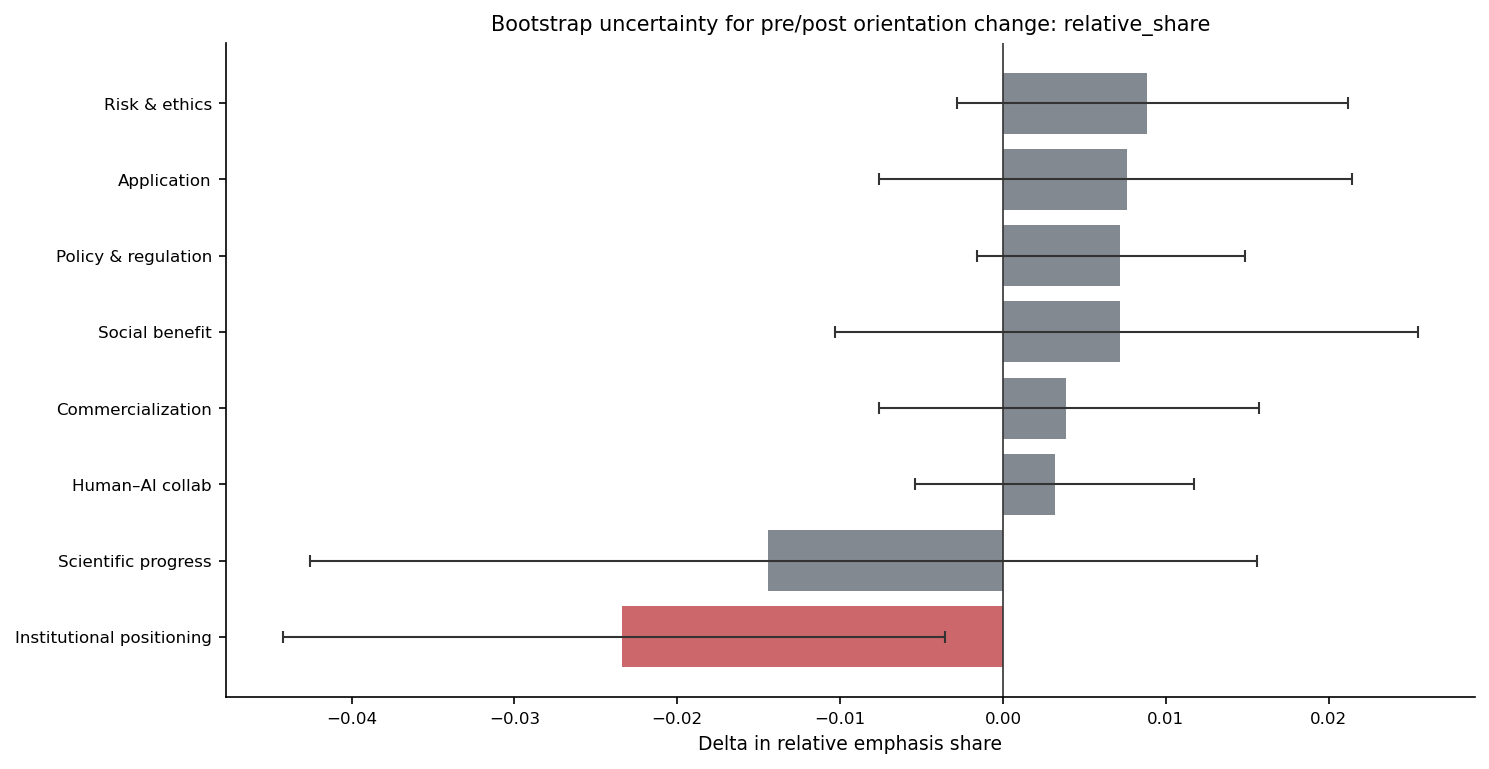

In [62]:
# Bootstrap uncertainty for pre/post changes in intensity and relative emphasis
# Important calculation: bootstrap resamples articles within pre and post periods, then recomputes the delta.
# This avoids relying only on normal approximations for small or skewed groups.

rng = np.random.default_rng(42)
n_boot = 1000
bootstrap_rows = []
pre_group = ceiling_df.loc[ceiling_df["post_2023"] == 0].copy()
post_group = ceiling_df.loc[ceiling_df["post_2023"] == 1].copy()

for label in ceiling_orientation_cols.values():
    int_col = [k for k, v in orientation_intensity_lookup_model.items() if v == label][0]
    share_col = int_col.replace("orientation_intensity__", "orientation_share__")
    for metric_col, metric_label in [(int_col, "intensity_per_1k"), (share_col, "relative_share")]:
        observed_delta = post_group[metric_col].mean(skipna=True) - pre_group[metric_col].mean(skipna=True)
        boot_deltas = []
        pre_values = pre_group[metric_col].dropna().to_numpy()
        post_values = post_group[metric_col].dropna().to_numpy()
        for _ in range(n_boot):
            pre_sample = rng.choice(pre_values, size=len(pre_values), replace=True)
            post_sample = rng.choice(post_values, size=len(post_values), replace=True)
            boot_deltas.append(post_sample.mean() - pre_sample.mean())
        ci_low, ci_high = np.percentile(boot_deltas, [2.5, 97.5])
        bootstrap_rows.append({
            "orientation": label,
            "metric": metric_label,
            "observed_delta_post_minus_pre": observed_delta,
            "ci_low": ci_low,
            "ci_high": ci_high,
            "direction_stable": (ci_low > 0) or (ci_high < 0),
        })

orientation_change_bootstrap = pd.DataFrame(bootstrap_rows)
print("Bootstrap intervals for pre/post changes in non-binary orientation metrics:")
display(orientation_change_bootstrap.round({"observed_delta_post_minus_pre": 3, "ci_low": 3, "ci_high": 3}))

if "PLOTS_AVAILABLE" in globals() and PLOTS_AVAILABLE:
    for metric_label, x_label in [("intensity_per_1k", "Delta in intensity per 1,000 words"), ("relative_share", "Delta in relative emphasis share")]:
        plot_df = orientation_change_bootstrap.loc[orientation_change_bootstrap["metric"] == metric_label].copy()
        plot_df = plot_df.sort_values("observed_delta_post_minus_pre")
        fig, ax = plt.subplots(figsize=(10, 5.2))
        y_pos = np.arange(len(plot_df))
        colors = ["#4C956C" if stable and delta > 0 else "#C44E52" if stable else "#6C757D" for stable, delta in zip(plot_df["direction_stable"], plot_df["observed_delta_post_minus_pre"])]
        ax.barh(y_pos, plot_df["observed_delta_post_minus_pre"], color=colors, alpha=0.85)
        ax.errorbar(
            plot_df["observed_delta_post_minus_pre"],
            y_pos,
            xerr=[
                plot_df["observed_delta_post_minus_pre"] - plot_df["ci_low"],
                plot_df["ci_high"] - plot_df["observed_delta_post_minus_pre"],
            ],
            fmt="none",
            ecolor="#333333",
            capsize=3,
            linewidth=1,
        )
        ax.axvline(0, color="#333333", linewidth=0.8)
        ax.set_yticks(y_pos)
        ax.set_yticklabels(plot_df["orientation"])
        ax.set_xlabel(x_label)
        ax.set_title(f"Bootstrap uncertainty for pre/post orientation change: {metric_label}")
        plt.tight_layout()
        plt.show()

### 8.3 Strong-phrase weight sensitivity

Strong-phrase share of each orientation's weighted score, and intensities recomputed with strong-phrase weights of 1, 2, and 5 instead of 3: within-orientation Spearman correlations with the baseline, the ordering of orientations by mean intensity, and the sign of the pre/post-2023 change in the core modelling corpus.


In [63]:
# Supplementary check 1: strong-phrase share of the weighted score, and sensitivity of the intensity measure
# to the strong-phrase weight.
# Baseline: S = 3*strong + weak. Alternatives: strong weight 1 (no upweighting), 2, and 5, weak weight fixed at 1.

strong_share_pct = (
    frame_article_scores.groupby("frame_label")
    .apply(lambda d: 100 * 3 * d["strong_count"].sum() / d["weighted_score"].sum())
    .rename("strong_share_of_weighted_score_pct")
    .sort_values()
)
print("Strong-phrase share of the weighted score by orientation, full corpus (%):")
display(strong_share_pct.round(1).to_frame())

WEIGHT_GRID = [1, 2, 3, 5]
weight_df = frame_article_scores[[
    "article_id", "Institution", "year", "analysis_period", "frame_label",
    "strong_count", "weak_count", "analysis_word_count",
]].copy()
for w in WEIGHT_GRID:
    weight_df[f"intensity_w{w}"] = (
        1000 * (w * weight_df["strong_count"] + weight_df["weak_count"]) / weight_df["analysis_word_count"].clip(lower=1)
    )

# (a) Article-level rank stability within each orientation (full corpus): Spearman rho against the 3:1 baseline.
rank_rows = []
for label, grp in weight_df.groupby("frame_label"):
    for w in [1, 2, 5]:
        rank_rows.append({
            "orientation": label, "strong_weight": w,
            "spearman_rho_vs_weight_3": spearmanr(grp["intensity_w3"], grp[f"intensity_w{w}"]).correlation,
        })
weight_rank_stability = pd.DataFrame(rank_rows).pivot(index="orientation", columns="strong_weight", values="spearman_rho_vs_weight_3")
print("Spearman rho of article-level intensity under alternative strong weights vs the 3:1 baseline (full corpus):")
display(weight_rank_stability.round(3))
print(f"Minimum rho across orientations and weights: {weight_rank_stability.min().min():.3f}")

# (b) Ordering of the eight orientations by mean article-level intensity under each weight.
def orientation_order(frame, col):
    return " > ".join(frame.groupby("frame_label")[col].mean().sort_values(ascending=False).index)

model_ids = model_df["article_id"].unique()  # 2021-2025 four-school modelling corpus (>= 80 words), as in Parts 2.7-2.9
for scope_label, scope in [("full corpus", weight_df), ("core modelling corpus 2021-2025", weight_df.loc[weight_df["article_id"].isin(model_ids)])]:
    print(f"\nOrientation ordering by mean article-level intensity, {scope_label}:")
    for w in WEIGHT_GRID:
        print(f"  strong weight {w}: {orientation_order(scope, f'intensity_w{w}')}")

# (c) Pre/post-2023 change in article-level mean intensity in the core modelling corpus under each weight

core_weight_df = weight_df.loc[weight_df["article_id"].isin(model_ids)]
period_means = core_weight_df.groupby(["frame_label", "analysis_period"])[[f"intensity_w{w}" for w in WEIGHT_GRID]].mean()
weight_prepost_delta = period_means.xs("post_2023", level="analysis_period") - period_means.xs("pre_2023", level="analysis_period")
weight_prepost_delta.columns = [f"delta_post_minus_pre_w{w}" for w in WEIGHT_GRID]
print("\nPost-2023 minus pre-2023 change in article-level mean intensity by strong-phrase weight (core modelling corpus):")
display(weight_prepost_delta.round(3))
sign_flips = {
    col: int(((weight_prepost_delta[col] > 0) != (weight_prepost_delta["delta_post_minus_pre_w3"] > 0)).sum())
    for col in weight_prepost_delta.columns
}
print("Orientations whose pre/post sign differs from the 3:1 baseline:", sign_flips)

Strong-phrase share of the weighted score by orientation, full corpus (%):


/var/folders/4j/prl8lwl97n7703x9n86mk1jm0000gn/T/ipykernel_98256/2089354260.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: 100 * 3 * d["strong_count"].sum() / d["weighted_score"].sum())


,strong_share_of_weighted_score_pct
frame_label,
Commercialization,4.5
Scientific progress,5.7
Application,7.5
Social benefit,7.7
Risk & ethics,10.8
Institutional positioning,12.3
Human–AI collab,14.6
Policy & regulation,17.8


Spearman rho of article-level intensity under alternative strong weights vs the 3:1 baseline (full corpus):


strong_weight,1,2,5
orientation,,,
Application,0.993,0.998,0.997
Commercialization,1.000,1.000,1.000
Human–AI collab,0.991,0.999,0.998
Institutional positioning,0.993,0.999,0.997
Policy & regulation,0.999,1.000,1.000
Risk & ethics,0.998,1.000,0.999
Scientific progress,0.995,0.999,0.998
Social benefit,0.998,1.000,0.999


Minimum rho across orientations and weights: 0.991

Orientation ordering by mean article-level intensity, full corpus:
  strong weight 1: Scientific progress > Institutional positioning > Social benefit > Application > Risk & ethics > Commercialization > Human–AI collab > Policy & regulation
  strong weight 2: Scientific progress > Institutional positioning > Social benefit > Application > Risk & ethics > Commercialization > Human–AI collab > Policy & regulation
  strong weight 3: Scientific progress > Institutional positioning > Social benefit > Application > Risk & ethics > Commercialization > Human–AI collab > Policy & regulation
  strong weight 5: Scientific progress > Institutional positioning > Social benefit > Application > Risk & ethics > Commercialization > Human–AI collab > Policy & regulation

Orientation ordering by mean article-level intensity, core modelling corpus 2021-2025:
  strong weight 1: Scientific progress > Institutional positioning > Social benefit > Application

,delta_post_minus_pre_w1,delta_post_minus_pre_w2,delta_post_minus_pre_w3,delta_post_minus_pre_w5
frame_label,,,,
Application,0.528,0.602,0.676,0.825
Commercialization,0.305,0.312,0.318,0.331
Human–AI collab,0.049,0.149,0.248,0.446
Institutional positioning,-0.216,-0.419,-0.622,-1.029
Policy & regulation,0.265,0.176,0.087,-0.090
Risk & ethics,0.699,0.815,0.930,1.162
Scientific progress,0.174,0.109,0.044,-0.085
Social benefit,0.350,0.444,0.538,0.727


Orientations whose pre/post sign differs from the 3:1 baseline: {'delta_post_minus_pre_w1': 0, 'delta_post_minus_pre_w2': 0, 'delta_post_minus_pre_w3': 0, 'delta_post_minus_pre_w5': 2}


### 8.4 Semantic anchor-sentence validation

Three anchor sentences per orientation (none contains a dictionary cue) are embedded with `all-MiniLM-L6-v2`. From a random sample of 600 articles, up to 300 cue-containing sentences per orientation are scored against all eight anchors: top-1 rate (chance 12.5%), margin between the own anchor and the mean of the other seven, and overlap with other orientations' cues.


In [64]:
# Supplementary check 2: semantic anchor-sentence validation of the orientation dictionary.
# Three anchor sentences per orientation are written from the codebook definitions and reuse no dictionary cue
#  Sentences that the dictionary matches
# to an orientation are embedded with the same sentence-transformer as the semantic-domain check and compared with
# the embeddings of all eight anchors. Top-1 rate: share of an orientation's sentences whose own anchor is the closest
# of the eight (chance = 12.5%). Margin: mean cosine to the own anchor minus mean cosine to the other seven.
if SentenceTransformer is None:
    raise ImportError("sentence-transformers is required for this cell: pip install sentence-transformers")

ANCHOR_SENTENCES = {
    "research_scientific_progress": [
        "The article reports a scientific finding or a new computational approach as a step forward in knowledge.",
        "The text emphasizes that the work does better or reaches further than earlier studies could.",
        "The story centres on the research itself: what was investigated, how it was done, and what was learned.",
    ],
    "application_automation_efficiency": [
        "The article describes the technology being put to practical use to carry out everyday tasks.",
        "The text emphasizes getting work done more quickly, at lower cost, or with less human effort.",
        "The story focuses on where and how the system is used in practice rather than on how it was built.",
    ],
    "human_augmentation_collaboration": [
        "The article describes people and AI systems working side by side, with the technology supporting human judgment.",
        "The text emphasizes that the system supports professionals in their work rather than replacing them.",
        "The story is about how the technology extends what a person is able to do.",
    ],
    "societal_benefit_public_good": [
        "The article emphasizes how the work will make life better for ordinary people or serve the wider public.",
        "The text frames the technology as a way to tackle a pressing problem facing people or the planet.",
        "The story stresses gains for the public, for those in need, or for the planet rather than for the researchers themselves.",
    ],
    "risk_responsibility_ethics": [
        "The article discusses dangers, downsides, or moral questions raised by the technology.",
        "The text raises worries about possible damage, unfair treatment, misuse, or loss of trust.",
        "The story emphasizes the need to develop and use the technology with prudence and caution.",
    ],
    "institutional_positioning_capacity": [
        "The article announces or showcases the university's own units, new efforts, appointments, or resources.",
        "The text emphasizes the university's standing, prestige, and organizational strength.",
        "The story is about the university as an organization rather than about a specific result.",
    ],
    "commercialization_innovation_ecosystem": [
        "The article describes turning research into goods for sale, new firms, or deals with private-sector actors.",
        "The text emphasizes buyers, backers, and the path from the bench to a firm.",
        "The story is about founding firms and the take-up of the technology by the private sector.",
    ],
    "governance_policy_regulation": [
        "The article discusses how public authorities should set and enforce the terms under which the technology may be used.",
        "The text emphasizes lawmaking, public supervision, and formal requirements imposed on the technology.",
        "The story is about who decides how the technology may be used and under what conditions.",
    ],
}
# Guard: no anchor may contain any dictionary cue of any orientation.
for fid, comp in compiled_frames.items():
    for tier in ("strong", "weak"):
        for cue, pat in comp[tier]:
            for f2, sents in ANCHOR_SENTENCES.items():
                for s in sents:
                    assert not pat.search(s.lower()), f"anchor for {f2} reuses the {tier} cue '{cue}' of {fid}"

VALIDATION_SEED = 42
VALIDATION_ARTICLES = 600
VALIDATION_SENTENCES_PER_ORIENTATION = 300
VALIDATION_MIN_WORDS = 4
val_rng = np.random.default_rng(VALIDATION_SEED)
validation_article_ids = val_rng.choice(np.sort(analysis_df["article_id"].to_numpy()), size=VALIDATION_ARTICLES, replace=False)
validation_articles = analysis_df.loc[analysis_df["article_id"].isin(validation_article_ids), ["article_id", "analysis_text"]]

def clean_validation_sentence(sentence):
    # Remove list/quote punctuation left over from the scraped paragraph lists before embedding.
    sentence = re.sub(r"\[\s*['\"]|['\"]\s*\]|['\"]\s*,\s*['\"]", " ", sentence)
    return re.sub(r"\s+", " ", sentence).strip(" '\"[]")

sentence_rows = []
for article in validation_articles.itertuples(index=False):
    for sentence in re.split(r"(?<=[.!?])\s+", article.analysis_text):
        sentence = clean_validation_sentence(sentence)
        if len(re.findall(r"\b[A-Za-z][A-Za-z0-9'\-]*\b", sentence)) < VALIDATION_MIN_WORDS:
            continue
        sentence_rows.append({"article_id": article.article_id, "sentence": sentence, "sentence_lower": sentence.lower()})
validation_sentences = pd.DataFrame(sentence_rows).drop_duplicates("sentence_lower").reset_index(drop=True)
print(f"Validation sample: {VALIDATION_ARTICLES} articles -> {len(validation_sentences):,} distinct sentences with >= {VALIDATION_MIN_WORDS} words")

orientation_ids = list(compiled_frames)
for fid in orientation_ids:
    patterns = [p for _c, p in compiled_frames[fid]["strong"]] + [p for _c, p in compiled_frames[fid]["weak"]]
    validation_sentences[f"match__{fid}"] = validation_sentences["sentence_lower"].map(lambda t: any(p.search(t) for p in patterns))
print("Sentences matching at least one cue of each orientation:",
      {compiled_frames[fid]["label"]: int(validation_sentences[f"match__{fid}"].sum()) for fid in orientation_ids})

validation_model = semantic_model if "semantic_model" in globals() else SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
anchor_matrix = np.vstack([
    (lambda e: e / np.linalg.norm(e))(validation_model.encode(ANCHOR_SENTENCES[fid], normalize_embeddings=True).mean(axis=0))
    for fid in orientation_ids
])
validation_sets = []
for fid in orientation_ids:
    pool = validation_sentences.loc[validation_sentences[f"match__{fid}"]]
    validation_sets.append(
        pool.sample(n=min(VALIDATION_SENTENCES_PER_ORIENTATION, len(pool)), random_state=VALIDATION_SEED).assign(target=fid)
    )
validation_set = pd.concat(validation_sets, ignore_index=True)
sentence_embeddings = validation_model.encode(
    validation_set["sentence"].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False
)
similarity = sentence_embeddings @ anchor_matrix.T

validation_rows = []
for k, fid in enumerate(orientation_ids):
    mask = (validation_set["target"] == fid).to_numpy()
    sims = similarity[mask]
    own = sims[:, k]
    others = np.delete(sims, k, axis=1).mean(axis=1)
    other_match_cols = [f"match__{f}" for f in orientation_ids if f != fid]
    validation_rows.append({
        "orientation": compiled_frames[fid]["label"],
        "n_sentences": int(mask.sum()),
        "top1_rate_pct": float((sims.argmax(axis=1) == k).mean() * 100),
        "margin_cosine": float((own - others).mean()),
        "mean_similarity_own_anchor": float(own.mean()),
        "overlap_with_other_orientation_pct": float(validation_set.loc[mask, other_match_cols].any(axis=1).mean() * 100),
    })
anchor_validation = pd.DataFrame(validation_rows)
print("\nSemantic anchor-sentence validation (chance top-1 rate = 12.5%):")
display(anchor_validation.round(3))

Validation sample: 600 articles -> 16,470 distinct sentences with >= 4 words
Sentences matching at least one cue of each orientation: {'Scientific progress': 4367, 'Application': 2570, 'Human–AI collab': 1317, 'Social benefit': 2486, 'Risk & ethics': 1720, 'Institutional positioning': 3327, 'Commercialization': 1252, 'Policy & regulation': 632}

Semantic anchor-sentence validation (chance top-1 rate = 12.5%):


,orientation,n_sentences,top1_rate_pct,margin_cosine,mean_similarity_own_anchor,overlap_with_other_orientation_pct
0,Scientific progress,300,32.000,0.069,0.229,53.667
1,Application,300,14.667,0.035,0.224,74.333
2,Human–AI collab,300,50.000,0.103,0.307,76.333
3,Social benefit,300,10.000,0.035,0.254,73.333
4,Risk & ethics,300,19.000,0.038,0.246,73.000
5,Institutional positioning,300,20.000,-0.001,0.205,64.000
6,Commercialization,300,18.000,0.015,0.236,72.333
7,Policy & regulation,300,17.667,0.031,0.258,77.000


## 9 Selection-bias pilot: AI-tagged versus full-archive coverage at MIT

The complete MIT News archive for 2021-2025 is processed with the same text preparation and the same terminology dictionary; an article is an AI-term hit if it contains any terminology cue. Annual counts of AI-tagged articles (the analysis corpus) and full-archive term hits are compared (`fig13_mit_tagged_vs_full.pdf`), after checking by URL that the archive contains the tagged corpus.


In [65]:
# Load the MIT full-archive scrape, 2021-2025
mitfull_path = DATA_DIR / "MIT_Full_Archive_Articles_2021_2025.csv"
if not mitfull_path.exists():
    raise FileNotFoundError(
        f"{mitfull_path} not found. Copy the scraper output "
        f"(MIT_Full_Archive_Articles_2021_2025.csv) into {DATA_DIR} before running this section."
    )

mitfull_raw = pd.read_csv(mitfull_path)
print(f"MIT full-archive rows loaded: {len(mitfull_raw)}")
display(mitfull_raw.head())

MIT full-archive rows loaded: 5571


,Published Date,Author,Source,Article Header,Sub_Headings,Article Body,Url
0,"August 2, 2026",Peter Dizikes,MIT News,"Using reason, again and again","Philosopher Brian Hedden studies decision-making over time — and recently chose to return to alma mater MIT, where h...","['You probably think you are rational. Day to day, you try to “make the best possible use of the information availab...",https://news.mit.edu/2026/using-reason-again-and-again-brian-hedden-0802
1,"July 31, 2026",Gitana Savage,MIT News correspondent,Building energy security through more sustainable batteries,"PhD student Hugh Smith works to develop sodium-ion batteries, whose components are more abundant and accessible than...","['For Hugh Smith, the challenge of building an energy-secure future isn’t about creating the world’s “best” battery....",https://news.mit.edu/2026/building-energy-security-through-more-sustainable-batteries-hugh-smith-0731
2,"July 30, 2026",Anne Trafton,MIT News,Why some nitrogen-processing enzymes are more efficient than others,"New findings could help researchers design synthetic catalysts that convert nitrogen gas to ammonia, a key step in f...","['Nitrogen gas is abundant in Earth’s atmosphere, but most living organisms can’t readily use this nitrogen. Only a ...",https://news.mit.edu/2026/why-some-nitrogen-processing-enzymes-are-more-efficient-0730
3,"July 29, 2026",Danielle Randall Doughty,Department of Chemistry,MIT and Broad Institute researchers break diffraction barrier in super-resolution microscopy,"New U-STORM imaging technology lets scientists view molecular structures in subatomic detail — about 1,000 times cle...","['Researchers in the lab of Sam Peng, the Pfizer Inc. - Gerald Laubach Career Development Assistant Professor of Che...",https://news.mit.edu/2026/researchers-break-diffraction-barrier-super-resolution-microscopy-0729
4,"July 29, 2026",Emma Foehringer Merchant,Institute for Medical Engineering and Science,How a medical database developed at MIT evolved into a global standard of data-sharing,"The visionary PhysioNet platform launched 25 years ago, based on a system developed at MIT in the 1970s. It has beco...","['Before the advancement of scientific data storage and collaboration via the cloud, medical investigators seeking h...",https://news.mit.edu/2026/how-an-mit-database-evolved-into-global-standard-data-sharing-0729


In [66]:
# Prepare text and dates exactly as analysis_df was prepared (Part 2 setup)

mitfull_df = mitfull_raw.copy()
mitfull_df["article_id"] = mitfull_df.index
mitfull_df["published_date"] = pd.to_datetime(mitfull_df["Published Date"], errors="coerce", format="mixed")
mitfull_df["year"] = mitfull_df["published_date"].dt.year

mitfull_text_cols = [c for c in ["Article Header", "Sub_Headings", "Article Body"] if c in mitfull_df.columns]
mitfull_df["analysis_text"] = (
    mitfull_df[mitfull_text_cols]
    .fillna("")
    .astype(str)
    .agg(". ".join, axis=1)
    .map(clean_text_value)
)
mitfull_df["analysis_text_lower"] = mitfull_df["analysis_text"].str.lower()
mitfull_df["analysis_word_count"] = (
    mitfull_df["analysis_text"].str.findall(r"\b[A-Za-z][A-Za-z0-9'\-]*\b").str.len()
)

# Restrict to the intended window; the scraper already stops at 2021, this is a safety filter.
mitfull_df = mitfull_df.loc[mitfull_df["year"].between(2021, 2025)].copy()

print(f"MIT full-archive articles, 2021-2025, valid date + body: {len(mitfull_df)}")
display(mitfull_df.groupby("year").size().rename("article_count").to_frame())

MIT full-archive articles, 2021-2025, valid date + body: 5040


,article_count
year,
2021,1044
2022,1044
2023,1047
2024,966
2025,939


In [67]:
# Apply the SAME AI terminology dictionary used for the main corpus 
# to the full-archive text. An article counts as an "AI term hit" if ANY family matches at least once.

mitfull_hit_rows = []
for row in mitfull_df.itertuples(index=False):
    text = getattr(row, "analysis_text_lower")
    any_hit = False
    family_hits = {}
    for family, compiled_cues in compiled_term_families.items():
        counts = count_matches(text, compiled_cues)
        total = int(sum(counts.values()))
        family_hits[family] = total
        if total > 0:
            any_hit = True
    mitfull_hit_rows.append({
        "article_id": getattr(row, "article_id"),
        "year": getattr(row, "year"),
        "analysis_word_count": getattr(row, "analysis_word_count"),
        "any_ai_term_hit": any_hit,
        **{f"term_count__{fam}": cnt for fam, cnt in family_hits.items()},
    })

mitfull_term_scores = pd.DataFrame(mitfull_hit_rows)
print(f"Full-archive articles with >=1 AI term match: "
      f"{mitfull_term_scores['any_ai_term_hit'].sum()} / {len(mitfull_term_scores)} "
      f"({100*mitfull_term_scores['any_ai_term_hit'].mean():.1f}%)")

Full-archive articles with >=1 AI term match: 1560 / 5040 (31.0%)


In [68]:
# Series A: MIT AI-tagged articles per year, from the existing main corpus (analysis_df).
# Series B: MIT full-archive articles per year with >=1 AI term hit (full-text search, any topic).

mitfull_series_a = (
    analysis_df.loc[(analysis_df["Institution"] == "MIT") & (analysis_df["year"].between(2021, 2025))]
    .groupby("year")["article_id"].nunique()
    .reindex(range(2021, 2026), fill_value=0)
    .rename("tagged_ai_articles")
)

mitfull_series_b_total = (
    mitfull_term_scores.groupby("year")["article_id"].nunique()
    .reindex(range(2021, 2026), fill_value=0)
    .rename("full_archive_total_articles")
)

mitfull_series_b_hits = (
    mitfull_term_scores.loc[mitfull_term_scores["any_ai_term_hit"]]
    .groupby("year")["article_id"].nunique()
    .reindex(range(2021, 2026), fill_value=0)
    .rename("full_archive_ai_term_hit_articles")
)

mitfull_comparison = pd.concat([mitfull_series_a, mitfull_series_b_total, mitfull_series_b_hits], axis=1)
mitfull_comparison["full_archive_ai_term_hit_pct"] = (
    100 * mitfull_comparison["full_archive_ai_term_hit_articles"] / mitfull_comparison["full_archive_total_articles"]
).round(1)
mitfull_comparison["tagged_as_pct_of_term_hits"] = (
    100 * mitfull_comparison["tagged_ai_articles"] / mitfull_comparison["full_archive_ai_term_hit_articles"]
).round(1)

print("MIT, 2021-2025: tag-based corpus vs. full-archive AI-term hits")
display(mitfull_comparison)

MIT, 2021-2025: tag-based corpus vs. full-archive AI-term hits


,tagged_ai_articles,full_archive_total_articles,full_archive_ai_term_hit_articles,full_archive_ai_term_hit_pct,tagged_as_pct_of_term_hits
year,,,,,
2021,130,1044,259,24.8,50.2
2022,145,1044,310,29.7,46.8
2023,164,1047,313,29.9,52.4
2024,178,966,318,32.9,56.0
2025,206,939,360,38.3,57.2


Saved figures/fig13_mit_tagged_vs_full.pdf


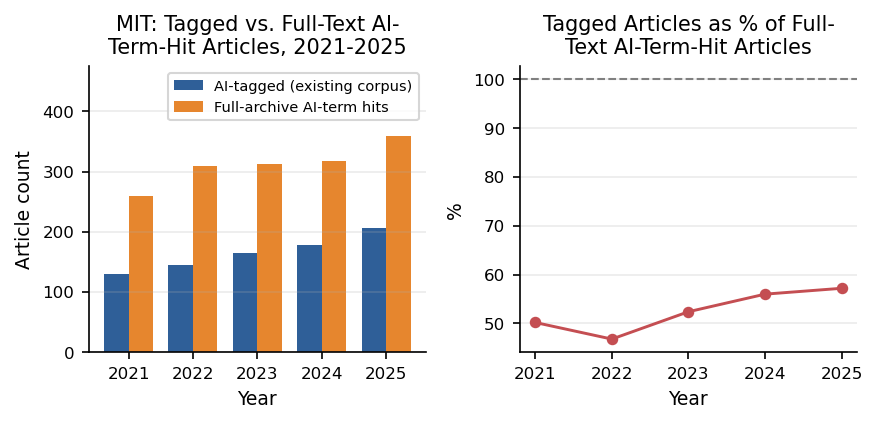

In [69]:
# Figure fig13_mit_tagged_vs_full.pdf: tagged-AI article counts vs full-archive AI-term-hit article counts, by year.
if "PLOTS_AVAILABLE" in globals() and PLOTS_AVAILABLE:
    fig, axes = plt.subplots(1, 2, figsize=(TEXTWIDTH_IN, 2.9))

    years = mitfull_comparison.index.astype(int)
    width = 0.38
    axes[0].bar(years - width/2, mitfull_comparison["tagged_ai_articles"], width, label="AI-tagged (existing corpus)", color="#2F5F98")
    axes[0].bar(years + width/2, mitfull_comparison["full_archive_ai_term_hit_articles"], width, label="Full-archive AI-term hits", color="#E6862E")
    axes[0].set_title(wrap_text("MIT: Tagged vs. Full-Text AI-Term-Hit Articles, 2021-2025", 32))
    axes[0].set_xlabel("Year")
    axes[0].set_ylabel("Article count")
    axes[0].set_xticks(years)
    axes[0].set_ylim(0, mitfull_comparison[["tagged_ai_articles", "full_archive_ai_term_hit_articles"]].max().max() * 1.32)  # headroom for the legend
    axes[0].legend(fontsize=7)
    axes[0].grid(axis="y", alpha=.25)

    axes[1].plot(years, mitfull_comparison["tagged_as_pct_of_term_hits"], marker="o", color="#C44E52")
    axes[1].axhline(100, color="gray", linestyle="--", linewidth=1)
    axes[1].set_title(wrap_text("Tagged Articles as % of Full-Text AI-Term-Hit Articles", 32))
    axes[1].set_xlabel("Year")
    axes[1].set_ylabel("%")
    axes[1].set_xticks(years)
    axes[1].grid(axis="y", alpha=.25)

    plt.tight_layout()
    save_fig(fig, "fig13_mit_tagged_vs_full")
    plt.show()

In [70]:
# Sanity check: how much overlap is there between the AI-tagged MIT corpus and the newly

mitfull_tagged_urls = set(
    analysis_df.loc[(analysis_df["Institution"] == "MIT") & (analysis_df["year"].between(2021, 2025)), "Url"]
    .dropna()
)
mitfull_archive_urls = set(mitfull_df["Url"].dropna()) if "Url" in mitfull_df.columns else set()

overlap = mitfull_tagged_urls & mitfull_archive_urls
print(f"AI-tagged MIT articles (2021-2025): {len(mitfull_tagged_urls)}")
print(f"Full-archive MIT articles (2021-2025): {len(mitfull_archive_urls)}")
print(f"URL overlap: {len(overlap)} ({100*len(overlap)/max(len(mitfull_tagged_urls),1):.1f}% of tagged articles found in full archive)")

if len(mitfull_tagged_urls) > 0 and len(overlap) / len(mitfull_tagged_urls) < 0.8:
    print("\nWARNING: overlap is below 80%. Before interpreting the comparison above, check whether "
          "this reflects a real editorial difference (e.g., some AI-tagged articles are not in MIT's "
          "general news stream) or a scraping/URL-matching artifact (e.g., trailing slashes, http vs "
          "https, redirected URLs).")

AI-tagged MIT articles (2021-2025): 823
Full-archive MIT articles (2021-2025): 5040
URL overlap: 819 (99.5% of tagged articles found in full archive)
